# Multi-Stage Cyber Attack Detection on MSCAD using Feature Selection, Autoencoder and Hybrid CNN-LSTM

**Suresh** — M.Tech, Computer Networks and Information Security (CNIS)
**VNR Vignana Jyothi Institute of Engineering and Technology (VNR VJIET)**

## Objective

This notebook implements an end-to-end intrusion-detection pipeline on the MSCAD
dataset. The dataset is read as its authors published it -- one labelled flow
table -- then preprocessed and split into a stratified training and test set.
A three-part feature-selection stage (mutual information, Pearson redundancy filtering and
permutation importance) reduces the feature set to thirty columns, an
autoencoder compresses those to fifteen latent features, and a hybrid CNN-LSTM
classifier is trained on them with class weighting applied to the training loss
only. The trained model is evaluated on an untouched test set and compared with
three baselines, each removing one component of the proposal, so that the
contribution of each component can be attributed.


> ## Primary dataset: the official MSCAD.csv
>
> **`DATASET_SOURCE = "official"`** — this notebook runs on the dataset as its
> authors published it, and on **one file**:
> `C:\MSCAD2022\CSV_Original_kaggle\MSCAD.csv`. Nothing is converted from PCAP
> and nothing is merged: the published file is already a single labelled flow
> table, so **Step 1 reads it directly**. The flows this project extracted from
> the captures itself are **kept for comparison** and are one setting away
> (`DATASET_SOURCE = "own"`); the cells that build them live in the companion
> notebook `convert_pcapng_to_csvflows.ipynb`.
>
> **Why the switch.** The official file is 128,799 rows x 67 columns (66
> features + Label) with six classes — Brute_Force 88,502 (68.71%), Normal
> 28,502 (22.13%), Port_Scan 11,081 (8.60%), HTTP_DDoS 641 (0.50%), ICMP_Flood
> 45 (0.03%), Web_Crwling 28 (0.02%) — and 37.4% of its rows share a feature
> vector with another row. On a quick stratified 80/20 check (seed 42) the
> majority class alone reaches 0.6872 accuracy, a depth-3 tree 0.7816 accuracy
> and 0.5457 macro-F1, and a random forest 0.9981 accuracy and 0.8542 macro-F1.
> Our own extraction, by contrast, had roughly 2,779 normal flows carrying
> **Benign/Normal and Brute_Force/DoS label conflicts**, and a random forest
> reached only 0.5836 accuracy on it — the labels disagreed with themselves, so
> no model trained on it could be trusted.
>
> **Where the outputs go.** `DATASET_SOURCE` routes the whole pipeline:
>
> | mode | output root |
> | --- | --- |
> | `"official"` | `C:\MSCAD2022\outputs_official\` |
> | `"own"` | `C:\MSCAD2022\outputs\` |
>
> **Nothing in `C:\MSCAD2022\outputs\` is read, written, overwritten or deleted
> while official mode is active**, so the own-extraction results from the
> earlier runs stay exactly as they are.
>
> ### Step numbers and folder names
>
> **Step numbers in this notebook refer to the simplified official-dataset flow;
> module names and function names inside src/mscad/ keep the earlier numbering
> for backward compatibility.**
>
> That holds for what the code *prints*, too: a table whose note says `Step 13`
> is the step this notebook now calls **Step 11**. Only the markdown headings
> were renumbered, so that not one line of the code behind the saved results
> had to change.
>
> The output folder names also keep the earlier numbering, so that every result
> already on disk stays exactly where it is and **nothing has to be retrained**.
> Read the table below rather than guessing: a Purpose/Input/Output block that
> names `outputs\step7` belongs to the step this table calls **Step 5**.
>
> | Notebook step | What it does | Entry point in `src/mscad/` | Output folder under `C:\MSCAD2022\outputs_official\` |
> | --- | --- | --- | --- |
> | **Step 1** | Data acquisition from `MSCAD.csv` | `official_dataset.run_step3()` | `step3\` |
> | **Step 2** | Preprocessing: clean, encode, scale | `preprocessing.run_step4()` | `step4\` |
> | **Step 3** | Train-test validation split | `splitting.run_step5()` | `step5\` |
> | **Step 4** | Feature selection (MI + Pearson + PI, top 30) | `feature_selection.run_step6()` | `step6\` |
> | **Step 5** | Autoencoder feature extraction (30 to 15) | `autoencoder.run_step7()` | `step7\` |
> | **Step 6** | Transform the training and test sets | `autoencoder.run_step8()` | `step8\` |
> | **Step 7** | Training-only class weighting | `imbalance.run_step9()` | `step9\` |
> | **Step 8** | The proposed hybrid CNN-LSTM | `models.run_step10()`, `models_attention.run_step10b()` | `step10\` |
> | **Step 9** | Evaluation on the untouched test set | `evaluation.run_step11()`, `models_attention.run_step11b()` | `step11\` |
> | **Step 10** | Model comparison | `experiments_step12\`, `comparison.run_step12_complete()` | `step12\` |
> | **Step 11** | Adaptive evidence fusion | `fusion.run_step13()`, `fusion_all.run_step13all()` | `step13\` |
> | **Step 12** | Explainability layer | `explainability.run_step14()`, `explainability_all.run_step14all()` | `step14\` |
>
> `step1\` and `step2\` are not used in official mode.


## Pipeline overview

```
MSCAD.csv -> preprocess -> split -> MI+Pearson+PI (30) -> AE (15)
          -> class weighting -> CNN-LSTM -> evaluation -> comparison
          -> adaptive fusion -> explainability
```

| Step | Purpose | Input | Output folder |
|---|---|---|---|
| 1 | Data acquisition: read the published `MSCAD.csv` | `C:\MSCAD2022\CSV_Original_kaggle\MSCAD.csv` | `outputs_official\step3` |
| 2 | Preprocessing: clean, encode, scale | `outputs_official\step3\MSCAD_merged.csv` | `outputs_official\step4` |
| 3 | Train-test validation split | `outputs_official\step4` | `outputs_official\step5` |
| 4 | Feature selection (MI + Pearson + PI, top 30) | `outputs_official\step5` | `outputs_official\step6` |
| 5 | Autoencoder feature extraction (30 to 15) | `outputs_official\step6` | `outputs_official\step7` |
| 6 | Transform the training and test sets | `outputs_official\step6`, `step7` | `outputs_official\step8` |
| 7 | Training-only class weighting | `outputs_official\step8` | `outputs_official\step9` |
| 8 | Hybrid CNN-LSTM training (Approach 1 and Approach 2) | `outputs_official\step8`, `step9` | `outputs_official\step10` |
| 9 | Evaluation on the untouched test set | `outputs_official\step8`, `step10` | `outputs_official\step11` |
| 10 | Model comparison against six baselines | `outputs_official\step5`-`step10` | `outputs_official\step12` |
| 11 | Adaptive evidence fusion | `outputs_official\step8`-`step12` | `outputs_official\step13` |
| 12 | Explainability layer | `outputs_official\step10`-`step13` | `outputs_official\step14` |

All twelve steps run in this notebook, in order, from the one input file. The
output folder names keep the earlier numbering, as the table at the top of the
notebook explains.

All paths are absolute and resolve under `C:\MSCAD2022`, independent of the
working directory Jupyter was started in. Source code lives separately under
`C:\Users\banot\MSCAD22-Multi-Stage-Cyber-Attack-Detection\Notebook`; no step
writes results into the code repository.


## Contents

1. [Step 1 - Data acquisition](#step-1---data-acquisition)
2. [Step 2 - Preprocessing](#step-2---preprocessing)
3. [Step 3 - Train-Test Validation Split](#step-3---train-test-validation-split)
4. [Step 4 - Feature Selection (MI + Pearson + PI to top 30)](#step-4---feature-selection-mi--pearson--pi-to-top-30)
5. [Step 5 - Autoencoder feature extraction](#step-5---autoencoder-feature-extraction)
6. [Step 6 - Transform the training and test sets](#step-6---transform-the-training-and-test-sets)
7. [Step 7 - Class imbalance handled in the training loss](#step-7---class-imbalance-handled-in-the-training-loss)
8. [Step 8 - Hybrid classifiers](#step-8---hybrid-classifiers)
9. [Step 9 - Evaluation on the untouched test set](#step-9---evaluation-on-the-untouched-test-set)
10. [Step 10 - Model comparison](#step-10---model-comparison)
11. [Step 11 - Adaptive Evidence Fusion](#step-11---adaptive-evidence-fusion)
12. [Step 12 - Explainability Layer](#step-12---explainability-layer)

Each step reports its own `[OK]`/`[FAIL]` verification table. A step whose
outputs already exist is loaded rather than recomputed, unless the matching
`OVERWRITE_STEPn` flag in `config.py` is set to `True`. The two addenda sit
inside their own steps: 11.8 at the end of Step 11, 12.9 at the end of Step 12.
The own extraction lives in the companion notebook `convert_pcapng_to_csvflows.ipynb`.


## Setup

In [1]:
import sys
from pathlib import Path

# The notebooks live in PROJECT_ROOT\notebooks, so when Jupyter is started in
# that folder the project root is one level up.  Starting Jupyter in the project
# root instead also works.  Nothing is hard-coded, so this is correct whether the
# code sits in C:\MSCAD2022\Notebook or in a git clone.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

import config

print("project root  :", PROJECT_ROOT)
print("kernel python :", sys.version.split()[0])
print("DATASET_SOURCE:", config.DATASET_SOURCE)
print("input file    :", config.OFFICIAL_CSV if config.RUNNING_OFFICIAL
      else config.CSV_INPUT_DIR)
print("output root   :", config.OUTPUTS_ROOT)
print("step 1 out    :", config.STEP3_OUTPUT_DIR, " (folder name kept from the"
      " earlier numbering)")
print("step 2 out    :", config.STEP4_OUTPUT_DIR)
print("random seed   :", config.RANDOM_SEED)

project root  : C:\Users\banot\MSCAD22-Multi-Stage-Cyber-Attack-Detection\Notebook
kernel python : 3.10.19
DATASET_SOURCE: official
input file    : C:\MSCAD2022\CSV_Original_kaggle\MSCAD.csv
output root   : C:\MSCAD2022\outputs_official
step 1 out    : C:\MSCAD2022\outputs_official\step3  (folder name kept from the earlier numbering)
step 2 out    : C:\MSCAD2022\outputs_official\step4
random seed   : 42


---

## Step 1 - Data acquisition

**Purpose** — Read the authors' `MSCAD.csv` exactly as published, say precisely
what is in it, and hand Step 2 the layout it expects. The published dataset
is already one labelled flow table: one file in, one file out.

**Input** — `C:\MSCAD2022\CSV_Original_kaggle\MSCAD.csv`, read-only. One file,
and no other source of rows.

**Method** — Five things, in order. **(1)** Read the file and clean the header:
surrounding whitespace and quotes are stripped, so `"'Idle Mean'"` becomes
`Idle Mean`; both names are reported. **(2)** Match each column to this
project's own feature names by *normalised* comparison (lowercased, punctuation
removed, a few CICFlowMeter abbreviations expanded), and report what is
unmatched **on both sides** — a feature this project expects and the official
file lacks matters as much as the other way round. The official names are kept.
**(3)** The official MSCAD dataset has no network identifiers; features are the
66 CICFlowMeter flow statistics. The step records that rather than inventing
columns, and `Orig_Row` — the row's position in `MSCAD.csv` — is added as the one
non-feature column. **(4)** Report shape, label counts and shares,
inf/NaN per column, constant columns, duplicate feature vectors overall and per
class, and **label conflicts** — counted, and listed row by row. **(5)** Save,
then check the saved file against `MSCAD.csv` itself (1.9) and, if the own
extraction's merged file happens to exist, print the two label tables side by
side for **comparison only** (1.10).

**Output** — `C:\MSCAD2022\outputs_official\step3\` — `MSCAD_merged.csv` in the
layout Step 2 expects, plus `column_mapping.csv`, `label_counts.csv`,
`column_quality.csv`, `duplicate_rows.csv`, `label_conflicts.csv`,
`official_manifest.json`, `step3_official_report.csv` and
`step3_official_summary.md`. The folder is called `step3` because the code and
the results already on disk keep the earlier numbering — see the table at the
top of the notebook.

**Why** — **Label conflicts are a ceiling, not a bug to fix:** two rows with
identical features and different labels cannot both be classified correctly by
any model that sees only those features, so if there are any, every macro-F1 in
Steps 8-12 is bounded by them and the write-up has to say so.

**Verification** — The step is self-contained: it compares no number against a
second source, because there is no second source. It compares the file against
itself — the saved `MSCAD_merged.csv` against the quantities recomputed from
`MSCAD.csv` — and reports every check as `[OK]` or `[FAIL]` with the numbers.


In [2]:
# Official mode runs on its own after a kernel restart: this cell sets up the
# import path, prints which dataset is active, and installs the retraining lock.
import sys
from pathlib import Path

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "config.py").exists() and (
        PROJECT_DIR.parent / "config.py").exists():
    PROJECT_DIR = PROJECT_DIR.parent           # started from notebooks\
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import numpy as np
import pandas as pd

import config
from src.mscad import data_loading
from src.mscad import official_dataset as official
from src.mscad import training_lock

try:                                           # only inside Jupyter
    from IPython.display import Markdown, display
except ImportError:                            # pragma: no cover
    Markdown = None

    def display(*_args, **_kwargs):
        pass

data_loading.show_table(data_loading.kv_table([
    ("DATASET_SOURCE", config.DATASET_SOURCE),
    ("input file", str(config.OFFICIAL_CSV) if config.RUNNING_OFFICIAL
     else str(config.CSV_INPUT_DIR)),
    ("output root (this run)", str(config.OUTPUTS_ROOT)),
    ("the other root (untouched)", str(config.OUTPUTS_ROOT_OWN
                                       if config.RUNNING_OFFICIAL
                                       else config.OUTPUTS_ROOT_OFFICIAL)),
    ("benign set for Label_binary", ", ".join(config.BENIGN_LABELS)),
    ("steps skipped", ", ".join(config.SKIP_STEPS) or "(none)"),
    ("LOCK_TRAINED_MODELS", config.LOCK_TRAINED_MODELS),
]), note="Reading: every Step 3-11 output below goes under `output root (this "
         "run)`. The other root is not read or written in this mode.")

if config.SKIP_STEPS_NOTE:
    print()
    print(config.SKIP_STEPS_NOTE)

print()
training_lock.install()
data_loading.show_table(training_lock.lock_table(), all_columns=True,
    note="Reading: with LOCK_TRAINED_MODELS = True a model that already has "
         "saved metrics in THIS output root is never retrained -- the training "
         "function refuses, whatever its OVERWRITE_* flag says. Set it to "
         "False in config.py to retrain on purpose.")

,metric,value
0,DATASET_SOURCE,official
1,input file,C:\MSCAD2022\CSV_Original_kaggle\MSCAD.csv
2,output root (this run),C:\MSCAD2022\outputs_official
3,the other root (untouched),C:\MSCAD2022\outputs
4,benign set for Label_binary,Normal
5,steps skipped,(none)
6,LOCK_TRAINED_MODELS,True


_Reading: every Step 3-11 output below goes under `output root (this run)`. The other root is not read or written in this mode._


The official dataset is already a single labelled flow table, so there is nothing to convert and nothing to merge: Step 1 reads C:\MSCAD2022\CSV_Original_kaggle\MSCAD.csv directly. The own extraction's conversion and merging cells are kept in Appendix A and run only with DATASET_SOURCE = "own".

  [LOCK]  LOCK_TRAINED_MODELS = True; 2 training function(s) wrapped (approach1, approach2)


,model,trained by,metrics.json,saved metrics exist,saved model exists,overwrite flag,running it now would
0,Approach 1 (CNN-LSTM),models.run_step10(),C:\MSCAD2022\outputs_official\step11\metrics.json,True,True,OVERWRITE_STEP10 = False,LOAD the saved model (it trains nothing)
1,Approach 2 (CNN-Attention-LSTM),models_attention.run_step10b(),C:\MSCAD2022\outputs_official\step11_attention...,True,True,OVERWRITE_STEP10B = False,LOAD the saved model (it trains nothing)


_Reading: with LOCK_TRAINED_MODELS = True a model that already has saved metrics in THIS output root is never retrained -- the training function refuses, whatever its OVERWRITE_* flag says. Set it to False in config.py to retrain on purpose._

In [3]:
step3 = official.run_step3()

### Step 1 - Data acquisition: the MSCAD dataset as published

The official dataset is already a single labelled flow table, so there is nothing to convert and nothing to merge: Step 1 reads C:\MSCAD2022\CSV_Original_kaggle\MSCAD.csv directly. The own extraction's conversion and merging cells are kept in Appendix A and run only with DATASET_SOURCE = "own".



_`C:\MSCAD2022\outputs_official\step3\MSCAD_merged.csv` already exists and `OVERWRITE_MERGED` is False, so Step 1 is reading it back rather than rebuilding it._

  loaded ((128799, 68),) from C:\MSCAD2022\outputs_official\step3\MSCAD_merged.csv


### 1.9 Self-check: the saved file against `MSCAD.csv`

There is **one input file and no second source**, so this is a self-check, not a
cross-check: `MSCAD_merged.csv` is read back from disk and compared against the
row count, the six label counts and the **per-column medians** recomputed from
`MSCAD.csv`. The median is the right statistic here because Step 1 changes no
value — it does not cap the infinities, Step 2 does — so a median that moved
would mean rows were lost, reordered into the wrong columns, or re-typed.

Any `[FAIL]` here means Step 2 must not be run until it is understood.


In [4]:
check = official.self_check()

print()
print("self-check passed:", check["ok"])

#### 1.9  Self-check: the saved file against MSCAD.csv

,check,source (MSCAD.csv),saved (MSCAD_merged.csv),largest difference,result
0,row count,128799,128799,0.0,[OK]
1,"label counts, all 6 classes",6 classes,6 classes,0.0,[OK]
2,median of every numeric column (66 compared),66 columns,66 columns,0.0,[OK]


_Reading: the file Step 1 wrote, re-read from disk, against the same quantities recomputed from MSCAD.csv. There is no second dataset to compare with, so this proves only what it can prove -- that separating the identifiers and reordering the columns changed no value. Every column agrees exactly._

[OK]  Step 1 self-check: 3 checks, largest median difference 0.000e+00

self-check passed: True


### 1.10 The two datasets' labels, side by side

If the own extraction's `MSCAD_merged.csv` is on disk, its label counts are
printed next to the official ones. This is **comparison, not used for
training**: no row, no count and no column from the own extraction enters any
later step while `DATASET_SOURCE = "official"`. If the file is not there the
cell says so and moves on.


In [5]:
side_by_side = official.own_extraction_label_comparison()

print()
print("own extraction available:", side_by_side["available"])

_**No own-extraction file to compare with.** `C:\MSCAD2022\outputs\step3\MSCAD_merged.csv` is not on this machine, so the official counts below stand on their own._


own extraction available: False


### 1.11 Load the saved file back from disk

Reading the file back is the stricter check of the two: it proves what is on
disk really round-trips, rather than re-using the frame still in memory. Step 2
reads the same file through the same loader, so if this cell works, Step 2's
input is there.


In [6]:
# data_loading.load_merged() delegates to official_dataset.load_merged_official()
# while DATASET_SOURCE = "official", and reads the dtypes Step 1 recorded in
# official_manifest.json.  This is exactly the call Step 2 makes.
dataset = data_loading.load_merged()

print()
print("shape  :", dataset.shape)
print("labels :", dataset[config.LABEL_COLUMN].nunique(), "distinct")

  loaded ((128799, 68),) from C:\MSCAD2022\outputs_official\step3\MSCAD_merged.csv

shape  : (128799, 68)
labels : 6 distinct


In [7]:
# the markdown Step 3 wrote, from the computed numbers only
if step3.get("summary"):
    if data_loading.in_notebook() and Markdown is not None:
        display(Markdown(step3["summary"]))
    else:
        print(step3["summary"])

### What Step 1 hands to Step 2

1. **`inf` in the rate columns** of zero-duration flows is arithmetically
   correct but rejected by scikit-learn and Keras, so it is capped explicitly
   rather than dropped.
2. **Identical-feature rows** are genuine observations in floods, scans and
   brute-force traffic. A random split places identical rows on both sides, which
   inflates every metric; Step 9 therefore also reports a duplicate-free score.
3. **Class imbalance** is left untouched until Step 7. Accuracy is close to a
   measure of the majority class on this dataset, so macro-F1, G-mean and
   per-class recall are the metrics to read.
4. **Identifier columns** are retained for traceability and excluded from
   training, as described above.


---

## Step 2 - Preprocessing

**Purpose** — Clean, encode and scale the whole dataset.

**Input** — `C:\MSCAD2022\outputs\step3\MSCAD_merged.csv`.

**Method** — `inf` values capped at each column's largest finite value with a
`zero_duration` marker (`INF_STRATEGY = "cap"`); `NaN` imputed with the column
median; zero-variance columns dropped; `Label` encoded to `Label_encoded` and a
binary `Label_binary`; features scaled with `SCALER = "minmax"`.

**Output** — `C:\MSCAD2022\outputs\step4` — `features_clean.csv`,
`features_scaled.csv`, `labels.csv`, `metadata.csv`, `feature_list.json`,
`label_mapping.json` and the combined `preprocessing.csv`.

**Why** — No train/test split, no class-imbalance handling, no feature selection
and no modelling happen here, so that each of those decisions is made once, in
its own step, on the correct subset of the data.

> **Non-feature columns.** Step 1 says which ones the dataset has. For the
> official file that is `Orig_Row` alone, so every other column is a feature or
> the label. Any identifier a dataset does carry is kept as context and excluded
> from training.

Duplicate rows are counted, never dropped: row *i* of `features`, `labels` and
`metadata` always refers to the same flow.


### Step 2 settings

In [8]:
from src.mscad import preprocessing

print("input      :", config.MERGED_CSV)
print("output     :", config.STEP4_OUTPUT_DIR)
print("INF_STRATEGY   :", config.INF_STRATEGY, "  ('cap' or 'nan_median')")
print("SCALER         :", config.SCALER, "  ('minmax' or 'standard')")
print("LABEL_MAP      :", config.LABEL_MAP or "{} (nothing renamed)")
print("BENIGN_LABELS  :", config.BENIGN_LABELS, "-> Label_binary 0")
print("OVERWRITE_STEP4:", config.OVERWRITE_STEP4)
print("metadata kept aside:", len(config.METADATA_COLUMNS), "columns")

input      : C:\MSCAD2022\outputs_official\step3\MSCAD_merged.csv
output     : C:\MSCAD2022\outputs_official\step4
INF_STRATEGY   : cap   ('cap' or 'nan_median')
SCALER         : minmax   ('minmax' or 'standard')
LABEL_MAP      : {} (nothing renamed)
BENIGN_LABELS  : ['Normal'] -> Label_binary 0
OVERWRITE_STEP4: False
metadata kept aside: 8 columns


### 2.1 Clean

Runs in this order, each reported in its own table:

| | |
|---|---|
| **a** | `inf` -> capped at the column's largest finite value, plus a `zero_duration` marker |
| **b** | `NaN` -> median of its own column (never a blanket zero) |
| **c** | constant / zero-variance columns dropped, **measured not assumed** |
| **d** | non-feature columns moved to `metadata`, keeping row order |
| **e** | duplicate feature rows **counted, not dropped** |
| **f** | exact label strings reported; `LABEL_MAP` applied only if set |

### 2.2 Encode

`Label` -> `Label_encoded` (LabelEncoder, mapping saved as JSON) and
`Label_binary` (0 for the benign labels - `Normal` in official mode - and 1
otherwise; they stay separate classes in the multi-class target). The label
is the only column encoded here.

### 2.3 Scale

`SCALER` over the numeric features only - one-hot and binary columns keep their
0/1 meaning. **Both the scaled and the unscaled cleaned features are saved**:
this scaler is fitted on the whole dataset, which is fine for inspection but
would leak test information once a split exists, so a later step can refit it
on the training split alone from `features_clean.csv`.

### Run Step 2

In [9]:
step4 = preprocessing.run_step4()

### Step 4 -- existing outputs loaded from disk

,file,rows,columns
0,features_clean.csv,128799,67
1,features_scaled.csv,128799,67
2,labels.csv,128799,3
3,metadata.csv,128799,1


_`config.OVERWRITE_STEP4` is False and the outputs already exist, so they were loaded instead of recomputed._

### 4.4  Final preprocessed dataset (preprocessing.csv)

,metric,value
0,rows,"128,799"
1,identifier columns,0
2,feature columns,67
3,Protocol_* one-hot columns left out,0
4,label columns,Label
5,total columns,68


_Built by column-joining the frames Step 4 already produced -- nothing recomputed, nothing re-scaled. The identifiers keep their ORIGINAL values and are joined by row POSITION, never by merging on values. `Protocol` is derived from the one-hot columns, which are themselves left out here but KEPT in features_scaled.csv._

,check,result,detail
0,file exists,[OK],C:\MSCAD2022\outputs_official\step4\preprocess...
1,size on disk,[OK],91.361 MB
2,rows match the other Step 4 files,[OK],"128,799 on disk vs 128,799 expected"
3,columns == 67 features + 1 label,[OK],68 on disk vs 68 expected
4,columns are in the expected feature-list order,[OK],"the 67 feature_list columns, then Label"
5,no Protocol_* one-hot columns,[OK],they stay in features_scaled.csv only
6,no Label_encoded / Label_binary columns,[OK],they stay in labels.csv only
7,identifier values match metadata row by row,[SKIP],the official dataset has no identifier columns
8,no NaN in the feature columns,[OK],0 NaN cells
9,no inf in the feature columns,[OK],0 inf cells


_Read back from **C:\MSCAD2022\outputs_official\step4\preprocessing.csv**_

,metric,value
0,absolute path,C:\MSCAD2022\outputs_official\step4\preprocess...
1,size (MB),91.361
2,rows,"128,799"
3,columns,68
4,identifier columns,(none)
5,features from,features_scaled
6,result,[OK] written and verified


### What came out

`features_clean.csv`, `features_scaled.csv`, `labels.csv`, `metadata.csv`,
`label_mapping.json`, `feature_list.json`, `preprocess_artifacts.joblib` and
`step4_report.csv`, all in `C:\MSCAD2022\outputs\step4`. Every CSV was
re-read from disk and its row count compared with the frame in memory.

In [10]:
if step4.get("status") == "loaded_existing":
    print("Existing Step 4 outputs were loaded (config.OVERWRITE_STEP4 is False).")
    print("Set OVERWRITE_STEP4 = True to recompute them.")
else:
    preprocessing.show_table(step4["report"])
    print()
    print("all checks passed:", step4["ok"])

Existing Step 4 outputs were loaded (config.OVERWRITE_STEP4 is False).
Set OVERWRITE_STEP4 = True to recompute them.


### Row alignment

Row *i* of the features, labels and metadata refers to the same flow. This alignment
is what allows any prediction to be traced back to its originating flow.


In [11]:
clean, labels, meta = (step4["features_clean"], step4["labels"], step4["metadata"]) \
    if "features_clean" in step4 else (None, None, None)

if clean is not None:
    print("features:", clean.shape, "| labels:", labels.shape, "| metadata:", meta.shape)
    preprocessing.show_table(
        meta.head(5).join(labels.head(5)[["Label", "Label_encoded", "Label_binary"]]))

features: (128799, 67) | labels: (128799, 3) | metadata: (128799, 1)


,Orig_Row,Label,Label_encoded,Label_binary
0,0,Brute_Force,0,1
1,1,Brute_Force,0,1
2,2,Brute_Force,0,1
3,3,Brute_Force,0,1
4,4,Brute_Force,0,1


### 2.4 Final preprocessed dataset (`preprocessing.csv`)

One file laid out for **reading** and for traceability, in the original row order:
the dataset's non-feature columns first, then the scaled features, then `Label`.
The official dataset has no identifier columns, so for it the file is the scaled
features and the original `Label` string.

- `Label_encoded` and `Label_binary` are **not** here; `labels.csv` still has
  all three.

> **This file is the readable view, not the training matrix.** For model
> training use `features_scaled.csv` (or `features_clean.csv`) and `labels.csv`
> for the encoded targets:
>
> ```python
> features = pd.read_csv(config.STEP4_OUTPUT_DIR / "features_scaled.csv")
> labels = pd.read_csv(config.STEP4_OUTPUT_DIR / "labels.csv")
> X = preprocessing.get_feature_matrix(features)   # identifiers and labels excluded
> y = labels["Label_encoded"]
> ```
>
> `config.ID_COLUMNS_NOT_FOR_TRAINING` names the columns that must never be fed
> to a model, and they are not in `feature_list.json`.

Set `config.COMBINED_ID_COLUMNS = []` for the features-and-labels-only layout,
or `COMBINED_USE_SCALED = False` to carry the unscaled features instead.


In [12]:
import pandas as pd

combined_path = config.COMBINED_CSV
if not config.usable_output_dir(config.STEP4_OUTPUT_DIR) or not combined_path.exists():
    print("preprocessing.csv not found at", combined_path)
    print("Run the Step 4 cell above first.")
    final = None
else:
    final = pd.read_csv(combined_path, low_memory=False)
    size_mb = combined_path.stat().st_size / 1024 / 1024
    preprocessing.show_table(preprocessing.kv_table([
        ("absolute path", str(combined_path)),
        ("size (MB)", round(size_mb, 2)),
        ("rows", f"{final.shape[0]:,}"),
        ("columns", final.shape[1]),
        ("memory, deep (MB)", round(final.memory_usage(deep=True).sum() / 1024 / 1024, 1)),
    ]))

,metric,value
0,absolute path,C:\MSCAD2022\outputs_official\step4\preprocess...
1,size (MB),91.36
2,rows,"128,799"
3,columns,68
4,"memory, deep (MB)",74.0


### Which columns are identifiers, features and labels

The official dataset has no identifier columns, so that list is empty here and
every column is a feature or a label.

In [13]:
if final is not None:
    ids = [c for c in config.COMBINED_ID_COLUMNS if c in final.columns]
    labels_cols = [c for c in config.COMBINED_LABEL_COLUMNS if c in final.columns]
    feature_cols = [c for c in final.columns if c not in ids + labels_cols]

    preprocessing.show_table(pd.DataFrame([
        {"role": "identifier (NOT a feature)", "columns": len(ids),
         "names": ", ".join(ids)},
        {"role": "feature (model input)", "columns": len(feature_cols),
         "names": ", ".join(feature_cols[:6]) + (", ..." if len(feature_cols) > 6 else "")},
        {"role": "label (target)", "columns": len(labels_cols),
         "names": ", ".join(labels_cols)},
        {"role": "TOTAL", "columns": final.shape[1], "names": ""},
    ]), note="`Protocol` is an identifier here, as readable text. The four numeric "
             "`Protocol_*` one-hot columns a model trains on are in "
             "`features_scaled.csv`, not in this file.")

    left_out = [c for c in config.COMBINED_DROP_FEATURE_COLUMNS if c in final.columns]
    extra = [c for c in ("Label_encoded", "Label_binary") if c in final.columns]
    print("[OK]   no Protocol_* one-hot columns" if not left_out
          else "[FAIL] found %s" % left_out)
    print("[OK]   no Label_encoded / Label_binary columns" if not extra
          else "[FAIL] found %s" % extra)

,role,columns,names
0,identifier (NOT a feature),0,
1,feature (model input),67,"Flow Duration, Tot Fwd Pkts, Tot Bwd Pkts, Tot..."
2,label (target),1,Label
3,TOTAL,68,


_`Protocol` is an identifier here, as readable text. The four numeric `Protocol_*` one-hot columns a model trains on are in `features_scaled.csv`, not in this file._

[OK]   no Protocol_* one-hot columns
[OK]   no Label_encoded / Label_binary columns


### head(10) and tail(5), all columns

In [14]:
if final is not None:
    preprocessing.show_table(final.head(10), all_columns=True,
                             note="All %d columns; scroll sideways." % final.shape[1])
    preprocessing.show_table(final.tail(5), all_columns=True)

,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,Fwd Pkt Len Mean,Fwd Pkt Len Std,Bwd Pkt Len Max,Bwd Pkt Len Min,Bwd Pkt Len Mean,Bwd Pkt Len Std,Flow Byts/s,Flow Pkts/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Tot,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Tot,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Bwd PSH Flags,Bwd URG Flags,Fwd Header Len,Bwd Header Len,Fwd Pkts/s,Bwd Pkts/s,Pkt Len Min,Pkt Len Max,Pkt Len Mean,Pkt Len Std,Pkt Len Var,FIN Flag Cnt,SYN Flag Cnt,RST Flag Cnt,PSH Flag Cnt,ACK Flag Cnt,URG Flag Cnt,CWE Flag Count,ECE Flag Cnt,Down/Up Ratio,Pkt Size Avg,Fwd Seg Size Avg,Bwd Seg Size Avg,Subflow Fwd Pkts,Subflow Fwd Byts,Subflow Bwd Pkts,Subflow Bwd Byts,Init Bwd Win Byts,Fwd Act Data Pkts,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,zero_duration,Label
0,0.000013,0.000014,0.000025,5.849650e-07,0.000002,0.001726,0.0,0.003983,0.003295,0.090538,0.0,0.051644,0.142398,0.007034,0.009223,0.000002,0.000002,0.000004,0.000002,0.000004,0.000004,0.000000,0.000004,0.000004,0.000013,0.000004,0.000004,0.000008,1.674802e-06,0.0,0.0,0.000014,0.000039,0.005270,0.013175,0.0,0.005915,0.023170,0.012462,0.000155,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.029851,0.026418,0.003983,0.051644,0.000014,5.849650e-07,0.000025,0.000002,0.000717,0.000007,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Brute_Force
1,0.000049,0.000029,0.000044,8.934011e-07,0.000021,0.002636,0.0,0.003042,0.003559,0.350624,0.0,0.385103,0.628781,0.017357,0.004072,0.000004,0.000009,0.000022,0.000002,0.000047,0.000016,0.000013,0.000022,0.000006,0.000049,0.000009,0.000016,0.000030,1.708076e-06,0.0,0.0,0.000029,0.000058,0.002715,0.005429,0.0,0.022908,0.136613,0.058848,0.003463,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.029851,0.147652,0.003042,0.385103,0.000029,8.934011e-07,0.000044,0.000021,0.000839,0.000007,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Brute_Force
2,0.000002,0.000007,0.000000,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.014706,0.000002,0.000000,0.000002,0.000004,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.0,0.0,0.000007,0.000006,0.014706,0.014706,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.014925,0.000000,0.000000,0.000000,0.000007,0.000000e+00,0.000000,0.000000,0.062668,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Brute_Force
3,0.000022,0.000029,0.000044,1.712352e-06,0.000021,0.005052,0.0,0.005830,0.006821,0.350624,0.0,0.379623,0.633661,0.039937,0.009192,0.000002,0.000003,0.000006,0.000002,0.000020,0.000007,0.000006,0.000011,0.000003,0.000022,0.000004,0.000004,0.000008,1.364243e-06,0.0,0.0,0.000029,0.000058,0.006128,0.012256,0.0,0.022908,0.139248,0.058844,0.003463,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.029851,0.150500,0.005830,0.379623,0.000029,1.712352e-06,0.000044,0.000021,0.000839,0.000007,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Brute_Force
4,0.000002,0.000007,0.000000,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.013605,0.000002,0.000000,0.000002,0.000004,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.0,0.0,0.000007,0.000006,0.013605,0.013605,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.014925,0.000000,0.000000,0.000000,0.000007,0.000000e+00,0.000000,0.000000,0.062668,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Brute_Force
5,0.000038,0.000029,0.000044,1.669809e-06,0.000021,0.004927,0.0,0.005685,0.006651,0.350624,0.0,0.379623,0.633661,0.022985,0.005299,0.000003,0.000007,0.000018,0.000002,0.000035,0.000012,0.000011,0.000018,0.000003,0.000038,0.000007,0.000012,0.000024,1.652619e-06,0.0,0.0,0.000029,0.000058,0.003533,0.007066,0.0,0.022908,0.139014,0.058848,0.003463,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.029851,0.150247,0.005685,0.379623,0.000029,1.669809e-06,0.000044,0.000021,0.000839,0.000007,0.0,0.0,0.0,0.0,0.0,0.0,0.0,

_All 68 columns; scroll sideways._

,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,Fwd Pkt Len Mean,Fwd Pkt Len Std,Bwd Pkt Len Max,Bwd Pkt Len Min,Bwd Pkt Len Mean,Bwd Pkt Len Std,Flow Byts/s,Flow Pkts/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Tot,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Tot,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Bwd PSH Flags,Bwd URG Flags,Fwd Header Len,Bwd Header Len,Fwd Pkts/s,Bwd Pkts/s,Pkt Len Min,Pkt Len Max,Pkt Len Mean,Pkt Len Std,Pkt Len Var,FIN Flag Cnt,SYN Flag Cnt,RST Flag Cnt,PSH Flag Cnt,ACK Flag Cnt,URG Flag Cnt,CWE Flag Count,ECE Flag Cnt,Down/Up Ratio,Pkt Size Avg,Fwd Seg Size Avg,Bwd Seg Size Avg,Subflow Fwd Pkts,Subflow Fwd Byts,Subflow Bwd Pkts,Subflow Bwd Byts,Init Bwd Win Byts,Fwd Act Data Pkts,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,zero_duration,Label
128794,0.000575,0.000022,0.000006,0.000003,0.000000e+00,0.008112,0.0,0.01248,0.012645,0.000000,0.0,0.000000,0.000000,1.644155e-04,1.450494e-04,0.000144,0.000351,0.000507,0.000002,0.000067,0.000034,0.000063,0.000065,0.000003,5.070417e-04,6.748564e-04,0.000000,6.211291e-04,6.748564e-04,0.0,0.0,0.000022,0.000020,1.740592e-04,1.160396e-04,0.0,0.008112,0.032797,0.019717,3.887507e-04,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.039264,0.01248,0.000000,0.000022,0.000003,0.000006,0.000000e+00,1.000000,0.000007,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0,Normal
128795,0.000528,0.000014,0.000006,0.000007,6.347983e-06,0.020037,0.0,0.04624,0.038253,0.325648,0.0,0.464384,0.809828,9.115871e-04,1.263284e-04,0.000176,0.000438,0.000527,0.000001,0.000528,0.000532,0.000000,0.000532,0.000532,4.833333e-07,6.433014e-07,0.000000,5.920862e-07,6.433014e-07,0.0,0.0,0.000014,0.000013,1.263284e-04,1.263284e-04,0.0,0.021277,0.303658,0.068100,4.637661e-03,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.014925,0.378687,0.04624,0.464384,0.000014,0.000007,0.000006,6.347983e-06,0.000015,0.000007,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0,Normal
128796,0.001159,0.000022,0.000013,0.000003,0.000000e+00,0.008112,0.0,0.01248,0.012645,0.000000,0.0,0.000000,0.000000,8.151197e-05,8.629300e-05,0.000232,0.000438,0.000570,0.000002,0.000598,0.000301,0.000605,0.000601,0.000002,1.132742e-03,7.538217e-04,0.000016,7.011526e-04,7.458414e-04,0.0,0.0,0.000022,0.000027,8.629320e-05,8.629320e-05,0.0,0.008112,0.028111,0.018254,3.332149e-04,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.014925,0.032720,0.01248,0.000000,0.000022,0.000003,0.000013,0.000000e+00,0.003998,0.000007,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0,Normal
128797,0.180349,0.000014,0.000025,0.000000,4.681403e-09,0.000000,0.0,0.00000,0.000000,0.000240,0.0,0.000137,0.000378,1.012927e-09,6.468000e-07,0.030058,0.054348,0.084168,0.000002,0.084167,0.084875,0.000000,0.084875,0.084875,1.800000e-01,6.000961e-02,0.073135,1.031047e-01,4.769303e-07,0.0,0.0,0.000019,0.000032,3.696000e-07,9.240000e-07,0.0,0.000016,0.000048,0.000033,1.090816e-09,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.029851,0.000054,0.00000,0.000137,0.000014,0.000000,0.000025,4.681403e-09,0.003937,0.000000,0.028664,0.0,0.028664,0.028664,0.084168,0.0,0.084168,0.084168,0,Normal
128798,0.002067,0.000000,0.000006,0.000000,0.000000e+00,0.000000,0.0,0.00000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000e+00,1.612760e-05,0.002067,0.000000,0.002067,0.002068,0.000000,0.000000,0.000000,0.000000,0.000000,2.066858e-03,2.750923e-03,0.000000,2.531914e-03,2.750923e-03,0.0,0.0,0.000000,0.000013,0.000000e+00,3.225520e-05,0.0,0.000000,0.000000,0.000000,0.000000e+00,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000006,0.000000e+00,0.015671,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0,Normal


### Protocol counts

The official dataset has no `Protocol` column, so this cell reports a skip. In
own mode it checks the readable column against the one-hot sums.


In [15]:
# The readable `Protocol` column is DERIVED from the Protocol_* one-hot
# features, so it exists only when the dataset has a Protocol column at all.
# The official file may not: that is reported here rather than failing on a
# missing column.
if final is None:
    print("[SKIP] the combined preprocessing.csv is not available")
elif "Protocol" not in final.columns:
    one_hot = [c for c in config.PROTOCOL_TEXT_FROM_ONE_HOT
               if c in final.columns]
    print("[SKIP] `%s` has no readable Protocol column: the %s dataset has no "
          "Protocol column, so there is nothing to derive it from."
          % (config.COMBINED_CSV.name, config.DATASET_SOURCE))
    print("       Protocol one-hot features present: %s"
          % (", ".join(one_hot) if one_hot else "none"))
else:
    counts = final["Protocol"].value_counts()
    rows = []
    for name in config.PROTOCOL_TEXT_VALUES:
        rows.append({"Protocol": name, "count": int(counts.get(name, 0)),
                     "%": round(100.0 * int(counts.get(name, 0)) / len(final), 3)})
    rows.append({"Protocol": "TOTAL", "count": len(final), "%": 100.0})
    preprocessing.show_table(pd.DataFrame(rows))

    unexpected = sorted(set(final["Protocol"].dropna().astype(str))
                        - set(config.PROTOCOL_TEXT_VALUES))
    blank = int(final["Protocol"].isna().sum())
    print("[OK]   Protocol holds only %s" % "/".join(config.PROTOCOL_TEXT_VALUES)
          if not unexpected else "[FAIL] unexpected values: %s" % unexpected)
    print("[OK]   no blank Protocol cells" if blank == 0
          else "[FAIL] %d blank Protocol cells" % blank)

[SKIP] `preprocessing.csv` has no readable Protocol column: the official dataset has no Protocol column, so there is nothing to derive it from.
       Protocol one-hot features present: none


### Label counts in the combined file

In [16]:
if final is not None:
    counts = final["Label"].value_counts()
    table = pd.DataFrame({"Label": counts.index.astype(str),
                          "count": counts.to_numpy(),
                          "%": (100.0 * counts / len(final)).round(3).to_numpy()})
    table = pd.concat([table, pd.DataFrame([{"Label": "TOTAL", "count": len(final),
                                             "%": 100.0}])], ignore_index=True)
    preprocessing.show_table(table)

,Label,count,%
0,Brute_Force,88502,68.713
1,Normal,28502,22.129
2,Port_Scan,11081,8.603
3,HTTP_DDoS,641,0.498
4,ICMP_Flood,45,0.035
5,Web_Crwling,28,0.022
6,TOTAL,128799,100.000


### Verification

Re-read from disk and checked against the other Step 2 files: the column count
against `feature_list.json`, the column order, the absence of the
`Label_encoded`/`Label_binary` columns, the labels against `labels.csv`, and the
feature values against `features_scaled.csv`. The identifier check is reported
as `[SKIP]`, because the official dataset has no identifier columns.


In [17]:
if final is not None and "step4" in dir() and "features_scaled" in step4:
    table, ok, _ = preprocessing.verify_combined(
        final, step4["features_scaled"], step4["labels"], step4["metadata"],
        expected_rows=len(step4["features_scaled"]))
    print()
    print("ALL CHECKS PASSED:", ok)
elif final is not None:
    print("Step 4 was loaded from disk, so the in-memory frames are not available.")
    print("Re-run the Step 4 cell with OVERWRITE_STEP4 = True for the full check.")

,check,result,detail
0,file exists,[OK],C:\MSCAD2022\outputs_official\step4\preprocess...
1,size on disk,[OK],91.361 MB
2,rows match the other Step 4 files,[OK],"128,799 on disk vs 128,799 expected"
3,columns == 67 features + 1 label,[OK],68 on disk vs 68 expected
4,columns are in the expected feature-list order,[OK],"the 67 feature_list columns, then Label"
5,no Protocol_* one-hot columns,[OK],they stay in features_scaled.csv only
6,no Label_encoded / Label_binary columns,[OK],they stay in labels.csv only
7,identifier values match metadata row by row,[SKIP],the official dataset has no identifier columns
8,no NaN in the feature columns,[OK],0 NaN cells
9,no inf in the feature columns,[OK],0 inf cells


_Read back from **C:\MSCAD2022\outputs_official\step4\preprocessing.csv**_


ALL CHECKS PASSED: True


### What Step 3 picks up

The Step 2 outputs are **unsplit and unbalanced on purpose**:

1. `features_clean.csv` is the one Step 3 splits, then fits a scaler on the
   training rows only - using `features_scaled.csv` across a split would leak
   test statistics into training.
2. The class imbalance is untouched, and Step 3 leaves it untouched too. Check
   `labels.csv`: the smallest classes have very few rows, so a stratified split
   and macro-F1 / per-class recall matter far more than accuracy.
3. `metadata.csv` holds whatever non-feature columns the dataset has. For the
   official file that is `Orig_Row` alone, which carries each row back to its
   position in `MSCAD.csv`; it stays **out of the feature matrix**.


---

## Step 3 - Train-Test Validation Split

**Purpose** — Produce a single stratified training and test split, and refit the
scaler on the training rows alone.

**Input** — `C:\MSCAD2022\outputs\step4` — `features_clean.csv` (unscaled),
`labels.csv`, `metadata.csv`.

**Method** — `train_test_split` on row positions with `TEST_SIZE = 0.20`,
`RANDOM_STATE = 42` and `STRATIFY_COLUMN = "Label"`; features, labels and
metadata are then selected with the same positions. A fresh `minmax` scaler is
fitted on the training rows only and applied to both sides.

**Output** — `C:\MSCAD2022\outputs\step5` — `X_train.csv`, `X_test.csv`,
`y_train.csv`, `y_test.csv`, `meta_train.csv`, `meta_test.csv`, the row-index
files and `scaler_train.joblib`.

**Why** — Step 2's scaler was fitted on every row, so reusing it across a split
would leak test statistics into training. Stratifying on the multiclass label
rather than the binary target keeps the smallest attack classes present on both
sides.

Min-max scaling maps each feature to $[0, 1]$:

$$x' = \frac{x - \min_{\text{train}}(x)}{\max_{\text{train}}(x) - \min_{\text{train}}(x)}$$

Test values may fall slightly outside $[0, 1]$ because the scaler never saw those
rows. This is expected, is reported per column, and is not clipped.

A single stratified 80/20 split of the Step 2 outputs, and **nothing else**.

| Step 3 does | Step 3 does not |
|---|---|
| a stratified split on row **positions**, so features, labels and metadata stay aligned | handle the class imbalance - no SMOTE, no resampling, no class weights |
| refit the scaler on the **training rows only** | select features |
| report how much of the test set is feature-identical to training | train any model |

Three settings decide everything, all in `config.py`:

```python
TEST_SIZE       = 0.20      # 20% of the rows go to test
RANDOM_STATE    = 42        # fixed, so the split is reproducible
STRATIFY_COLUMN = "Label"   # the MULTICLASS label
OVERWRITE_STEP5 = False     # keep existing outputs instead of resplitting
```

**Why stratify on `Label` and not `Label_binary`.** Stratifying on the binary
target would balance attack-vs-benign while letting a 23-row class land entirely
on one side of the split - and a class with no test rows cannot be evaluated at
all. Stratifying on the multiclass label keeps every attack type on both sides.

**Why the split is on indices.** `train_test_split` is given `np.arange(n_rows)`,
not the frames. The three frames are then selected with the same positions, so
row *i* of `X_train`, `y_train` and `meta_train` is guaranteed to be the same
flow. Splitting each frame separately would be three independent shuffles.


### Step 3 settings

In [18]:
from src.mscad import splitting

splitting.show_table(splitting.kv_table([
    ("input folder", str(config.STEP4_OUTPUT_DIR)),
    ("output folder", str(config.STEP5_OUTPUT_DIR)),
    ("TEST_SIZE", config.TEST_SIZE),
    ("RANDOM_STATE", config.RANDOM_STATE),
    ("STRATIFY_COLUMN", config.STRATIFY_COLUMN),
    ("SCALER (refitted on train)", config.SCALER),
    ("CLIP_TEST_TO_TRAIN_RANGE", config.CLIP_TEST_TO_TRAIN_RANGE),
    ("OVERWRITE_STEP5", config.OVERWRITE_STEP5),
    ("outputs already exist", splitting.step5_outputs_exist()),
]), note="With `OVERWRITE_STEP5 = False` and the outputs already present, they "
         "are loaded instead of resplit, so the split never changes under you.")

,metric,value
0,input folder,C:\MSCAD2022\outputs_official\step4
1,output folder,C:\MSCAD2022\outputs_official\step5
2,TEST_SIZE,0.2
3,RANDOM_STATE,42
4,STRATIFY_COLUMN,Label
5,SCALER (refitted on train),minmax
6,CLIP_TEST_TO_TRAIN_RANGE,False
7,OVERWRITE_STEP5,False
8,outputs already exist,True


_With `OVERWRITE_STEP5 = False` and the outputs already present, they are loaded instead of resplit, so the split never changes under you._

### Run Step 3

`run_step5()` does 3.0 input checks, 3.1 the split, 3.2 the refitted scaler,
3.3 the leakage count, then writes every file and re-reads it from disk.


In [19]:
step5 = splitting.run_step5()

,metric,value
0,status,loaded from disk (OVERWRITE_STEP5 = False)
1,folder,C:\MSCAD2022\outputs_official\step5
2,X_train,"103,039 rows x 67 columns"
3,X_test,"25,760 rows x 67 columns"
4,train + test,"128,799"


_Set `OVERWRITE_STEP5 = True` in config.py to split again._

### 3.1 Split - class balance

The table below is the one that matters. `share drift pp` is how far a class's
share of the training rows differs from its share of the test rows, in
percentage points. A stratified split can only move **whole rows**, so the
smallest achievable drift is one test row's worth of share; the check uses
whichever is larger, that figure or `config.SHARE_TOLERANCE_PP`.


In [20]:
splitting.show_table(step5["balance"],
                     note="Per class: counts and shares in the full dataset, train "
                          "and test. Saved as class_balance.csv, so it is shown "
                          "whether Step 5 just ran or was loaded from disk.")

,Label,total,train,test,train % of class,test % of class,share of full %,share of train %,share of test %,share drift pp
0,Brute_Force,88502,70801,17701,79.999,20.001,68.7133,68.7128,68.7151,0.0023
1,Normal,28502,22802,5700,80.001,19.999,22.1291,22.1295,22.1273,0.0022
2,Port_Scan,11081,8865,2216,80.002,19.998,8.6033,8.6035,8.6025,0.0010
3,HTTP_DDoS,641,513,128,80.031,19.969,0.4977,0.4979,0.4969,0.0010
4,ICMP_Flood,45,36,9,80.000,20.000,0.0349,0.0349,0.0349,0.0000
5,Web_Crwling,28,22,6,78.571,21.429,0.0217,0.0214,0.0233,0.0019
6,TOTAL,128799,103039,25760,80.000,20.000,100.0000,100.0000,100.0000,NaN


_Per class: counts and shares in the full dataset, train and test. Saved as class_balance.csv, so it is shown whether Step 5 just ran or was loaded from disk._

### Binary target (benign vs attack)

In [21]:
splitting.show_table(step5["binary_balance"],
                     note="`Label_binary` is 0 for Normal/Benign and 1 for every "
                          "attack. It is NOT what the split was stratified on -- it "
                          "is shown to confirm the binary target came out balanced "
                          "as well.")

,Label_binary,total,train,test,train % of class,test % of class,share of full %,share of train %,share of test %,share drift pp
0,1,100297,80237,20060,79.999,20.001,77.8709,77.8705,77.8727,0.0022
1,0,28502,22802,5700,80.001,19.999,22.1291,22.1295,22.1273,0.0022
2,TOTAL,128799,103039,25760,80.000,20.000,100.0000,100.0000,100.0000,NaN


_`Label_binary` is 0 for Normal/Benign and 1 for every attack. It is NOT what the split was stratified on -- it is shown to confirm the binary target came out balanced as well._

### Class counts, train vs test

Log scale, because the classes differ by four orders of magnitude. Only the test
bars carry a number: the question this chart answers is whether every class still
has test rows.


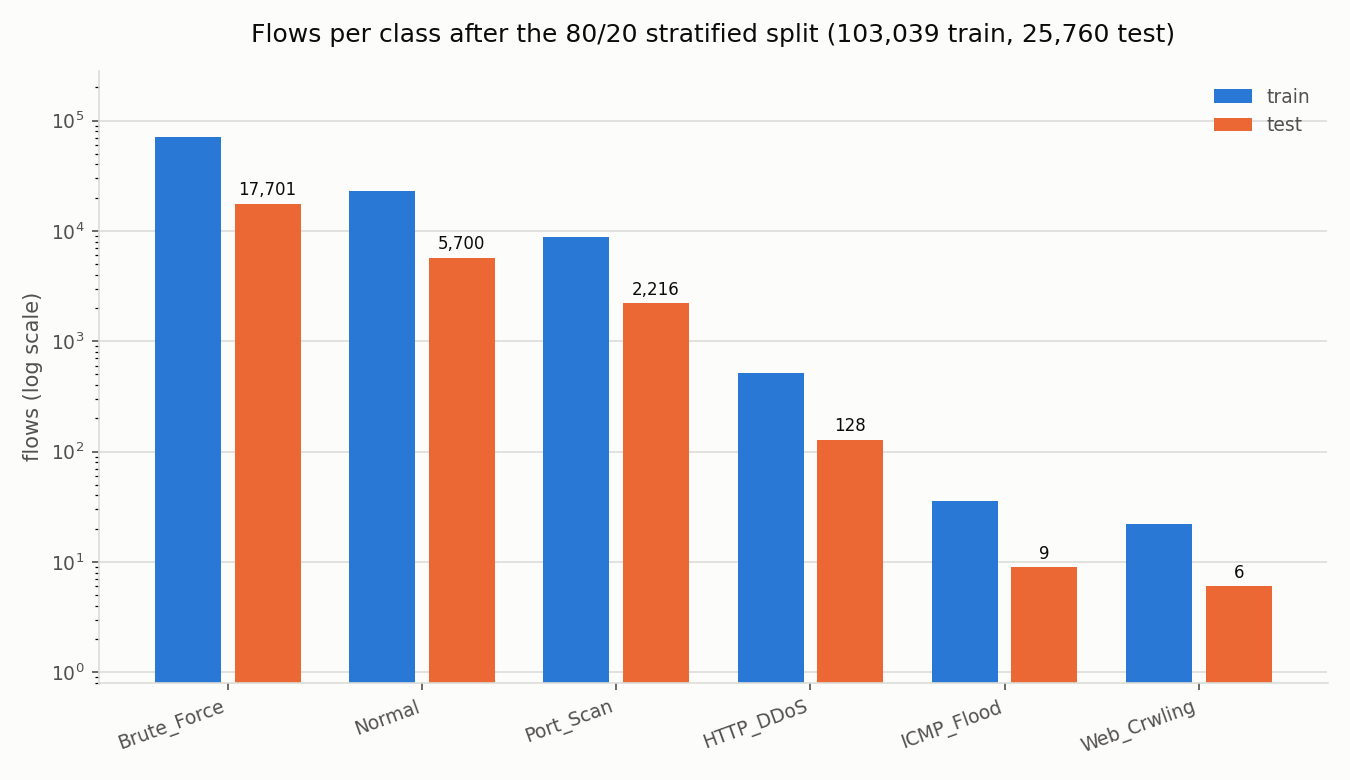

In [22]:
chart = config.STEP5_OUTPUT_DIR / config.STEP5_FILES["chart"]
if chart.exists():
    if splitting.dl.in_notebook():
        from IPython.display import Image, display
        display(Image(filename=str(chart)))
    else:
        print("chart saved to", chart)
else:
    print("No chart at", chart)
    print("Install matplotlib and re-run Step 5 with OVERWRITE_STEP5 = True.")

### 3.2 Scale - fitted on the training rows only

Step 2's scaler saw every row, test rows included, so its min/max carry
information from the test set. Step 3 therefore starts from the **unscaled**
`features_clean.csv` and fits a fresh scaler on `X_train` alone.

Scaled test values outside `[0, 1]` are **expected**: the scaler never saw those
rows, so a test flow can be larger than every training flow. They are counted and
reported, not clipped - `CLIP_TEST_TO_TRAIN_RANGE = False`, because clipping
would quietly flatten real differences between large flows.

The `zero_duration` marker is left alone; it is already 0/1, as are the
`Protocol_*` one-hot columns in own mode.


In [23]:
if "scale_info" in step5:
    info = step5["scale_info"]
    splitting.show_table(splitting.kv_table([
        ("scaler", info["scaler_name"]),
        ("fitted on", "X_train only (%s rows)" % f"{len(step5['X_train']):,}"),
        ("columns scaled", "%d of %d" % (info["n_columns"], step5["X_train"].shape[1])),
        ("columns left alone", ", ".join(
            c for c in step5["X_train"].columns if c not in set(info["columns"]))),
        ("train range", "[%.6f, %.6f]" % (info["train_min"], info["train_max"])),
        ("test range", "[%.6f, %.6f]" % (info["test_min"], info["test_max"])),
        ("test cells outside [0, 1]", f"{info.get('test_cells_outside_0_1', 0):,}"),
        ("clipped", "no" if not info["clipped"] else "yes"),
        ("saved scaler", str(config.STEP5_OUTPUT_DIR / config.STEP5_FILES["scaler"])),
    ]))
    if len(info["out_of_range"]):
        splitting.show_table(info["out_of_range"].head(20),
                             note="Per column: how many test values fall outside "
                                  "[0, 1], and how far. Expected and small.")
else:
    # the loaded path: the same numbers, read back from split_summary.csv
    splitting.show_table(step5["split_summary"],
                         note="Read from split_summary.csv -- Step 5 was loaded from "
                              "disk, so there is no in-memory scaler report. Set "
                              "`OVERWRITE_STEP5 = True` to recompute it.")

,metric,value
0,rows in,128799
1,train rows,103039
2,test rows,25760
3,test_size,0.2
4,random_state,42
5,stratify column,Label
6,classes,6
7,scaler,minmax
8,scaler fitted on,train only
9,columns scaled,66


_Read from split_summary.csv -- Step 5 was loaded from disk, so there is no in-memory scaler report. Set `OVERWRITE_STEP5 = True` to recompute it._

### 3.3 Leakage check - reported, nothing dropped

About half the rows in this dataset share identical feature values once the
identifiers are removed: thousands of scan, flood and brute-force flows genuinely
look alike. A stratified random split therefore puts feature-identical twins on
both sides.

> **This inflates every test score and belongs in the results.** A model can
> "recognise" a test row it has effectively already seen in training, so the
> headline accuracy is optimistic. Report this percentage next to it, and lean on
> per-class recall for the classes whose share here is **low** - those are the
> rows the model actually had to generalise to.
>
> Nothing is dropped. These are real flows, and deleting them would change the
> dataset itself; Step 9 reports a duplicate-free score instead.


In [24]:
splitting.show_table(step5["leakage_table"],
                     note="An exact match on the full UNSCALED feature vector. Saved "
                          "as leakage.csv.")

total = step5["leakage_table"].iloc[-1]
print("%s of %s test rows (%s%%) have a feature-identical twin in training."
      % (f"{int(total['also in train']):,}", f"{int(total['test rows']):,}",
         total["% of this class's test rows"]))

,Label,test rows,also in train,% of this class's test rows
0,Brute_Force,17701,6735,38.049
1,Normal,5700,625,10.965
2,Port_Scan,2216,1717,77.482
3,HTTP_DDoS,128,45,35.156
4,ICMP_Flood,9,0,0.000
5,Web_Crwling,6,1,16.667
6,TOTAL,25760,9123,35.415


_An exact match on the full UNSCALED feature vector. Saved as leakage.csv._

9,123 of 25,760 test rows (35.415%) have a feature-identical twin in training.


### 3.4 Saved files

Everything below is in `C:\MSCAD2022\outputs\step5\`.

| file | what it is |
|---|---|
| `X_train.csv` / `X_test.csv` | the features, scaled with the **train-fitted** scaler - this is what a model trains and is evaluated on |
| `X_train_unscaled.csv` / `X_test_unscaled.csv` | the same rows straight from `features_clean.csv`, for a model that wants its own scaling |
| `y_train.csv` / `y_test.csv` | `Label`, `Label_encoded`, `Label_binary` |
| `meta_train.csv` / `meta_test.csv` | the identifiers, including `Orig_Row`, so any row goes back to its flow |
| `train_indices.csv` / `test_indices.csv` | the row positions in the Step 2 files - the split, reproducible without rerunning it |
| `train_view.csv` / `test_view.csv` | the `preprocessing.csv` layout, **for viewing only** |
| `scaler_train.joblib` | the fitted scaler, with the settings it was fitted under |
| `split_summary.csv`, `step5_report.csv` | the numbers and the actions |
| `split_class_counts.png` | the chart above |

`X_train.csv` is the training matrix: the model features and nothing else.
The two `*_view.csv` files are the readable
counterpart and must never be fed to a model.


In [25]:
import pandas as pd

folder = config.usable_output_dir(config.STEP5_OUTPUT_DIR)
if folder is None:
    print("Step 5 outputs are not readable here:",
          config.why_unusable(config.STEP5_OUTPUT_DIR))
else:
    rows = []
    for key, name in config.STEP5_FILES.items():
        path = folder / name
        rows.append({"file": name, "exists": path.exists(),
                     "size (MB)": round(path.stat().st_size / 1024 / 1024, 3)
                                  if path.exists() else 0.0,
                     "what": key})
    splitting.show_table(pd.DataFrame(rows), note="Folder: %s" % folder)

,file,exists,size (MB),what
0,X_train.csv,True,74.469,X_train
1,X_test.csv,True,18.637,X_test
2,X_train_unscaled.csv,True,26.004,X_train_unscaled
3,X_test_unscaled.csv,True,6.504,X_test_unscaled
4,y_train.csv,True,1.544,y_train
5,y_test.csv,True,0.386,y_test
6,meta_train.csv,True,0.701,meta_train
7,meta_test.csv,True,0.175,meta_test
8,train_indices.csv,True,0.701,train_indices
9,test_indices.csv,True,0.175,test_indices


_Folder: C:\MSCAD2022\outputs_official\step5_

### Shapes, and the head of each side

In [26]:
X_train = pd.read_csv(config.STEP5_OUTPUT_DIR / config.STEP5_FILES["X_train"],
                      low_memory=False)
X_test = pd.read_csv(config.STEP5_OUTPUT_DIR / config.STEP5_FILES["X_test"],
                     low_memory=False)
y_train = pd.read_csv(config.STEP5_OUTPUT_DIR / config.STEP5_FILES["y_train"])
y_test = pd.read_csv(config.STEP5_OUTPUT_DIR / config.STEP5_FILES["y_test"])

splitting.show_table(splitting.kv_table([
    ("X_train", "%s rows x %d columns" % (f"{X_train.shape[0]:,}", X_train.shape[1])),
    ("X_test", "%s rows x %d columns" % (f"{X_test.shape[0]:,}", X_test.shape[1])),
    ("y_train", "%s rows x %d columns" % (f"{y_train.shape[0]:,}", y_train.shape[1])),
    ("y_test", "%s rows x %d columns" % (f"{y_test.shape[0]:,}", y_test.shape[1])),
    ("train + test", f"{len(X_train) + len(X_test):,}"),
    ("identical columns", list(X_train.columns) == list(X_test.columns)),
]))

counts = y_test[config.LABEL_COLUMN].value_counts()
splitting.show_table(pd.DataFrame({"Label": counts.index.astype(str),
                                   "test rows": counts.to_numpy()}),
                     note="Per-class test counts -- every class must appear here.")
splitting.show_table(X_train.head(5), all_columns=True,
                     note="X_train.head(5), all %d columns." % X_train.shape[1])

,metric,value
0,X_train,"103,039 rows x 67 columns"
1,X_test,"25,760 rows x 67 columns"
2,y_train,"103,039 rows x 3 columns"
3,y_test,"25,760 rows x 3 columns"
4,train + test,"128,799"
5,identical columns,True


,Label,test rows
0,Brute_Force,17701
1,Normal,5700
2,Port_Scan,2216
3,HTTP_DDoS,128
4,ICMP_Flood,9
5,Web_Crwling,6


_Per-class test counts -- every class must appear here._

,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,Fwd Pkt Len Mean,Fwd Pkt Len Std,Bwd Pkt Len Max,Bwd Pkt Len Min,Bwd Pkt Len Mean,Bwd Pkt Len Std,Flow Byts/s,Flow Pkts/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Tot,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Tot,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Bwd PSH Flags,Bwd URG Flags,Fwd Header Len,Bwd Header Len,Fwd Pkts/s,Bwd Pkts/s,Pkt Len Min,Pkt Len Max,Pkt Len Mean,Pkt Len Std,Pkt Len Var,FIN Flag Cnt,SYN Flag Cnt,RST Flag Cnt,PSH Flag Cnt,ACK Flag Cnt,URG Flag Cnt,CWE Flag Count,ECE Flag Cnt,Down/Up Ratio,Pkt Size Avg,Fwd Seg Size Avg,Bwd Seg Size Avg,Subflow Fwd Pkts,Subflow Fwd Byts,Subflow Bwd Pkts,Subflow Bwd Byts,Init Bwd Win Byts,Fwd Act Data Pkts,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,zero_duration
0,0.000013,0.000014,0.000060,5.849650e-07,0.000004,0.003380,0.0,0.016342,0.009378,0.090538,0.0,0.051644,0.142398,0.007034,0.009223,0.000002,0.000002,0.000004,0.000002,0.000004,0.000004,0.000000,0.000004,0.000004,0.000013,0.000004,0.000004,0.000008,0.000002,0.0,0.0,0.000014,0.000090,0.005270,0.013175,0.0,0.011584,0.042041,0.031721,0.001006,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.029851,0.032031,0.016342,0.051644,0.000014,5.849650e-07,0.000060,0.000004,0.000717,0.000007,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,0.000049,0.000029,0.000104,8.934011e-07,0.000049,0.005162,0.0,0.012480,0.010127,0.350624,0.0,0.385103,0.628781,0.017357,0.004072,0.000004,0.000009,0.000022,0.000002,0.000047,0.000016,0.000013,0.000022,0.000006,0.000049,0.000009,0.000016,0.000031,0.000002,0.0,0.0,0.000029,0.000134,0.002715,0.005429,0.0,0.044862,0.247875,0.149791,0.022437,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.029851,0.179021,0.012480,0.385103,0.000029,8.934011e-07,0.000104,0.000049,0.000839,0.000007,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,0.000022,0.000029,0.000104,1.712352e-06,0.000049,0.009894,0.0,0.023919,0.019411,0.350624,0.0,0.379623,0.633661,0.039937,0.009192,0.000002,0.000003,0.000006,0.000002,0.000020,0.000007,0.000006,0.000011,0.000003,0.000022,0.000004,0.000004,0.000008,0.000001,0.0,0.0,0.000029,0.000134,0.006128,0.012256,0.0,0.044862,0.252656,0.149779,0.022434,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.029851,0.182474,0.023919,0.379623,0.000029,1.712352e-06,0.000104,0.000049,0.000839,0.000007,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,0.000002,0.000007,0.000000,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.013605,0.000002,0.000000,0.000002,0.000004,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000007,0.000015,0.013605,0.013605,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.014925,0.000000,0.000000,0.000000,0.000007,0.000000e+00,0.000000,0.000000,0.062668,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4,0.000051,0.000029,0.000104,1.712352e-06,0.000049,0.009894,0.0,0.023919,0.019411,0.350624,0.0,0.379623,0.633661,0.017063,0.003927,0.000005,0.000011,0.000020,0.000002,0.000049,0.000016,0.000017,0.000026,0.000003,0.000051,0.000010,0.000018,0.000027,0.000001,0.0,0.0,0.000029,0.000134,0.002618,0.005236,0.0,0.044862,0.252656,0.149779,0.022434,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.029851,0.182474,0.023919,0.379623,0.000029,1.712352e-06,0.000104,0.000049,0.000839,0.000007,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


_X_train.head(5), all 67 columns._

### Verification

Every file above was re-read from disk and checked: the row counts add up to the
Step 2 total, no row position is in both sides, `X_train` and `X_test` have the
same columns in the same order, the labels and metadata line up with the split
positions (compared on `Orig_Row`), and neither matrix holds a NaN or an inf.


In [27]:
if "saved" in step5 and "verification" in step5.get("saved", {}):
    splitting.show_table(step5["saved"]["verification"])
    print()
    print("ALL CHECKS PASSED:", step5["saved"]["ok"])
else:
    print("Step 5 was loaded from disk, so there is no fresh verification table.")
    print("Set OVERWRITE_STEP5 = True and re-run to split and verify again.")

Step 5 was loaded from disk, so there is no fresh verification table.
Set OVERWRITE_STEP5 = True and re-run to split and verify again.


### What Step 4 picks up

1. **Train on `X_train.csv` only.** `X_test.csv` is touched once, at the end, to
   report a score. Any choice made by looking at the test set - a threshold, a
   feature, a hyper-parameter - makes that score meaningless.
2. **The imbalance is still there, on purpose.** SMOTE, resampling or class
   weights belong in Step 4 and must be fitted on the **training** side of this
   split only. Oversampling before the split copies rows across it, which is the
   same leak as scaling before the split.
3. **Use `train_indices.csv` / `test_indices.csv`** to carry this exact split
   into any other experiment, instead of resplitting with the same seed and
   hoping.
4. **Report the 3.3 leakage percentage next to every score.** Macro-F1 and
   per-class recall, not accuracy: with Brute_Force at tens of thousands of rows
   and Web_Crwling at 23, accuracy is nearly a measure of the majority class.


---

## Step 4 - Feature Selection (MI + Pearson + PI to top 30)

**Purpose** — Reduce the feature set to `N_SELECTED_FEATURES = 30` columns using
three complementary measures.

**Input** — `C:\MSCAD2022\outputs\step5` — `X_train.csv`, `y_train.csv`.
`X_test.csv` is read only at the end, to take the same columns.

**Method** — Mutual information between each feature and `Label_encoded`
(`MI_N_NEIGHBORS = 3`), computed once; a Pearson redundancy filter dropping one
of every pair with $|r| \geq 0.95$ (`PEARSON_THRESHOLD`), keeping the higher-MI
feature; permutation importance of a random forest on an inner split of the
training set (`PI_SCORING = "f1_macro"`, `PI_N_REPEATS = 10`).

**Output** — `C:\MSCAD2022\outputs\step6` — `X_train_selected.csv`,
`X_test_selected.csv`, `selected_features.json`, `combined_ranking.csv` and the
supporting tables and charts.

**Why** — The three measures fail in different directions. Mutual information
examines one feature at a time, so two identical features both score highly;
Pearson removes that redundancy without using labels; permutation importance
measures what a model actually uses, but understates a feature whose correlated
partner remains in the set.

Mutual information between feature $X$ and label $Y$:

$$I(X; Y) = \sum_{x}\sum_{y} p(x, y)\, \log \frac{p(x, y)}{p(x)\,p(y)}$$

Pearson correlation between two features:

$$r_{ij} = \frac{\operatorname{cov}(X_i, X_j)}{\sigma_{X_i}\,\sigma_{X_j}}$$

Permutation importance of feature $j$, where $s$ is macro-F1 and $s_{k,j}$ is the
score after the $k$-th shuffle of that column:

$$\mathrm{PI}_j = s - \frac{1}{K}\sum_{k=1}^{K} s_{k,j}$$

Both scores are min-max normalised over the surviving features and added, so each
contributes at most 1.0:

$$\text{CombinedScore} = \mathrm{MI}' + \mathrm{PI}', \qquad
\mathrm{MI}' = \frac{\mathrm{MI} - \min}{\max - \min}$$

66+ features in, 30 out. Three measures, each answering a different question:

| | what it measures | blind to |
|---|---|---|
| **4.2 Mutual information** | how much knowing the feature tells you about the class | every other feature - two identical features both score highly |
| **4.3 Pearson \|r\|** | how much two **features** repeat each other. No labels at all | whether either is useful |
| **4.4 Permutation importance** | how far the forest's macro-F1 falls when that one column is shuffled | a feature whose partner can stand in for it |

**Why all three, and why MI and PI are added rather than one being picked.**
They fail in opposite directions. PI understates a feature whose partner is
still in the set at \|r\| around 0.80-0.95: shuffle one and the forest simply
leans on the other, so neither looks important. MI never sees other features, so
that cannot happen to it. Conversely MI rewards a feature that merely tracks the
label without adding anything the others do not already give; PI catches those.
Adding the two normalised scores means a feature has to fail *both* tests to be
dropped.

**Everything is decided on the training set.** MI, the correlation matrix, the
inner fit/validation split and the permutation importance all run on `X_train`
alone. `X_test` is touched once, in 4.6, to take the same 30 columns in the same
order. Choosing features by looking at the test set is the same leak as scaling
before the split.

> **Step 4 does nothing else.** No autoencoder, no CNN-LSTM, no modelling. No
> class-imbalance handling - no SMOTE, no resampling. The RandomForest in 4.4
> exists only to rank features; 4.4 explains why its score is not a result.


### Step 4 settings

In [28]:
from src.mscad import feature_selection

feature_selection.show_table(feature_selection.kv_table([
    ("input folder", str(config.STEP5_OUTPUT_DIR)),
    ("output folder", str(config.STEP6_OUTPUT_DIR)),
    ("PEARSON_THRESHOLD", config.PEARSON_THRESHOLD),
    ("PEARSON_REPORT_LOWER", config.PEARSON_REPORT_LOWER),
    ("N_SELECTED_FEATURES", config.N_SELECTED_FEATURES),
    ("RF_PARAMS", str(config.RF_PARAMS)),
    ("PI_SCORING / PI_N_REPEATS", "%s / %d" % (config.PI_SCORING, config.PI_N_REPEATS)),
    ("PI_VALIDATION_SIZE", config.PI_VALIDATION_SIZE),
    ("MI_N_NEIGHBORS", config.MI_N_NEIGHBORS),
    ("CLIP_NEGATIVE_PI", config.CLIP_NEGATIVE_PI),
    ("OVERWRITE_STEP6", config.OVERWRITE_STEP6),
    ("outputs already exist", feature_selection.step6_outputs_exist()),
]), note="`PI_SCORING = \"f1_macro\"` weights every class equally, so a feature "
         "that only the 23-row classes depend on still registers. With `accuracy` "
         "the 84% Brute_Force class would drown them out entirely.")

,metric,value
0,input folder,C:\MSCAD2022\outputs_official\step5
1,output folder,C:\MSCAD2022\outputs_official\step6
2,PEARSON_THRESHOLD,0.95
3,PEARSON_REPORT_LOWER,0.8
4,N_SELECTED_FEATURES,40
5,RF_PARAMS,"{'n_estimators': 200, 'class_weight': 'balance..."
6,PI_SCORING / PI_N_REPEATS,f1_macro / 10
7,PI_VALIDATION_SIZE,0.2
8,MI_N_NEIGHBORS,3
9,CLIP_NEGATIVE_PI,True


_`PI_SCORING = "f1_macro"` weights every class equally, so a feature that only the 23-row classes depend on still registers. With `accuracy` the 84% Brute_Force class would drown them out entirely._

### Run Step 4

**This cell is slow.** Permutation importance refits nothing but re-scores the
validation rows `n_repeats` times per feature - on 66 features at 10 repeats
that is 660 scorings, and it can take several minutes. The elapsed time for MI
and for PI is printed as each finishes.

With `OVERWRITE_STEP6 = False` and the outputs already present, they are loaded
from disk instead, which is why that setting is worth keeping.


In [29]:
step6 = feature_selection.run_step6()

,metric,value
0,status,loaded from disk (OVERWRITE_STEP6 = False)
1,folder,C:\MSCAD2022\outputs_official\step6
2,features selected,30
3,X_train_selected,"103,039 rows x 30 columns"
4,X_test_selected,"25,760 rows x 30 columns"


_Set `OVERWRITE_STEP6 = True` in config.py to select again. Permutation importance is the slow part, so this path is worth keeping._

### 4.1 Training data overview

The input is `X_train.csv` / `X_test.csv` from Step 3, already scaled with the
train-fitted scaler. Before anything is scored, four things are confirmed: the
two frames carry identical columns in identical order, the labels line up, no
label column has crept into the features, and no identifier has either.

A column that is **constant** across the training rows is dropped here. Pearson
correlation is undefined for it (zero variance means dividing by zero), so it
would otherwise put a row and a column of `NaN` into the matrix and quietly
corrupt the redundancy filter. A constant also tells a model nothing, so nothing
is lost.


In [30]:
if step6.get("status") != "loaded_existing":
    feature_selection.show_table(step6["classes"])
    dropped = step6["constant_dropped"]
    print("constant columns dropped:", ", ".join(dropped) if dropped else "(none)")
    print("features after the drop  :", len(step6["mi"]))
else:
    print("Step 6 was loaded from disk, so the in-memory tables are not available.")
    print("Set OVERWRITE_STEP6 = True in config.py and re-run the cell above.")

Step 6 was loaded from disk, so the in-memory tables are not available.
Set OVERWRITE_STEP6 = True in config.py and re-run the cell above.


### 4.2 Mutual information

`mutual_info_classif` between every feature and `Label_encoded`, on the training
rows. MI is a *statistical dependency* measure: unlike a correlation it finds
non-linear relationships, and it makes no assumption that the relationship has a
direction.

Two details that matter:

- The binary columns -- `zero_duration`, and `Protocol_*` in own mode -- are
  declared **discrete**. Left as continuous, the k-nearest-neighbour
  estimator would
  treat a column of 0s and 1s as a dense number line and return a wrong score.
- MI is **stochastic** - it jitters continuous inputs before estimating - so it
  is computed **once** per run and the same numbers are reused for the Pearson
  tie-break in 4.3 and the ranking in 4.5. Recomputing it would give slightly
  different values and the two stages would silently disagree.


In [31]:
if step6.get("status") != "loaded_existing":
    feature_selection.show_table(step6["mi_table_all"].head(25),
                                 note="Top 25 of %d by mutual information. Saved in "
                                      "full as mi_scores_all.csv."
                                      % len(step6["mi_table_all"]))
    print("MI computed in %.1f s" % step6["mi_seconds"])
else:
    feature_selection.show_table(step6["mi_all"].head(25),
                                 note="Read back from mi_scores_all.csv.")

,rank,feature,mutual_information
0,1,Init Bwd Win Byts,0.791570
1,2,Bwd Header Len,0.711244
2,3,Fwd Pkts/s,0.703072
3,4,Flow IAT Max,0.670060
4,5,Bwd Pkts/s,0.669236
5,6,Flow Duration,0.669048
6,7,Flow Pkts/s,0.646051
7,8,Flow IAT Mean,0.618134
8,9,Fwd Header Len,0.582845
9,10,Flow IAT Min,0.578888


_Read back from mi_scores_all.csv._

### 4.3 Pearson redundancy filter

The absolute correlation between every **pair of features**. No labels are
involved: this step is only about features repeating each other.

For every pair at `|r| >= 0.95` one of the two is dropped, keeping whichever has
the higher MI from 4.2. The walk is deterministic by construction: pairs are
processed from the highest `|r|` downward, a pair is skipped once either side has
already gone, and an MI tie falls back to feature order - so the result never
depends on dictionary or set iteration order.

CICFlowMeter produces several near-copies by design - `Subflow Fwd Pkts` is
usually `Tot Fwd Pkts`, `Pkt Size Avg` tracks `Pkt Len Mean` - which is what this
filter is for. In own mode the `Protocol_*` one-hot columns show up here too: with
three protocols, two of the indicators determine the third, so they are
genuinely redundant.


In [32]:
if step6.get("status") != "loaded_existing":
    dropped = step6["dropped_pairs"]
    if len(dropped):
        feature_selection.show_table(dropped,
            note="`MI kept` is always >= `MI dropped` - the higher-MI half of each "
                 "pair survives. Saved as pearson_dropped_pairs.csv.")
    else:
        print("No pair reached |r| >= %.2f, so nothing was dropped."
              % config.PEARSON_THRESHOLD)
    print("features: %d  ->  %d" % (len(step6["mi"]), len(step6["pearson_kept"])))

### Still correlated, but kept

These pairs sit in `[0.80, 0.95)`. They are not redundant enough to drop, but
they are exactly the pairs permutation importance will **understate**: shuffle
one and the forest leans on the other, so neither looks important. That is the
concrete reason MI is added to PI rather than replaced by it.


In [33]:
if step6.get("status") != "loaded_existing":
    remaining = step6["remaining_pairs"]
    if len(remaining):
        feature_selection.show_table(remaining.head(25),
            note="%d pair(s) in [%.2f, %.2f). Saved as pearson_remaining_pairs.csv."
                 % (len(remaining), config.PEARSON_REPORT_LOWER,
                    config.PEARSON_THRESHOLD))
    else:
        print("No remaining pair in [%.2f, %.2f)."
              % (config.PEARSON_REPORT_LOWER, config.PEARSON_THRESHOLD))

### Correlation heatmap

One hue, light to dark: `|r|` is a magnitude, so a single blue ramp reads it
correctly. The dark diagonal is each feature against itself; any other dark
square is a redundant pair.


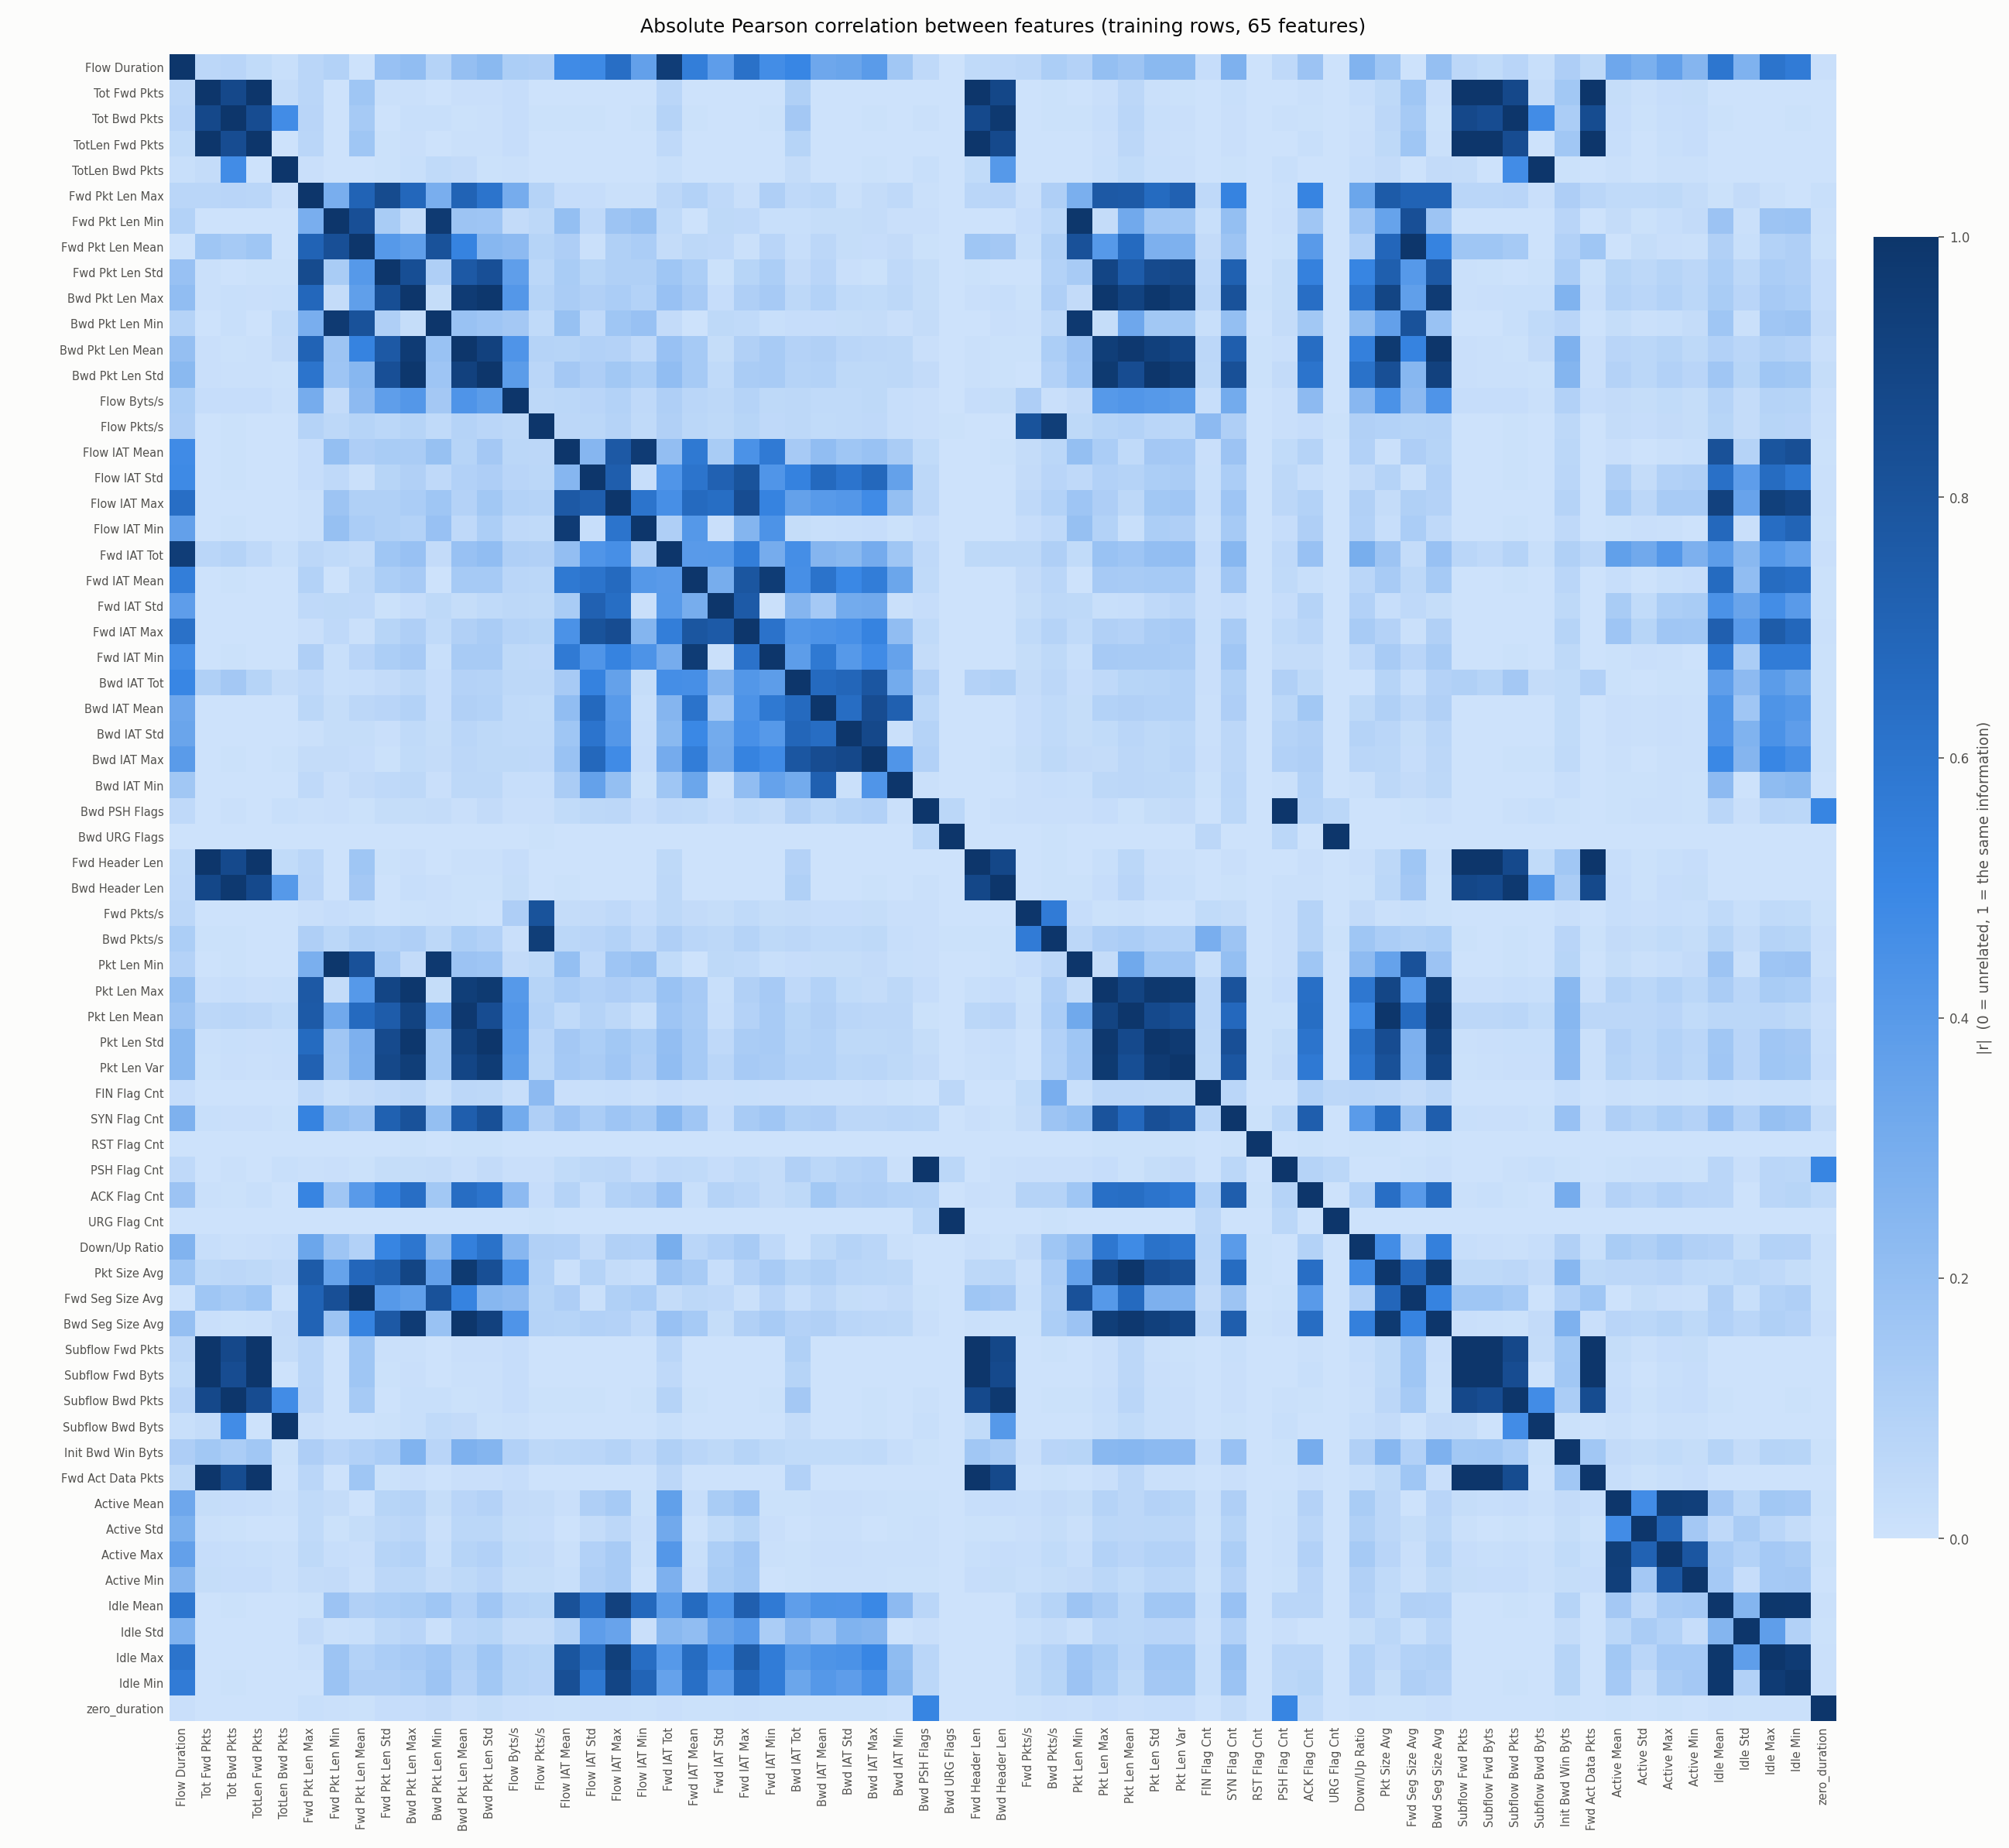

In [34]:
heatmap = config.STEP6_OUTPUT_DIR / config.STEP6_FILES["heatmap"]
if heatmap.exists():
    if feature_selection.dl.in_notebook():
        from IPython.display import Image, display
        display(Image(filename=str(heatmap)))
    else:
        print("heatmap saved to", heatmap)
else:
    print("No heatmap at", heatmap)
    print("Install matplotlib and re-run Step 6 with OVERWRITE_STEP6 = True.")

### 4.4 Permutation importance

The training set is split **again**, into an inner fit part and an inner
validation part (stratified, 80/20). A RandomForest is fitted on the fit part;
then each feature's column in the validation part is shuffled and the drop in
macro-F1 is measured. A feature the forest relies on loses it a lot of score; a
feature it ignores loses it nothing.

> **The baseline macro-F1 below is a ranking tool, not a model result.** Around
> half of this dataset's rows share identical feature values once the identifiers
> are gone - thousands of scan, flood and brute-force flows genuinely look alike -
> so feature-identical rows sit in both the fit and the validation part. The
> forest is scored partly on rows it has already seen. The percentage is printed
> below; quote Step 5's numbers, never this one.

> **PI understates correlated features.** For any pair still at `|r|` 0.80-0.95
> after 4.3, shuffling one leaves the other intact and the forest simply uses it,
> so both score low. MI is immune to this, which is the whole reason 4.5 adds the
> two instead of trusting either alone.


In [35]:
if step6.get("status") != "loaded_existing":
    info = step6["pi_info"]
    feature_selection.show_table(feature_selection.kv_table([
        ("inner fit rows", f"{info['fit_rows']:,}"),
        ("inner validation rows", f"{info['validation_rows']:,}"),
        ("forest fit time", "%.1f s" % info["fit_seconds"]),
        ("permutation time", "%.1f s" % info["pi_seconds"]),
        ("scoring", "%s, %d repeats" % (config.PI_SCORING, config.PI_N_REPEATS)),
        ("baseline macro-F1", "%.4f" % info["baseline_macro_f1"]),
        ("validation rows also in the fit part", "%s (%.2f%%)"
         % (f"{info['overlap']['also in fit']:,}", info["overlap"]["% of validation"])),
    ]))
    feature_selection.show_table(info["per_class_f1"],
                                 note="Per-class F1 on the inner validation part.")
    if info["classes_missing_from_validation"]:
        print("[WARN] no validation rows for:",
              ", ".join(info["classes_missing_from_validation"]))
    if info["thin_validation_classes"]:
        print("[WARN] fewer than 2 validation rows for:",
              info["thin_validation_classes"])
    feature_selection.show_table(step6["pi_table"].head(25),
                                 note="Top 25 by permutation importance. Saved in "
                                      "full as pi_scores.csv.")
else:
    feature_selection.show_table(step6["pi_scores"].head(25),
                                 note="Read back from pi_scores.csv.")

,feature,pi_mean,pi_std
0,Init Bwd Win Byts,0.087531,0.000445
1,Pkt Len Max,0.000440,0.000444
2,Fwd IAT Max,0.000422,0.000368
3,Pkt Len Mean,0.000329,0.000420
4,Flow IAT Std,0.000283,0.000360
5,Flow IAT Mean,0.000155,0.000049
6,Flow Duration,0.000144,0.000055
7,SYN Flag Cnt,0.000111,0.000051
8,Fwd IAT Tot,0.000060,0.000035
9,Idle Min,0.000059,0.000020


_Read back from pi_scores.csv._

### How much of the inner validation part is already in the fit part

In [36]:
if step6.get("status") != "loaded_existing":
    feature_selection.show_table(step6["overlap_table"],
        note="Exact matches on the full feature vector. The classes with a LOW "
             "percentage here are the ones the forest actually had to generalise "
             "to - weigh their F1 accordingly.")
else:
    feature_selection.show_table(step6["pi_overlap"],
                                 note="Read back from pi_duplicate_overlap.csv.")

,Label,validation rows,also in fit,% of this class
0,Brute_Force,14160,5178,36.568
1,Normal,4561,450,9.866
2,Port_Scan,1773,1358,76.593
3,HTTP_DDoS,103,43,41.748
4,ICMP_Flood,7,0,0.000
5,Web_Crwling,4,0,0.000
6,TOTAL,20608,7029,34.108


_Read back from pi_duplicate_overlap.csv._

### 4.5 Combine MI and PI

The two scores live on completely different scales - MI is in nats, PI is a
difference in F1 - so adding them raw would let whichever happens to be larger
decide everything. Both are min-max normalised across the surviving features
first:

$$\text{MI}' = \frac{\text{MI} - \min}{\max - \min}, \qquad
  \text{PI}' = \frac{\text{PI} - \min}{\max - \min}, \qquad
  \text{CombinedScore} = \text{MI}' + \text{PI}'$$

Each part contributes at most 1.0, so the combined score runs 0 to 2 and neither
measure can dominate by living on a bigger scale. Two edge cases are handled
explicitly rather than left to produce `NaN`: a **negative** PI (shuffling made
the score *better*, which is noise around zero, not evidence against the feature)
is clipped to 0 so it cannot stretch the scale, and a **flat** score where
`max == min` normalises to 0 for every feature with a warning, leaving the
ranking to the other measure.


In [37]:
ranking = step6["ranking"]
feature_selection.show_table(ranking.head(35),
    note="Sorted by CombinedScore, ties broken by MI' and then by feature name, so "
         "the order is fully determined. Saved in full as combined_ranking.csv.")

,rank,feature,MI,PI,MI_norm,PI_norm,CombinedScore,selected
0,1,Init Bwd Win Byts,0.791570,0.087531,1.000000,1.000000,2.000000,True
1,2,Bwd Header Len,0.711244,0.000000,0.898456,0.000000,0.898456,True
2,3,Fwd Pkts/s,0.703072,0.000000,0.888125,0.000000,0.888125,True
3,4,Flow Duration,0.669048,0.000144,0.845114,0.001640,0.846754,True
4,5,Flow IAT Max,0.670060,0.000000,0.846394,0.000000,0.846394,True
5,6,Bwd Pkts/s,0.669236,0.000001,0.845352,0.000012,0.845363,True
6,7,Flow Pkts/s,0.646051,0.000043,0.816043,0.000490,0.816533,True
7,8,Flow IAT Mean,0.618134,0.000155,0.780751,0.001772,0.782523,True
8,9,Fwd Header Len,0.582845,0.000000,0.736140,0.000000,0.736140,True
9,10,Pkt Len Max,0.465693,0.000440,0.588043,0.005023,0.593066,True


_Sorted by CombinedScore, ties broken by MI' and then by feature name, so the order is fully determined. Saved in full as combined_ranking.csv._

### 4.6 The selected features

The top `N_SELECTED_FEATURES` by combined score. If the Pearson filter left fewer
than that, all of them are selected and a warning says so.


In [38]:
selected = step6["selected"]
chosen = ranking[ranking["selected"]] if "selected" in ranking.columns \
    else ranking.head(len(selected))
feature_selection.show_table(
    chosen[["rank", "feature", "MI", "PI", "MI_norm", "PI_norm", "CombinedScore"]],
    note="The %d selected features, in rank order." % len(selected))

cut = float(chosen["CombinedScore"].iloc[-1])
rest = ranking[~ranking["feature"].isin(set(selected))]
if len(rest):
    print("lowest selected : %.4f  (%s)" % (cut, chosen["feature"].iloc[-1]))
    print("highest rejected: %.4f  (%s)"
          % (float(rest["CombinedScore"].iloc[0]), rest["feature"].iloc[0]))
    print("gap at the cut  : %.4f" % (cut - float(rest["CombinedScore"].iloc[0])))

,rank,feature,MI,PI,MI_norm,PI_norm,CombinedScore
0,1,Init Bwd Win Byts,0.791570,0.087531,1.000000,1.000000,2.000000
1,2,Bwd Header Len,0.711244,0.000000,0.898456,0.000000,0.898456
2,3,Fwd Pkts/s,0.703072,0.000000,0.888125,0.000000,0.888125
3,4,Flow Duration,0.669048,0.000144,0.845114,0.001640,0.846754
4,5,Flow IAT Max,0.670060,0.000000,0.846394,0.000000,0.846394
5,6,Bwd Pkts/s,0.669236,0.000001,0.845352,0.000012,0.845363
6,7,Flow Pkts/s,0.646051,0.000043,0.816043,0.000490,0.816533
7,8,Flow IAT Mean,0.618134,0.000155,0.780751,0.001772,0.782523
8,9,Fwd Header Len,0.582845,0.000000,0.736140,0.000000,0.736140
9,10,Pkt Len Max,0.465693,0.000440,0.588043,0.005023,0.593066


_The 30 selected features, in rank order._

lowest selected : 0.1344  (SYN Flag Cnt)
highest rejected: 0.1235  (Active Min)
gap at the cut  : 0.0109


### Top 30 by combined score

Each bar is split into its two parts, so a feature carried by MI alone and one
carried by PI alone are visibly different even though they land at the same
total. A bar that is almost entirely orange is a feature the forest leans on
that MI barely notices; an almost entirely blue one is the reverse - and that one
is often half of a correlated pair whose PI was suppressed.


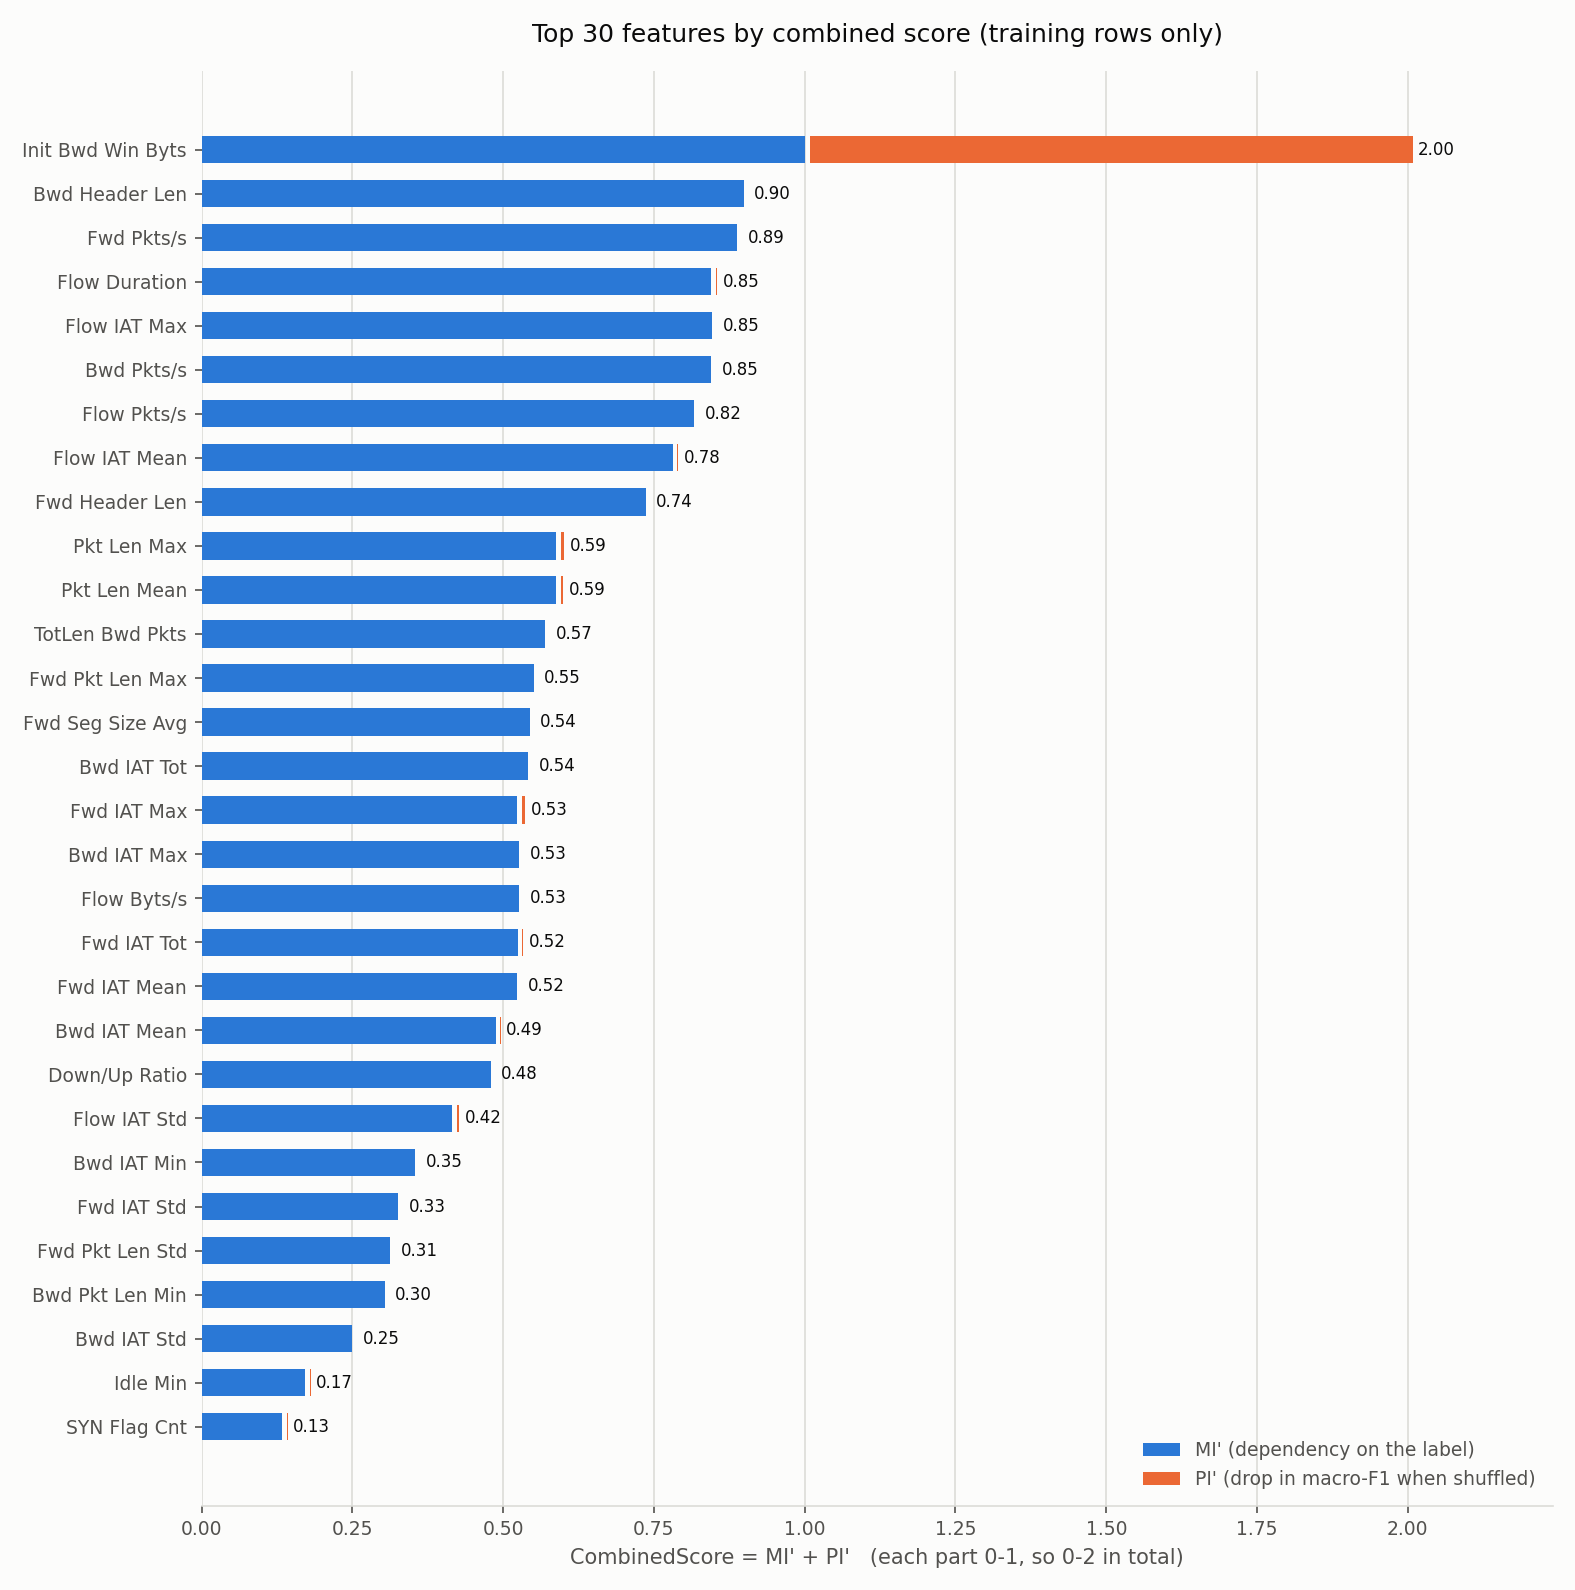

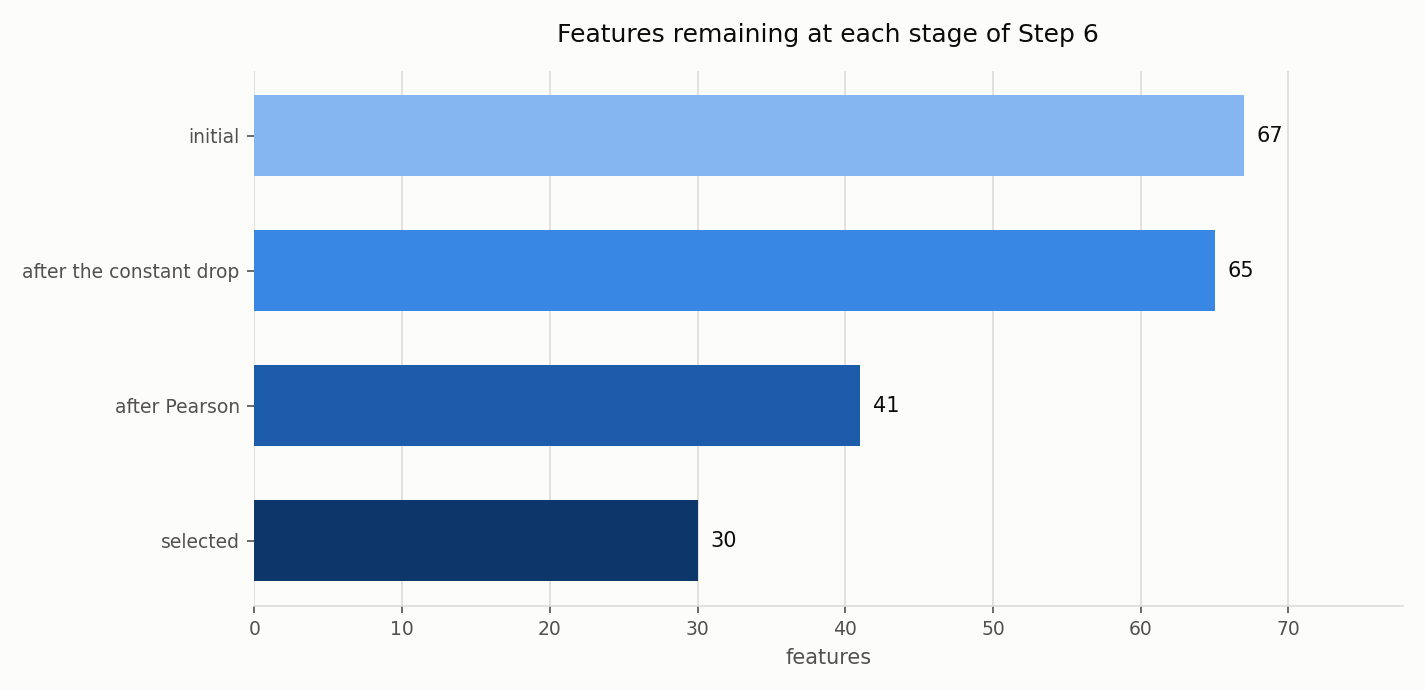

In [39]:
chart = config.STEP6_OUTPUT_DIR / config.STEP6_FILES["ranking_chart"]
funnel = config.STEP6_OUTPUT_DIR / config.STEP6_FILES["funnel"]
if feature_selection.dl.in_notebook():
    from IPython.display import Image, display
    for picture in (chart, funnel):
        if picture.exists():
            display(Image(filename=str(picture)))
        else:
            print("missing:", picture)
else:
    print("charts:", chart, funnel)

### Saved files

Everything below is in `C:\MSCAD2022\outputs\step6\`.

| file | what it is |
|---|---|
| `X_train_selected.csv` / `X_test_selected.csv` | the 30 selected columns, same order in both - **this is what Step 5 trains on** |
| `selected_features.json` | the ordered names plus every setting they were chosen under |
| `combined_ranking.csv` | every surviving feature with MI, PI, both normalised scores and `selected` |
| `mi_scores_all.csv` / `mi_scores.csv` | MI before and after the Pearson filter |
| `pearson_corr_matrix.csv`, `pearson_dropped_pairs.csv`, `pearson_remaining_pairs.csv` | the redundancy filter's working |
| `pi_scores.csv`, `rf_per_class_f1.csv`, `pi_duplicate_overlap.csv` | the permutation stage |
| `y_train.csv` / `y_test.csv` | copied from Step 3, unchanged |
| `rf_baseline.joblib` | the ranking forest - **not** a model for reporting |
| `step6_report.csv` | feature counts at each stage, and what was done |


In [40]:
import pandas as pd

folder = config.usable_output_dir(config.STEP6_OUTPUT_DIR)
if folder is None:
    print("Step 6 outputs are not readable here:",
          config.why_unusable(config.STEP6_OUTPUT_DIR))
else:
    rows = []
    for key, name in config.STEP6_FILES.items():
        path = folder / name
        rows.append({"file": name, "exists": path.exists(),
                     "size (MB)": round(path.stat().st_size / 1024 / 1024, 3)
                                  if path.exists() else 0.0,
                     "what": key})
    feature_selection.show_table(pd.DataFrame(rows), note="Folder: %s" % folder)

    X_train_sel = pd.read_csv(folder / config.STEP6_FILES["X_train_selected"],
                              low_memory=False)
    X_test_sel = pd.read_csv(folder / config.STEP6_FILES["X_test_selected"],
                             low_memory=False)
    feature_selection.show_table(feature_selection.kv_table([
        ("X_train_selected", "%s rows x %d columns"
         % (f"{X_train_sel.shape[0]:,}", X_train_sel.shape[1])),
        ("X_test_selected", "%s rows x %d columns"
         % (f"{X_test_sel.shape[0]:,}", X_test_sel.shape[1])),
        ("identical columns, in order",
         list(X_train_sel.columns) == list(X_test_sel.columns)),
    ]))
    feature_selection.show_table(X_train_sel.head(5), all_columns=True,
                                 note="X_train_selected.head(5).")

,file,exists,size (MB),what
0,mi_scores_all.csv,True,0.002,mi_all
1,mi_scores.csv,True,0.001,mi_kept
2,pearson_corr_matrix.csv,True,0.083,corr_matrix
3,pearson_dropped_pairs.csv,True,0.001,dropped_pairs
4,pearson_remaining_pairs.csv,True,0.001,remaining_pairs
5,pi_scores.csv,True,0.002,pi_scores
6,rf_per_class_f1.csv,True,0.000,per_class_f1
7,pi_duplicate_overlap.csv,True,0.000,pi_overlap
8,combined_ranking.csv,True,0.004,ranking
9,selected_features.json,True,0.001,selected


_Folder: C:\MSCAD2022\outputs_official\step6_

,metric,value
0,X_train_selected,"103,039 rows x 30 columns"
1,X_test_selected,"25,760 rows x 30 columns"
2,"identical columns, in order",True


,Init Bwd Win Byts,Bwd Header Len,Fwd Pkts/s,Flow Duration,Flow IAT Max,Bwd Pkts/s,Flow Pkts/s,Flow IAT Mean,Fwd Header Len,Pkt Len Max,Pkt Len Mean,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Seg Size Avg,Bwd IAT Tot,Fwd IAT Max,Bwd IAT Max,Flow Byts/s,Fwd IAT Tot,Fwd IAT Mean,Bwd IAT Mean,Down/Up Ratio,Flow IAT Std,Bwd IAT Min,Fwd IAT Std,Fwd Pkt Len Std,Bwd Pkt Len Min,Bwd IAT Std,Idle Min,SYN Flag Cnt
0,0.000717,0.000090,0.005270,0.000013,0.000004,0.013175,0.009223,0.000002,0.000014,0.011584,0.042041,0.000004,0.003380,0.016342,0.000013,0.000004,0.000008,0.007034,0.000004,0.000004,0.000004,0.029851,0.000002,0.000002,0.000000,0.009378,0.0,0.000004,0.0,1.0
1,0.000839,0.000134,0.002715,0.000049,0.000022,0.005429,0.004072,0.000004,0.000029,0.044862,0.247875,0.000049,0.005162,0.012480,0.000049,0.000022,0.000031,0.017357,0.000047,0.000016,0.000009,0.029851,0.000009,0.000002,0.000013,0.010127,0.0,0.000016,0.0,1.0
2,0.000839,0.000134,0.006128,0.000022,0.000006,0.012256,0.009192,0.000002,0.000029,0.044862,0.252656,0.000049,0.009894,0.023919,0.000022,0.000011,0.000008,0.039937,0.000020,0.000007,0.000004,0.029851,0.000003,0.000001,0.000006,0.019411,0.0,0.000004,0.0,1.0
3,0.062668,0.000015,0.013605,0.000002,0.000002,0.013605,0.013605,0.000002,0.000007,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.014925,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0
4,0.000839,0.000134,0.002618,0.000051,0.000020,0.005236,0.003927,0.000005,0.000029,0.044862,0.252656,0.000049,0.009894,0.023919,0.000051,0.000026,0.000027,0.017063,0.000049,0.000016,0.000010,0.029851,0.000011,0.000001,0.000017,0.019411,0.0,0.000018,0.0,1.0


_X_train_selected.head(5)._

### Verification

Every file was re-read from disk and checked: exactly N columns in the same order
in train and test, row counts still matching Step 3, labels aligned, no label or
identifier among the selected columns, no NaN or inf, and
`CombinedScore == MI_norm + PI_norm` in the saved ranking.


In [41]:
if "saved" in step6 and "verification" in step6.get("saved", {}):
    feature_selection.show_table(step6["saved"]["verification"])
    print()
    print("ALL CHECKS PASSED:", step6["saved"]["ok"])
else:
    print("Step 6 was loaded from disk, so there is no fresh verification table.")
    print("Set OVERWRITE_STEP6 = True and re-run to select and verify again.")

Step 6 was loaded from disk, so there is no fresh verification table.
Set OVERWRITE_STEP6 = True and re-run to select and verify again.


### What Step 5 picks up

1. **Train on `X_train_selected.csv`.** `X_test_selected.csv` is touched once, at
   the end, to report a score. It already holds the same 30 columns in the same
   order, so no further alignment is needed.
2. **The imbalance is still untouched.** SMOTE, resampling or class weights go in
   Step 5 and must be fitted on the **training** side only. Oversampling before
   the split copies rows across it - the same leak as scaling before the split.
3. **The 30 features were chosen on the training rows alone**, so they carry no
   information from the test set. Re-running selection on the full dataset would
   quietly undo that.
4. **Report the Step 3.3 duplicate percentage next to every score**, and prefer
   macro-F1 and per-class recall over accuracy: with Brute_Force at tens of
   thousands of rows and Web_Crwling at 23, accuracy is close to a measure of the
   majority class alone.


---

## Step 5 - Autoencoder feature extraction

**Purpose** — Compress the 30 selected features to `AE_LATENT_DIM = 15` latent
features by training a network to reconstruct its own input.

**Input** — `C:\MSCAD2022\outputs\step6` — `X_train_selected.csv`,
`selected_features.json`. The test set is not read in this step.

**Method** — A symmetric autoencoder, 30 to 24 to 15 and back
(`AE_HIDDEN = [24]`), ReLU activations with a sigmoid output
(`AE_OUTPUT_ACT = "sigmoid"`), mean squared error loss, Adam with
`AE_LR = 0.001`, up to `AE_EPOCHS = 100` at `AE_BATCH_SIZE = 256`, early stopping
on an inner validation split (`AE_VAL_SIZE = 0.10`, `AE_PATIENCE = 10`) with the
best weights restored.

**Output** — `C:\MSCAD2022\outputs\step7` — `autoencoder.keras`,
`encoder.keras`, `ae_config.json`, the training history, the loss curve and the
per-feature reconstruction error.

**Why** — The autoencoder is unsupervised: its target is the input itself, so no
label is ever a target. Labels are used for one purpose only, to stratify the
inner validation split so that the smallest classes are represented in it. A
sigmoid output is used because Step 3 scaled every training feature into
$[0, 1]$, which is exactly the range a sigmoid can produce.

Reconstruction loss over $n$ samples and $d$ features:

$$\mathcal{L} = \frac{1}{n\,d}\sum_{i=1}^{n}\sum_{j=1}^{d}\bigl(x_{ij} - \hat{x}_{ij}\bigr)^{2}$$

Only the encoder half is retained for Step 6; the decoder exists to create the
training signal and is then discarded.

An autoencoder is a network trained to rebuild **its own input** through a
narrow middle layer. Squeeze 30 features through 15 numbers and force the
network to reconstruct the 30, and the 15 have to carry whatever structure the
30 share. Those 15 are the new feature set for Steps 8-10.

```
    30 features  ->  24  ->  15 (latent)  ->  24  ->  30 reconstruction
                 \___ encoder ___/        \___ decoder ___/
```

Only the **encoder** half is kept for later use. The decoder exists to create
the training signal and is then discarded.

**It is unsupervised.** The loss is the reconstruction error against the input
itself, so no label is ever a target. Labels appear in Step 5 for exactly one
purpose: to *stratify* the inner split used for early stopping, so the 23-row
classes are represented in the validation part instead of landing entirely in
the fit part by chance. Nothing about the encoding depends on them.

**Why a sigmoid output.** Step 3's MinMax scaler put every training feature into
`[0, 1]`, so a sigmoid can reach every legal value and nothing else. A linear
output would be free to predict -3 or 7 - values no input can take - and would
waste capacity learning not to.

> **Framework: TensorFlow/Keras, not PyTorch.** The rule was "PyTorch unless
> TensorFlow/Keras officially supports Windows + Python 3.13", and it does:
> TensorFlow 2.21.0 publishes `tensorflow-2.21.0-cp313-cp313-win_amd64.whl` on
> PyPI, so `pip install tensorflow` works on this machine with no source build.
> That wheel is CPU-only - native-Windows GPU support ended after TF 2.10 -
> which is all these steps need. The same framework is used for Steps 8-10, so
> there is one set of seeds, one save format and one set of versions to cite.
>
> ```
> "C:\Users\banot\AppData\Local\Programs\Python\Python313\python.exe" -m pip install "tensorflow>=2.21,<3"
> ```

**Reproducibility.** `set_all_seeds()` seeds Python, NumPy and Keras from
`RANDOM_STATE` and calls `tf.config.experimental.enable_op_determinism()`.
Without that last call the same seed still drifts run to run, because several
CPU kernels reduce in a non-deterministic order. With it, two runs give
bit-identical codes - there is a test for exactly that.


### Step 5 settings

In [42]:
from src.mscad import autoencoder

versions = autoencoder.framework_versions()
autoencoder.show_table(autoencoder.kv_table([
    ("input folder", str(config.STEP6_OUTPUT_DIR)),
    ("Step 7 output", str(config.STEP7_OUTPUT_DIR)),
    ("Step 8 output", str(config.STEP8_OUTPUT_DIR)),
    ("architecture", "%d -> %s -> %d -> %s -> %d"
     % (config.N_SELECTED_FEATURES, config.AE_HIDDEN, config.AE_LATENT_DIM,
        config.AE_HIDDEN, config.N_SELECTED_FEATURES)),
    ("activation / output", "%s / %s" % (config.AE_ACTIVATION, config.AE_OUTPUT_ACT)),
    ("loss", config.AE_LOSS),
    ("epochs / batch / lr", "%d / %d / %s"
     % (config.AE_EPOCHS, config.AE_BATCH_SIZE, config.AE_LR)),
    ("early stopping", "val_size %s, patience %d, best weights restored"
     % (config.AE_VAL_SIZE, config.AE_PATIENCE)),
    ("framework", "%s %s, keras %s"
     % (versions["framework"], versions["tensorflow"], versions["keras"])),
    ("python / numpy", "%s / %s" % (versions["python"], versions["numpy"])),
    ("OVERWRITE_STEP7 / STEP8", "%s / %s"
     % (config.OVERWRITE_STEP7, config.OVERWRITE_STEP8)),
    ("outputs already exist", "%s / %s"
     % (autoencoder.step7_outputs_exist(), autoencoder.step8_outputs_exist())),
]), note="These versions are written into ae_config.json, so a result can be "
         "reproduced from the file alone.")

,metric,value
0,input folder,C:\MSCAD2022\outputs_official\step6
1,Step 7 output,C:\MSCAD2022\outputs_official\step7
2,Step 8 output,C:\MSCAD2022\outputs_official\step8
3,architecture,40 -> [24] -> 15 -> [24] -> 40
4,activation / output,relu / sigmoid
5,loss,mse
6,epochs / batch / lr,100 / 256 / 0.001
7,early stopping,"val_size 0.1, patience 10, best weights restored"
8,framework,"tensorflow 2.15.1, keras 2.15.0"
9,python / numpy,3.10.19 / 1.26.4


_These versions are written into ae_config.json, so a result can be reproduced from the file alone._

### Run Step 5

Training is the slow part. On a CPU with ~84,000 training rows, 100 epochs at
batch 256 takes a few minutes; early stopping usually ends it sooner. The
elapsed time and the epoch it stopped at are both reported.


In [43]:
step7 = autoencoder.run_step7()

,metric,value
0,status,loaded from disk (OVERWRITE_STEP7 = False)
1,folder,C:\MSCAD2022\outputs_official\step7
2,features in,30
3,latent dimension,15
4,best epoch,100
5,train / validation MSE,0.000029 / 0.000028
6,trained with,"framework tensorflow, tensorflow 2.15.1, keras..."


_Set `OVERWRITE_STEP7 = True` in config.py to retrain._

### 5.1 Architecture

`units` is the width of each layer and `parameters` is how many weights it
holds. The decoder mirrors the encoder's **shape**, not its values - the two
halves have separate weights, which is why the parameter count is roughly
symmetric rather than halved.


In [44]:
if step7.get("status") != "loaded_existing":
    autoencoder.show_table(step7["architecture"],
        note="Only the encoder half (input through `latent`) is used in Step 8.")
else:
    autoencoder.show_table(step7["architecture"],
                           note="Read back from architecture.csv.")

,layer,units,activation,parameters,half
0,input,-,-,0,encoder
1,encoder_1,24,relu,744,encoder
2,latent,15,relu,375,encoder
3,decoder_1,24,relu,384,decoder
4,reconstruction,30,sigmoid,750,decoder
5,TOTAL,NaN,NaN,2253,NaN


_Read back from architecture.csv._

### 5.2 Training

The numbers below are **reconstruction errors**, not classification scores: the
target is the input itself. A validation MSE close to the training MSE means the
bottleneck is genuinely compressing rather than memorising.


,metric,value
0,best epoch,100
1,epochs run,100
2,train reconstruction MSE,0.000029
3,validation reconstruction MSE,0.000028
4,training time,114.4 s


_Early stopping restored the weights from the best epoch, so these are the weights that were saved - not the last epoch's._

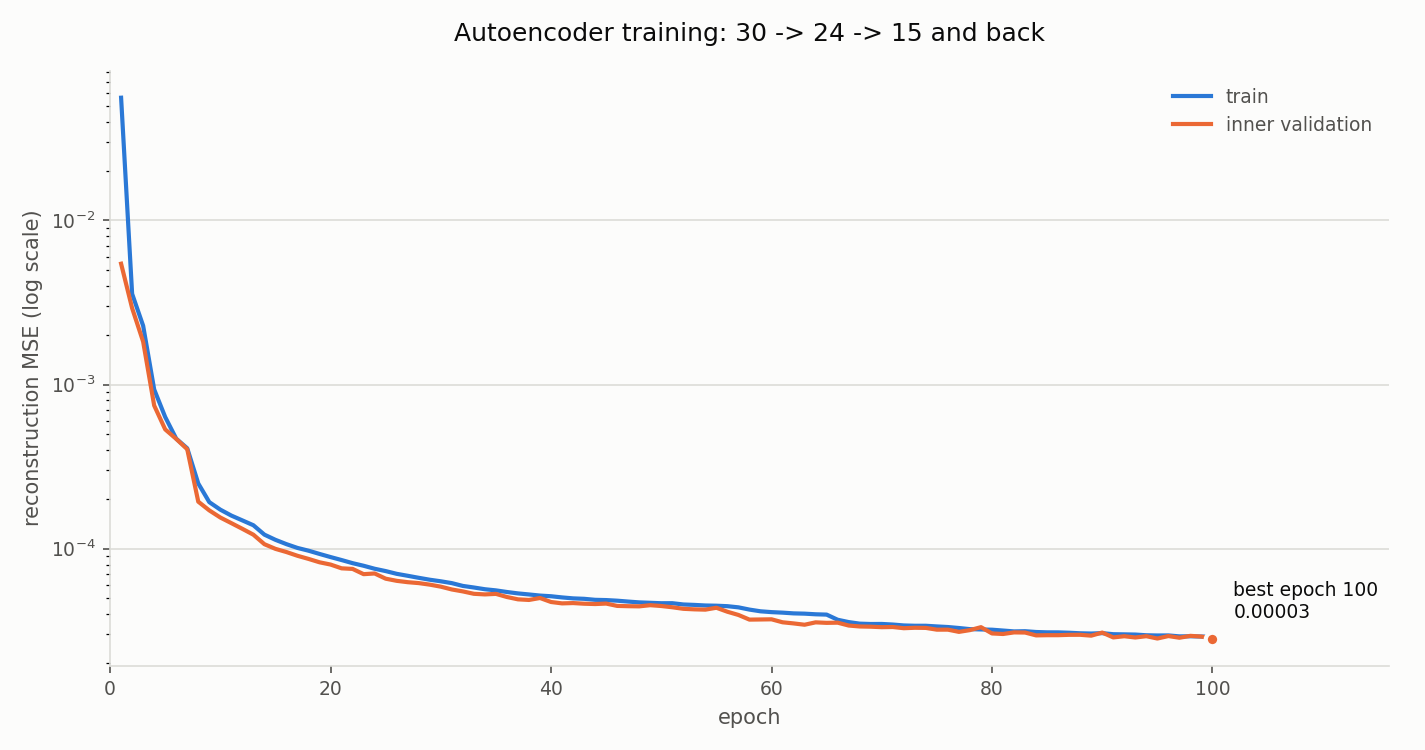

In [45]:
info = step7["info"]
autoencoder.show_table(autoencoder.kv_table([
    ("best epoch", info.get("best_epoch")),
    ("epochs run", info.get("epochs_run")),
    ("train reconstruction MSE", "%.6f" % info["train_mse"]),
    ("validation reconstruction MSE", "%.6f" % info["val_mse"]),
    ("training time", "%.1f s" % info["seconds"] if info.get("seconds") else "-"),
]), note="Early stopping restored the weights from the best epoch, so these are "
         "the weights that were saved - not the last epoch's.")

curve = config.STEP7_OUTPUT_DIR / config.STEP7_FILES["loss_curve"]
if curve.exists() and autoencoder.dl.in_notebook():
    from IPython.display import Image, display
    display(Image(filename=str(curve)))
elif not curve.exists():
    print("No loss curve at", curve)

### Per-feature reconstruction error

Which of the 30 features the 15-number bottleneck could **not** keep. A high
value means that feature is either noisy or carries something none of the others
do - worth knowing before Steps 8-10, because whatever the autoencoder threw
away is not available to any classifier downstream.


In [46]:
table = step7.get("per_feature_mse")
if table is not None:
    autoencoder.show_table(table,
        note="On the inner validation part. Saved as per_feature_mse.csv.")
else:
    print("Not available on the loaded path - set OVERWRITE_STEP7 = True to recompute.")

,rank,feature,mse
0,1,Init Bwd Win Byts,2.165659e-04
1,2,Fwd Header Len,7.847086e-05
2,3,Flow Duration,5.488398e-05
3,4,Idle Min,4.186166e-05
4,5,Bwd IAT Tot,3.965260e-05
5,6,Bwd IAT Max,3.673772e-05
6,7,Pkt Len Mean,3.331499e-05
7,8,Fwd Seg Size Avg,3.232038e-05
8,9,Fwd IAT Tot,3.215135e-05
9,10,Fwd IAT Max,2.999422e-05


_On the inner validation part. Saved as per_feature_mse.csv._

---

## Step 6 - Transform the training and test sets

**Purpose** — Apply the frozen encoder to both the training and the test
features.

**Input** — `C:\MSCAD2022\outputs\step6` (the selected features) and
`C:\MSCAD2022\outputs\step7\encoder.keras`.

**Method** — $Z_{\text{train}} = \text{encoder}(X_{\text{train}})$ and
$Z_{\text{test}} = \text{encoder}(X_{\text{test}})$, producing columns `z01` to
`z15` in the original row order. `encode()` verifies the feature names and their
order before every call.

**Output** — `C:\MSCAD2022\outputs\step8` — `Z_train.csv`, `Z_test.csv`, the
label files copied unchanged, and the reconstruction error for reference.

**Why** — The test features are read here for the first time in Steps 5-6, and
only to pass through an encoder that is already trained. A `Dense` layer reads
column positions rather than names, so a frame with the correct columns in the
wrong order would produce plausible but incorrect codes; the column check makes
that impossible.

The 15 latent columns have no individual interpretation: `z07` is one axis of a
learned compression, not a named feature. Feature-importance statements about the
original features come from the Step 4 ranking, not from the latent columns.

The **same frozen encoder** runs over both sets:

```
    Z_train = encoder(X_train_selected)      Z_test = encoder(X_test_selected)
```

`X_test_selected` is read here for the first time in Steps 5-6, and only to be
pushed through an encoder that is already trained and unchanged. Nothing about
the architecture, the epochs or the early stopping came from it.

**Row order is unchanged**, so row *i* of `Z_train` is still row *i* of
`X_train_selected`, and `y_train` still belongs to it.

> **`encode()` checks the columns before every call.** A `Dense` layer reads
> **positions**, not names - hand it the same 30 columns in a different order and
> it returns numbers that look perfectly reasonable and are wrong. The saved
> encoder therefore ships with the feature order it was trained on, and `encode()`
> refuses any frame that does not match it exactly, naming the first position that
> differs.


In [47]:
step8 = autoencoder.run_step8(
    encoder=step7.get("encoder"),
    autoencoder=step7.get("autoencoder"),
    feature_order=step7.get("feature_order"))

,metric,value
0,status,loaded from disk (OVERWRITE_STEP8 = False)
1,folder,C:\MSCAD2022\outputs_official\step8
2,Z_train,"103,039 rows x 15 columns"
3,Z_test,"25,760 rows x 15 columns"


_Set `OVERWRITE_STEP8 = True` in config.py to encode again._

### The encoded matrices

In [48]:
import pandas as pd

Z_train = step8["Z_train"]
Z_test = step8["Z_test"]
autoencoder.show_table(autoencoder.kv_table([
    ("Z_train", "%s rows x %d columns" % (f"{Z_train.shape[0]:,}", Z_train.shape[1])),
    ("Z_test", "%s rows x %d columns" % (f"{Z_test.shape[0]:,}", Z_test.shape[1])),
    ("columns", "%s ... %s" % (Z_train.columns[0], Z_train.columns[-1])),
    ("compression", "%d features -> %d numbers"
     % (config.N_SELECTED_FEATURES, config.AE_LATENT_DIM)),
]))
autoencoder.show_table(Z_train.head(5), all_columns=True,
                       note="Z_train.head(5). These are the latent codes, not the "
                            "original features - they have no individual meaning.")

if "recon_mse" in step8:
    autoencoder.show_table(step8["recon_mse"],
        note="**Reported only.** No decision in Steps 7-8 was made by looking at "
             "the test error. A test MSE close to the train MSE means the encoder "
             "generalises; a much larger one would mean it had memorised the "
             "training rows.")

,metric,value
0,Z_train,"103,039 rows x 15 columns"
1,Z_test,"25,760 rows x 15 columns"
2,columns,z01 ... z15
3,compression,40 features -> 15 numbers


,z01,z02,z03,z04,z05,z06,z07,z08,z09,z10,z11,z12,z13,z14,z15
0,2.119445,0.568167,0.000000,2.820178,0.0,1.912448,0.495481,0.748794,0.905242,0.791439,0.611293,0.648358,1.422298,2.246254,0.440705
1,2.204919,0.687310,0.000000,3.184160,0.0,1.704946,0.551753,0.987131,1.007296,0.735717,1.363498,0.086746,1.322634,2.557702,0.000000
2,2.226466,0.695178,0.000000,3.230984,0.0,1.702224,0.585589,1.017161,0.915218,0.791503,1.253794,0.154598,1.383684,2.587918,0.000000
3,1.251646,0.349510,0.022729,1.137262,0.0,1.562532,0.912188,0.722721,1.086080,0.945304,0.492029,0.365719,1.516620,1.285717,2.179133
4,2.193745,0.694087,0.000000,3.164294,0.0,1.687881,0.515894,0.977631,0.969159,0.689242,1.354787,0.159003,1.313660,2.557675,0.000000


_Z_train.head(5). These are the latent codes, not the original features - they have no individual meaning._

,set,rows,reconstruction MSE
0,train,103039,0.000029
1,test,25760,0.000073


_**Reported only.** No decision in Steps 7-8 was made by looking at the test error. A test MSE close to the train MSE means the encoder generalises; a much larger one would mean it had memorised the training rows._

### Verification

Re-read from disk: `Z_train` is `(N_train, 15)`, `Z_test` is `(N_test, 15)`, both
carry `z01 ... z15` in the same order, no NaN or inf, and the labels are still
aligned row for row.


In [49]:
if "verification" in step8:
    autoencoder.show_table(step8["verification"])
    print()
    print("ALL CHECKS PASSED:", step8["ok"])
else:
    print("Step 8 was loaded from disk, so there is no fresh verification table.")
    print("Set OVERWRITE_STEP8 = True and re-run to encode and verify again.")

Step 8 was loaded from disk, so there is no fresh verification table.
Set OVERWRITE_STEP8 = True and re-run to encode and verify again.


### Re-using the encoder later

The encoder is saved as a Keras model plus the feature order it expects, so any
later step can load it without touching Step 5:

```python
from src.mscad import autoencoder
encode, model, feature_order = autoencoder.load_encoder()
Z = encode(X)          # raises unless X has exactly those columns, in that order
```


### What Step 7 picks up

1. **Train on `Z_train.csv`** (15 columns) with `y_train.csv`. `Z_test.csv` is
   touched once, at the end, to report a score.
2. **The 15 latent columns have no individual meaning.** `z07` is not a feature
   anyone can name - it is one axis of a learned compression. Feature-importance
   claims about `z` columns do not transfer back to the original 30; use the
   Step 4 ranking for that.
3. **The imbalance is still untouched.** It has been left alone deliberately
   through Steps 3-6. SMOTE, resampling or class weights belong in a later step
   and must be fitted on the **training** side only.
4. **Whatever the autoencoder discarded is gone** for every classifier
   downstream. The per-feature reconstruction table in 5.2 is the record of what
   that was.


---

## Step 7 - Class imbalance handled in the training loss

**Purpose** — Compensate for class imbalance by weighting the training loss, with
no resampling of any kind.

**Input** — `C:\MSCAD2022\outputs\step8` — `Z_train.csv`, `y_train.csv`.

**Method** — A stratified inner split of the training set
(`CLF_VAL_SIZE = 0.10`), then balanced class weights computed from the fit part
only (`IMBALANCE_STRATEGY = "class_weight"`,
`CLASS_WEIGHT_SCHEME = "balanced"`), normalised so that the mean per-sample
weight is 1.

**Output** — `C:\MSCAD2022\outputs\step9` — `Z_fit.csv`, `Z_val.csv`, the
matching label files, `fit_sample_weights.csv` and `class_weights.json`.

**Why** — No SMOTE, no SMOTE-ENN and no over- or undersampling are used. Roughly
half of the rows in this dataset share identical feature values once identifiers
are removed, so interpolating between nearest neighbours would duplicate existing
rows rather than add information. Weighting changes how much a row counts in the
loss and never changes how many rows exist. The weights are applied to the
training loss only: the validation loss is unweighted and the test set is never
reweighted.

Balanced class weight for class $c$, with $n$ samples and $k$ classes:

$$w_c = \frac{n}{k \cdot n_c}$$

Under this definition $n_c \cdot w_c$ is identical for every class, so each class
contributes equally to the loss.

The imbalance has been left alone deliberately since Step 2. This is where it is
addressed - **by class weighting only**.

| | |
|---|---|
| **what it does** | makes a rare class's rows count more in the training loss |
| **what it does not do** | add, remove or duplicate a single row |
| **where it applies** | the training loss, and nowhere else |
| **what it never touches** | the test set |

**No resampling of any kind** - no SMOTE, no SMOTE-ENN, no over- or
undersampling - and `imbalanced-learn` is deliberately not a dependency. That is
not squeamishness about SMOTE in general; it is about this dataset in particular.
Around half of these rows share identical feature values once the identifiers are
gone, because thousands of scan, flood and brute-force flows genuinely look
alike. SMOTE interpolates between nearest neighbours, so *between identical rows
it manufactures exact copies* rather than new information - and the Step 3.3
leakage figure would get worse, not better. Weighting adds no rows at all.

**The test set is never reweighted or resampled.** Weights come from the training
rows alone and apply only to the training loss; the test set is scored exactly as
Step 6 produced it. Rebalancing a test set quietly changes the question: a
macro-F1 on a reweighted test set is not the number a reader will assume it is.
Step 7 fingerprints `Z_test.csv` and `y_test.csv` with SHA-256 before and after,
so "unchanged" is a fact rather than an assumption.

**Step 7 trains nothing.** It produces the fit/validation split and the weights
that Steps 8-10 reuse for every model configuration:

```python
X_fit, y_fit, X_val, y_val, weights, sample_w = imbalance.make_training_sets(
    Z_train, y_train, strategy=config.IMBALANCE_STRATEGY)

model.fit(X_fit, y_fit,
          validation_data=(X_val, y_val),           # UNWEIGHTED on purpose
          class_weight=imbalance.keras_class_weight(weights))
```

The validation loss used for early stopping is deliberately **unweighted**: it
has to measure the model on the data as it really is, not on the distribution the
training loss pretends to see.


### Step 7 settings

In [50]:
from src.mscad import imbalance

imbalance.show_table(imbalance.kv_table([
    ("input folder", str(config.STEP8_OUTPUT_DIR)),
    ("output folder", str(config.STEP9_OUTPUT_DIR)),
    ("IMBALANCE_STRATEGY", config.IMBALANCE_STRATEGY),
    ("CLASS_WEIGHT_SCHEME", config.CLASS_WEIGHT_SCHEME),
    ("CLASS_WEIGHT_MAX", config.CLASS_WEIGHT_MAX),
    ("NORMALISE_WEIGHTS", config.NORMALISE_WEIGHTS),
    ("CLF_VAL_SIZE", config.CLF_VAL_SIZE),
    ("RANDOM_STATE", config.RANDOM_STATE),
    ("OVERWRITE_STEP9", config.OVERWRITE_STEP9),
    ("outputs already exist", imbalance.step9_outputs_exist()),
]), note="`balanced` is sklearn's w_c = n / (k x n_c). `sqrt_balanced` is its "
         "square root -- milder, and worth comparing if training turns out "
         "unstable. `CLASS_WEIGHT_MAX` caps any single weight.")

,metric,value
0,input folder,C:\MSCAD2022\outputs_official\step8
1,output folder,C:\MSCAD2022\outputs_official\step9
2,IMBALANCE_STRATEGY,class_weight
3,CLASS_WEIGHT_SCHEME,balanced
4,CLASS_WEIGHT_MAX,None
5,NORMALISE_WEIGHTS,True
6,CLF_VAL_SIZE,0.1
7,RANDOM_STATE,42
8,OVERWRITE_STEP9,False
9,outputs already exist,True


_`balanced` is sklearn's w_c = n / (k x n_c). `sqrt_balanced` is its square root -- milder, and worth comparing if training turns out unstable. `CLASS_WEIGHT_MAX` caps any single weight._

### Run Step 7

In [51]:
step9 = imbalance.run_step9()

,metric,value
0,status,loaded from disk (OVERWRITE_STEP9 = False)
1,folder,C:\MSCAD2022\outputs_official\step9
2,fit rows,"92,735"
3,validation rows,"10,304"
4,classes weighted,6
5,scheme,balanced


_Set `OVERWRITE_STEP9 = True` in config.py to recompute._

### 7.1 The weights

`effective weight share %` is `(fit rows x weight)` as a percentage of the total.
With **balanced** weights every class should land on the same value - that flat
column *is* what balancing means, and seeing it come out flat is the check that
the weights do what they claim.


In [52]:
table = step9.get("weight_table")
if table is not None:
    imbalance.show_table(table,
        note="`class weight` is what multiplies that class's loss. `share of fit %` "
             "is what the data actually looks like; `effective weight share %` is "
             "what the loss sees.")
else:
    print("Not available on the loaded path - set OVERWRITE_STEP9 = True.")

,label,encoded,fit_rows,weight,effective_weight_share_pct
0,Brute_Force,0,63721,0.242555,16.6667
1,Normal,3,20522,0.753135,16.6667
2,Port_Scan,4,7978,1.937307,16.6667
3,HTTP_DDoS,1,462,33.454185,16.6667
4,ICMP_Flood,2,32,482.994792,16.6667
5,Web_Crwling,5,20,772.791667,16.6667


_`class weight` is what multiplies that class's loss. `share of fit %` is what the data actually looks like; `effective weight share %` is what the loss sees._

### How extreme are these weights?

> **With `balanced` on the real MSCAD training set, the largest and smallest
> weights differ by roughly 1000x or more** - around 88,000 `Brute_Force` rows
> against about 18 training rows for `Normal` and `Web_Crwling`. That is the
> honest consequence of asking every class to count equally, but a weight of
> ~1000 on 18 rows means a handful of examples can dominate a gradient step, and
> training can oscillate or diverge.
>
> If that happens, two milder settings are already wired in and worth comparing
> rather than guessing:
>
> | setting | effect |
> |---|---|
> | `CLASS_WEIGHT_SCHEME = "sqrt_balanced"` | ~1000x becomes ~32x |
> | `CLASS_WEIGHT_MAX = 100.0` | nothing exceeds 100x, the rest unchanged |
>
> **The default stays `"balanced"`.** Change it only on evidence - an unstable
> loss curve in Step 8 - and report which setting produced the numbers you
> quote.


In [53]:
stats = step9.get("stats")
if stats is not None:
    imbalance.show_table(imbalance.kv_table([
        ("largest weight", "%.4f" % stats["max_weight"]),
        ("smallest weight", "%.4f" % stats["min_weight"]),
        ("ratio", "%.1fx" % stats["ratio"]),
        ("effective share, even split", "%.4f %%" % stats["even_share"]),
        ("worst deviation from even", "%.6f pp" % stats["spread_pp"]),
    ]))
    if stats["ratio"] >= 1000:
        print("[NOTE] the weights span %.0fx. Watch the Step 10 loss curve for"
              % stats["ratio"])
        print("       instability; sqrt_balanced or CLASS_WEIGHT_MAX are the"
              " fallbacks.")

### Charts

Both on a log scale, because the counts and the weights each span three orders of
magnitude - and because a log axis makes exact values hard to read, every bar
carries its own number.


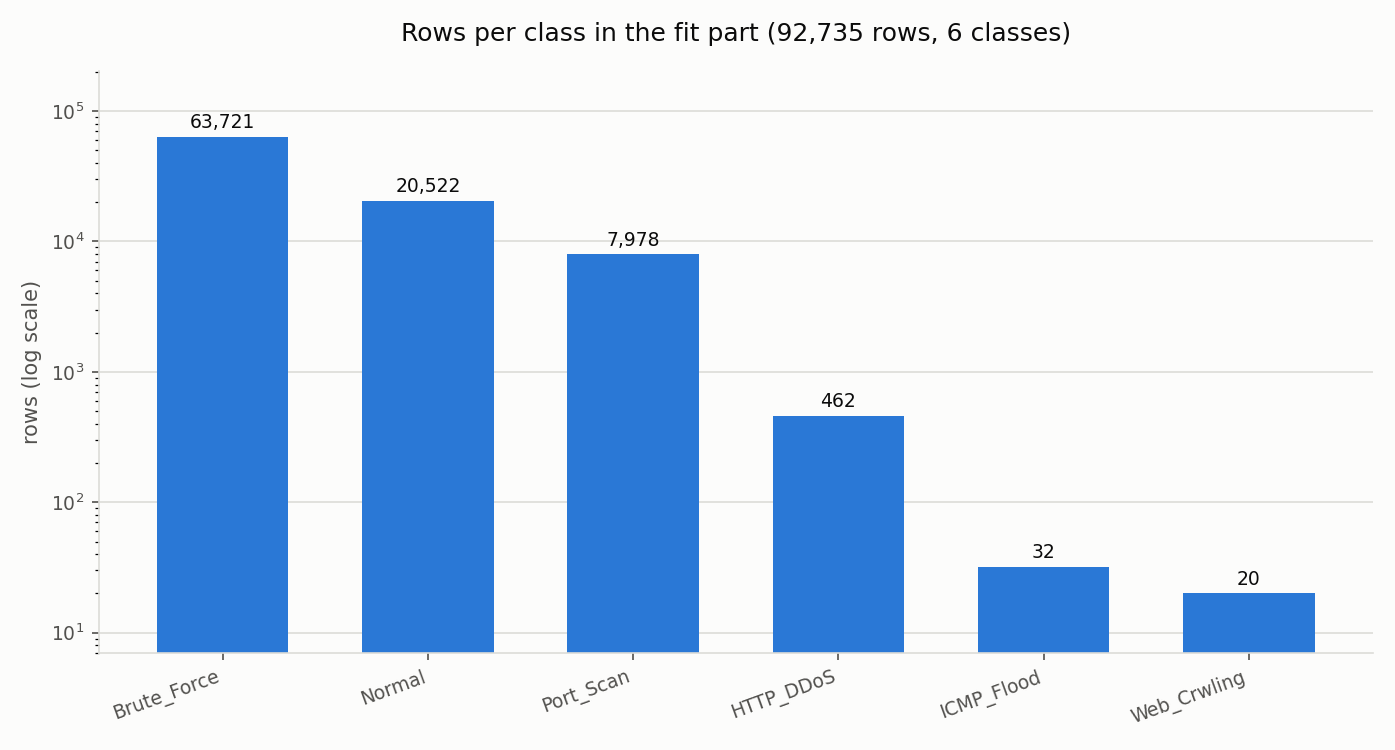

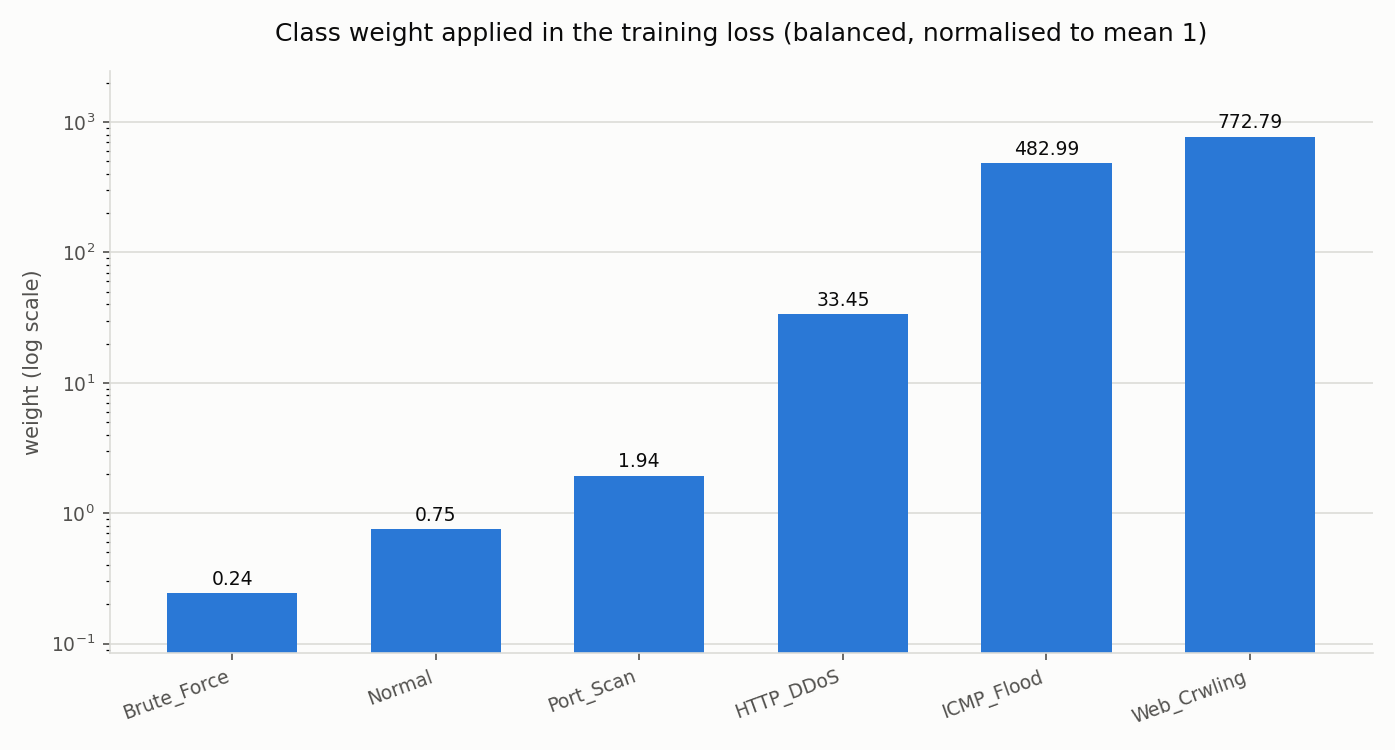

In [54]:
for key in ("fit_counts_chart", "weights_chart"):
    picture = config.STEP9_OUTPUT_DIR / config.STEP9_FILES[key]
    if picture.exists() and imbalance.dl.in_notebook():
        from IPython.display import Image, display
        display(Image(filename=str(picture)))
    elif not picture.exists():
        print("missing:", picture)

### 7.2 Checks

The things that would silently invalidate every later result if they were wrong:
the two parts add up to the training set with nothing added or lost, every class
reaches both parts, the weights came from the fit part alone, and the test files
are byte-for-byte what Step 6 wrote.


In [55]:
if "verification" in step9:
    imbalance.show_table(step9["verification"])
    print()
    print("ALL CHECKS PASSED:", step9["ok"])
else:
    print("Step 9 was loaded from disk, so there is no fresh verification table.")
    print("Set OVERWRITE_STEP9 = True and re-run to recompute and verify.")

Step 9 was loaded from disk, so there is no fresh verification table.
Set OVERWRITE_STEP9 = True and re-run to recompute and verify.


### Saved files

In `C:\MSCAD2022\outputs\step9\`:

| file | what it is |
|---|---|
| `Z_fit.csv` / `y_fit.csv` | what Steps 8-10 train on |
| `Z_val.csv` / `y_val.csv` | the inner validation part, for early stopping - **unweighted** |
| `fit_sample_weights.csv` | one weight per fit row, for a framework that wants per-sample weights |
| `class_weights.json` | per class: label, encoded label, fit rows, weight, plus the scheme, cap and normalisation flag |
| `imbalance_report.csv` | what was done, in order |


In [56]:
import pandas as pd

folder = config.usable_output_dir(config.STEP9_OUTPUT_DIR)
if folder is None:
    print("Step 9 outputs are not readable here:",
          config.why_unusable(config.STEP9_OUTPUT_DIR))
else:
    rows = []
    for key, name in config.STEP9_FILES.items():
        path = folder / name
        rows.append({"file": name, "exists": path.exists(),
                     "size (MB)": round(path.stat().st_size / 1024 / 1024, 3)
                                  if path.exists() else 0.0,
                     "what": key})
    imbalance.show_table(pd.DataFrame(rows), note="Folder: %s" % folder)

    weights = step9["class_weights"]
    print("keras class_weight dict for Steps 10-12:")
    print({k: round(v, 4) for k, v in sorted(weights.items())})

,file,exists,size (MB),what
0,Z_fit.csv,True,12.092,Z_fit
1,y_fit.csv,True,1.390,y_fit
2,Z_val.csv,True,1.343,Z_val
3,y_val.csv,True,0.154,y_val
4,fit_sample_weights.csv,True,2.526,fit_sample_weights
5,class_weights.json,True,0.001,class_weights
6,imbalance_report.csv,True,0.001,report
7,fit_class_counts.png,True,0.053,fit_counts_chart
8,class_weights.png,True,0.055,weights_chart


_Folder: C:\MSCAD2022\outputs_official\step9_

keras class_weight dict for Steps 10-12:
{0: 0.2426, 1: 33.4542, 2: 482.9948, 3: 0.7531, 4: 1.9373, 5: 772.7917}


### What Step 8 picks up

1. **Train on `Z_fit.csv` / `y_fit.csv`** with `class_weight=` from
   `class_weights.json`. Validate on `Z_val.csv` / `y_val.csv`
   **without** weights, and early-stop on validation macro-F1.
2. **The test set stays untouched** until the very end, and is never reweighted.
3. **Report which weighting produced each number.** A macro-F1 under
   `balanced` and one under `none` are different experiments, and the comparison
   between them is itself a result worth having in the thesis.
4. **If the loss oscillates**, try `sqrt_balanced` or `CLASS_WEIGHT_MAX` before
   touching the architecture - a 1000x weight ratio is the more likely culprit.


---

## Step 8 - Hybrid classifiers

**Purpose** — Train the proposed classifier on the latent features.

**Input** — `C:\MSCAD2022\outputs\step8` (the encoded training set) and the
Step 7 split and class weights.

**Method** — `Conv1D(64, k=3)` to `BatchNormalization` to `Conv1D(64)` to
`MaxPooling1D(2)` to `Dropout(0.3)` to `LSTM(64)` to `Dropout(0.3)` to
`Dense(64)` to `Dense(n_classes)`. Adam with `CLF_LR = 0.001`, up to
`CLF_EPOCHS = 50` at `CLF_BATCH_SIZE = 256`, early stopping on
`EARLY_STOP_METRIC = "val_macro_f1"` with `CLF_PATIENCE = 8` and the best weights
restored.

**Output** — `C:\MSCAD2022\outputs\step10` — `cnn_lstm.keras`,
`model_card.json`, the training history and the loss and macro-F1 curves.

**Why** — The output layer emits logits with no activation and the loss applies
the softmax internally, so the softmax is applied exactly once. Early stopping
tracks macro-F1 rather than loss because the loss is dominated by the majority
class, and a model that stops predicting the smallest classes can still reduce
it. The test set is not read during training, early stopping, tuning or
weighting.

> **Input arrangement.** With `INPUT_MODE = "feature_seq"` each flow is arranged
> as a tensor of shape $(15, 1)$: the 15 latent features as 15 steps of one
> channel. The convolutional layers learn patterns across neighbouring latent
> features and the LSTM reads the resulting feature maps as a sequence of learned
> feature patterns. **These are feature maps, not time steps**, and the latent
> units have no natural ordering, so results obtained in this mode are not
> evidence about temporal attack structure. The alternative
> `INPUT_MODE = "time_window"` builds windows of consecutive flows within one
> capture and is the mode required for any temporal claim.

The full proposed pipeline, end to end:

```
66 features -> Step 4 selection -> 30 -> Step 5 autoencoder -> 15 -> CNN-LSTM -> 6 classes
```

Architecture: `Conv1D(64,k3) -> BatchNorm -> Conv1D(64) -> MaxPool(2) -> Dropout
-> LSTM(64) -> Dropout -> Dense(64) -> Dense(n_classes)`.

> ### What the input actually is - read this before quoting a result
>
> `INPUT_MODE = "feature_seq"` lays each flow's 15 autoencoder features out as a
> tensor of shape `(15, 1)`: fifteen "steps" of one channel. The Conv1D layers
> learn local patterns across **neighbouring latent features**, and the LSTM
> reads their output feature map as a sequence of **learned feature patterns**.
>
> **This is not a time sequence, and the model is not doing temporal
> modelling.** Worse, the autoencoder's latent units have *no natural order* -
> which feature lands at position 3 rather than position 11 is an arbitrary
> consequence of how the encoder initialised, so "neighbouring" means nothing in
> particular. The arrangement is fixed and reproducible, because the encoder is
> saved, and this is the architecture the thesis proposes, so it is implemented
> as specified. But a claim that the CNN-LSTM captures temporal attack structure
> needs `INPUT_MODE = "time_window"`, not this one. The same caveat is written
> into `model_card.json`, so it travels with the model.
>
> `INPUT_MODE = "time_window"` builds windows of `WINDOW_SIZE` consecutive flows
> ordered by `Timestamp` **within one capture**, labelled by the last flow, built
> separately on each side of the split so no window ever straddles it. Its own
> caveat: the Step 3 split was random and stratified, so consecutive rows on one
> side were not consecutive in the capture - there are gaps, and a window spans
> more wall-clock time than it appears to.

**Three details that are easy to get wrong**, and how they are handled:

1. **The output layer emits logits**, with no activation, and the loss is
   `SparseCategoricalCrossentropy(from_logits=True)`, which applies the softmax
   internally. Softmax is applied exactly once, in `predict_proba()`. Doing both
   would apply it twice - the gradients would be wrong and the model would train
   badly while still producing plausible-looking probabilities.
2. **The validation loss is unweighted.** Keras applies `class_weight` to
   training batches only, which is what we want: the validation signal has to
   measure the model on the data as it really is.
3. **Early stopping watches macro-F1, not loss.** With a 3849:1 imbalance the
   loss is dominated by the majority class, and a model that quietly stops
   predicting the 23-row classes can still improve it.

The test set is not read anywhere in Step 8 - not for training, early stopping,
tuning or the class weights.


### 8.1 Approach 1: Hybrid CNN-LSTM

The cells below are Approach 1, unchanged: the model, the training run and the
curves this project has reported from the start. Nothing in this section is
re-run or retrained by Approach 2, and its saved outputs in
`C:\MSCAD2022\outputs\step10` are never rewritten.

Approach 2 follows in 8.2 and shares everything here except one block.

### Step 8 settings

In [57]:
from src.mscad import models

models.show_table(models.kv_table([
    ("INPUT_MODE", config.INPUT_MODE),
    ("WINDOW_SIZE (time_window only)", config.WINDOW_SIZE),
    ("CNN filters / kernel / pool", "%s / %d / %d"
     % (config.CNN_FILTERS, config.CNN_KERNEL, config.CNN_POOL)),
    ("LSTM units", config.LSTM_UNITS),
    ("dropout / dense units", "%s / %d" % (config.DROPOUT, config.DENSE_UNITS)),
    ("epochs / batch / lr", "%d / %d / %s"
     % (config.CLF_EPOCHS, config.CLF_BATCH_SIZE, config.CLF_LR)),
    ("early stopping", "%s, patience %d, best weights restored"
     % (config.EARLY_STOP_METRIC, config.CLF_PATIENCE)),
    ("imbalance", "%s / %s (Step 9)"
     % (config.IMBALANCE_STRATEGY, config.CLASS_WEIGHT_SCHEME)),
    ("N_SEEDS", config.N_SEEDS),
    ("OVERWRITE_STEP10 / STEP11", "%s / %s"
     % (config.OVERWRITE_STEP10, config.OVERWRITE_STEP11)),
]), note="`N_SEEDS > 1` retrains with different seeds and reports mean +- std, "
         "which the rare classes need: with ~5 test rows each, one row changing "
         "hands moves a per-class F1 a long way.")

,metric,value
0,INPUT_MODE,feature_seq
1,WINDOW_SIZE (time_window only),10
2,CNN filters / kernel / pool,"[64, 64] / 3 / 2"
3,LSTM units,64
4,dropout / dense units,0.3 / 64
5,epochs / batch / lr,50 / 256 / 0.001
6,early stopping,"val_macro_f1, patience 8, best weights restored"
7,imbalance,class_weight / balanced (Step 9)
8,N_SEEDS,1
9,OVERWRITE_STEP10 / STEP11,False / False


_`N_SEEDS > 1` retrains with different seeds and reports mean +- std, which the rare classes need: with ~5 test rows each, one row changing hands moves a per-class F1 a long way._

### Run Step 8

Training is the slow part. Early stopping usually ends it well before
`CLF_EPOCHS`; the elapsed time and the epoch it stopped at are both reported.


In [58]:
step10 = models.run_step10()

,metric,value
0,status,loaded from disk (OVERWRITE_STEP10 = False)
1,folder,C:\MSCAD2022\outputs_official\step10
2,input mode,feature_seq
3,parameters,"50,438"
4,best epoch,19
5,best validation macro-F1,0.6063
6,training time,354.1 s


_Set `OVERWRITE_STEP10 = True` in config.py to retrain._

### Architecture

In [59]:
models.show_table(step10["architecture"],
    note="The last layer's activation is `linear` -- it emits LOGITS. The loss "
         "applies the softmax; `predict_proba()` is the only other place one is "
         "applied.")

,layer,type,output shape,activation,parameters
0,input,InputLayer,"(None, 15, 1)",-,0
1,conv1,Conv1D,"(None, 15, 64)",relu,256
2,batchnorm,BatchNormalization,"(None, 15, 64)",-,256
3,conv2,Conv1D,"(None, 15, 64)",relu,12352
4,maxpool,MaxPooling1D,"(None, 7, 64)",-,0
5,dropout_cnn,Dropout,"(None, 7, 64)",-,0
6,lstm,LSTM,"(None, 64)",tanh,33024
7,dropout_lstm,Dropout,"(None, 64)",-,0
8,dense,Dense,"(None, 64)",relu,4160
9,logits,Dense,"(None, 6)",linear,390


_The last layer's activation is `linear` -- it emits LOGITS. The loss applies the softmax; `predict_proba()` is the only other place one is applied._

### Training curves

The loss curve carries two series that are deliberately **not** comparable: the
training loss is class-weighted and the validation loss is not. Watch their
shapes, not the gap between them. The macro-F1 curve is the one early stopping
acts on.


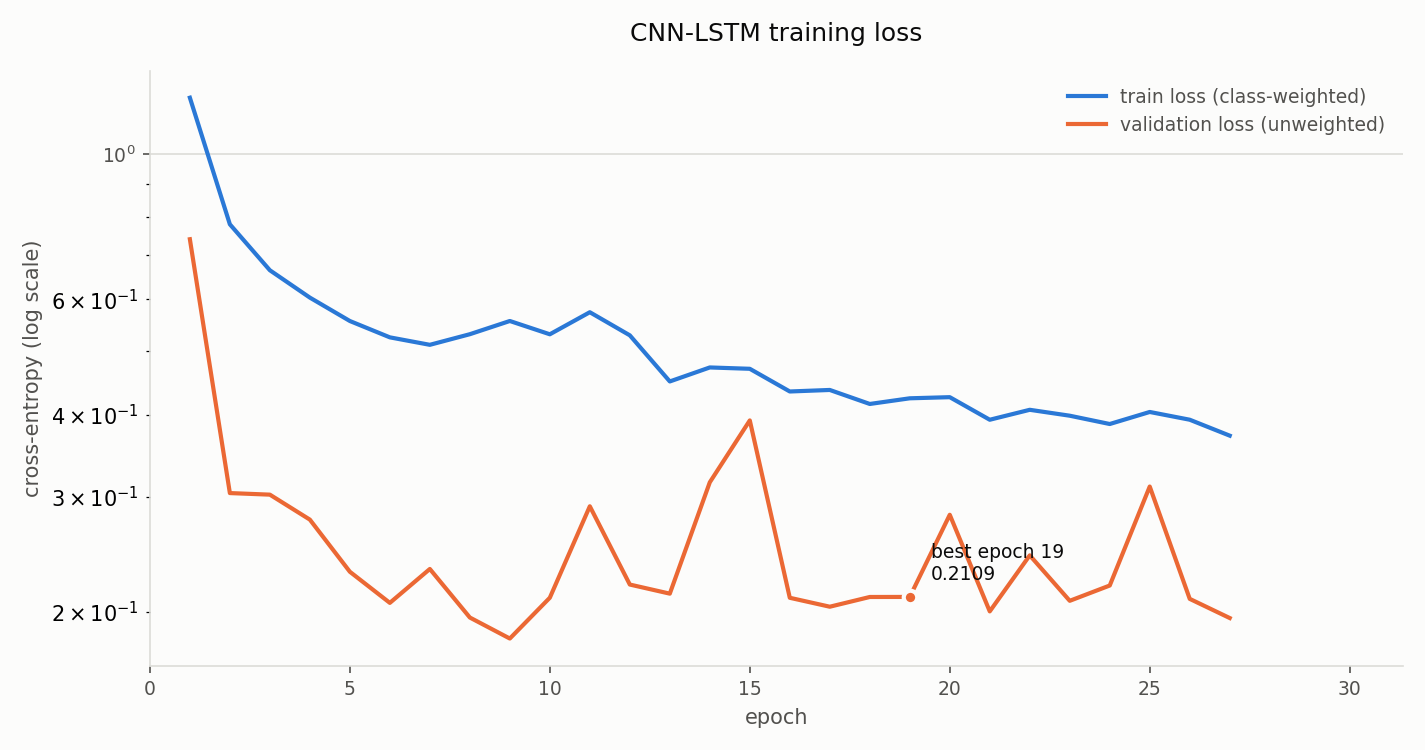

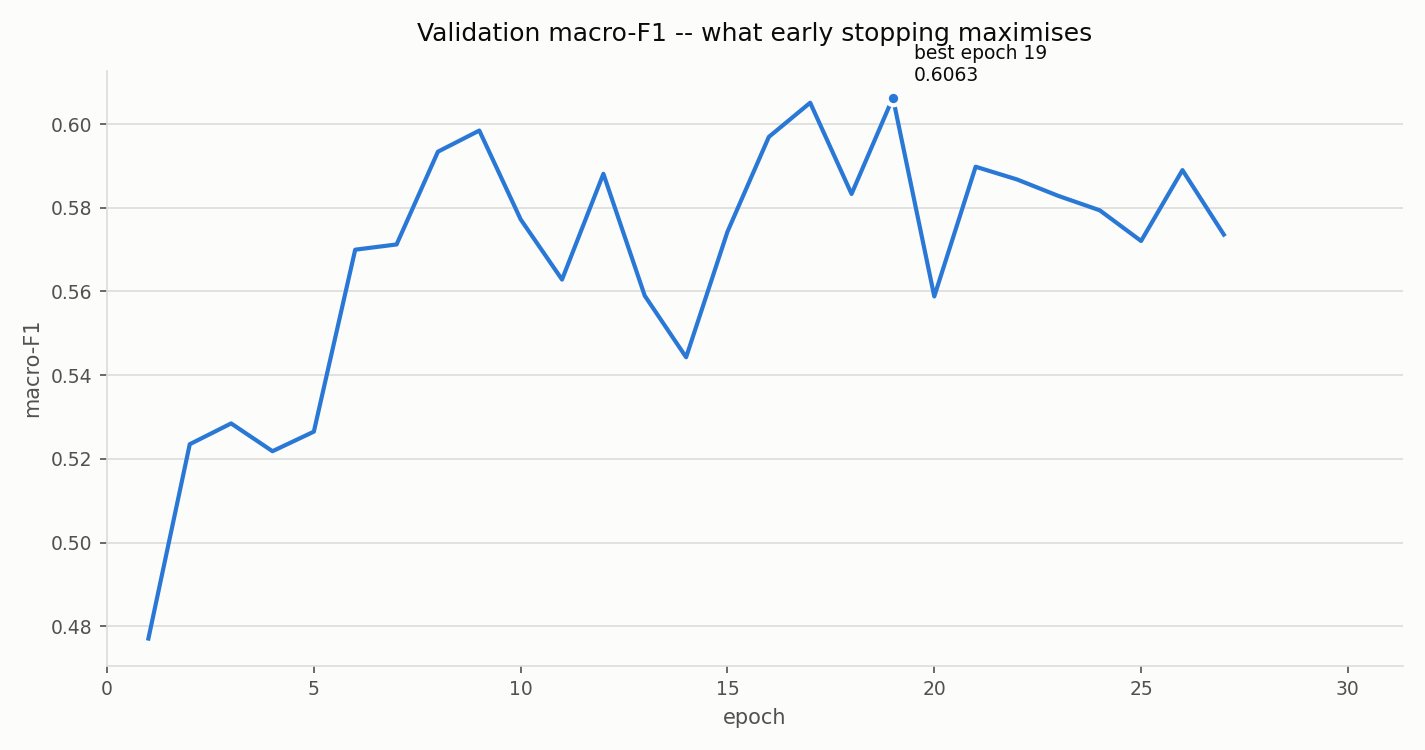

In [60]:
for key in ("loss_curve", "f1_curve"):
    picture = config.STEP10_OUTPUT_DIR / config.STEP10_FILES[key]
    if picture.exists() and models.dl.in_notebook():
        from IPython.display import Image, display
        display(Image(filename=str(picture)))
    elif not picture.exists():
        print("missing:", picture)

---

### 8.2 Approach 2: Hybrid CNN-Attention-LSTM

**Purpose** — Ask whether letting the model weigh parts of the convolved
latent vector, instead of taking the LSTM's last state, buys anything.

**Input** — The same Step 6 matrices Approach 1 used: `Z_train` (15
autoencoder features), with `INPUT_MODE = "feature_seq"`, so each flow is
reshaped to (15, 1).

**Method** — Approach 1's stack with **one** block added:

```
Conv1D(64, 3) -> BatchNorm -> Conv1D(64, 3) -> MaxPool(2) -> Dropout
  -> LSTM(64, return_sequences=True)
  -> additive attention            <- the only difference
  -> Dropout -> Dense(64) -> Dense(n_classes)   [logits]
```

**Output** — `C:\MSCAD2022\outputs\step10_attention` — the model, the
training history, both curves, the architecture table and `model_card.json`.

**Why** — Approach 1's LSTM compresses the whole sequence into its final
state, so an early position can only reach the classifier through everything
that follows it. Attention gives the classifier a direct, weighted path to
every position, and the weights are readable afterwards.

#### The attention, written out

Given the LSTM output sequence $h_1 \dots h_T$:

$$e_t = v^{\top} \tanh\!\left(W h_t + b\right)
\qquad
\alpha_t = \frac{\exp(e_t)}{\sum_{s=1}^{T}\exp(e_s)}
\qquad
c = \sum_{t=1}^{T} \alpha_t\, h_t$$

$W \in \mathbb{R}^{64 \times 64}$ maps each LSTM state into the scoring space
(`ATTN_UNITS`), $v$ scores it, the softmax turns the scores into weights that
are non-negative and sum to one, and $c$ is the weighted summary the dense head
sees. This is additive (Bahdanau-style) attention; it adds about four thousand
parameters to the fifty thousand Approach 1 already has.

| | Approach 1 | Approach 2 |
|---|---|---|
| CNN front end | Conv -> BN -> Conv -> Pool -> Dropout | identical |
| LSTM | 64 units, last state | 64 units, **full sequence** |
| pooling | — | **additive attention** |
| head | Dropout -> Dense(64) -> Dense(C) | identical |
| everything else | — | identical: epochs, batch, lr, patience, seed, class weights, split |

> **What the attention positions are.** With `INPUT_MODE = "feature_seq"` a
> flow is one vector, not a sequence of events, so after the convolutions and
> pooling the model sees about seven **CNN feature-map positions**. The
> attention says which part of the convolved latent vector it leaned on. These
> are **not time steps**, and reading them as "which moment of the attack"
> would be wrong. Temporal attention would need
> `INPUT_MODE = "time_window"`.

> **Same protocol, asserted.** The Step 7 fit/validation split, the class
> weights on the training loss only, the unweighted validation loss, early
> stopping on validation macro-F1 with the best weights restored, and the same
> seed. The checks below compare these against Approach 1's own saved
> `model_card.json` and Step 7's `class_weights.json`.

In [61]:
# Quieten TensorFlow's C++ logger for this section only.
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

from src.mscad import models_attention

step10b = models_attention.run_step10b()

_Approach 2 loaded from **C:\MSCAD2022\outputs_official\step10_attention\cnn_attention_lstm.keras** (54,662 parameters). Not retrained._

---

## Step 9 - Evaluation on the untouched test set

**Purpose** — Measure the trained model on the test set, which has not been used
for any earlier decision.

**Input** — `C:\MSCAD2022\outputs\step8` (`Z_test.csv`, `y_test.csv`),
`C:\MSCAD2022\outputs\step10` (the trained model), and the Step 3 feature
matrices for the duplicate check.

**Method** — Softmax of the model's logits, then accuracy, macro and weighted
precision, recall and F1, G-mean, one-vs-rest ROC-AUC, the per-class report, both
confusion matrices, a benign-versus-attack binary view, and CPU inference timing
measured after a warm-up batch.

**Output** — `C:\MSCAD2022\outputs\step11` — `metrics.json`,
`per_class_report.csv`, `predictions.csv`, the confusion matrices and the
duplicate-free comparison.

**Why** — Every headline metric is reported twice: over all test rows, and over
only those test rows that have no feature-identical row in the training set.
Approximately 54% of this dataset's rows share identical feature values once
identifiers are removed, so a random split places identical rows on both sides
and the full-test score is optimistic. The duplicate-free score is the
conservative estimate of generalisation. The same model and the same predictions
are used for both; only the set of scored rows differs.

Macro-F1 over $k$ classes, and G-mean over per-class recall:

$$\text{macro-F1} = \frac{1}{k}\sum_{c=1}^{k} F1_c, \qquad
\text{G-mean} = \left(\prod_{c=1}^{k} \text{recall}_c\right)^{1/k}$$

G-mean becomes zero if any single class is never recalled, which macro-F1 and
accuracy can both conceal.

> **Rare classes.** The smallest classes contribute only about five test rows
> each. Their per-class precision, recall and F1 change substantially when a
> single row is classified differently, so they should be read as indicative.
> Setting `N_SEEDS` to 3 or 5 reports mean and standard deviation across seeds.

This is the first and only time the test set is used. It was never resampled,
reweighted, or consulted for training, early stopping, tuning or the class
weights.

### Why there are two scores for everything

About half this dataset's rows share identical feature values once the
identifiers are gone. A random split therefore puts feature-identical twins on
both sides, and the model can "recognise" a test row it has effectively already
seen. Every headline metric is reported twice:

| | |
|---|---|
| **full** | every test row |
| **duplicate-free** | only test rows with no feature-identical row in training |

Nothing is retrained and nothing is dropped from the model's input - the same
predictions are simply scored over two row sets. **The duplicate-free number is
the conservative estimate of generalisation, and is the one to lead with.**

### Which metric to quote

Accuracy on this dataset is close to a measure of the majority class alone:
`Brute_Force` is ~84% of the rows, so predicting it for everything scores ~84%.

- **macro-F1** weights every class equally
- **G-mean** is the geometric mean of per-class recall, and goes to **zero** the
  moment any class is never recalled - the strictest of the three, and the one
  that catches a model quietly abandoning a rare class

> **The rare classes have about five test rows each.** Their per-class
> precision, recall and F1 move a long way when a single row changes hands, so
> treat them as indicative, not precise. `N_SEEDS = 3` or `5` and a reported
> mean +- std is the honest way to quote them.


In [62]:
from src.mscad import evaluation

step11 = evaluation.run_step11(
    model=step10.get("model"),
    training_seconds=step10.get("info", {}).get("seconds"))

,metric,value
0,status,loaded from disk (OVERWRITE_STEP11 = False)
1,model,proposed CNN-LSTM
2,test rows,"25,760"
3,macro-F1 (full),0.6134
4,macro-F1 (duplicate-free),0.5868


_Set `OVERWRITE_STEP11 = True` in config.py to re-evaluate._

### Full vs duplicate-free

In [63]:
comparison = step11.get("duplicate_comparison")
if comparison is not None:
    evaluation.show_table(comparison,
        note="Same model, same predictions -- only the row set differs.")
    evaluation.show_table(step11["duplicate_counts"],
        note="Per class: how many test rows, and how many of them have a "
             "feature-identical twin in training. A class with a HIGH duplicated "
             "percentage is one the model may be recognising rather than "
             "generalising to.")
else:
    evaluation.show_table(step11["duplicate_split"],
                          note="Read back from duplicate_free_comparison.csv.")

,metric,full test set,duplicate-free
0,rows,25760.000000,16637.000000
1,accuracy,0.921040,0.898840
2,f1_macro,0.613385,0.586756
3,g_mean,0.836769,0.832310
4,recall_macro,0.847681,0.837733
5,f1_weighted,0.946131,0.931520


_Read back from duplicate_free_comparison.csv._

### Per class

In [64]:
table = step11.get("per_class")
if table is not None:
    evaluation.show_table(table,
        note="`support` is the number of test rows. Where it is small, the other "
             "three columns are high-variance -- read them with that in mind.")

,Label,encoded,precision,recall,f1,support
0,Brute_Force,0,0.986390,0.999040,0.992675,17701
1,Normal,3,0.991671,0.668421,0.798575,5700
2,Port_Scan,4,0.982251,0.949007,0.965343,2216
3,HTTP_DDoS,1,0.801370,0.914062,0.854015,128
4,ICMP_Flood,2,0.033333,0.888889,0.064257,9
5,Web_Crwling,5,0.002734,0.666667,0.005446,6


_`support` is the number of test rows. Where it is small, the other three columns are high-variance -- read them with that in mind._

### Confusion matrix

Rows are the true class and are normalised to 1, so each row shows where that
class's flows actually went. The raw count is in brackets.


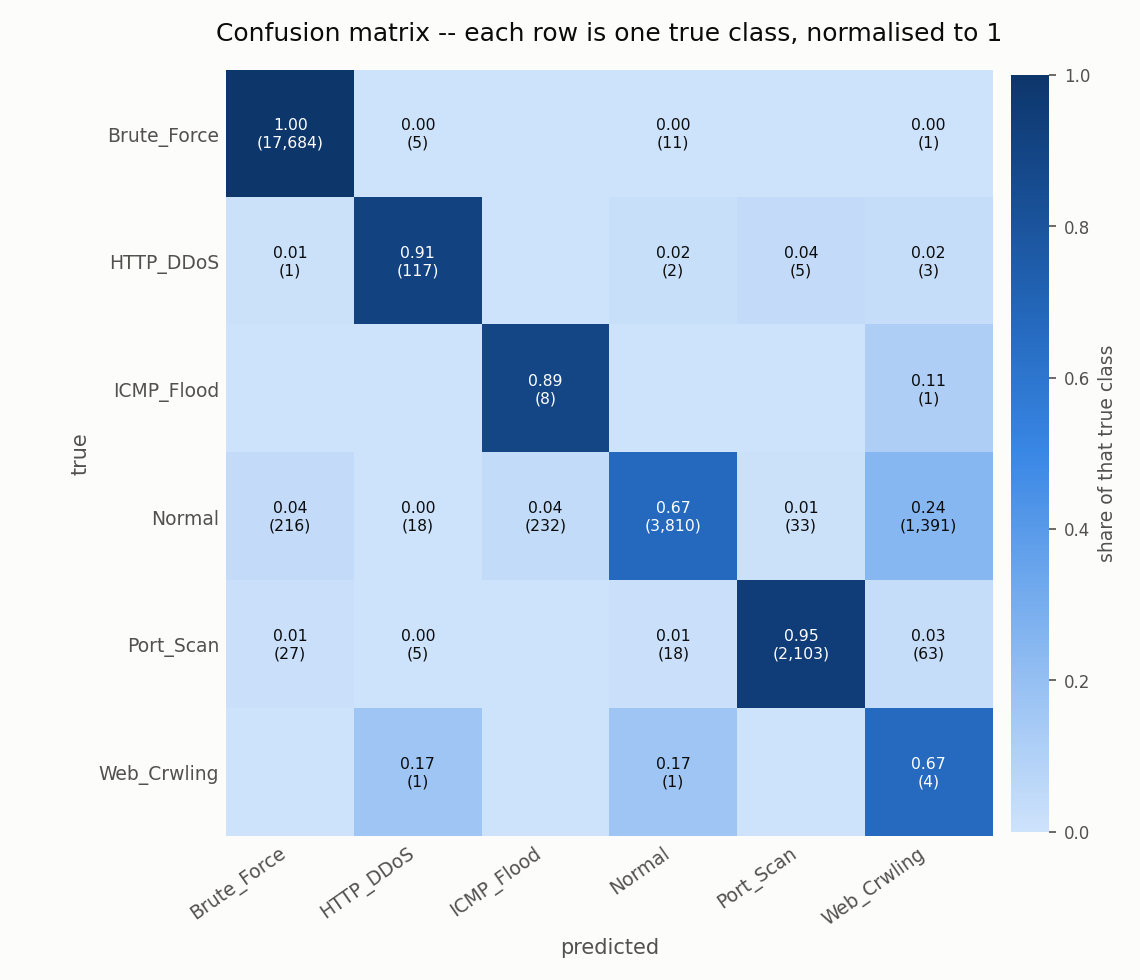

,true \ predicted,Brute_Force,HTTP_DDoS,ICMP_Flood,Normal,Port_Scan,Web_Crwling
0,Brute_Force,17684,5,0,11,0,1
1,HTTP_DDoS,1,117,0,2,5,3
2,ICMP_Flood,0,0,8,0,0,1
3,Normal,216,18,232,3810,33,1391
4,Port_Scan,27,5,0,18,2103,63
5,Web_Crwling,0,1,0,1,0,4


_Raw counts. Rows are truth, columns are predictions._

In [65]:
picture = config.STEP11_OUTPUT_DIR / config.STEP11_FILES["confusion_chart"]
if picture.exists() and evaluation.dl.in_notebook():
    from IPython.display import Image, display
    display(Image(filename=str(picture)))
elif not picture.exists():
    print("missing:", picture)

counts = step11.get("confusion_counts")
if counts is not None:
    evaluation.show_table(counts.reset_index(), all_columns=True,
                          note="Raw counts. Rows are truth, columns are predictions.")

### Binary view - benign vs attack

Derived from the same multiclass probabilities:
`P(attack) = 1 - sum(benign class probabilities)`. The **false-positive rate** is
the operational number here: it is the share of benign flows an analyst would be
paged about.


In [66]:
binary = step11.get("binary")
if isinstance(binary, dict):
    evaluation.show_table(evaluation.kv_table([
        ("accuracy", "%.4f" % binary["accuracy"]),
        ("precision", "%.4f" % binary["precision"]),
        ("recall (attacks caught)", "%.4f" % binary["recall"]),
        ("F1", "%.4f" % binary["f1"]),
        ("ROC-AUC", evaluation._fmt(binary["roc_auc"])),
        ("false-positive rate", "%.4f" % binary["false_positive_rate"]),
        ("TN / FP / FN / TP", "%d / %d / %d / %d"
         % (binary["true_negatives"], binary["false_positives"],
            binary["false_negatives"], binary["true_positives"])),
    ]), note="A benign flow called an attack is a false positive. With very few "
             "benign test rows the FPR is itself a high-variance number.")
elif binary is not None:
    evaluation.show_table(binary)

,rows,benign_classes,accuracy,precision,recall,f1,roc_auc,false_positive_rate,true_negatives,false_positives,false_negatives,true_positives,note
0,25760,[3],0.904076,0.891127,0.998853,0.94192,0.992222,0.429474,3252,2448,23,20037,attack probability = 1 - sum(benign class prob...


### Timing and the G-mean cross-check

In [67]:
timing = step11.get("inference")
if timing is not None:
    evaluation.show_table(evaluation.kv_table([
        ("training time (Step 10)", "%.1f s" % step11["training_seconds"]
         if step11.get("training_seconds") else "-"),
        ("inference rows", f"{timing['rows']:,}"),
        ("inference total", "%.3f s (+- %.3f over %d runs)"
         % (timing["total_seconds"], timing["std_seconds"], timing["runs"])),
        ("per 1,000 flows", "%.1f ms" % timing["ms_per_1000_flows"]),
        ("batch size", timing["batch_size"]),
    ]), note="CPU wall clock, measured after a warm-up batch -- the first call "
             "builds the graph, so timing it would measure compilation.")

check = step11.get("gmean_cross_check")
if check is not None:
    print("G-mean (computed directly): %.6f" % check["ours"])
    if check["imblearn"] is None:
        print(check["note"])
    else:
        print("G-mean (imblearn)         : %.6f" % check["imblearn"])
        print("agree:", check["agree"])

### Saved files

In `C:\MSCAD2022\outputs\step11\`: `metrics.json`, `per_class_report.csv`,
`predictions.csv` (`Orig_Row`, truth, prediction, every class probability and
`has_train_duplicate`), both confusion matrices, `duplicate_free_comparison.csv`,
`binary_view.csv` and `step11_report.csv`.


In [68]:
import pandas as pd

folder = config.usable_output_dir(config.STEP11_OUTPUT_DIR)
if folder is None:
    print("Step 11 outputs are not readable here:",
          config.why_unusable(config.STEP11_OUTPUT_DIR))
else:
    rows = [{"file": name, "exists": (folder / name).exists(),
             "size (MB)": round((folder / name).stat().st_size / 1024 / 1024, 3)
                          if (folder / name).exists() else 0.0}
            for name in config.STEP11_FILES.values()]
    evaluation.show_table(pd.DataFrame(rows), note="Folder: %s" % folder)

    predictions = step11.get("predictions")
    if predictions is not None:
        evaluation.show_table(predictions.head(5), all_columns=True,
                              note="predictions.csv -- one row per test flow.")

,file,exists,size (MB)
0,metrics.json,True,0.003
1,per_class_report.csv,True,0.000
2,predictions.csv,True,2.243
3,confusion_matrix_counts.csv,True,0.000
4,confusion_matrix_rownorm.csv,True,0.000
5,duplicate_free_comparison.csv,True,0.000
6,binary_view.csv,True,0.000
7,step11_report.csv,True,0.000
8,confusion_matrix.png,True,0.093


_Folder: C:\MSCAD2022\outputs_official\step11_

,Orig_Row,y_true,y_pred,y_true_label,y_pred_label,correct,has_train_duplicate,p_Brute_Force,p_HTTP_DDoS,p_ICMP_Flood,p_Normal,p_Port_Scan,p_Web_Crwling
0,2,0,0,Brute_Force,Brute_Force,True,True,0.805043,0.015946,0.000035,0.129441,0.047721,0.001814
1,5,0,0,Brute_Force,Brute_Force,True,False,0.999340,0.000005,0.000000,0.000566,0.000072,0.000016
2,15,0,0,Brute_Force,Brute_Force,True,False,0.999366,0.000005,0.000000,0.000544,0.000069,0.000016
3,18,0,0,Brute_Force,Brute_Force,True,False,0.999380,0.000005,0.000000,0.000531,0.000068,0.000016
4,20,0,0,Brute_Force,Brute_Force,True,False,0.971182,0.002683,0.000011,0.011306,0.014534,0.000284


_predictions.csv -- one row per test flow._

---

### 9.3 Evaluation of Approach 2

**Purpose** — Score Approach 2 on the same untouched test set, with the same
evaluator.

**Input** — The saved Approach 2 model and the Step 6 test matrix.

**Method** — The **unchanged** Step 9 `evaluate()`: the same metrics, the same
duplicate-free subset, the same binary view and the same timing.

**Output** — `C:\MSCAD2022\outputs\step11_attention` — `metrics.json`,
`per_class_report.csv`, both confusion matrices, `predictions.csv`, the
attention tables and `approach_selection.json`.

**Why** — Two models scored by two evaluators cannot be compared. Approach 1's
numbers are read from its saved `step11/metrics.json` and re-checked afterwards
to prove nothing moved.

In [69]:
step11b = models_attention.run_step11b()

_Approach 2's evaluation loaded from disk. Set `OVERWRITE_STEP10B = True` to recompute._

#### 9.3a What the attention looked at

**Purpose** — Report the weights, and say what they can and cannot mean.

**Method** — Mean $\alpha$ per position, overall and per predicted class, plus
the entropy of each flow's weights.

**Why** — The entropy is the honesty check. A uniform distribution over $T$
positions has entropy $\ln T$; if the mean entropy sits at that value the
attention is flat and is telling the reader nothing, however pretty the heatmap
looks. The normalised figure below is $H / \ln T$: close to 1 means flat, close
to 0 means one position carries the decision.

,position,mean_alpha,std_alpha,max_alpha
0,p00,0.062698,0.217524,0.970864
1,p01,0.002822,0.014561,0.725107
2,p02,0.001495,0.012703,0.552737
3,p03,0.049564,0.203178,0.999112
4,p04,0.030216,0.103279,0.999679
5,p05,0.668332,0.431538,0.997186
6,p06,0.184874,0.348954,0.999853


_Mean attention weight per CNN feature-map position across the test set. These are not time steps._

,metric,value
0,mean entropy,0.2259
1,uniform would be,1.9459
2,normalised (H / ln T),0.1161
3,flows,"25,760"


_Close to 1 means the attention is flat and carries no information; close to 0 means one position dominates._

,predicted,flows,p00,p01,p02,p03,p04,p05,p06,entropy
0,Brute_Force,17894,6.115940e-03,3.354900e-04,0.000034,0.000103,0.011161,0.945361,0.036889,0.210179
1,HTTP_DDoS,148,6.164400e-04,2.522000e-05,0.000011,0.000610,0.009727,0.362211,0.626800,0.232880
2,ICMP_Flood,205,4.283600e-04,1.428560e-03,0.012927,0.312778,0.662881,0.004214,0.005343,0.715753
3,Normal,3785,1.445472e-01,9.728090e-03,0.008542,0.307210,0.052808,0.040650,0.436515,0.245115
4,Port_Scan,2125,7.000000e-07,9.500000e-07,0.000051,0.000324,0.000453,0.001701,0.997470,0.011858
5,Web_Crwling,1603,5.978650e-01,1.844042e-02,0.001748,0.029465,0.150011,0.054897,0.147573,0.575829


_Mean attention per position, split by the class the model predicted._

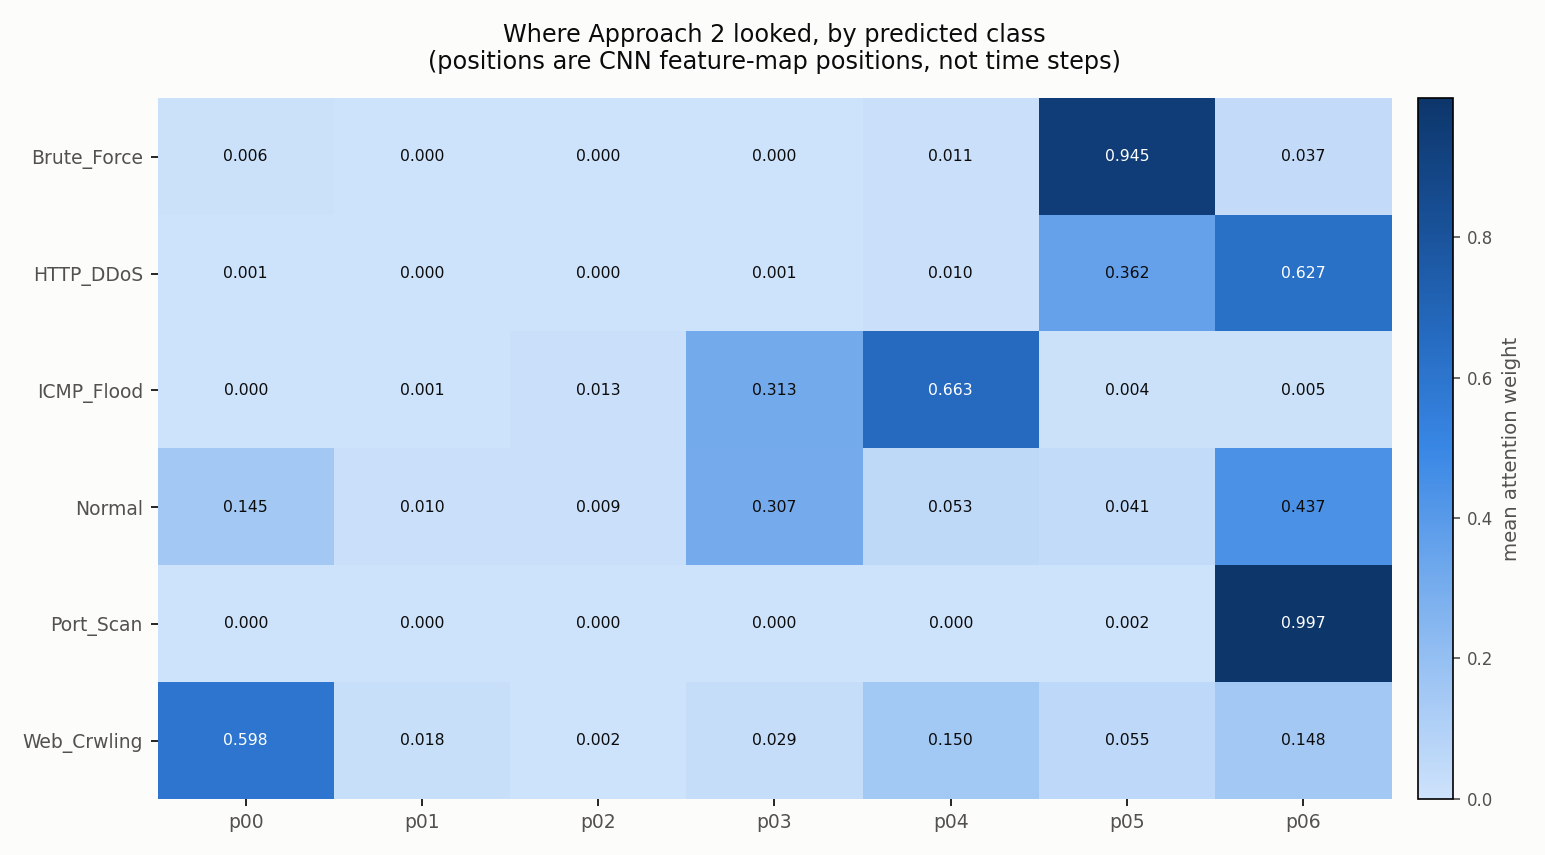

In [70]:
overall = step11b.get("attention")
if overall is not None and len(overall):
    models_attention.show_table(overall, all_columns=True,
        note="Mean attention weight per CNN feature-map position across the "
             "test set. These are not time steps.")
    entropy = (step11b.get("metrics") or {}).get("attention", {}).get("entropy")
    if entropy:
        models_attention.show_table(models_attention.kv_table([
            ("mean entropy", "%.4f" % entropy["mean"]),
            ("uniform would be", "%.4f" % entropy["uniform_would_be"]),
            ("normalised (H / ln T)", "%.4f" % entropy["normalised_mean"]),
            ("flows", "%s" % f"{entropy['flows']:,}"),
        ]), note="Close to 1 means the attention is flat and carries no "
                 "information; close to 0 means one position dominates.")

per_class = step11b.get("attention_per_class")
if per_class is not None and len(per_class):
    models_attention.show_table(per_class, all_columns=True,
        note="Mean attention per position, split by the class the model "
             "predicted.")

picture = config.STEP11B_OUTPUT_DIR / config.STEP11B_FILES["chart_attention"]
if picture.exists() and models_attention.dl.in_notebook():
    from IPython.display import Image, display
    display(Image(filename=str(picture)))
elif not picture.exists():
    print("missing:", picture)

### 9.4 Approach 1 against Approach 2

**Purpose** — Put the two proposed approaches side by side, and pick the
primary one without touching the test set.

**Input** — Approach 1's saved `step11/metrics.json` and Approach 2's.

**Method** — Metric by metric (full and duplicate-free), per-class F1
difference, and the two confusion matrices.

**Output** — `approach1_vs_approach2.csv`, the per-class difference and
`approach_selection.json`.

**Why** — **The primary model is chosen on validation macro-F1 alone.** Both
approaches are reported on the test set, but choosing between them on that
score would be selection on the test set, which is the cheapest way to turn an
honest comparison into an inflated one.

If Approach 2 does not win, this section says so. A negative result here is a
result: it says the attention block did not buy anything on this data, which is
worth more to a reader than a quiet omission.

,scope,metric,Approach 1,Approach 2,difference (A2 - A1),favours
0,full test set,accuracy,0.921040,0.917469,-0.003571,Approach 1
1,full test set,precision_macro,0.632958,0.631598,-0.001360,Approach 1
2,full test set,recall_macro,0.847681,0.844393,-0.003288,Approach 1
3,full test set,f1_macro,0.613385,0.611802,-0.001583,Approach 1
4,full test set,f1_weighted,0.946131,0.943922,-0.002209,Approach 1
5,full test set,g_mean,0.836769,0.832991,-0.003778,Approach 1
6,duplicate-free subset,accuracy,0.898840,0.896796,-0.002044,Approach 1
7,duplicate-free subset,precision_macro,0.612534,0.611512,-0.001023,Approach 1
8,duplicate-free subset,recall_macro,0.837733,0.832701,-0.005032,Approach 1
9,duplicate-free subset,f1_macro,0.586756,0.584200,-0.002556,Approach 1


_`difference (A2 - A1)` is positive where Approach 2 scores higher; `favours` accounts for direction (lower is better for the FPR)._

,Label,test rows,Approach 1,Approach 2,difference (A2 - A1)
0,Brute_Force,17701,0.992675,0.993623,0.000948
1,Normal,5700,0.798575,0.786716,-0.011859
2,Port_Scan,2216,0.965343,0.962912,-0.002431
3,HTTP_DDoS,128,0.854015,0.847826,-0.006189
4,ICMP_Flood,9,0.064257,0.074766,0.010509
5,Web_Crwling,6,0.005446,0.004972,-0.000474


_Per-class F1, Approach 2 minus Approach 1, ordered by support. The rare classes move most on a single flow._

,metric,value
0,primary approach,Approach 2
1,chosen on,validation macro-F1 only (the Step 9 validatio...
2,Approach 1 validation macro-F1,0.6063
3,Approach 2 validation macro-F1,0.6073
4,reason,higher validation macro-F1 by +0.0010
5,test set used,False


_Steps 13 and 14 use Approach 1 whatever this says: FUSION_MODELS is unchanged, so those sections stay reproducible. Swapping the primary model into the fusion would mean re-running Steps 13 and 14 and republishing every number in them._

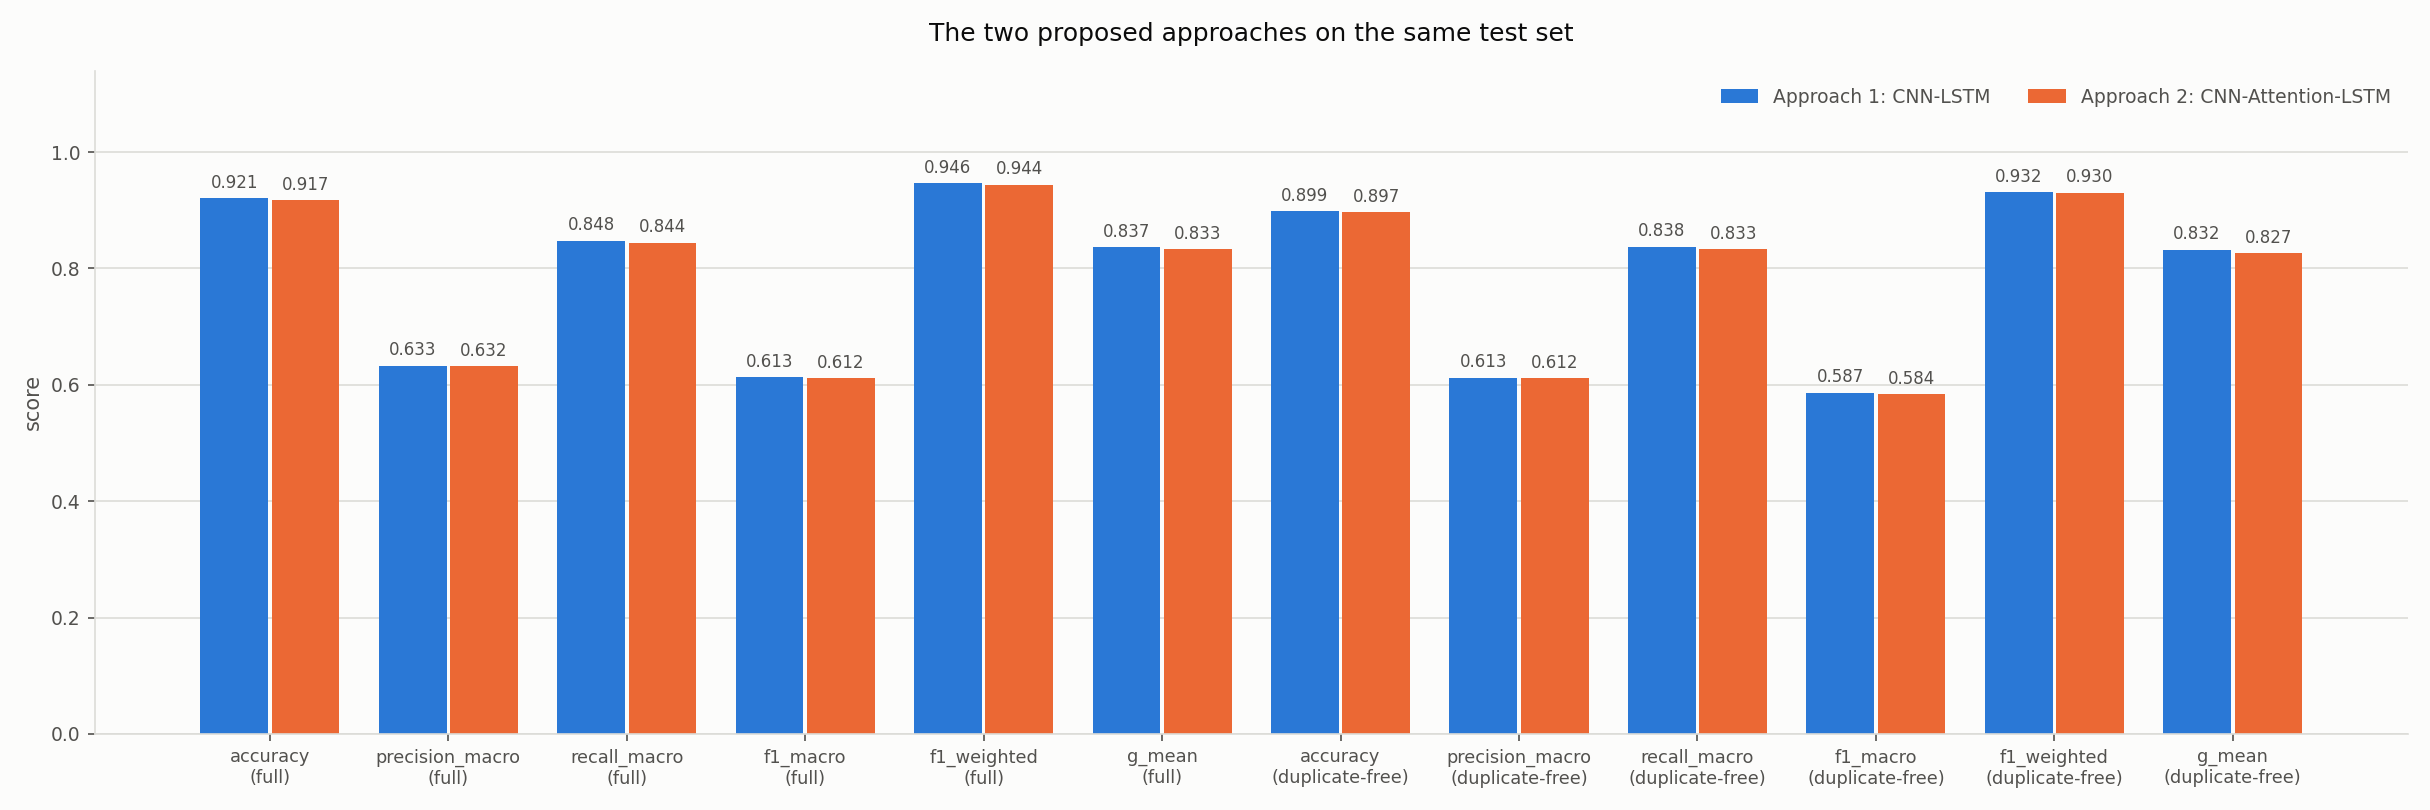

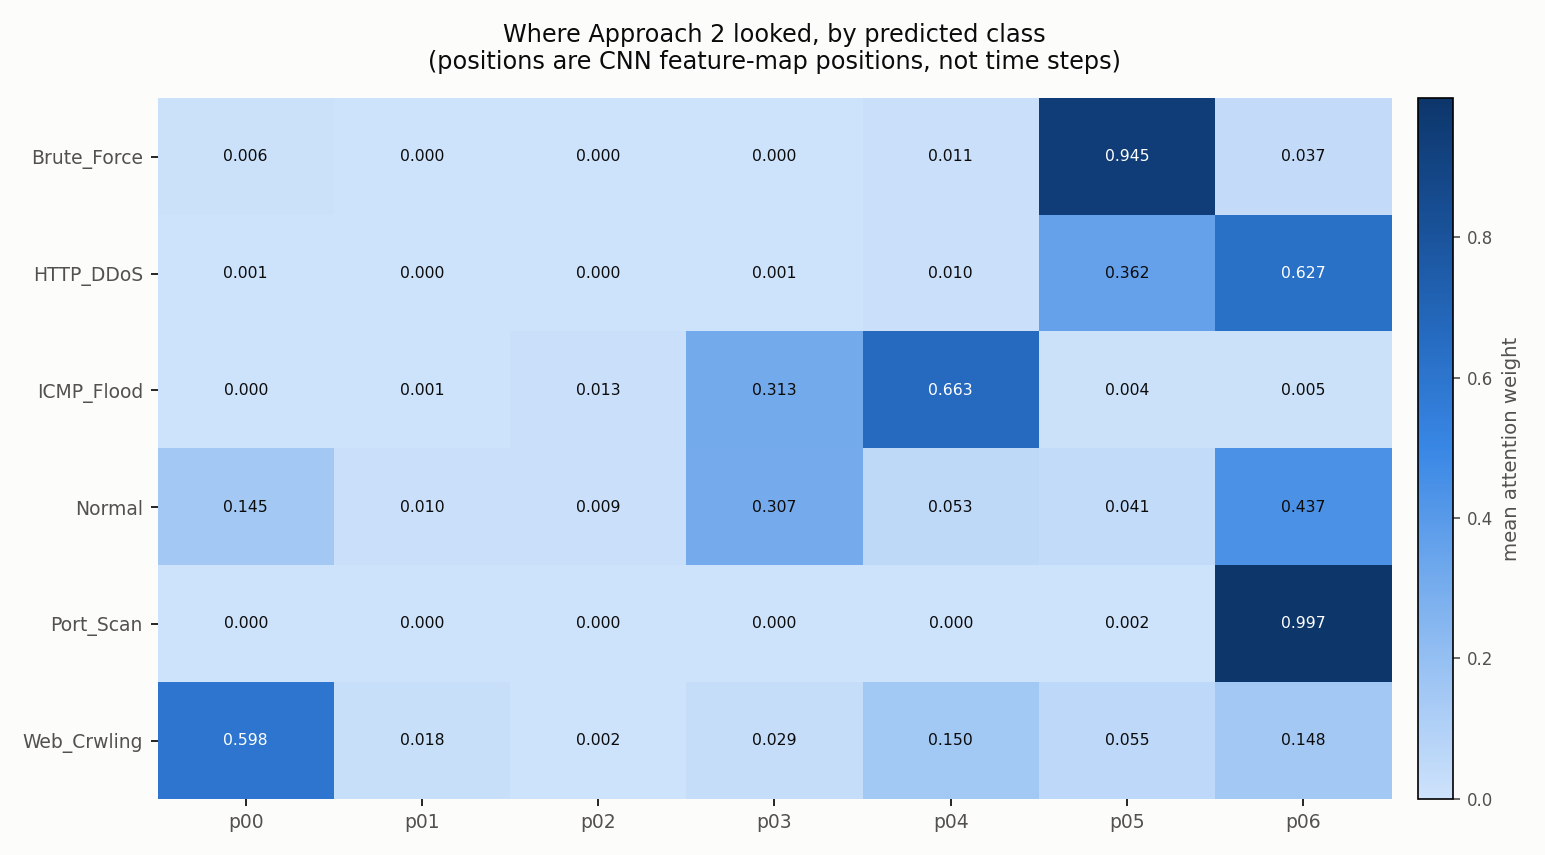

,check,result,detail
0,Approach 1's saved metrics are unchanged,[OK],max difference 0.0e+00
1,the attention weights are a distribution,[OK],"25760 flows x 7 positions, max |sum - 1| = 4.4..."
2,"the test set was used once, for scoring only",[OK],the primary approach is chosen on validation m...


_Approach 1's saved metrics are re-read after Approach 2 runs and must be identical to 1e-9._

In [71]:
comparison_frame = step11b.get("comparison")
if comparison_frame is not None and len(comparison_frame):
    models_attention.show_table(comparison_frame, all_columns=True,
        note="`difference (A2 - A1)` is positive where Approach 2 scores "
             "higher; `favours` accounts for direction (lower is better for "
             "the FPR).")

difference = step11b.get("per_class_diff")
if difference is not None and len(difference):
    models_attention.show_table(difference, all_columns=True,
        note="Per-class F1, Approach 2 minus Approach 1, ordered by support. "
             "The rare classes move most on a single flow.")

selection = step11b.get("selection")
if selection:
    models_attention.show_table(models_attention.kv_table([
        ("primary approach", selection["primary"]),
        ("chosen on", selection["chosen_on"]),
        ("Approach 1 validation macro-F1",
         "n/a" if selection["approach1_validation_macro_f1"] is None
         else "%.4f" % selection["approach1_validation_macro_f1"]),
        ("Approach 2 validation macro-F1",
         "%.4f" % selection["approach2_validation_macro_f1"]),
        ("reason", selection["reason"]),
        ("test set used", selection["test_set_used"]),
    ]), note=selection.get("note", ""))

for key in ("chart_comparison", "chart_attention"):
    picture = config.STEP11B_OUTPUT_DIR / config.STEP11B_FILES[key]
    if picture.exists() and models_attention.dl.in_notebook():
        from IPython.display import Image, display
        display(Image(filename=str(picture)))

report = step11b.get("report")
if report is not None and len(report):
    models_attention.show_table(report, all_columns=True,
        note="Approach 1's saved metrics are re-read after Approach 2 runs and "
             "must be identical to 1e-9.")

### What Step 10 picks up

Step 10 compares baselines against this model. Three things keep that comparison
honest:

1. **Call the same functions.** `models.build_cnn_lstm` / `models.train_model`
   and `evaluation.evaluate` are reusable on purpose, so a difference between two
   rows of the results table is a difference between architectures, not between
   measurement harnesses.
2. **Use the same split, the same weights and the same seed.** They all come
   from Steps 3 and 7 and are already on disk.
3. **Quote both scores for every model**, full and duplicate-free, and lead with
   macro-F1 and G-mean rather than accuracy. A baseline that wins on accuracy and
   loses on G-mean has not won.


### Part 1 summary -- the official dataset, Steps 1 to 9

**Purpose** — One block a supervisor can read without opening nine folders:
what Step 1 found in the authors' file, which 30 features Step 4 selected, the
Step 7 rare-class warning, and what Approach 1 and Approach 2 scored in Step 9
— next to the quick random-forest check the dataset switch was decided on.

**Method** — Every number is **read from the saved files** in this run's output
root: Step 1's `official_manifest.json`, Step 4's selected-feature list, Step
7's `y_val.csv` (counted per class) and Step 9's `metrics.json` and
`per_class_report.csv`. Nothing is recomputed here, and a file that is not there
is reported as *not available* rather than filled in — so this block can never
be ahead of the run.

In [72]:
part1 = official.part1_summary(verbose=False)
if data_loading.in_notebook() and Markdown is not None:
    display(Markdown(part1["text"]))
else:
    print(part1["text"])

folder = config.usable_output_dir(config.STEP11_OUTPUT_DIR)
if folder is not None:
    (folder / "part1_summary.md").write_text(part1["text"], encoding="utf-8")
    print("saved:", folder / "part1_summary.md")

## Summary -- the official MSCAD dataset, Steps 1 to 9

Dataset source: **official**; output root `C:\MSCAD2022\outputs_official`.

### Step 1 -- the file as published

- **128,799 rows x 67 columns**, 66 feature columns after the identifiers were separated.
- Classes (6): Brute_Force, HTTP_DDoS, ICMP_Flood, Normal, Port_Scan, Web_Crwling.
- Benign set for `Label_binary`: **Normal**.
- Identifiers found and moved to metadata: **none**.
- Identifiers unavailable: **Flow ID, Src IP, Dst IP, Src Port, Dst Port, Timestamp** -- the parts of later steps that need them are skipped with a note.
- Duplicate feature vectors: **48,135 rows (37.4%)**.
- **Label conflicts: 16 rows in 4 feature vectors** carry more than one label. No model that sees only these features can classify all of them correctly, so this bounds every number below.

### Step 4 -- the selected features

**30 features** (MI + Pearson + permutation importance, training rows only):

`Init Bwd Win Byts`, `Bwd Header Len`, `Fwd Pkts/s`, `Flow Duration`, `Flow IAT Max`, `Bwd Pkts/s`, `Flow Pkts/s`, `Flow IAT Mean`, `Fwd Header Len`, `Pkt Len Max`, `Pkt Len Mean`, `TotLen Bwd Pkts`, `Fwd Pkt Len Max`, `Fwd Seg Size Avg`, `Bwd IAT Tot`, `Fwd IAT Max`, `Bwd IAT Max`, `Flow Byts/s`, `Fwd IAT Tot`, `Fwd IAT Mean`, `Bwd IAT Mean`, `Down/Up Ratio`, `Flow IAT Std`, `Bwd IAT Min`, `Fwd IAT Std`, `Fwd Pkt Len Std`, `Bwd Pkt Len Min`, `Bwd IAT Std`, `Idle Min`, `SYN Flag Cnt`

### Step 7 -- rare classes in the validation part

Validation rows per class: Brute_Force 7080, Normal 2280, Port_Scan 887, HTTP_DDoS 51, ICMP_Flood 4, Web_Crwling 2.

**RARE-CLASS WARNING -- 2 class(es) below 5 validation rows:** Web_Crwling (2), ICMP_Flood (4). Early stopping monitors the validation macro-F1, so for these classes the signal it follows -- and the per-class reliability the Step 13 fusion will weight a model by -- is estimated from very few flows. Their per-class figures are indicative, and they move the macro average as much as the common classes do.

### Step 9 -- Approach 1 and Approach 2 on the untouched test set

- **Approach 1 (CNN-LSTM):** accuracy 0.9210, macro-F1 0.6134, G-mean 0.8368, binary FPR 0.4295, duplicate-free macro-F1 0.5868.
  - recall HTTP_DDoS: **0.9141**
  - recall ICMP_Flood: **0.8889**
  - recall Web_Crwling: **0.6667**
- **Approach 2 (CNN-Attention-LSTM):** accuracy 0.9175, macro-F1 0.6118, G-mean 0.8330, binary FPR 0.4693, duplicate-free macro-F1 0.5842.
  - recall HTTP_DDoS: **0.9141**
  - recall ICMP_Flood: **0.8889**
  - recall Web_Crwling: **0.6667**

Against the quick stratified 80/20 check (seed 42) the switch was decided on: a random forest reached **macro-F1 0.8542**, a depth-3 tree 0.5457 macro-F1, and the majority class 0.6872 accuracy. Those are not deep models and they see the raw features rather than the autoencoder latents, so they are a REFERENCE for what the dataset supports, not a competitor.

saved: C:\MSCAD2022\outputs_official\step11\part1_summary.md


---

## Step 10 - Model comparison

**Purpose** — Compare the two proposed approaches with six baselines, each
removing or replacing exactly one component, and make every number traceable to
the saved file it came from.

**How this step is organised** — Step 10 is **eight separate files**, one per
configuration, in `src/mscad/experiments_step12/`. Each section below runs
exactly one of them, and each file is also runnable on its own:

```
python -m src.mscad.experiments_step12.approach1
python -m src.mscad.experiments_step12.baseline6
```

Every file is a **thin wrapper**: it imports and calls the code that already
trains and scores its configuration (`models.py`/`evaluation.py` for Approach 1,
`models_attention.py` for Approach 2, `experiments.py` for B1-B3,
`experiments_pca.py` for B4, `experiments_baseline5.py` for B5,
`experiments_baseline6.py` for B6). No model, training loop or metric is
implemented twice.

**What trains here** — Only **Baseline 6** (10.8), and only if it has no saved
result. Approach 1, Approach 2 and B1-B5 are finished: their files **load** the
saved `metrics.json`. While `LOCK_TRAINED_MODELS = True` a configuration that
already has a result is never retrained — it reports `loaded (locked)` — and one
whose result is *missing* **stops** with the file name instead of training
silently.

**Output** — `C:\MSCAD2022\outputs\step12\`: a `manifest.json` per
configuration (paths, SHA-256, metrics), the comparison tables, the figures as
PNG (300 dpi) and PDF, and `thesis\` with every table as CSV and LaTeX.
Baseline 6's model and curves go to its own folder. **Nothing a finished run
owns is written to.**

### 10.0 Provenance and lock status

**Purpose** — Say which saved file every published number comes from, and say
what the lock would do to each configuration, **before** anything runs.

**Method** — Fingerprint each configuration's model, `metrics.json` and
`predictions.csv` (path, size, modified time, SHA-256), then answer three
questions from the files themselves: **(a)** did Steps 11 and 11.8 fuse the
predictions these models hold *today* — each model's attack risk $r_m$ is
recomputed from its current `predictions.csv` and compared per `Orig_Row`;
**(b)** does Approach 1's Step 9 `metrics.json` agree with its Step 10 row and
with any `outputs_backup*` folder — reported side by side, with **nothing
chosen**; **(c)** was any model file written *after* the metrics that describe
it, which is the signature of a silent retrain.

This section also records every finished configuration's saved metrics, which
10.14 compares against the files afterwards at 1e-9.

**Read the report this section writes before any table below.** A `[FAIL]` here
is not repaired automatically: the row says what differs and what the decision
is.

In [73]:
# Step 12 runs on its own after a kernel restart: this cell sets up the import
# path and imports everything the Step 12 sections use.
import sys
from pathlib import Path

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "config.py").exists() and (
        PROJECT_DIR.parent / "config.py").exists():
    PROJECT_DIR = PROJECT_DIR.parent          # started from notebooks\
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import numpy as np
import pandas as pd

import config
from src.mscad import comparison
from src.mscad import step12_checks as checks12
from src.mscad import experiments_step12 as step12_files
from src.mscad.experiments_step12 import common, report
from src.mscad.experiments_step12 import (approach1, approach2, baseline1,
                                          baseline2, baseline3, baseline4,
                                          baseline5, baseline6)

try:                                           # only inside Jupyter
    from IPython.display import Markdown, display
except ImportError:                            # pragma: no cover
    Markdown = None

    def display(*_args, **_kwargs):
        pass

print("Step 12 as %d configuration files: %s"
      % (len(step12_files.CONFIG_MODULES),
         ", ".join(step12_files.CONFIG_MODULES)))
print("LOCK_TRAINED_MODELS = %s" % config.LOCK_TRAINED_MODELS)

Step 12 as 8 configuration files: approach1, approach2, baseline1, baseline2, baseline3, baseline4, baseline5, baseline6
LOCK_TRAINED_MODELS = True


In [74]:
provenance = report.provenance_section()
saved_before = provenance["snapshot"]

#### 12.0 -- provenance: which saved file is each number from?

,model,file,exists,size (bytes),modified,sha256
0,Approach 1: FS -> AE -> CNN-LSTM,model,True,656730,2026-10-24 08:47:19 UTC,04f0822d850d3d41
1,Approach 1: FS -> AE -> CNN-LSTM,metrics,True,2968,2026-10-24 08:53:04 UTC,3bf55949dca06a36
2,Approach 1: FS -> AE -> CNN-LSTM,predictions,True,2351551,2026-10-24 08:53:04 UTC,41d122d2effa1ec7
3,Approach 2: FS -> AE -> CNN-Attention-LSTM,model,True,712623,2026-10-24 08:52:50 UTC,a52729868a20027e
4,Approach 2: FS -> AE -> CNN-Attention-LSTM,metrics,True,3412,2026-10-24 08:53:21 UTC,8973be4598aaeb44
5,Approach 2: FS -> AE -> CNN-Attention-LSTM,predictions,True,2412475,2026-10-24 08:53:22 UTC,adf9a5c7a49ac16f
6,B1: AE -> CNN-LSTM (no selection),model,True,656730,2026-10-24 11:06:50 UTC,32817236f85c8c14
7,B1: AE -> CNN-LSTM (no selection),metrics,True,2635,2026-10-24 11:06:50 UTC,49a47a63477dd317
8,B1: AE -> CNN-LSTM (no selection),predictions,True,2416993,2026-10-24 11:06:50 UTC,bb614a0d3831a05f
9,B2: AE -> LSTM (no CNN),model,True,289992,2026-10-24 11:15:56 UTC,0fc4505b5307152c


_Every published number comes from one of these files. The SHA-256 is truncated here; the full digest is in provenance.csv._

,fusion,model,compared rows,max |r difference|,class disagreements,result,detail
0,step13,Approach 1: FS -> AE -> CNN-LSTM,25760,5.300000e-07,0,[OK],the fused file and predictions.csv agree
1,step13,B2: AE -> LSTM (no CNN),25760,5.300000e-07,0,[OK],the fused file and predictions.csv agree
2,step13,B3: CNN-LSTM (no AE),25760,5.300000e-07,0,[OK],the fused file and predictions.csv agree
3,step13_all,Approach 1: FS -> AE -> CNN-LSTM,25760,5.300000e-07,0,[OK],the fused file and predictions.csv agree
4,step13_all,Approach 2: FS -> AE -> CNN-Attention-LSTM,25760,5.300000e-07,0,[OK],the fused file and predictions.csv agree
5,step13_all,B1: AE -> CNN-LSTM (no selection),25760,5.300000e-07,0,[OK],the fused file and predictions.csv agree
6,step13_all,B2: AE -> LSTM (no CNN),25760,5.300000e-07,0,[OK],the fused file and predictions.csv agree
7,step13_all,B3: CNN-LSTM (no AE),25760,5.300000e-07,0,[OK],the fused file and predictions.csv agree
8,step13_all,B4: AE -> PCA -> LSTM,25760,5.300000e-07,0,[OK],the fused file and predictions.csv agree
9,step13_all,B5: MI-only top 30 -> AE -> CNN-LSTM,25760,5.300000e-07,0,[OK],the fused file and predictions.csv agree


_Each fused file records r_m per flow. This recomputes r_m from the configuration's CURRENT predictions.csv and compares per Orig_Row._

...

_12.0's own verdict. A [FAIL] here is not fixed automatically: the row says what differs and what the decision is._

[OK]  provenance: 4 checks, 0 failed


,configuration,file,saved result,running it now would
0,Approach 1: FS -> AE -> CNN-LSTM,approach1.py,True,LOAD (locked)
1,Approach 2: FS -> AE -> CNN-Attention-LSTM,approach2.py,True,LOAD (locked)
2,B1: AE -> CNN-LSTM (no selection),baseline1.py,True,LOAD (locked)
3,B2: AE -> LSTM (no CNN),baseline2.py,True,LOAD (locked)
4,B3: CNN-LSTM (no AE),baseline3.py,True,LOAD (locked)
5,B4: AE -> PCA -> LSTM,baseline4.py,True,LOAD (locked)
6,B5: MI-only top 30 -> AE -> CNN-LSTM,baseline5.py,True,LOAD (locked)
7,B6: AE -> PCA -> CNN-LSTM,baseline6.py,True,LOAD (locked)


_LOCK_TRAINED_MODELS = True. A configuration with a saved result is LOADED, never retrained; a missing one STOPS with its file name._

  recorded 8 saved results before anything ran (rule 4)


### 10.1 Approach 1: FS -> AE -> CNN-LSTM
**What it is** — The proposed pipeline: Step 4's fused MI + Pearson + PI
selection down to 30 features, the Step 5 autoencoder (30 -> 15), then the
CNN-LSTM classifier. It is the reference every baseline is read against.

**Status** — Trained by Step 8, scored by Step 9. This section **loads** those
files; `approach1.py` never builds a model.

In [75]:
a1 = approach1.run()

#### Approach 1: FS -> AE -> CNN-LSTM  (approach1.py)

  [LOAD]  Approach 1: FS -> AE -> CNN-LSTM: loaded (locked)


,metric,value
0,status,loaded from disk (OVERWRITE_STEP11 = False)
1,model,proposed CNN-LSTM
2,test rows,"25,760"
3,macro-F1 (full),0.6134
4,macro-F1 (duplicate-free),0.5868


_Set `OVERWRITE_STEP11 = True` in config.py to re-evaluate._

  [SAVE]  C:\MSCAD2022\outputs_official\step12\approach1\manifest.json


...

,metric,value
0,accuracy,0.921040
1,F1 (macro),0.613385
2,G-mean,0.836769
3,ROC-AUC (macro OvR),0.988512
4,F1 macro (duplicate-free),0.586756
5,binary FPR,0.429474
6,parameters,NaN
7,train time (s),354.137215


_Approach 1: FS -> AE -> CNN-LSTM -- loaded (locked)_

,configuration,metrics compared,largest difference,result,detail
0,Approach 1: FS -> AE -> CNN-LSTM,14,0.0,[OK],identical to the value recorded before this run


_The saved numbers recorded before this file ran, against the file as it stands now (1e-9)._

[OK]  Approach 1: FS -> AE -> CNN-LSTM: loaded (locked)


### 10.2 Approach 2: FS -> AE -> CNN-Attention-LSTM
**What it is** — Approach 1 with an additive attention layer over the LSTM
sequence, so the flow's own time steps are weighted instead of only the last
one being read.

**Isolates** — The attention mechanism, and nothing else: the features, the
encoder and the protocol are Approach 1's.

**Status** — Trained by section 8.2, scored by 11.x. This section **loads**
those files. The saved model's weights are not even reopened: nothing here
needs them, and reopening a model to print a number it already saved is how a
model file ends up newer than its own metrics.

In [76]:
a2 = approach2.run()

#### Approach 2: FS -> AE -> CNN-Attention-LSTM  (approach2.py)

  [LOAD]  Approach 2: FS -> AE -> CNN-Attention-LSTM: loaded (locked)


,metric,value
0,status,loaded from disk; the model was not reopened
1,parameters,54662
2,attention,yes
3,selected by 10.2,(not recorded)


_Approach 2's saved model card. models_attention.load_step10b() reopens the weights when they are actually needed (14.x)._

  [SAVE]  C:\MSCAD2022\outputs_official\step12\approach2\manifest.json


...

,metric,value
0,accuracy,0.917469
1,F1 (macro),0.611802
2,G-mean,0.832991
3,ROC-AUC (macro OvR),0.985504
4,F1 macro (duplicate-free),0.584200
5,binary FPR,0.469298
6,parameters,54662.000000
7,train time (s),290.420911


_Approach 2: FS -> AE -> CNN-Attention-LSTM -- loaded (locked)_

,configuration,metrics compared,largest difference,result,detail
0,Approach 2: FS -> AE -> CNN-Attention-LSTM,15,0.0,[OK],identical to the value recorded before this run


_The saved numbers recorded before this file ran, against the file as it stands now (1e-9)._

[OK]  Approach 2: FS -> AE -> CNN-Attention-LSTM: loaded (locked)


### 10.3 Baseline 1: AE -> CNN-LSTM (no feature selection)
**Isolates** — Step 4's feature selection. Same autoencoder width and the same
classifier as Approach 1, but fitted on **all** Step 3 features.

**Status** — Finished; **loaded**.

In [77]:
b1 = baseline1.run()

#### B1: AE -> CNN-LSTM (no selection)  (baseline1.py)

  [LOAD]  B1: AE -> CNN-LSTM (no selection): loaded (locked)


,metric,value
0,status,loaded from disk; nothing was retrained
1,folder,C:\MSCAD2022\outputs_official\step12\baseline1...
2,macro-F1,0.6088
3,parameters,50438


_Baseline 1 isolates the Step 6 feature selection: it is Approach 1 with all Step 5 features instead of the selected 30._

  [SAVE]  C:\MSCAD2022\outputs_official\step12\baseline1\manifest.json


...

,metric,value
0,accuracy,0.971273
1,F1 (macro),0.608821
2,G-mean,0.697118
3,ROC-AUC (macro OvR),0.992260
4,F1 macro (duplicate-free),0.576624
5,binary FPR,0.278772
6,parameters,50438.000000
7,train time (s),180.949627


_B1: AE -> CNN-LSTM (no selection) -- loaded (locked)_

,configuration,metrics compared,largest difference,result,detail
0,B1: AE -> CNN-LSTM (no selection),15,0.0,[OK],identical to the value recorded before this run


_The saved numbers recorded before this file ran, against the file as it stands now (1e-9)._

[OK]  B1: AE -> CNN-LSTM (no selection): loaded (locked)


### 10.4 Baseline 2: AE -> LSTM (no CNN)
**Isolates** — The convolutional front end. Baseline 1 with the Conv1D/MaxPool
stack removed, so the LSTM reads the latent features directly.

**Status** — Finished; **loaded**.

In [78]:
b2 = baseline2.run()

#### B2: AE -> LSTM (no CNN)  (baseline2.py)

  [LOAD]  B2: AE -> LSTM (no CNN): loaded (locked)


,metric,value
0,status,loaded from disk; nothing was retrained
1,folder,C:\MSCAD2022\outputs_official\step12\baseline2...
2,macro-F1,0.5883
3,parameters,21446


_Baseline 2 isolates the CNN front end: it is Baseline 1 with the Conv1D/MaxPool stack removed._

  [SAVE]  C:\MSCAD2022\outputs_official\step12\baseline2\manifest.json


...

,metric,value
0,accuracy,0.946390
1,F1 (macro),0.588319
2,G-mean,0.865000
3,ROC-AUC (macro OvR),0.986812
4,F1 macro (duplicate-free),0.559806
5,binary FPR,0.271930
6,parameters,21446.000000
7,train time (s),377.524084


_B2: AE -> LSTM (no CNN) -- loaded (locked)_

,configuration,metrics compared,largest difference,result,detail
0,B2: AE -> LSTM (no CNN),15,0.0,[OK],identical to the value recorded before this run


_The saved numbers recorded before this file ran, against the file as it stands now (1e-9)._

[OK]  B2: AE -> LSTM (no CNN): loaded (locked)


### 10.5 Baseline 3: CNN-LSTM (no autoencoder)
**Isolates** — The autoencoder. The classifier sees the Step 3 features
directly, at full width.

**Status** — Finished; **loaded**.

In [79]:
b3 = baseline3.run()

#### B3: CNN-LSTM (no AE)  (baseline3.py)

  [LOAD]  B3: CNN-LSTM (no AE): loaded (locked)


,metric,value
0,status,loaded from disk; nothing was retrained
1,folder,C:\MSCAD2022\outputs_official\step12\baseline3...
2,macro-F1,0.7625
3,parameters,50438


_Baseline 3 isolates the autoencoder: the classifier sees the Step 5 features directly._

  [SAVE]  C:\MSCAD2022\outputs_official\step12\baseline3\manifest.json


...

,metric,value
0,accuracy,0.980745
1,F1 (macro),0.762519
2,G-mean,0.792570
3,ROC-AUC (macro OvR),0.992582
4,F1 macro (duplicate-free),0.734222
5,binary FPR,0.235263
6,parameters,50438.000000
7,train time (s),772.582976


_B3: CNN-LSTM (no AE) -- loaded (locked)_

,configuration,metrics compared,largest difference,result,detail
0,B3: CNN-LSTM (no AE),15,0.0,[OK],identical to the value recorded before this run


_The saved numbers recorded before this file ran, against the file as it stands now (1e-9)._

[OK]  B3: CNN-LSTM (no AE): loaded (locked)


### 10.6 Baseline 4: AE -> PCA -> LSTM
**Isolates** — Linear compression in place of the learned convolutional front
end: PCA on the autoencoder's latent space, fitted on the **training** latents
only, then the LSTM.

**Status** — Finished; **loaded**. Baseline 6 (10.8) reuses this encoder and
this PCA unchanged, which is what makes the B4/B6 comparison about the
classifier.

In [80]:
b4 = baseline4.run()

#### B4: AE -> PCA -> LSTM  (baseline4.py)

  [LOAD]  B4: AE -> PCA -> LSTM: loaded (locked)


,metric,value
0,status,loaded from disk; nothing was retrained
1,folder,C:\MSCAD2022\outputs_official\step12\baseline4...
2,macro-F1,0.6576
3,parameters,21446


_Baseline 4 isolates PCA on the AE latent space. Baseline 6 reuses this encoder and this PCA unchanged._

  [SAVE]  C:\MSCAD2022\outputs_official\step12\baseline4\manifest.json


...

,metric,value
0,accuracy,0.947593
1,F1 (macro),0.657558
2,G-mean,0.862252
3,ROC-AUC (macro OvR),0.991758
4,F1 macro (duplicate-free),0.628969
5,binary FPR,0.251404
6,parameters,21446.000000
7,train time (s),222.436272


_B4: AE -> PCA -> LSTM -- loaded (locked)_

,configuration,metrics compared,largest difference,result,detail
0,B4: AE -> PCA -> LSTM,15,0.0,[OK],identical to the value recorded before this run


_The saved numbers recorded before this file ran, against the file as it stands now (1e-9)._

[OK]  B4: AE -> PCA -> LSTM: loaded (locked)


### 10.7 Baseline 5: MI-only top 30 -> AE -> CNN-LSTM
**Isolates** — The selection *method*, at the same width: mutual information
alone instead of Step 4's fused MI + Pearson + PI ranking. A Jaccard index of
1.00 against the proposed 30 would have made this baseline meaningless, so the
Baseline 5 run checks it.

**Status** — Finished; **loaded**.

In [81]:
b5 = baseline5.run()

#### B5: MI-only top 30 -> AE -> CNN-LSTM  (baseline5.py)

  [LOAD]  B5: MI-only top 30 -> AE -> CNN-LSTM: loaded (locked)


,metric,value
0,status,loaded from disk; nothing was retrained
1,folder,C:\MSCAD2022\outputs_official\step12\baseline5
2,macro-F1,0.5492
3,parameters,50438


_Baseline 5 isolates the selection METHOD: mutual information alone instead of Step 6's fused ranking, at the same width._

  [SAVE]  C:\MSCAD2022\outputs_official\step12\baseline5_config\manifest.json


...

,metric,value
0,accuracy,0.952562
1,F1 (macro),0.549172
2,G-mean,0.685540
3,ROC-AUC (macro OvR),0.987260
4,F1 macro (duplicate-free),0.508353
5,binary FPR,0.235965
6,parameters,50438.000000
7,train time (s),330.898126


_B5: MI-only top 30 -> AE -> CNN-LSTM -- loaded (locked)_

,configuration,metrics compared,largest difference,result,detail
0,B5: MI-only top 30 -> AE -> CNN-LSTM,15,0.0,[OK],identical to the value recorded before this run


_The saved numbers recorded before this file ran, against the file as it stands now (1e-9)._

[OK]  B5: MI-only top 30 -> AE -> CNN-LSTM: loaded (locked)


#### Approach 1: which saved version is it, and did Step 11 use it?

Approach 1 is quoted in Step 9, in the Step 10 comparison, in the Step 11
fusion and in the Step 12 explanations. If those were computed at different
times from different weights, every one of those numbers is about a different
model. The sources are printed side by side and **none of them is chosen here**:
which run the write-up quotes is a decision about what was actually run.

In [82]:
approach1_sources = approach1.consistency()

,source,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,g_mean,training_seconds,best_epoch
0,Step 11 (current),0.92104,0.632958,0.847681,0.613385,0.946131,0.836769,354.137215,None


_Approach 1's headline metrics from every place this machine holds them. Nothing is chosen automatically._

### 10.8 Baseline 6: AE -> PCA -> CNN-LSTM

**What it is** — Baseline 4's feature space with Approach 1's classifier:
Baseline 4's **saved** encoder and **saved** PCA, loaded and never refitted,
then the shared CNN-LSTM.

**Isolates** — Two pairs at once, and only one of them cleanly:

* **B4 vs B6** — the classifier (LSTM vs CNN-LSTM) on the same compressed
  features, *provided both keep the same number of components*. 10.14 says so
  explicitly when they do not.
* **B1 vs B6** — the PCA stage inserted before an otherwise unchanged
  CNN-LSTM. This pair differs in exactly one component.

**Status** — **New, so this is the one section that trains** — and only if
Baseline 6 has no saved result. With `LOCK_TRAINED_MODELS = True` a finished
Baseline 6 is loaded like the other seven.

**The sequence length is reported, not hidden.** `PCA_N_COMPONENTS = 0.95` is a
variance target, so Baseline 4's PCA may keep fewer components than the shared
`CNN_KERNEL` needs — and `models.build_cnn_lstm` *refuses* an input shorter than
its kernel. The table below mirrors that function's own two rules, so it says
whether B6 can be built **before** anything is trained. The shared architecture
is never changed to fit: that kernel is the one Approach 1, B1, B3 and B5 were
trained with.

> **Reading the B4 vs B6 comparison.** B6 keeps **3 of 15** PCA components and
> B4 keeps **6 of 15**, and the two counts come from two different settings,
> not from one threshold behaving differently. B4 uses `PCA_N_COMPONENTS =
> 0.95`, a variance target, and sklearn keeps the fewest components reaching
> 95% of the training latents' variance. B6 uses `B6_PCA_COMPONENTS = 3`, a
> fixed count, because `models.build_cnn_lstm` refuses a sequence shorter than
> `CNN_KERNEL = 3` and lowering the kernel would invalidate every other saved
> model. Both PCAs are still fitted on the training latents only.
>
> So B4 against B6 isolates (CNN vs no CNN) **plus** a difference in retained
> variance, and the difference is not small: 3 components against 6. This is
> stated so the ablation is read correctly -- B6's lower macro-F1 cannot be
> attributed to the CNN alone. 12.6 prints the variance each PCA kept.


In [83]:
b6 = baseline6.run()

#### B6: AE -> PCA -> CNN-LSTM  (baseline6.py)

  [LOAD]  B6: AE -> PCA -> CNN-LSTM: loaded (locked)


,metric,value
0,status,loaded from disk (OVERWRITE_BASELINE6 = False)
1,folder,C:\MSCAD2022\outputs_official\step12_baseline6
2,macro-F1,0.6318
3,PCA components,3


_Set `OVERWRITE_BASELINE6 = True` in config.py to retrain._

  [SAVE]  C:\MSCAD2022\outputs_official\step12\baseline6\manifest.json


...

_The saved numbers recorded before this file ran, against the file as it stands now (1e-9)._

[OK]  B6: AE -> PCA -> CNN-LSTM: loaded (locked)


,PCA components (sequence length in),kernel,length after Conv1D (padding=same),pool size,pooling applies,positions the LSTM sees,kernel fits inside the sequence,the shared CNN-LSTM can be built,result
0,3,3,3,2,False,3,True,True,[WARN]


_Copied from models.build_cnn_lstm's own rules: it refuses an input shorter than the kernel, and pools only when there are pool*2 steps to halve. The shared architecture is NOT changed for B6._

  [WARN]  The PCA keeps 3 component(s), so the Conv1D kernel of 3 fits only by padding and the pooling layer is skipped at this length, which leaves 3 position(s) for the LSTM. The convolution has almost nothing to slide over: B6 is therefore best read as *PCA features with an extra learned front end*, not as a CNN over a sequence. The shared architecture is deliberately NOT changed for B6 -- changing it would break the one-difference comparison with B4 and B1.


In [84]:
if b6.get("length_warning"):
    if comparison.dl.in_notebook() and Markdown is not None:
        display(Markdown("> **[WARNING]** " + b6["length_warning"]))
    else:
        print("[WARNING]", b6["length_warning"])

> **[WARNING]** The PCA keeps 3 component(s), so the Conv1D kernel of 3 fits only by padding and the pooling layer is skipped at this length, which leaves 3 position(s) for the LSTM. The convolution has almost nothing to slide over: B6 is therefore best read as *PCA features with an extra learned front end*, not as a CNN over a sequence. The shared architecture is deliberately NOT changed for B6 -- changing it would break the one-difference comparison with B4 and B1.

### 10.9 Configuration and training-setup tables

**Purpose** — State what the eight configurations are, and that they were all
trained the same way, so a difference between two rows can be attributed to the
one component that differs.

**Method** — Two tables. The configuration table reads what each run actually
recorded (input width, latent width, PCA components and the variance they keep,
parameter count), so it describes the model that ran rather than the one
intended. The training-setup table puts the shared settings from `config.py`
beside each run's own recorded seed, best epoch and training time.

**And a third table, which the eight files make possible:** each file declares
its own `COMPONENTS`, so the file's description can be checked against the row
the published table prints for it. If they ever disagree about whether a
configuration has a CNN, one of them is wrong and a reader cannot tell which.

In [85]:
configuration = comparison.configuration_table_8()
comparison.show_table(configuration, all_columns=True,
    note="The eight configurations in display order. `what it isolates` is the "
         "single component that row removes or replaces; a row reading `-` has "
         "no saved result yet.")

setup = comparison.training_setup_table()
comparison.show_table(setup, all_columns=True,
    note="The protocol per configuration. The shared settings come from "
         "config.py -- the same values every configuration was trained with -- "
         "and `best epoch`, `seed` and `train time` come from each run's own "
         "metrics.json.")

configuration_check = report.configuration_tables()

,config,input features,feature selection,AE,PCA,CNN,attention,LSTM,input shape,params,what it isolates
0,Approach 1: FS -> AE -> CNN-LSTM,-,Step 6 top 40,yes (-> 15),no,yes,no,yes,(),-,the proposed pipeline (reference)
1,Approach 2: FS -> AE -> CNN-Attention-LSTM,30,Step 6 top 40,yes (-> 15),no,yes,yes,yes,"(15, 1)",54662,what attention over the CNN feature map adds
2,B1: AE -> CNN-LSTM (no selection),67,none (all Step 5 features),yes (-> 15),no,yes,no,yes,"(15, 1)",50438,what the feature selection buys
3,B2: AE -> LSTM (no CNN),67,none (all Step 5 features),yes (-> 15),no,no,no,yes,"(15, 1)",21446,what the CNN front end buys
4,B3: CNN-LSTM (no AE),67,none (all Step 5 features),no,no,yes,no,yes,"(67, 1)",50438,what the autoencoder buys
5,B4: AE -> PCA -> LSTM,67,none (all Step 5 features),yes (-> 15),6 of 15 (96.6% variance),no,no,yes,"(6, 1)",21446,linear PCA in place of the CNN
6,B5: MI-only top 30 -> AE -> CNN-LSTM,30,"MI only, top 30",yes (-> 15),no,yes,no,yes,"(15, 1)",50438,MI alone in place of the fused MI + Pearson + ...
7,B6: AE -> PCA -> CNN-LSTM,67,none (all Step 5 features),yes (-> 15),3 of 15 (87.3% variance),yes,no,yes,"(3, 1)",50438,"a CNN front end on the PCA features (B4 + CNN,..."


_The eight configurations in display order. `what it isolates` is the single component that row removes or replaces; a row reading `-` has no saved result yet._

,config,optimiser,learning rate,batch size,max epochs,best epoch,patience,early stopping on,class weighting,seed,train time (s)
0,Approach 1: FS -> AE -> CNN-LSTM,Adam,0.001,256,50,-,8,val_macro_f1,class_weight / balanced,42,354.1
1,Approach 2: FS -> AE -> CNN-Attention-LSTM,Adam,0.001,256,50,12,8,val_macro_f1,class_weight / balanced,42,290.4
2,B1: AE -> CNN-LSTM (no selection),Adam,0.001,256,50,9,8,val_macro_f1,class_weight / balanced,42,180.9
3,B2: AE -> LSTM (no CNN),Adam,0.001,256,50,28,8,val_macro_f1,class_weight / balanced,42,377.5
4,B3: CNN-LSTM (no AE),Adam,0.001,256,50,18,8,val_macro_f1,class_weight / balanced,42,772.6
5,B4: AE -> PCA -> LSTM,Adam,0.001,256,50,34,8,val_macro_f1,class_weight / balanced,42,222.4
6,B5: MI-only top 30 -> AE -> CNN-LSTM,Adam,0.001,256,50,9,8,val_macro_f1,class_weight / balanced,42,330.9
7,B6: AE -> PCA -> CNN-LSTM,Adam,0.001,256,50,18,8,val_macro_f1,class_weight / balanced,42,161.7


_The protocol per configuration. The shared settings come from config.py -- the same values every configuration was trained with -- and `best epoch`, `seed` and `train time` come from each run's own metrics.json._

,file,config,feature selection,autoencoder,PCA,CNN,attention,LSTM,input features,what it isolates
0,approach1.py,Approach 1: FS -> AE -> CNN-LSTM,"Step 6 fused MI + Pearson + PI, top 40","yes, Step 7 encoder (40 -> 15)",no,yes,no,yes,40,the proposed pipeline (reference)
1,approach2.py,Approach 2: FS -> AE -> CNN-Attention-LSTM,"Step 6 fused MI + Pearson + PI, top 40","yes, Step 7 encoder (40 -> 15)",no,yes,"yes, additive over the LSTM sequence",yes (returns the sequence),40,what attention over the CNN feature map adds
2,baseline1.py,B1: AE -> CNN-LSTM (no selection),none (all Step 5 features),"yes, a new AE fitted on all features (-> 15)",no,yes,no,yes,all Step 5 features,what the feature selection buys
3,baseline2.py,B2: AE -> LSTM (no CNN),none (all Step 5 features),"yes, a new AE fitted on all features (-> 15)",no,no,no,yes,all Step 5 features,what the CNN front end buys
4,baseline3.py,B3: CNN-LSTM (no AE),none (all Step 5 features),no,no,yes,no,yes,all Step 5 features,what the autoencoder buys
5,baseline4.py,B4: AE -> PCA -> LSTM,none (all Step 5 features),"yes, Baseline 1's encoder reused (-> 15)","yes, fitted on the TRAINING latents (PCA_N_COM...",no,no,yes,all Step 5 features,linear PCA in place of the CNN
6,baseline5.py,B5: MI-only top 30 -> AE -> CNN-LSTM,"mutual information only, top 30","yes, a new AE on the MI features (30 -> 15)",no,yes,no,yes,30,MI alone in place of the fused MI + Pearson + ...
7,baseline6.py,B6: AE -> PCA -> CNN-LSTM,none (all Step 5 features),"yes, Baseline 4's SAVED encoder reused (-> 15)...","yes, a NEW PCA(3) fitted on the TRAINING laten...","yes (the shared Conv1D/MaxPool stack, unchanged)",no,yes,all Step 5 features,"a CNN front end on the PCA features (B4 + CNN,..."


_Declared by the eight configuration files themselves (their COMPONENTS dict)._

,file,config,result,detail
0,approach1.py,Approach 1: FS -> AE -> CNN-LSTM,[OK],the file and the table describe the same confi...
1,approach2.py,Approach 2: FS -> AE -> CNN-Attention-LSTM,[OK],the file and the table describe the same confi...
2,baseline1.py,B1: AE -> CNN-LSTM (no selection),[OK],the file and the table describe the same confi...
3,baseline2.py,B2: AE -> LSTM (no CNN),[OK],the file and the table describe the same confi...
4,baseline3.py,B3: CNN-LSTM (no AE),[OK],the file and the table describe the same confi...
5,baseline4.py,B4: AE -> PCA -> LSTM,[OK],the file and the table describe the same confi...
6,baseline5.py,B5: MI-only top 30 -> AE -> CNN-LSTM,[OK],the file and the table describe the same confi...
7,baseline6.py,B6: AE -> PCA -> CNN-LSTM,[OK],the file and the table describe the same confi...


_Each file's own description against its row in the published configuration table. A [FAIL] here means the two disagree and a reader cannot tell which is right._

### 10.10 Full comparison table

**All eight configurations were trained on the official dataset**, and every
row below is read from its own saved `metrics.json` under
`C:\\MSCAD2022\\outputs_official\\`: Approach 1 from `step11\\`, Approach 2 from
`step11_attention\\`, Baseline 6 from `step12_baseline6\\`, and B1-B5 from
`step12\\<configuration>\\`. Nothing in this table comes from the earlier own
extraction, and no row is ever filled from the other dataset's output root --
the two datasets have different class counts (6 vs 7) and different label
distributions, so a row-by-row comparison across them would not be valid. The
provenance table below prints the exact file behind every row.

A configuration with no result in the active output root is reported as
`not trained on <dataset>` rather than stopping the cell: that is a **display
state, not an error**, and nothing is trained to fill it.

**Purpose** — The configurations that have been trained on the active dataset,
on one test set, with the metrics the imbalance makes meaningful.

**Method** — Every row is read from a saved `metrics.json` **under the active
output root** (`outputs_official\\` for `DATASET_SOURCE = "official"`,
`outputs\\` for the own extraction) and nothing is recomputed from a model.
A configuration with no result there is shown as `not trained on <dataset>`;
there is no fallback to the other root, and the provenance table below prints
the exact file behind every row so that can be checked rather than taken on
trust. `*` marks the best value in a column on every tied row, over the rows
that have a result; lower is better for the false-positive rate, the parameter
count and the times. Then each rendered number is checked back against the file
it came from at **1e-9** — that check is what makes a quoted figure traceable —
and any configuration with a G-mean of zero is named along with the class it
never detects.

**Read accuracy against the majority-class line**, printed below: on this test
set a predictor that answers with one class and nothing else already scores it.
That is why **macro-F1 and G-mean** are the comparison metrics.


In [86]:
majority = report.majority_accuracy()

# ONE dataset per table.  `show_honest_step10` runs the full Step 12 pipeline
# quietly -- the same checks, CSVs and figures as before, from the same saved
# metrics.json files -- and then renders it honestly: the configurations with a
# result in the ACTIVE output root, and the rest listed as "not trained on
# <DATASET_SOURCE>".  No row is ever filled from the other dataset's root.
honest = comparison.show_honest_step10(
    majority_accuracy=majority.get("accuracy"),
    random_macro_f1=None)

# what the cells below read, unchanged: the checks, the exports and the figures
step12 = honest["complete"]

print("dataset   :", honest["source"])
print("trained   :", ", ".join(honest["trained_keys"]) or "(none)")
print("pending   :", ", ".join(honest["pending_keys"]) or "(none)")


,class,test rows,share (%)
0,Brute_Force,17701,68.72
1,Normal,5700,22.13
2,Port_Scan,2216,8.60
3,HTTP_DDoS,128,0.50
4,ICMP_Flood,9,0.03
5,Web_Crwling,6,0.02


_The test set by class. A single-class predictor already reaches 0.6872 accuracy with a macro-F1 of 0.1358, which is why accuracy is not the comparison metric._

#### 10.x -- the comparison, one dataset only

_All **8** configurations have a result on the **official** dataset, each read from its own metrics.json under `C:\MSCAD2022\outputs_official`. Nothing is read from the other dataset's output root: the two datasets have different class counts (6 vs 7) and different label distributions, so a row-by-row comparison across them would not be valid._

,config,input features,latent dim,PCA components,params,accuracy,precision (macro),recall (macro),F1 (macro),F1 (weighted),G-mean,ROC-AUC (macro OvR),binary F1,binary FPR,F1 macro (dup-free),G-mean (dup-free),train time (s),inference (ms/1k)
0,Approach 1: FS -> AE -> CNN-LSTM,30,15,-,"50,438",0.9210,0.6330,0.8477,0.6134,0.9461,0.8368,0.9885,0.9419,0.4295,0.5868,0.8323,354.1372,54.5169
1,Approach 2: FS -> AE -> CNN-Attention-LSTM,30,15,-,"54,662",0.9175,0.6316,0.8444,0.6118,0.9439,0.8330,0.9855,0.9368,0.4693,0.5842,0.8268,290.4209,63.4478
2,B1: AE -> CNN-LSTM (no selection),67,15,-,"50,438",0.9713,0.5886,0.8019,0.6088,0.9772,0.6971,0.9923,0.9608,0.2788,0.5766,0.6869,180.9496,50.2771
3,B2: AE -> LSTM (no CNN),67,15,-,"21,446*",0.9464,0.5781,0.8731*,0.5883,0.9619,0.8650*,0.9868,0.9616,0.2719,0.5598,0.8625*,377.5241,70.8515
4,B3: CNN-LSTM (no AE),67,-,-,"50,438",0.9807*,0.7427*,0.8415,0.7625*,0.9853*,0.7926,0.9926*,0.9671*,0.2353*,0.7342*,0.7870,772.5830,140.2094
5,B4: AE -> PCA -> LSTM,67,15,6 of 15,"21,446*",0.9476,0.6286,0.8699,0.6576,0.9643,0.8623,0.9918,0.9644,0.2514,0.6290,0.8580,222.4363,38.9993
6,B5: MI-only top 30 -> AE -> CNN-LSTM,30,15,-,"50,438",0.9526,0.5268,0.7869,0.5492,0.9612,0.6855,0.9873,0.9666,0.2360,0.5084,0.6623,330.8981,51.7678
7,B6: AE -> PCA -> CNN-LSTM,67,15,3 of 15,"50,438",0.9373,0.6114,0.8629,0.6318,0.9599,0.8544,0.9878,0.9629,0.2674,0.6005,0.8462,161.7374*,27.3720*


_Every filled row read from a metrics.json under `C:\MSCAD2022\outputs_official`. `*` marks the best value in a column among the rows that have one; lower is better for the FPR, the parameter count and the times. The majority-class accuracy is 0.6872._

,config,state,metrics.json,file exists,under official root
0,Approach 1: FS -> AE -> CNN-LSTM,read from disk,C:\MSCAD2022\outputs_official\step11\metrics.json,yes,yes
1,Approach 2: FS -> AE -> CNN-Attention-LSTM,read from disk,C:\MSCAD2022\outputs_official\step11_attention...,yes,yes
2,B1: AE -> CNN-LSTM (no selection),read from disk,C:\MSCAD2022\outputs_official\step12\baseline1...,yes,yes
3,B2: AE -> LSTM (no CNN),read from disk,C:\MSCAD2022\outputs_official\step12\baseline2...,yes,yes
4,B3: CNN-LSTM (no AE),read from disk,C:\MSCAD2022\outputs_official\step12\baseline3...,yes,yes
5,B4: AE -> PCA -> LSTM,read from disk,C:\MSCAD2022\outputs_official\step12\baseline4...,yes,yes
6,B5: MI-only top 30 -> AE -> CNN-LSTM,read from disk,C:\MSCAD2022\outputs_official\step12\baseline5...,yes,yes
7,B6: AE -> PCA -> CNN-LSTM,read from disk,C:\MSCAD2022\outputs_official\step12_baseline6...,yes,yes


_Where each row came from. Every path is under the active output root, including the rows with no file: a pending row is pending because nothing exists THERE, never because it was filled from the other root._

dataset   : official
trained   : proposed, approach2_attention, baseline1_ae_cnn_lstm, baseline2_ae_lstm, baseline3_cnn_lstm, baseline4_ae_pca_lstm, baseline5, baseline6_ae_pca_cnn_lstm
pending   : (none)


In [87]:
verified = step12.get("verified")
comparison.show_table(verified, all_columns=True,
    note="Every rendered number against the metrics.json it came from (1e-9).")
print("[%s]  %d of %d rows match their saved metrics exactly"
      % ("OK" if not (verified["result"] == "[FAIL]").any() else "FAIL",
         int((verified["result"] == "[OK]").sum()), len(verified)))

# the other half of the same question: do the headline numbers still agree with
# the figures already quoted in the write-up (config.STEP12_EXPECTED_ROWS)?
published = step12.get("unchanged")
comparison.show_table(published, all_columns=True,
    note="`exact` re-reads each saved metrics.json; `published figures` "
         "compares the headline numbers with the values already in the "
         "write-up (4 decimals). [SKIP] means that configuration has no saved "
         "result here -- it is not a pass.")
print("[%s]  existing rows identical to the published figures"
      % ("OK" if step12.get("unchanged_ok") else "FAIL"))

zero_recall = step12.get("zero_recall")
if zero_recall is not None and len(zero_recall):
    comparison.show_table(zero_recall, all_columns=True,
        note="A G-mean of zero means at least one class is never predicted. "
             "This names which, and how many test rows it has.")

,config,metrics.json,columns compared,largest difference,result
0,Approach 1: FS -> AE -> CNN-LSTM,C:\MSCAD2022\outputs_official\step11\metrics.json,16,0.0,[OK]
1,Approach 2: FS -> AE -> CNN-Attention-LSTM,C:\MSCAD2022\outputs_official\step11_attention...,16,0.0,[OK]
2,B1: AE -> CNN-LSTM (no selection),C:\MSCAD2022\outputs_official\step12\baseline1...,16,0.0,[OK]
3,B2: AE -> LSTM (no CNN),C:\MSCAD2022\outputs_official\step12\baseline2...,16,0.0,[OK]
4,B3: CNN-LSTM (no AE),C:\MSCAD2022\outputs_official\step12\baseline3...,15,0.0,[OK]
5,B4: AE -> PCA -> LSTM,C:\MSCAD2022\outputs_official\step12\baseline4...,16,0.0,[OK]
6,B5: MI-only top 30 -> AE -> CNN-LSTM,C:\MSCAD2022\outputs_official\step12\baseline5...,16,0.0,[OK]
7,B6: AE -> PCA -> CNN-LSTM,C:\MSCAD2022\outputs_official\step12_baseline6...,16,0.0,[OK]


_Every rendered number against the metrics.json it came from (1e-9)._

[OK]  8 of 8 rows match their saved metrics exactly


,check,result,detail
0,exact: proposed,[OK],max difference 0.0e+00 from metrics.json
1,exact: approach2_attention,[OK],max difference 0.0e+00 from metrics.json
2,exact: baseline1_ae_cnn_lstm,[OK],max difference 0.0e+00 from metrics.json
3,exact: baseline2_ae_lstm,[OK],max difference 0.0e+00 from metrics.json
4,exact: baseline3_cnn_lstm,[OK],max difference 0.0e+00 from metrics.json
5,exact: baseline4_ae_pca_lstm,[OK],max difference 0.0e+00 from metrics.json
6,exact: baseline5,[OK],max difference 0.0e+00 from metrics.json
7,exact: baseline6_ae_pca_cnn_lstm,[OK],max difference 0.0e+00 from metrics.json
8,published figures,[SKIP],no figures are recorded for the official datas...


_`exact` re-reads each saved metrics.json; `published figures` compares the headline numbers with the values already in the write-up (4 decimals). [SKIP] means that configuration has no saved result here -- it is not a pass._

[OK]  existing rows identical to the published figures


,config,scope,classes with recall 0,which,G-mean is zero
0,Approach 1: FS -> AE -> CNN-LSTM,full test set,0,none,False
1,Approach 1: FS -> AE -> CNN-LSTM,duplicate-free subset,0,none,False
2,Approach 2: FS -> AE -> CNN-Attention-LSTM,full test set,0,none,False
3,Approach 2: FS -> AE -> CNN-Attention-LSTM,duplicate-free subset,0,none,False
4,B1: AE -> CNN-LSTM (no selection),full test set,0,none,False
5,B1: AE -> CNN-LSTM (no selection),duplicate-free subset,0,none,False
6,B2: AE -> LSTM (no CNN),full test set,0,none,False
7,B2: AE -> LSTM (no CNN),duplicate-free subset,0,none,False
8,B3: CNN-LSTM (no AE),full test set,0,none,False
9,B3: CNN-LSTM (no AE),duplicate-free subset,0,none,False


_A G-mean of zero means at least one class is never predicted. This names which, and how many test rows it has._

### 10.y Autoencoder bottleneck sensitivity (latent dim = 30)

This section repeats the 8 configurations with autoencoder latent dim = 30
instead of 15, writing to `C:\MSCAD2022\outputs_official_ae30\`. The AE=15
results in 10.10 are not touched. Comparing the two tables shows how the
bottleneck size affects downstream classifier performance on the official
dataset. B3 (no AE) is unchanged between runs.

**Three things to read with the numbers, not after them.**

1. **Approach 1, Approach 2 and B5 start from the 30 selected features**, so a
   latent width of 30 is **not a bottleneck**: their autoencoder maps 30 → 30
   and compresses nothing. Those three rows answer "what does an autoencoder
   that cannot compress do?", which is a fair question but not the same one
   the 67-feature rows (B1, B2, B4, B6) answer.
2. **B3 has no autoencoder at all**, so its result cannot depend on the latent
   width. Its row is the AE=15 result, carried over with `copied_from` and
   `latent_dim_insensitive` recorded inside the file — not a second training
   run.
3. **B4 keeps `PCA_N_COMPONENTS = 0.95`, a variance target.** How many
   components it keeps out of 30 is whatever reaches 95% of the variance; read
   it from the row rather than assuming a count. B6 keeps its fixed 3
   components, because `build_cnn_lstm` refuses a sequence shorter than
   `CNN_KERNEL`.

**How it runs.** Nothing here contains training code: each
`src/mscad/experiments_step12_ae30/<name>_ae30.py` imports the trainer the
AE=15 run uses and calls it with the bottleneck at `AE_LATENT_DIM_AE30` and
the output root at `OUTPUTS_ROOT_AE30`. Steps 5 and 6 — the split and the
selected features — are read from `outputs_official\`, because they are
properties of the dataset and not of the bottleneck; a second split would
change more than the one thing under test. This root has its **own** lock,
`LOCK_TRAINED_MODELS_AE30`: set it `False` to train, `True` when the eight are
done. `LOCK_TRAINED_MODELS` keeps protecting the AE=15 root throughout.


In [88]:
# 10.y -- the AE=30 run.  Nothing is trained by importing this.
from src.mscad.experiments_step12_ae30 import common_ae30 as c30
from src.mscad.experiments_step12_ae30 import module_for as ae30_module

print("AE=30 output root :", config.OUTPUTS_ROOT_AE30)
print("latent dim        :", c30.latent_dim())
print("this root's lock  :", config.LOCK_TRAINED_MODELS_AE30,
      "(False = may train)")
print("AE=15 root's lock :", config.LOCK_TRAINED_MODELS, "(stays True)")
print()
print("saved so far      :",
      sum(1 for key, _label in config.STEP12_DISPLAY_ORDER
          if c30.is_finished(key)), "of 8")


AE=30 output root : C:\MSCAD2022\outputs_official_ae30
latent dim        : 30
this root's lock  : False (False = may train)
AE=15 root's lock : True (stays True)

saved so far      : 4 of 8


In [89]:
# Run these ONE AT A TIME, in order.  Each loads its saved result if there is
# one, and otherwise trains -- only while LOCK_TRAINED_MODELS_AE30 is False.
# Approach 1 trains the shared Steps 7-9 chain, so run it first; Approach 2
# and B6 reuse that encoder rather than training a second one.
#
ae30_approach1 = ae30_module("approach1_ae30").run()
ae30_approach2 = ae30_module("approach2_ae30").run()
ae30_baseline1 = ae30_module("baseline1_ae30").run()
ae30_baseline2 = ae30_module("baseline2_ae30").run()
ae30_baseline3 = ae30_module("baseline3_ae30").run()
ae30_baseline4 = ae30_module("baseline4_ae30").run()
ae30_baseline5 = ae30_module("baseline5_ae30").run()
ae30_baseline6 = ae30_module("baseline6_ae30").run()
# #
# Uncomment one line, run the cell, wait for it, then move to the next. A
# configuration that crashes leaves the others' outputs untouched.
ae30_status = {key: ("saved" if c30.is_finished(key) else "not trained yet")
               for key, _label in config.STEP12_DISPLAY_ORDER}
for key, state in ae30_status.items():
    print("  %-28s %s" % (key, state))


#### Approach 1: FS -> AE -> CNN-LSTM  (AE=30)

  [LOAD] Approach 1: FS -> AE -> CNN-LSTM: loaded from C:\MSCAD2022\outputs_official_ae30\step11\metrics.json


_Approach 1 starts from 30 selected features, so AE=30 maps 30 -> 30 and compresses nothing: this row is an autoencoder with no bottleneck, not a wider bottleneck._

,metric,value
0,accuracy,0.947089
1,F1 (macro),0.634476
2,G-mean,0.860547
3,ROC-AUC (macro OvR),0.991841
4,F1 macro (duplicate-free),0.612374
5,binary FPR,0.330000
6,parameters,NaN
7,train time (s),547.263000


_Approach 1: FS -> AE -> CNN-LSTM -- loaded from C:\MSCAD2022\outputs_official_ae30\step11\metrics.json_

...

  [SAVE]  C:\MSCAD2022\outputs_official_ae30\step12_baseline6
  [DONE]  B6: AE -> PCA -> CNN-LSTM, PCA(3)  macro-F1 0.5838 (dup-free 0.5537) in 160.5 s
  [TRAIN] B6: AE -> PCA -> CNN-LSTM: trained at AE=30


_PCA keeps its fixed 3 components (build_cnn_lstm refuses a sequence shorter than CNN_KERNEL), so this row is 67 -> 30 -> 3 against 67 -> 15 -> 3 at AE=15._

,metric,value
0,accuracy,0.916033
1,F1 (macro),0.583821
2,G-mean,0.830875
3,ROC-AUC (macro OvR),0.987116
4,F1 macro (duplicate-free),0.553735
5,binary FPR,0.391930
6,parameters,50438.000000
7,train time (s),94.961467


_B6: AE -> PCA -> CNN-LSTM -- trained at AE=30_

  proposed                     saved
  approach2_attention          saved
  baseline1_ae_cnn_lstm        saved
  baseline2_ae_lstm            saved
  baseline3_cnn_lstm           saved
  baseline4_ae_pca_lstm        saved
  baseline5                    saved
  baseline6_ae_pca_cnn_lstm    saved


In [90]:
# The AE=30 table, in the same format as 10.10, built by the SAME builder --
# comparison.build_full_comparison, run against the AE=30 root.
ae30_table = c30.marked_comparison_table()
comparison.show_table(ae30_table, all_columns=True,
    note="The eight configurations at autoencoder latent dim 30, every filled "
         "row read from its own metrics.json under "
         "C:\\MSCAD2022\\outputs_official_ae30\\. `*` marks the best value in a "
         "column among the rows that have one. Compare against 10.10, which "
         "is the same eight configurations at latent dim 15.")

comparison.show_table(c30.provenance(), all_columns=True,
    note="Where each AE=30 row came from. A row with no file is reported as "
         "not trained at AE=30 -- never filled from the AE=15 root.")

# Reading: one honest observation, written from the computed numbers once the
# eight runs are done.  It is deliberately blank until then: there is nothing
# to say about a table that has not been produced, and a sentence written
# before the run would be a guess.


,config,input features,latent dim,PCA components,params,accuracy,precision (macro),recall (macro),F1 (macro),F1 (weighted),G-mean,ROC-AUC (macro OvR),binary F1,binary FPR,F1 macro (dup-free),G-mean (dup-free),train time (s),inference (ms/1k)
0,Approach 1: FS -> AE -> CNN-LSTM,30,30,-,"50,438",0.9471,0.6353,0.8684,0.6345,0.9652,0.8605,0.9918,0.9550,0.3300,0.6124,0.8634,547.2630,89.0257
1,Approach 2: FS -> AE -> CNN-Attention-LSTM,40,30,-,"54,662",0.9334,0.7995*,0.8840*,0.7687*,0.9573,0.8796*,0.9911,0.9612,0.2816,0.7452*,0.8732*,706.9181,88.9182
2,B1: AE -> CNN-LSTM (no selection),67,30,-,"50,438",0.9539,0.6318,0.8718,0.6258,0.9703,0.8647,0.9918,0.9652,0.2460,0.6033,0.8546,451.0110,85.4783
3,B2: AE -> LSTM (no CNN),67,30,-,"21,446*",0.8719,0.6449,0.8431,0.6182,0.9020,0.8170,0.9747,0.9159,0.6456,0.5888,0.8127,444.7684,98.1065
4,B3: CNN-LSTM (no AE),67,-,-,"50,438",0.9807*,0.7427,0.8415,0.7625,0.9853*,0.7926,0.9926,0.9671,0.2353,0.7342,0.7870,772.5830,140.2094
5,B4: AE -> PCA -> LSTM,67,30,6 of 30,"21,446*",0.9629,0.6388,0.8241,0.6342,0.9762,0.7775,0.9944*,0.9754*,0.1618*,0.6111,0.7688,281.9007,33.2758
6,B5: MI-only top 30 -> AE -> CNN-LSTM,30,30,-,"50,438",0.9599,0.5981,0.8184,0.6185,0.9699,0.7728,0.9881,0.9617,0.2712,0.5808,0.7472,405.6528,93.0557
7,B6: AE -> PCA -> CNN-LSTM,67,30,3 of 30,"50,438",0.9160,0.5989,0.8421,0.5838,0.9384,0.8309,0.9871,0.9464,0.3919,0.5537,0.8207,94.9615*,27.1443*


_The eight configurations at autoencoder latent dim 30, every filled row read from its own metrics.json under C:\MSCAD2022\outputs_official_ae30\. `*` marks the best value in a column among the rows that have one. Compare against 10.10, which is the same eight configurations at latent dim 15._

,config,state,metrics.json,file exists,under the AE=30 root
0,Approach 1: FS -> AE -> CNN-LSTM,read from disk,C:\MSCAD2022\outputs_official_ae30\step11\metr...,yes,yes
1,Approach 2: FS -> AE -> CNN-Attention-LSTM,read from disk,C:\MSCAD2022\outputs_official_ae30\step11_atte...,yes,yes
2,B1: AE -> CNN-LSTM (no selection),read from disk,C:\MSCAD2022\outputs_official_ae30\step12\base...,yes,yes
3,B2: AE -> LSTM (no CNN),read from disk,C:\MSCAD2022\outputs_official_ae30\step12\base...,yes,yes
4,B3: CNN-LSTM (no AE),read from disk,C:\MSCAD2022\outputs_official_ae30\step12\base...,yes,yes
5,B4: AE -> PCA -> LSTM,read from disk,C:\MSCAD2022\outputs_official_ae30\step12\base...,yes,yes
6,B5: MI-only top 30 -> AE -> CNN-LSTM,read from disk,C:\MSCAD2022\outputs_official_ae30\step12\base...,yes,yes
7,B6: AE -> PCA -> CNN-LSTM,read from disk,C:\MSCAD2022\outputs_official_ae30\step12_base...,yes,yes


_Where each AE=30 row came from. A row with no file is reported as not trained at AE=30 -- never filled from the AE=15 root._

### 10.11 Per-class F1

**Purpose** — The macro average hides which class a configuration fails on.
This is label x configuration, with each class's test support beside it, on the
full test set and on the duplicate-free subset.

**Why both** — About 54% of the dataset's rows are feature-identical to another
row, so a test flow can be an exact copy of a training flow. The duplicate-free
columns exclude those: they are the conservative numbers to quote.

In [91]:
per_class = report.per_class_sections(step12)

,Label,test rows,Approach 1: FS -> AE -> CNN-LSTM,Approach 2: FS -> AE -> CNN-Attention-LSTM,B1: AE -> CNN-LSTM (no selection),B2: AE -> LSTM (no CNN),B3: CNN-LSTM (no AE),B4: AE -> PCA -> LSTM,B5: MI-only top 30 -> AE -> CNN-LSTM,B6: AE -> PCA -> CNN-LSTM
0,Brute_Force,17701,0.992675,0.993623,0.993621,0.992060,0.997207,0.994627,0.991879,0.996730
1,Normal,5700,0.798575,0.786716,0.939030,0.874094,0.961193,0.878596,0.906099,0.851989
2,Port_Scan,2216,0.965343,0.962912,0.968981,0.972235,0.966781,0.965644,0.896035,0.967937
3,HTTP_DDoS,128,0.854015,0.847826,0.661017,0.620865,0.792079,0.653846,0.413428,0.620155
4,ICMP_Flood,9,0.064257,0.074766,0.076190,0.058824,0.842105,0.444444,0.075472,0.347826
5,Web_Crwling,6,0.005446,0.004972,0.014085,0.011834,0.015748,0.008188,0.012121,0.006024


_Per-class F1 on the full test set, with each class's test support._

,Label,test rows,Approach 1: FS -> AE -> CNN-LSTM,Approach 2: FS -> AE -> CNN-Attention-LSTM,B1: AE -> CNN-LSTM (no selection),B2: AE -> LSTM (no CNN),B3: CNN-LSTM (no AE),B4: AE -> PCA -> LSTM,B5: MI-only top 30 -> AE -> CNN-LSTM,B6: AE -> PCA -> CNN-LSTM
0,Brute_Force,10966,0.990235,0.991490,0.992746,0.988622,0.995905,0.993827,0.988596,0.995544
1,Normal,5075,0.817740,0.812688,0.940681,0.890212,0.960492,0.903626,0.919920,0.872639
2,Port_Scan,499,0.845902,0.832962,0.851977,0.866142,0.846402,0.844693,0.627838,0.843678
3,HTTP_DDoS,83,0.795580,0.786885,0.582996,0.536585,0.742574,0.575875,0.424779,0.535714
4,ICMP_Flood,9,0.064257,0.074766,0.076190,0.059259,0.842105,0.444444,0.075472,0.347826
5,Web_Crwling,5,0.006820,0.006405,0.015152,0.018018,0.017857,0.011348,0.013514,0.007759


_Per-class F1 on the duplicate-free subset, with each class's test support._

,config,scope,classes with recall 0,which,G-mean is zero
0,Approach 1: FS -> AE -> CNN-LSTM,full test set,0,none,False
1,Approach 1: FS -> AE -> CNN-LSTM,duplicate-free subset,0,none,False
2,Approach 2: FS -> AE -> CNN-Attention-LSTM,full test set,0,none,False
3,Approach 2: FS -> AE -> CNN-Attention-LSTM,duplicate-free subset,0,none,False
4,B1: AE -> CNN-LSTM (no selection),full test set,0,none,False
5,B1: AE -> CNN-LSTM (no selection),duplicate-free subset,0,none,False
6,B2: AE -> LSTM (no CNN),full test set,0,none,False
7,B2: AE -> LSTM (no CNN),duplicate-free subset,0,none,False
8,B3: CNN-LSTM (no AE),full test set,0,none,False
9,B3: CNN-LSTM (no AE),duplicate-free subset,0,none,False


_A G-mean of zero means at least one class is never predicted; this names which._

### 10.12 Figures

**Purpose** — The comparison as figures a chapter can use directly.

**Method** — Written by 10.10 as PNG at 300 dpi **and** PDF, under new `_full`
file names so nothing an earlier Step 10 wrote is overwritten: grouped bars of
macro-F1, G-mean and ROC-AUC (full and duplicate-free), accuracy against the
majority-class line, macro one-vs-rest ROC curves, the per-class F1 heatmap, a
2 x 4 grid of row-normalised confusion matrices, training and inference time,
and the binary false-positive rate.

Each configuration keeps **one fixed colour** across every figure and legend,
taken from `config.CONFIG_COLOURS`, so a reader can follow one configuration
through the chapter.

,folder,file,exists
1,step12,fig_binary_fpr_8configs.png,True
3,thesis,fig_binary_fpr_8configs.png,True


_Each figure is also written as a PDF beside the PNG, at 300 dpi._

,config,file,colour,from CONFIG_COLOURS,result
0,Approach 1: FS -> AE -> CNN-LSTM,approach1.py,#2a78d6,#2a78d6,[OK]
1,Approach 2: FS -> AE -> CNN-Attention-LSTM,approach2.py,#eb6834,#eb6834,[OK]
2,B1: AE -> CNN-LSTM (no selection),baseline1.py,#1baf7a,#1baf7a,[OK]
3,B2: AE -> LSTM (no CNN),baseline2.py,#eda100,#eda100,[OK]
4,B3: CNN-LSTM (no AE),baseline3.py,#e87ba4,#e87ba4,[OK]
5,B4: AE -> PCA -> LSTM,baseline4.py,#8a63d2,#8a63d2,[OK]
6,B5: MI-only top 30 -> AE -> CNN-LSTM,baseline5.py,#00a9b5,#00a9b5,[OK]
7,B6: AE -> PCA -> CNN-LSTM,baseline6.py,#a06a2c,#a06a2c,[OK]


_One fixed colour per configuration. A [FAIL] would mean a figure and config.CONFIG_COLOURS disagree about a hue._

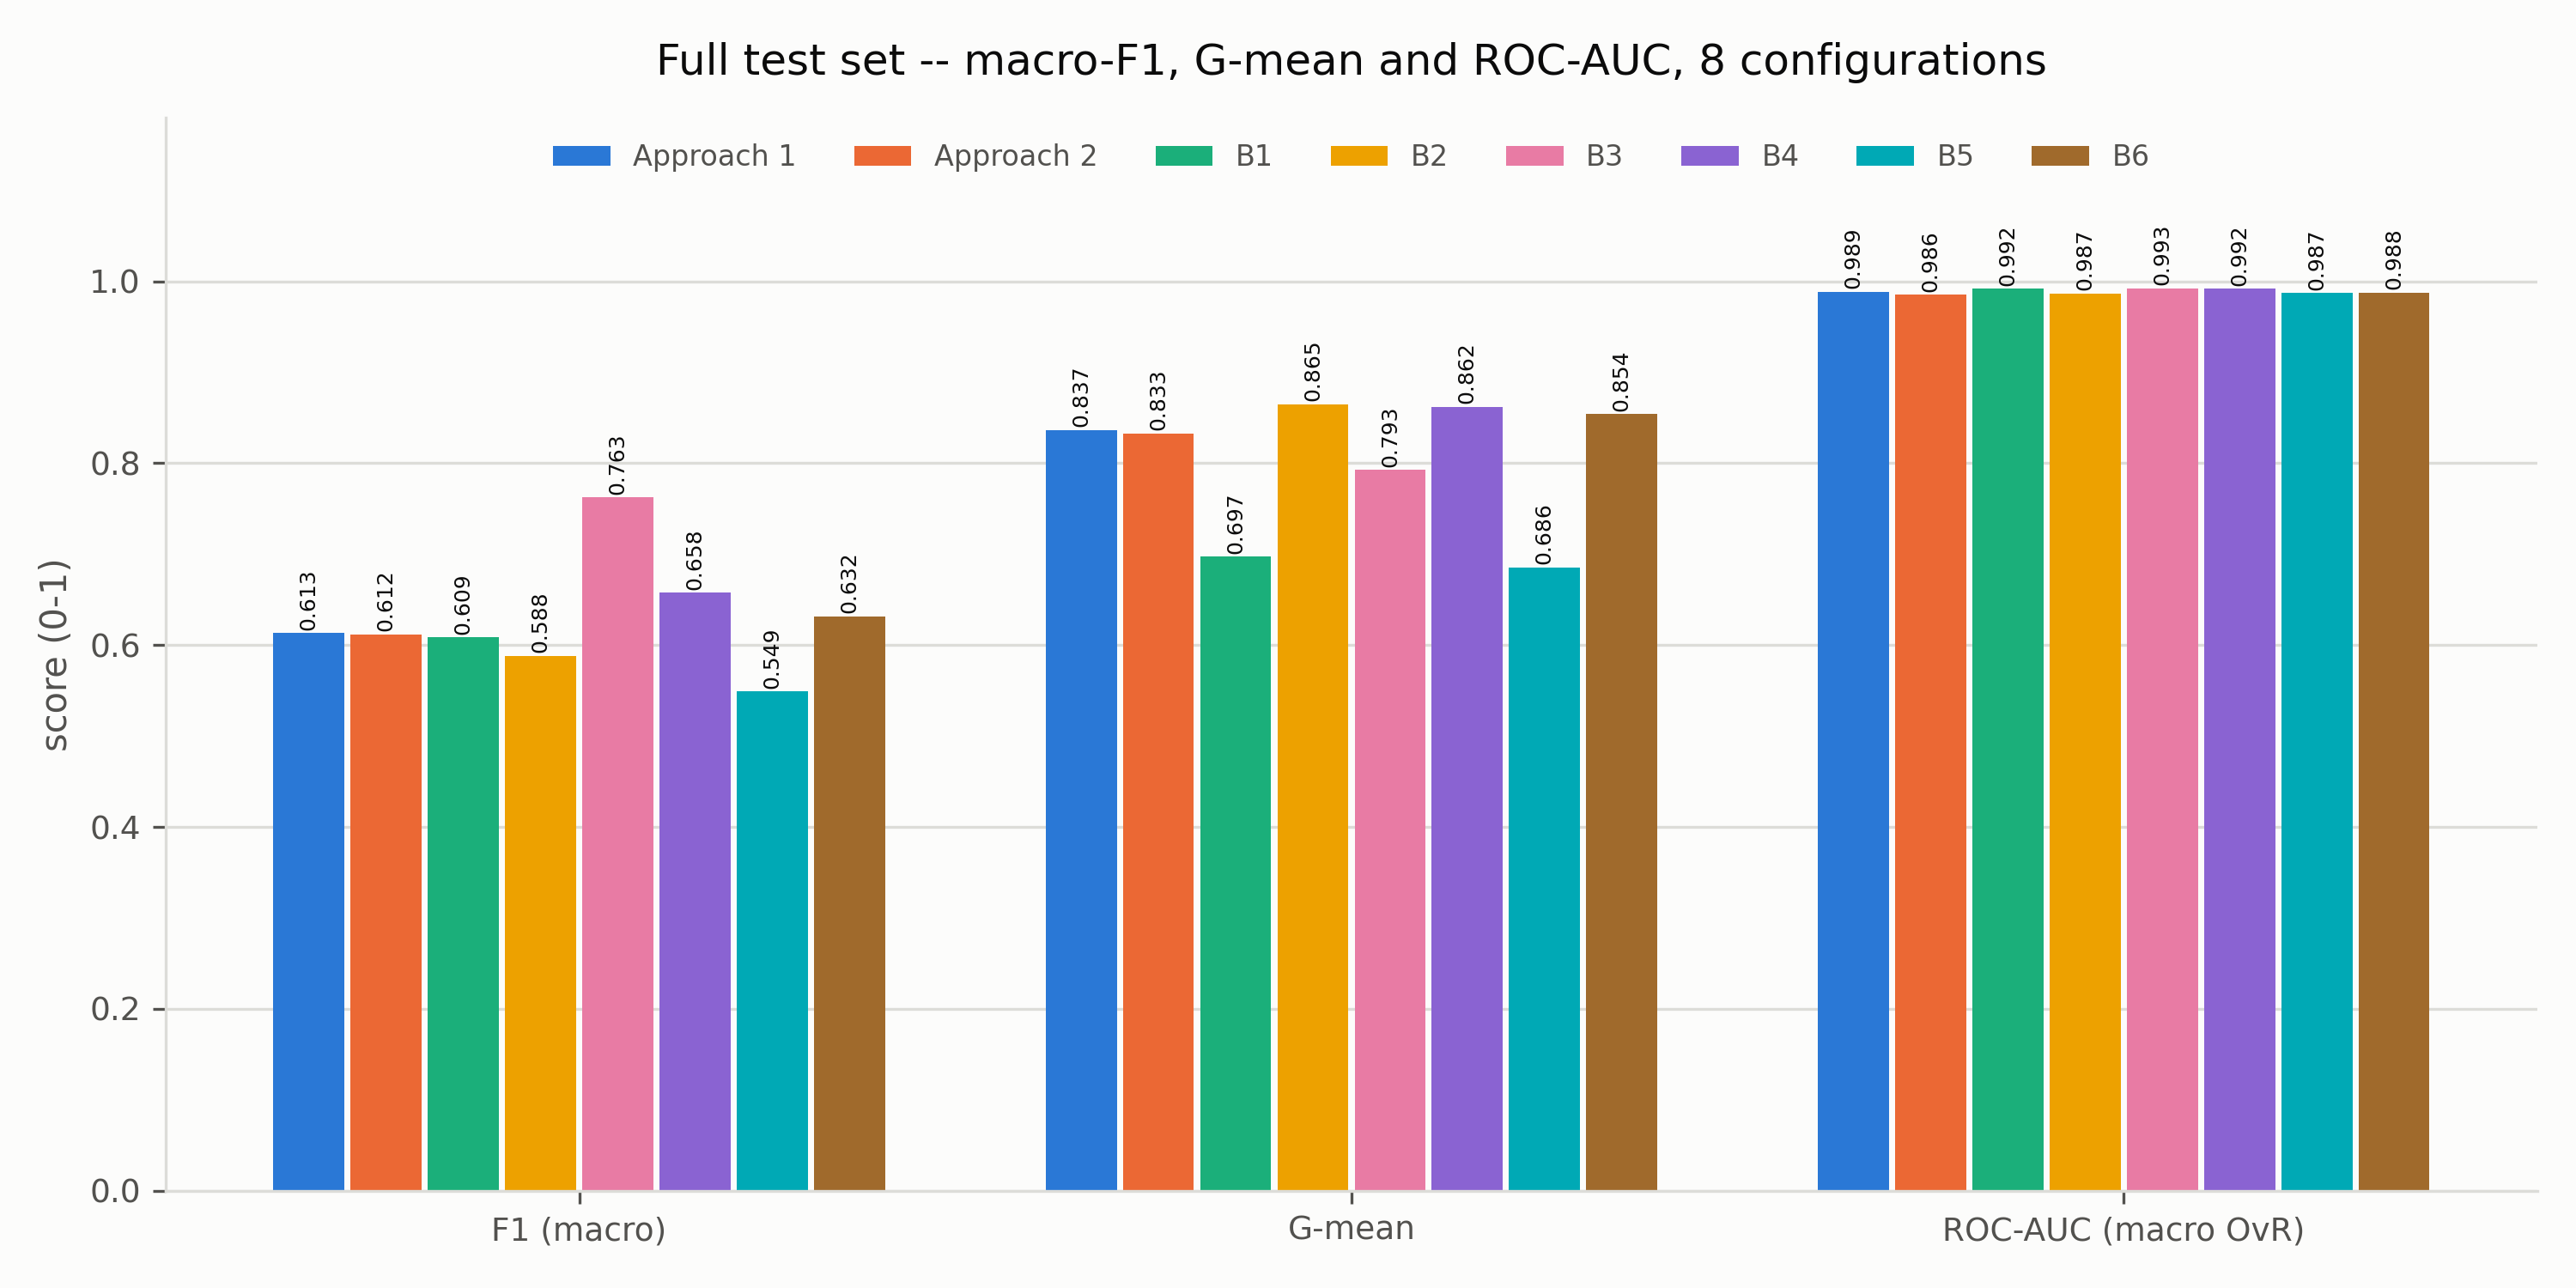

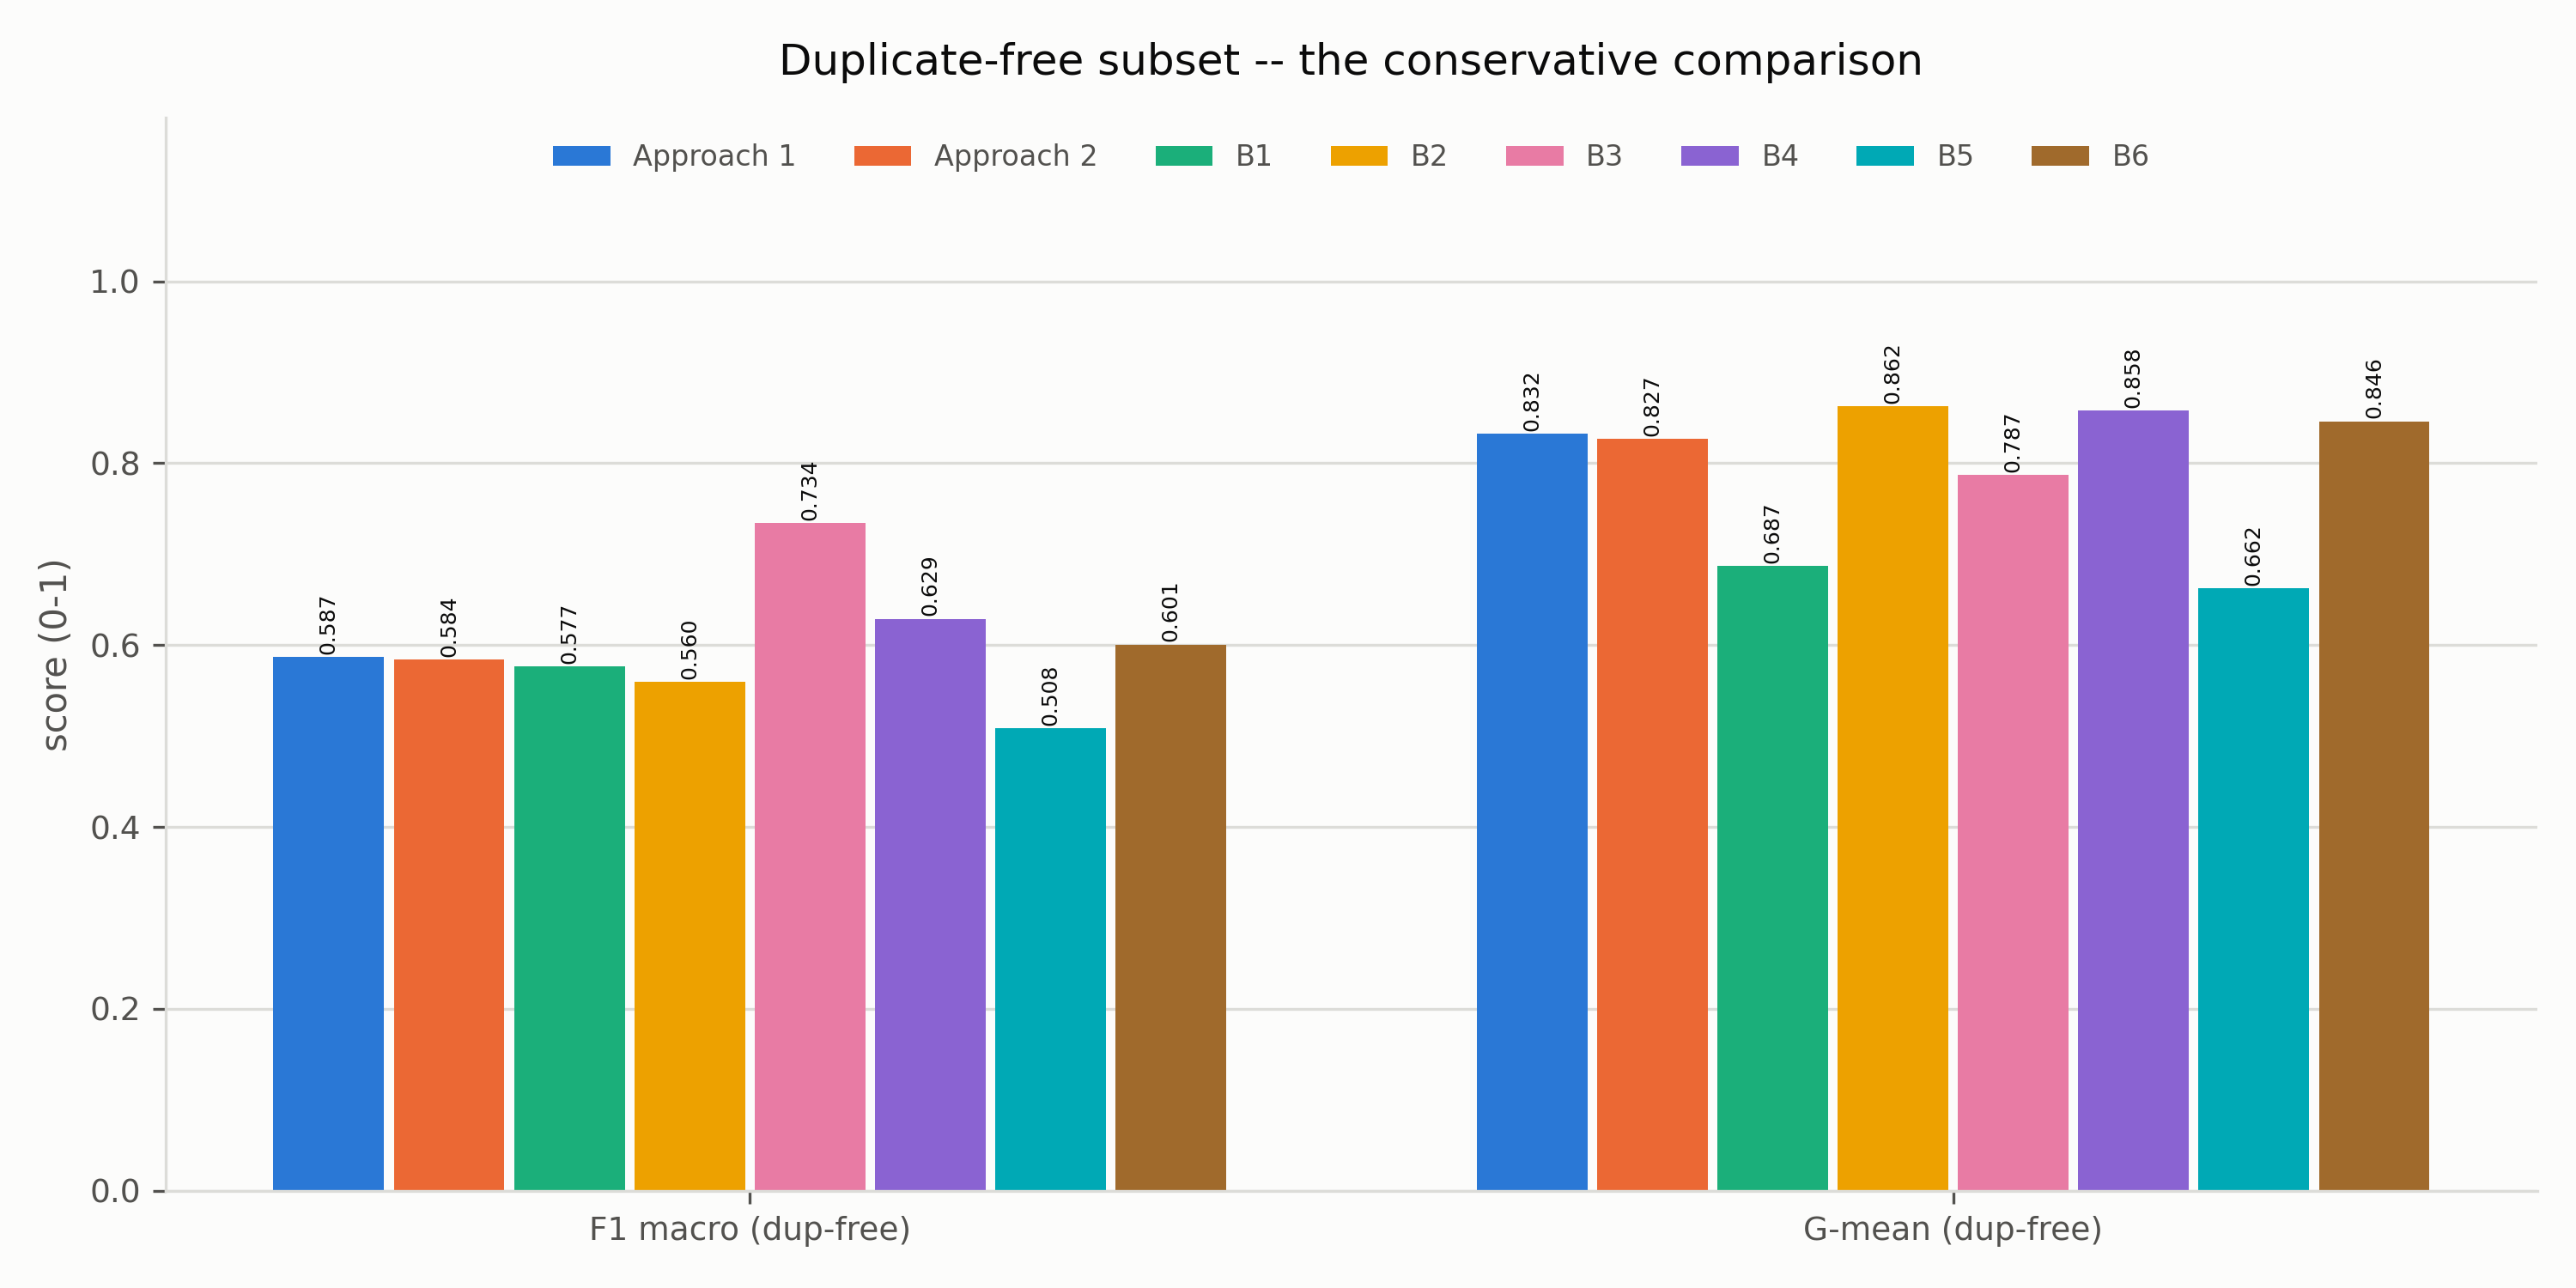

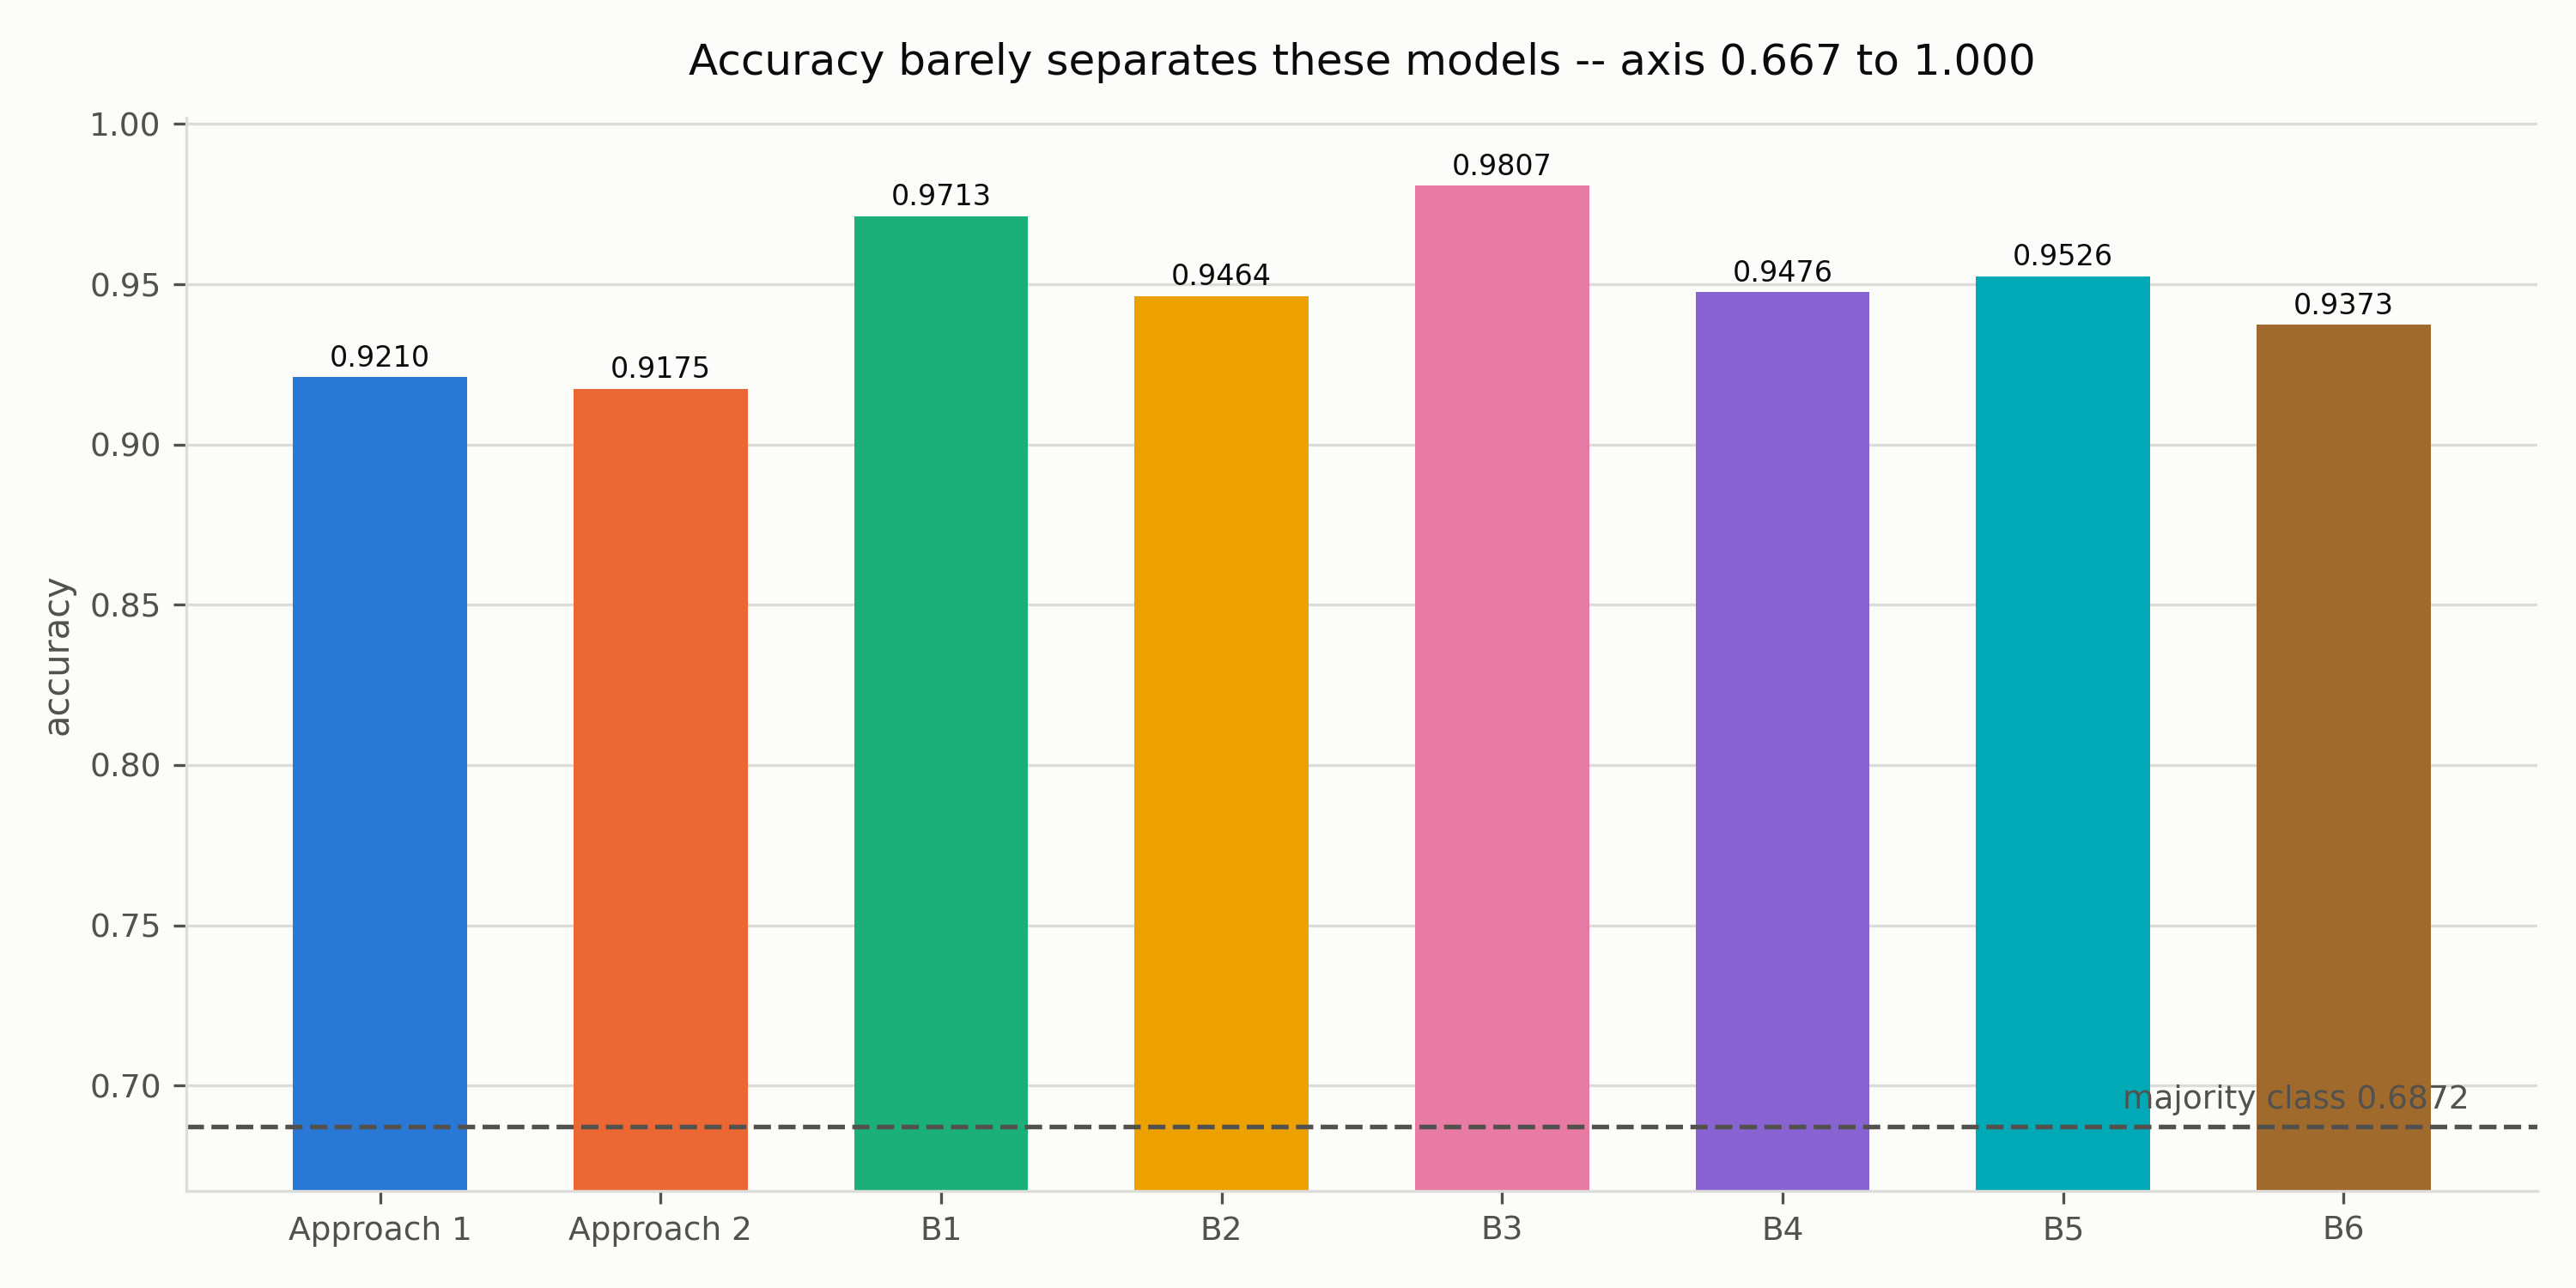

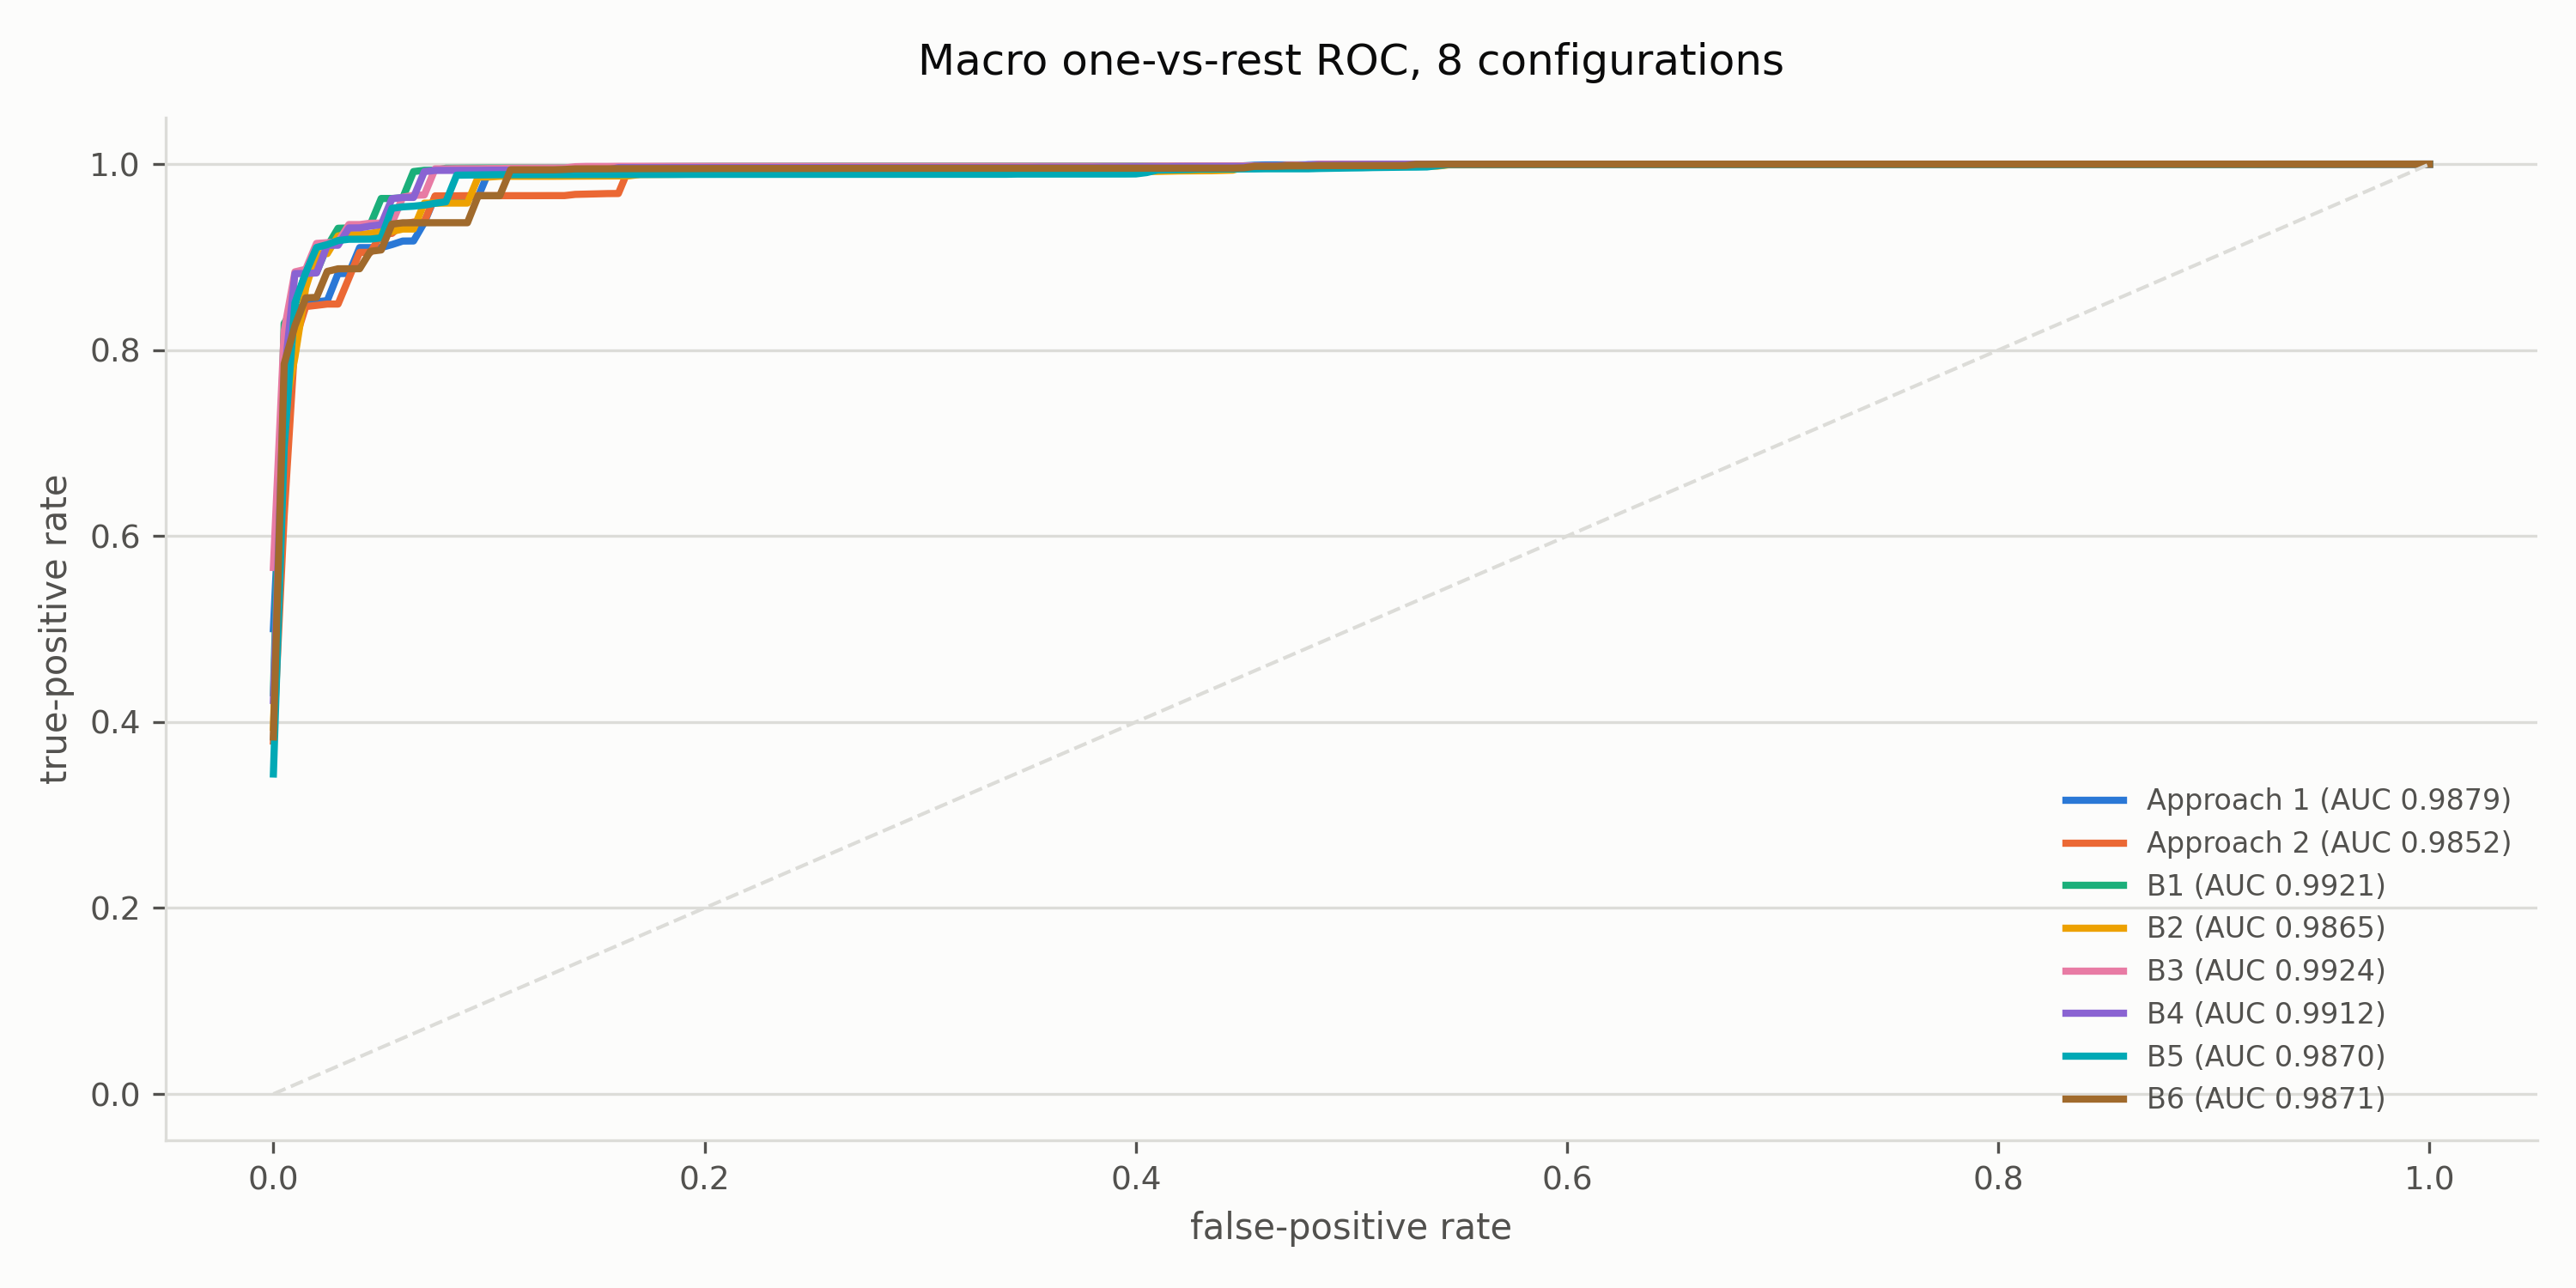

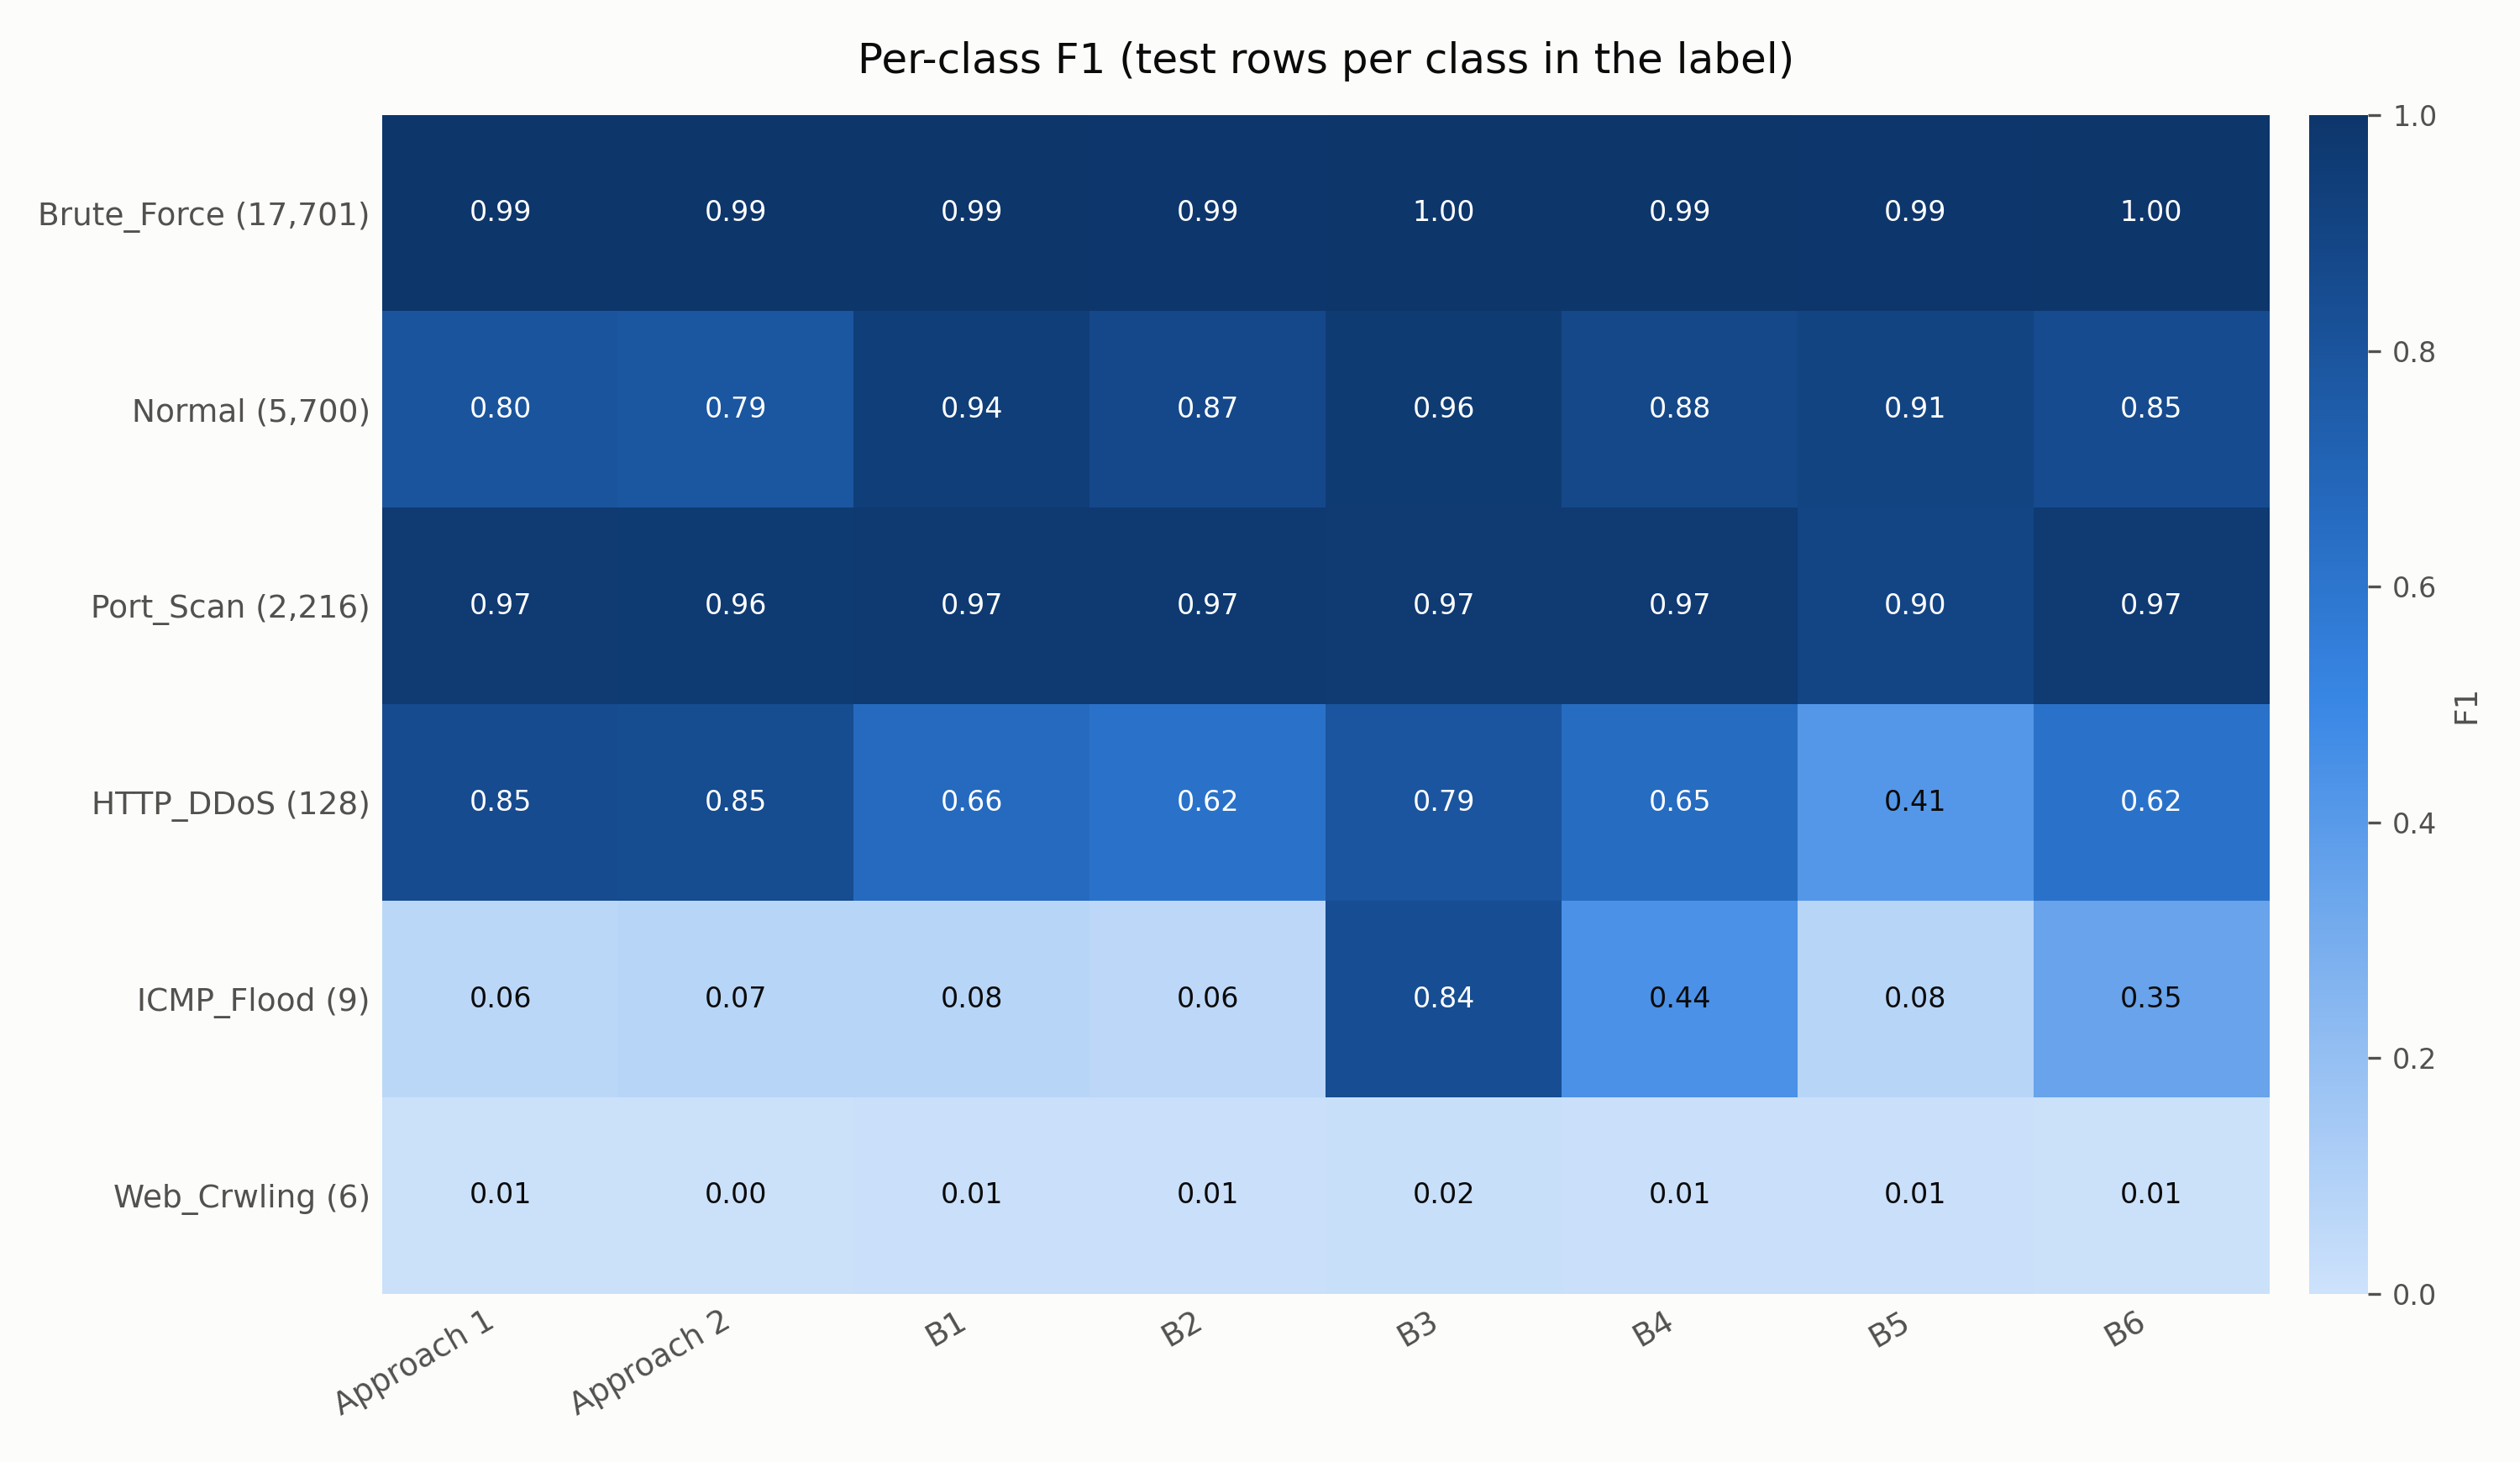

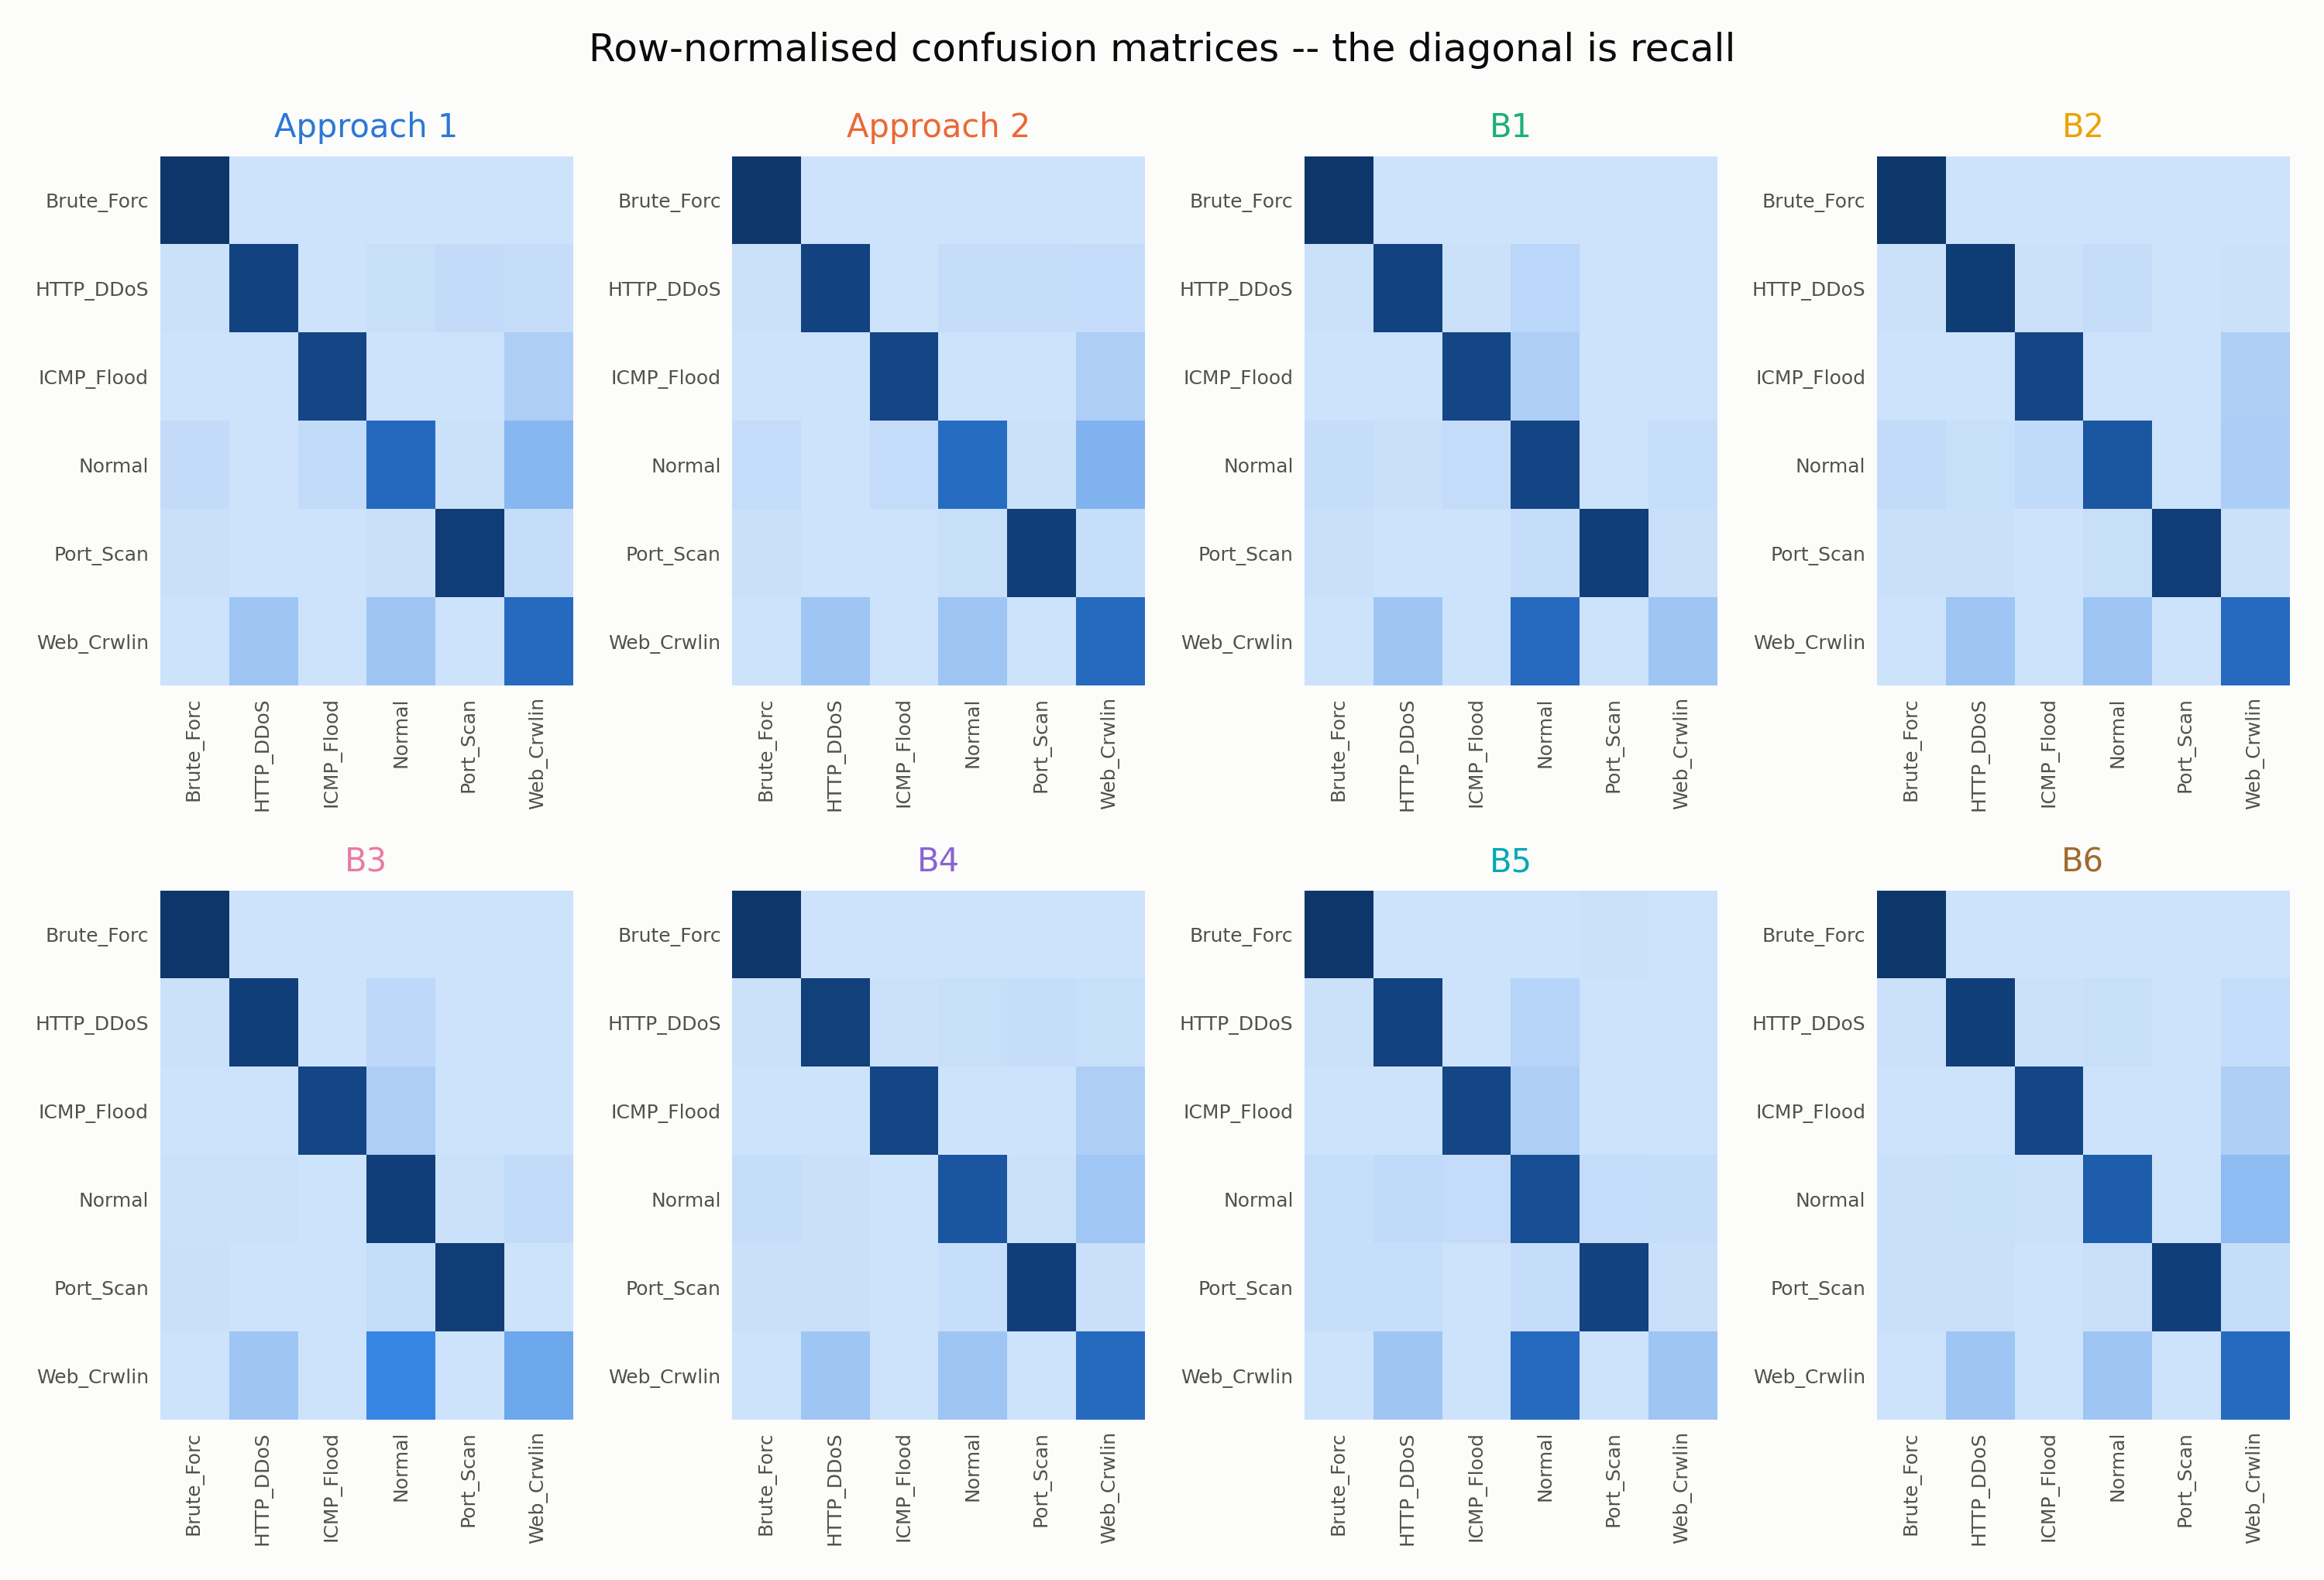

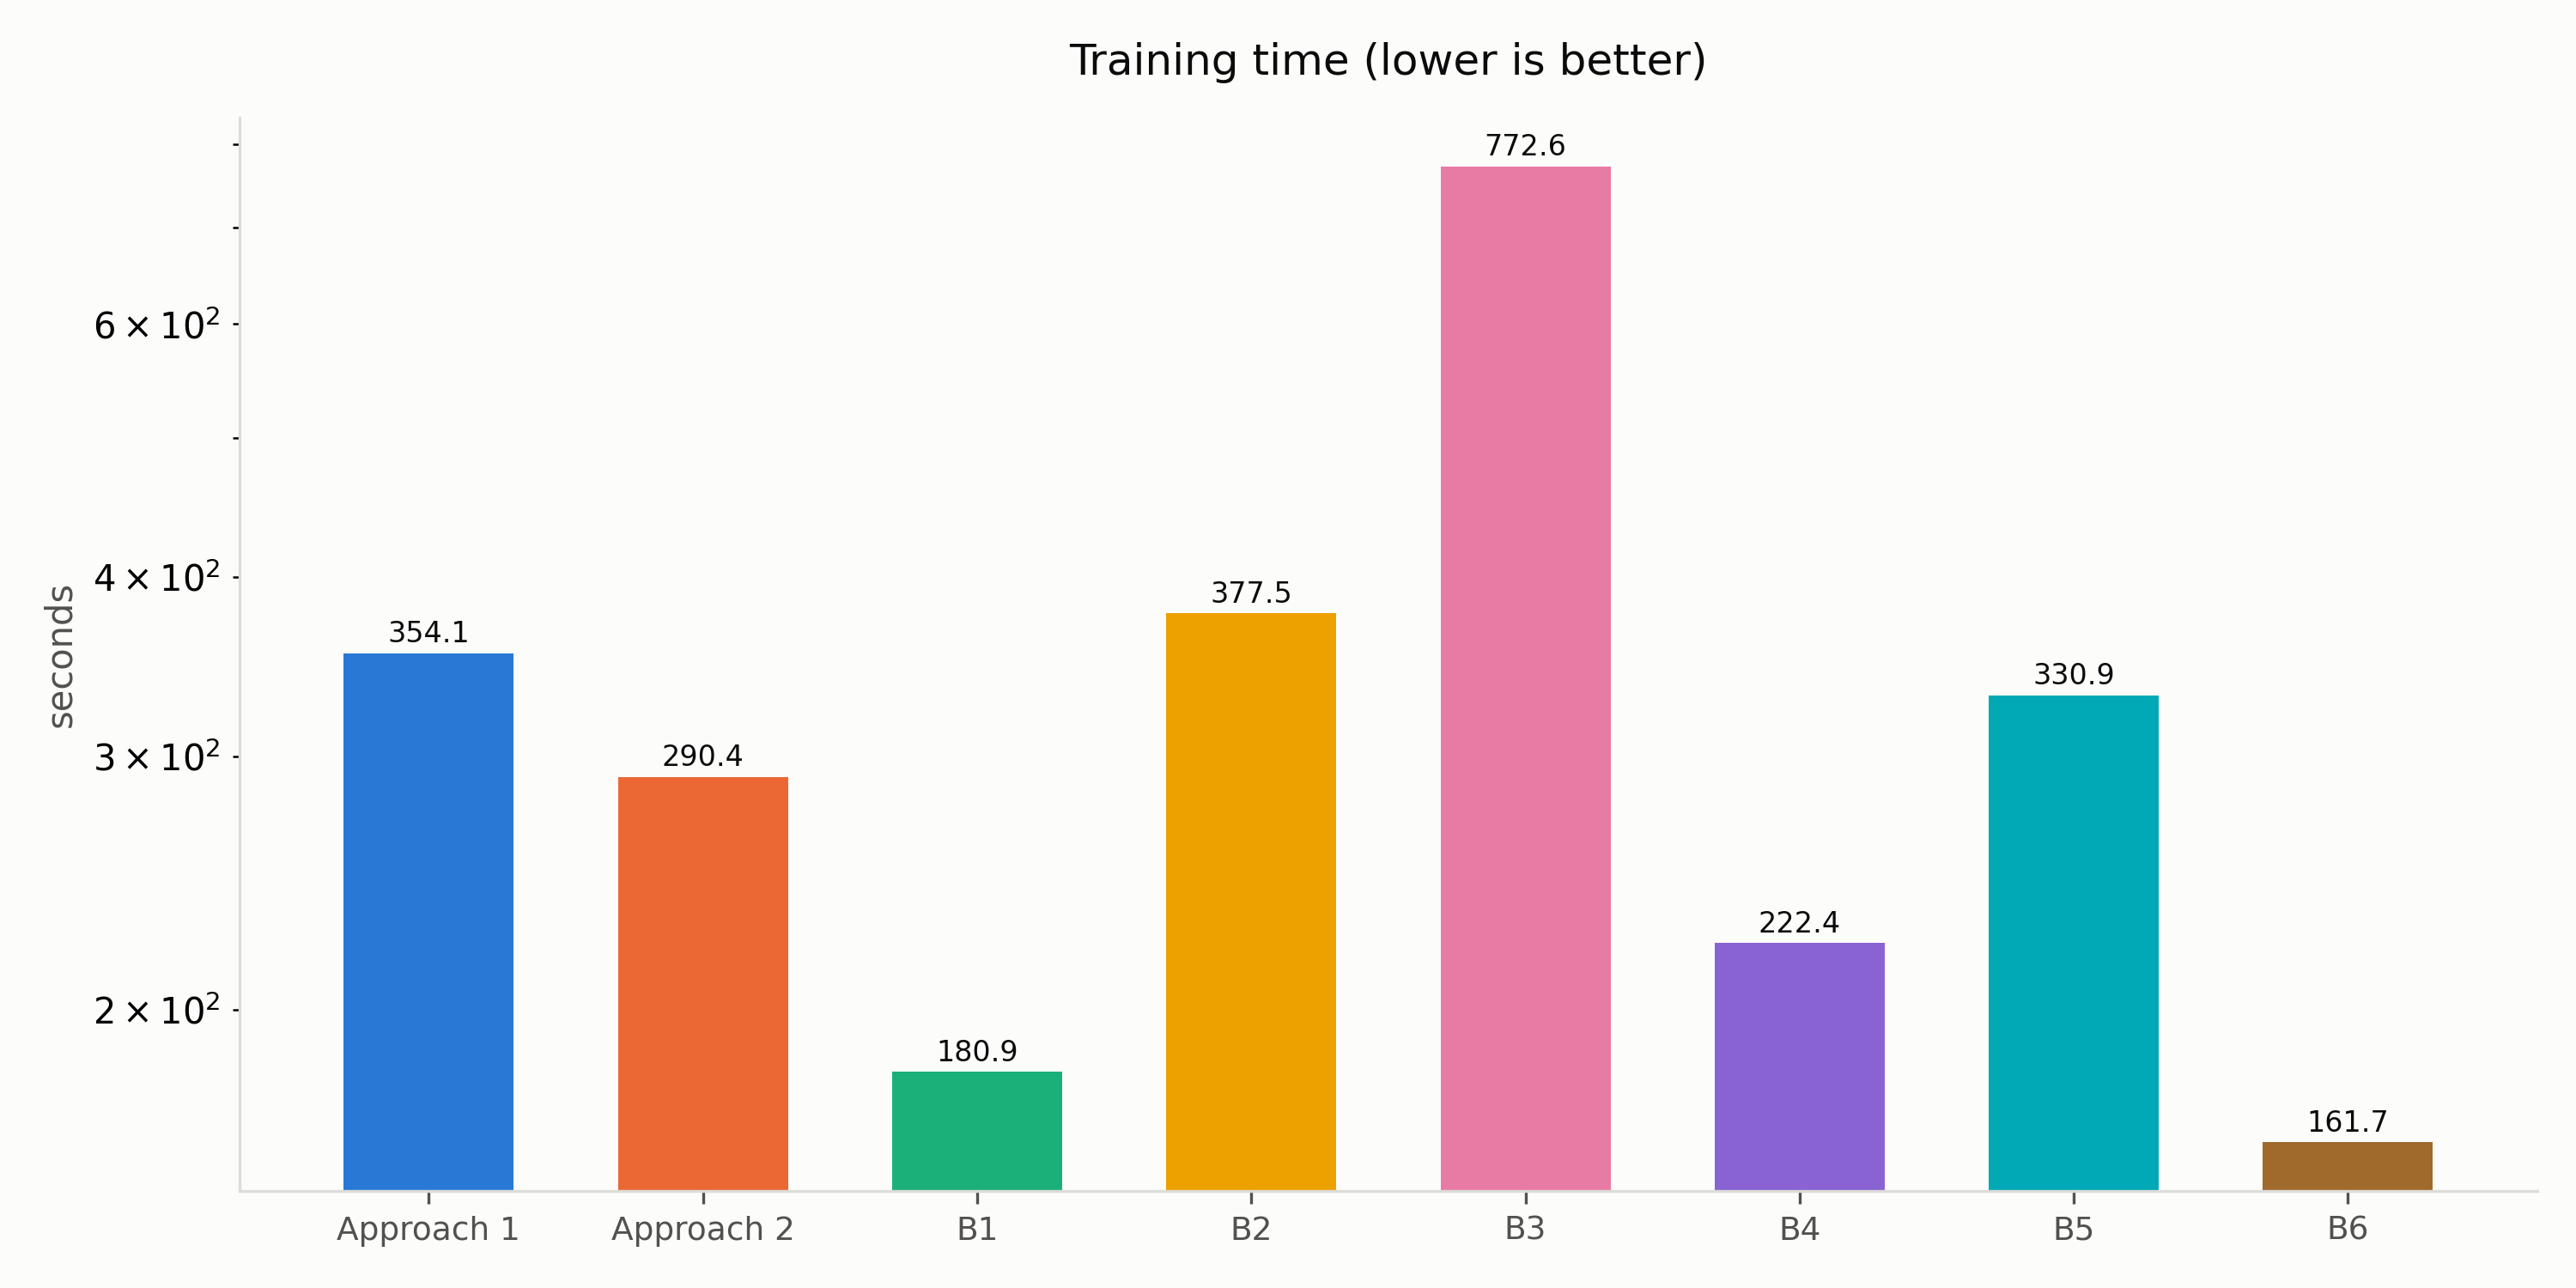

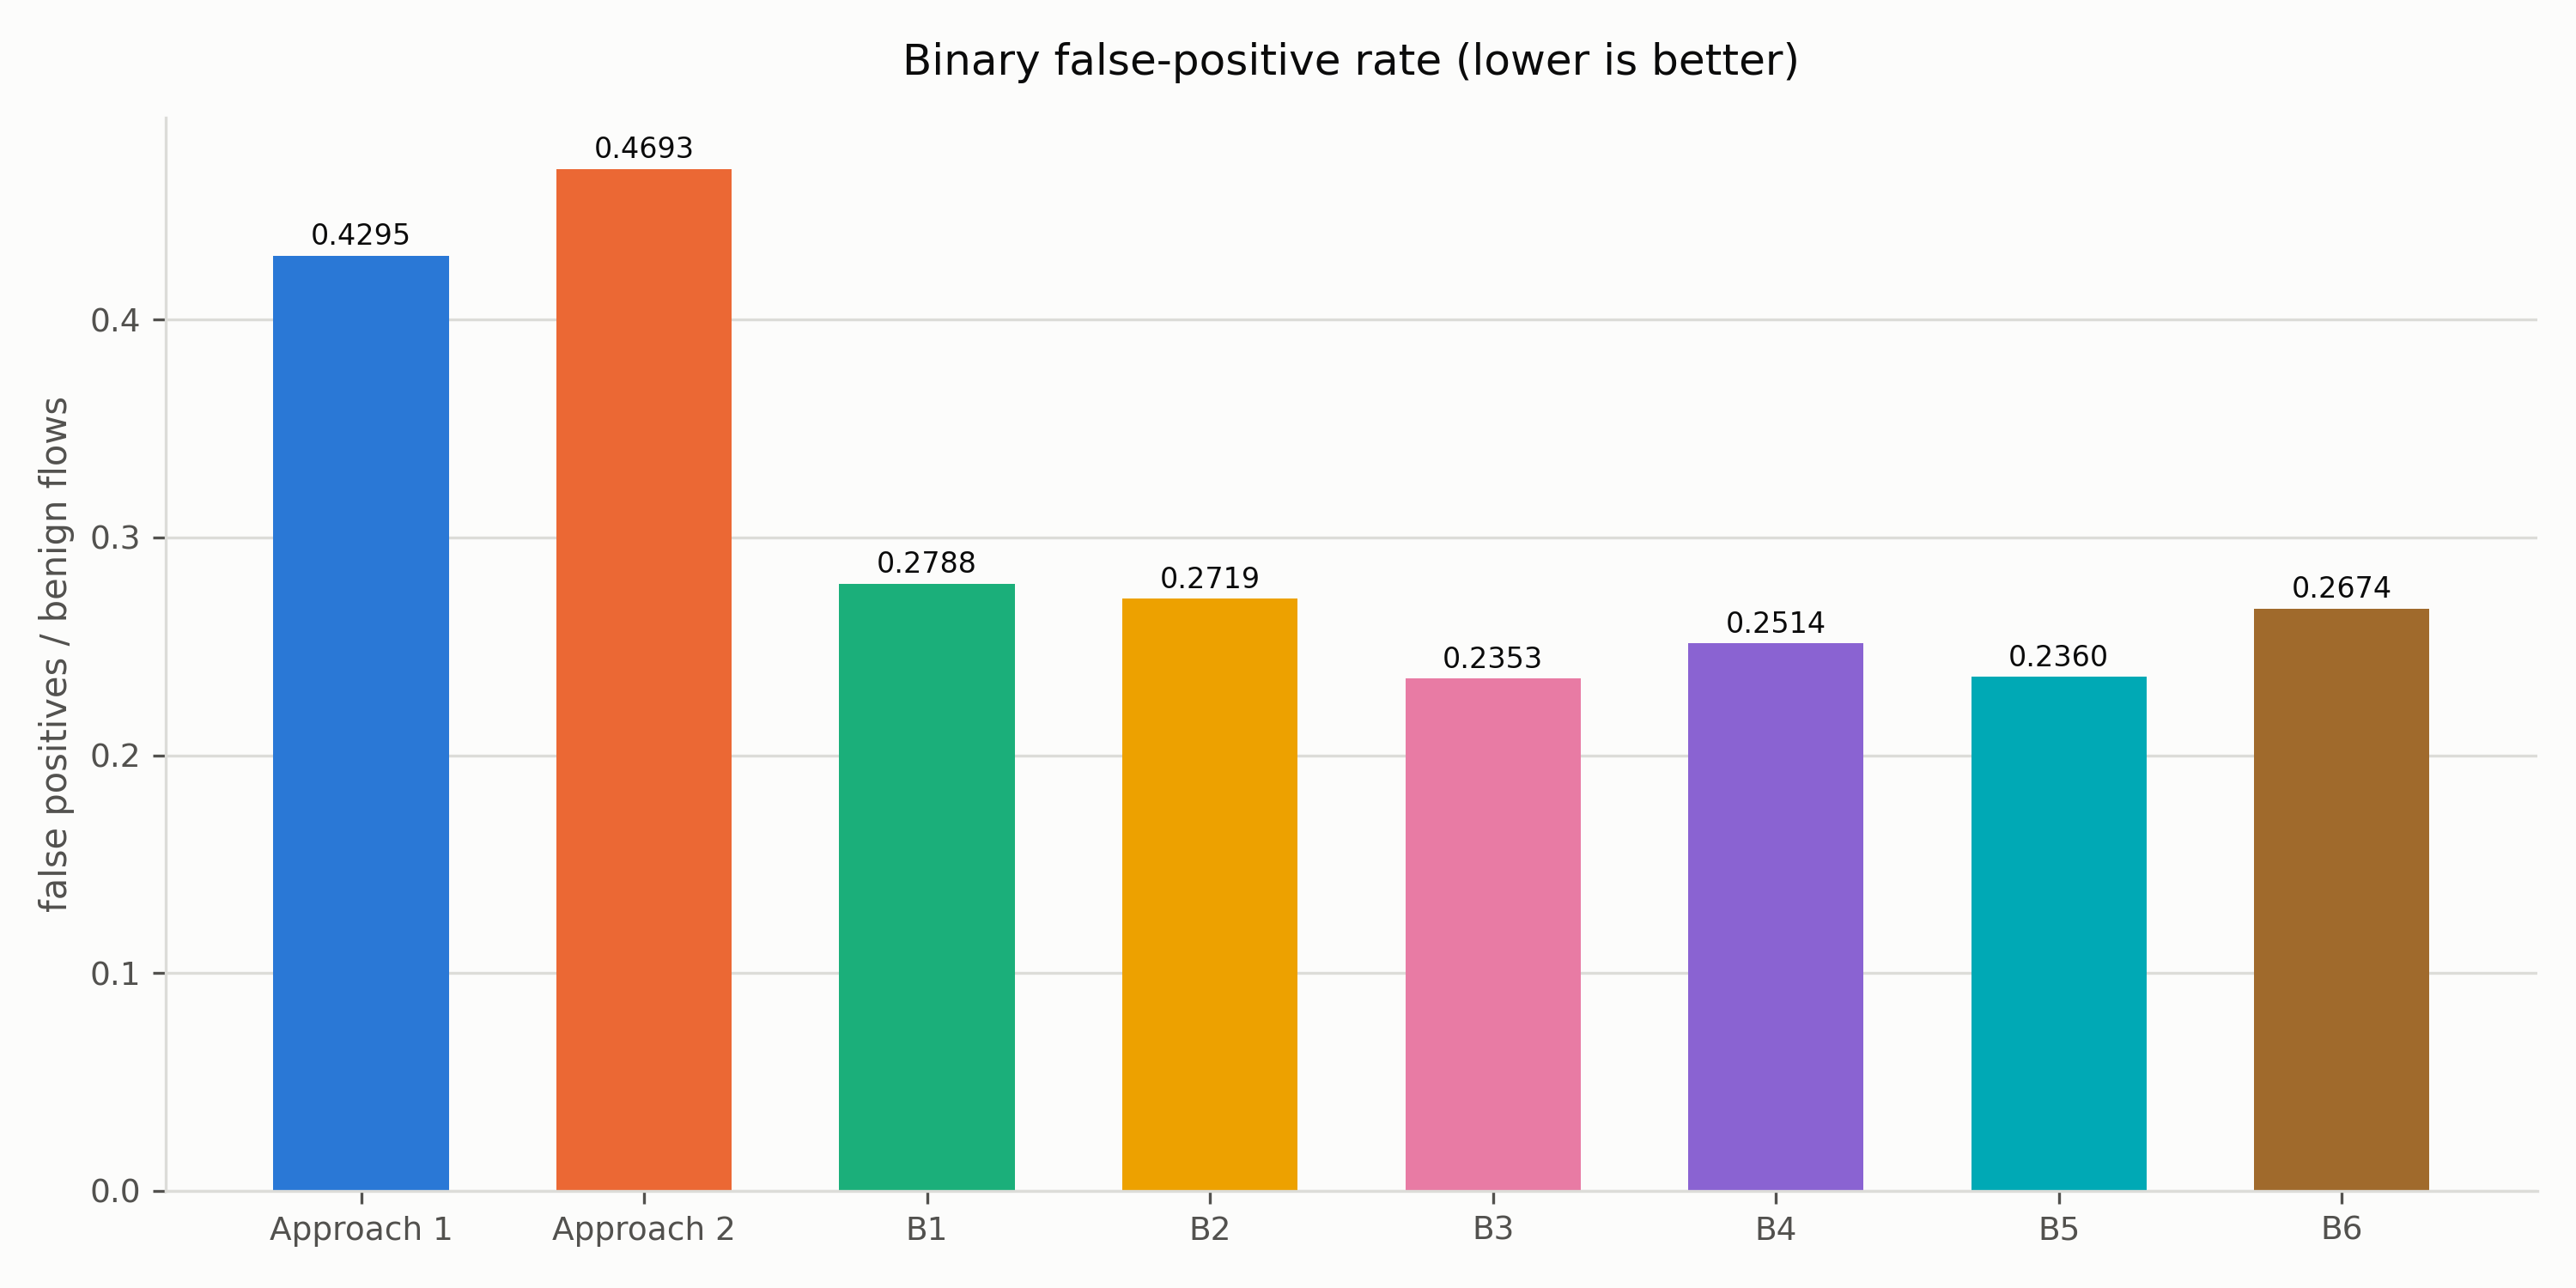

In [92]:
figures = report.figure_table(step12.get("charts"))
if len(figures):
    comparison.show_table(figures[figures["format"] == "png"][
        ["folder", "file", "exists"]], all_columns=True,
        note="Each figure is also written as a PDF beside the PNG, at "
             "%d dpi." % config.THESIS_FIGURE_DPI)

colours = report.colour_table()
comparison.show_table(colours, all_columns=True,
    note="One fixed colour per configuration. A [FAIL] would mean a figure "
         "and config.CONFIG_COLOURS disagree about a hue.")

for stem in comparison.FIGURE_FILES.values():
    folder = config.usable_output_dir(config.STEP12_OUTPUT_DIR)
    path = None if folder is None else folder / ("%s.png" % stem)
    if path is not None and path.exists() and comparison.dl.in_notebook():
        from IPython.display import Image
        display(Image(filename=str(path)))

### 10.13 Head-to-head comparisons

**Purpose** — A difference is only attributable when exactly one component
changed. These are the pairs where that is true:

| pair | what it isolates |
| --- | --- |
| Approach 1 vs B1 | the feature selection |
| Approach 1 vs B5 | the selection *method* at the same width |
| Approach 1 vs Approach 2 | the attention mechanism |
| B1 vs B2 | the CNN front end |
| B1 vs B3 | the autoencoder |
| B4 vs B6 | the classifier on the same PCA features |
| B1 vs B6 | the PCA stage before an unchanged CNN-LSTM |

`favours` accounts for direction — lower is better for the false-positive rate,
the parameter count and the times. A pair whose two configurations turn out to
differ in **more** than one component says so in its own label rather than
promising an isolation it does not have.

In [93]:
head = step12.get("head_to_head")
comparison.show_table(report.head_to_head_highlights(head), all_columns=True,
    note="macro-F1 per pair. The full metric-by-metric table is "
         "head_to_head_full.csv.")

for pair in (list(dict.fromkeys(head["pair"])) if head is not None
             and len(head) else []):
    comparison.show_table(head[head["pair"] == pair], all_columns=True,
                          note=pair)

differences = step12.get("per_class_difference")
if differences is not None and len(differences):
    comparison.show_table(differences.head(20), all_columns=True,
        note="Per-class F1 differences for the same pairs (first 20 rows; the "
             "full table is head_to_head_per_class_8configs.csv).")

,pair,metric,left,right,difference (left - right),favours
0,feature selection: Approach 1 vs B1 (with vs w...,F1 (macro),0.613385,0.608821,0.004564,Approach 1: FS -> AE -> CNN-LSTM
1,selection method: Approach 1 vs B5 (fused vs M...,F1 (macro),0.613385,0.549172,0.064213,Approach 1: FS -> AE -> CNN-LSTM
2,attention: Approach 1 vs Approach 2,F1 (macro),0.613385,0.611802,0.001583,Approach 1: FS -> AE -> CNN-LSTM
3,the CNN front end: B1 vs B2,F1 (macro),0.608821,0.588319,0.020502,B1: AE -> CNN-LSTM (no selection)
4,the autoencoder: B1 vs B3,F1 (macro),0.608821,0.762519,-0.153698,B3: CNN-LSTM (no AE)
5,the CNN on PCA features: B4 vs B6 [two differe...,F1 (macro),0.657558,0.631777,0.025781,B4: AE -> PCA -> LSTM
6,PCA before an unchanged CNN-LSTM: B1 vs B6,F1 (macro),0.608821,0.631777,-0.022956,B6: AE -> PCA -> CNN-LSTM


_macro-F1 per pair. The full metric-by-metric table is head_to_head_full.csv._

,pair,metric,left,right,difference (left - right),lower is better,favours
0,feature selection: Approach 1 vs B1 (with vs w...,params,50438.000000,50438.000000,0.000000,True,tie
1,feature selection: Approach 1 vs B1 (with vs w...,accuracy,0.921040,0.971273,-0.050233,False,B1: AE -> CNN-LSTM (no selection)
2,feature selection: Approach 1 vs B1 (with vs w...,precision (macro),0.632958,0.588599,0.044360,False,Approach 1: FS -> AE -> CNN-LSTM
3,feature selection: Approach 1 vs B1 (with vs w...,recall (macro),0.847681,0.801891,0.045790,False,Approach 1: FS -> AE -> CNN-LSTM
4,feature selection: Approach 1 vs B1 (with vs w...,F1 (macro),0.613385,0.608821,0.004564,False,Approach 1: FS -> AE -> CNN-LSTM
5,feature selection: Approach 1 vs B1 (with vs w...,F1 (weighted),0.946131,0.977221,-0.031090,False,B1: AE -> CNN-LSTM (no selection)
6,feature selection: Approach 1 vs B1 (with vs w...,G-mean,0.836769,0.697118,0.139652,False,Approach 1: FS -> AE -> CNN-LSTM
7,feature selection: Approach 1 vs B1 (with vs w...,ROC-AUC (macro OvR),0.988512,0.992260,-0.003748,False,B1: AE -> CNN-LSTM (no selection)
8,feature selection: Approach 1 vs B1 (with vs w...,binary F1,0.941920,0.960831,-0.018911,False,B1: AE -> CNN-LSTM (no selection)
9,feature selection: Approach 1 vs B1 (with vs w...,binary FPR,0.429474,0.278772,0.150702,True,B1: AE -> CNN-LSTM (no selection)


_feature selection: Approach 1 vs B1 (with vs without)_

,pair,metric,left,right,difference (left - right),lower is better,favours
14,selection method: Approach 1 vs B5 (fused vs M...,params,50438.000000,50438.000000,0.000000,True,tie
15,selection method: Approach 1 vs B5 (fused vs M...,accuracy,0.921040,0.952562,-0.031522,False,B5: MI-only top 30 -> AE -> CNN-LSTM
16,selection method: Approach 1 vs B5 (fused vs M...,precision (macro),0.632958,0.526835,0.106123,False,Approach 1: FS -> AE -> CNN-LSTM
17,selection method: Approach 1 vs B5 (fused vs M...,recall (macro),0.847681,0.786929,0.060752,False,Approach 1: FS -> AE -> CNN-LSTM
18,selection method: Approach 1 vs B5 (fused vs M...,F1 (macro),0.613385,0.549172,0.064213,False,Approach 1: FS -> AE -> CNN-LSTM
19,selection method: Approach 1 vs B5 (fused vs M...,F1 (weighted),0.946131,0.961230,-0.015099,False,B5: MI-only top 30 -> AE -> CNN-LSTM
20,selection method: Approach 1 vs B5 (fused vs M...,G-mean,0.836769,0.685540,0.151229,False,Approach 1: FS -> AE -> CNN-LSTM
21,selection method: Approach 1 vs B5 (fused vs M...,ROC-AUC (macro OvR),0.988512,0.987260,0.001251,False,Approach 1: FS -> AE -> CNN-LSTM
22,selection method: Approach 1 vs B5 (fused vs M...,binary F1,0.941920,0.966616,-0.024696,False,B5: MI-only top 30 -> AE -> CNN-LSTM
23,selection method: Approach 1 vs B5 (fused vs M...,binary FPR,0.429474,0.235965,0.193509,True,B5: MI-only top 30 -> AE -> CNN-LSTM


...

_the CNN on PCA features: B4 vs B6 [two differences: PCA(6) vs PCA(3) as well -- see 12.11]_

,pair,metric,left,right,difference (left - right),lower is better,favours
84,PCA before an unchanged CNN-LSTM: B1 vs B6,params,50438.000000,50438.000000,0.000000,True,tie
85,PCA before an unchanged CNN-LSTM: B1 vs B6,accuracy,0.971273,0.937345,0.033929,False,B1: AE -> CNN-LSTM (no selection)
86,PCA before an unchanged CNN-LSTM: B1 vs B6,precision (macro),0.588599,0.611380,-0.022781,False,B6: AE -> PCA -> CNN-LSTM
87,PCA before an unchanged CNN-LSTM: B1 vs B6,recall (macro),0.801891,0.862940,-0.061049,False,B6: AE -> PCA -> CNN-LSTM
88,PCA before an unchanged CNN-LSTM: B1 vs B6,F1 (macro),0.608821,0.631777,-0.022956,False,B6: AE -> PCA -> CNN-LSTM
89,PCA before an unchanged CNN-LSTM: B1 vs B6,F1 (weighted),0.977221,0.959897,0.017323,False,B1: AE -> CNN-LSTM (no selection)
90,PCA before an unchanged CNN-LSTM: B1 vs B6,G-mean,0.697118,0.854394,-0.157276,False,B6: AE -> PCA -> CNN-LSTM
91,PCA before an unchanged CNN-LSTM: B1 vs B6,ROC-AUC (macro OvR),0.992260,0.987768,0.004492,False,B1: AE -> CNN-LSTM (no selection)
92,PCA before an unchanged CNN-LSTM: B1 vs B6,binary F1,0.960831,0.962881,-0.002050,False,B6: AE -> PCA -> CNN-LSTM
93,PCA before an unchanged CNN-LSTM: B1 vs B6,binary FPR,0.278772,0.267368,0.011404,True,B6: AE -> PCA -> CNN-LSTM


_PCA before an unchanged CNN-LSTM: B1 vs B6_

,pair,Label,test rows,Approach 1,B1,difference,favours,B5,Approach 2,B2,B3,B4,B6
0,feature selection: Approach 1 vs B1 (with vs w...,Brute_Force,17701,0.992675,0.993621,-0.000946,B1,NaN,NaN,NaN,NaN,NaN,NaN
1,feature selection: Approach 1 vs B1 (with vs w...,Normal,5700,0.798575,0.939030,-0.140455,B1,NaN,NaN,NaN,NaN,NaN,NaN
2,feature selection: Approach 1 vs B1 (with vs w...,Port_Scan,2216,0.965343,0.968981,-0.003638,B1,NaN,NaN,NaN,NaN,NaN,NaN
3,feature selection: Approach 1 vs B1 (with vs w...,HTTP_DDoS,128,0.854015,0.661017,0.192998,Approach 1,NaN,NaN,NaN,NaN,NaN,NaN
4,feature selection: Approach 1 vs B1 (with vs w...,ICMP_Flood,9,0.064257,0.076190,-0.011933,B1,NaN,NaN,NaN,NaN,NaN,NaN
5,feature selection: Approach 1 vs B1 (with vs w...,Web_Crwling,6,0.005446,0.014085,-0.008639,B1,NaN,NaN,NaN,NaN,NaN,NaN
6,selection method: Approach 1 vs B5 (fused vs M...,Brute_Force,17701,0.992675,NaN,0.000796,Approach 1,0.991879,NaN,NaN,NaN,NaN,NaN
7,selection method: Approach 1 vs B5 (fused vs M...,Normal,5700,0.798575,NaN,-0.107524,B5,0.906099,NaN,NaN,NaN,NaN,NaN
8,selection method: Approach 1 vs B5 (fused vs M...,Port_Scan,2216,0.965343,NaN,0.069308,Approach 1,0.896035,NaN,NaN,NaN,NaN,NaN
9,selection method: Approach 1 vs B5 (fused vs M...,HTTP_DDoS,128,0.854015,NaN,0.440587,Approach 1,0.413428,NaN,NaN,NaN,NaN,NaN


_Per-class F1 differences for the same pairs (first 20 rows; the full table is head_to_head_per_class_8configs.csv)._

### 10.14 Discussion and limitations

**Purpose** — What the eight rows support, and what they do not. Every sentence
below is generated from the tables above; none of it is written by hand.

It states the ranking on macro-F1, G-mean, the binary false-positive rate and
the duplicate-free metrics; **where Approach 1 and Approach 2 are not best**;
why accuracy is similar for every configuration; and the limitations that
bound all of it — the duplicate rows, the random flow-level split, one capture
per attack type, the rare classes with a handful of test rows, the single seed,
and Baseline 6's PCA sequence length.

**Then rule 4, last:** every finished configuration's saved metrics, recorded
in 10.0 before anything ran, against the same files now. A number that moved is
a `[FAIL]`, not a rounding difference.

In [94]:
discussion = report.discussion(step12, provenance, b6, majority)
if comparison.dl.in_notebook() and Markdown is not None:
    display(Markdown(discussion))
else:
    print(discussion)

folder = config.usable_output_dir(config.STEP12_OUTPUT_DIR)
if folder is not None:
    (folder / "step12_discussion.md").write_text(discussion, encoding="utf-8")
    print("saved:", folder / "step12_discussion.md")

## Step 12.11 -- discussion and limitations

### Which configuration wins, and on what

- **macro-F1** (higher is better): B3 leads with 0.7625. Order: B3 0.7625, then B4 0.6576, then B6 0.6318, then Approach 1 0.6134, then Approach 2 0.6118.
  - Approach 1 is **not** best here: 0.6134 against 0.7625, 4 of 8.
  - Approach 2 is **not** best here: 0.6118 against 0.7625, 5 of 8.
- **G-mean** (higher is better): B2 leads with 0.8650. Order: B2 0.8650, then B4 0.8623, then B6 0.8544, then Approach 1 0.8368, then Approach 2 0.8330.
  - Approach 1 is **not** best here: 0.8368 against 0.8650, 4 of 8.
  - Approach 2 is **not** best here: 0.8330 against 0.8650, 5 of 8.
- **binary FPR** (lower is better): B3 leads with 0.2353. Order: B3 0.2353, then B5 0.2360, then B4 0.2514, then B6 0.2674, then B2 0.2719.
  - Approach 1 is **not** best here: 0.4295 against 0.2353, 7 of 8.
  - Approach 2 is **not** best here: 0.4693 against 0.2353, 8 of 8.
- **macro-F1 on the duplicate-free subset** (higher is better): B3 leads with 0.7342. Order: B3 0.7342, then B4 0.6290, then B6 0.6005, then Approach 1 0.5868, then Approach 2 0.5842.
  - Approach 1 is **not** best here: 0.5868 against 0.7342, 4 of 8.
  - Approach 2 is **not** best here: 0.5842 against 0.7342, 5 of 8.
- **G-mean on the duplicate-free subset** (higher is better): B2 leads with 0.8625. Order: B2 0.8625, then B4 0.8580, then B6 0.8462, then Approach 1 0.8323, then Approach 2 0.8268.
  - Approach 1 is **not** best here: 0.8323 against 0.8625, 4 of 8.
  - Approach 2 is **not** best here: 0.8268 against 0.8625, 5 of 8.

### What each component contributes

- **feature selection: Approach 1 vs B1 (with vs without):** macro-F1 differs by +0.0046 (Approach 1: FS -> AE -> CNN-LSTM).
- **selection method: Approach 1 vs B5 (fused vs MI only):** macro-F1 differs by +0.0642 (Approach 1: FS -> AE -> CNN-LSTM).
- **attention: Approach 1 vs Approach 2:** macro-F1 differs by +0.0016 (Approach 1: FS -> AE -> CNN-LSTM).
- **the CNN front end: B1 vs B2:** macro-F1 differs by +0.0205 (B1: AE -> CNN-LSTM (no selection)).
- **the autoencoder: B1 vs B3:** macro-F1 differs by -0.1537 (B3: CNN-LSTM (no AE)).
- **the CNN on PCA features: B4 vs B6 [two differences: PCA(6) vs PCA(3) as well -- see 12.11]:** macro-F1 differs by +0.0258 (B4: AE -> PCA -> LSTM).
- **PCA before an unchanged CNN-LSTM: B1 vs B6:** macro-F1 differs by -0.0230 (B6: AE -> PCA -> CNN-LSTM).

### What the checks found

- **Provenance (12.0): every check passed.** Each row of the comparison is traceable to the saved file listed in `provenance.csv`, and the fused files in Steps 13 and 13.8 were computed from the predictions these models still hold.
- **Table vs disk (12.7):** 8 of 8 rows match their metrics.json to 1e-9.

### Limitations

- **Duplicate rows.** About 54% of the dataset's rows are feature-identical to another row, so a test flow can be an exact copy of a training flow. The duplicate-free columns exclude those: the largest macro-F1 fall between the two views is 0.0408, and the duplicate-free number is the conservative one to quote.
- **Random flow-level split.** The split is over flows, not over captures or sessions, so flows from one attack session can appear in both training and test. Every number here is therefore optimistic relative to an unseen capture.
- **Rare classes.** ICMP_Flood, Web_Crwling have 9, 6 test rows respectively, so their per-class F1 moves in large steps and a difference there is not evidence.
- **One seed.** `N_SEEDS = 1`: every figure is a single run. Differences of about 0.01 in macro-F1 may not be meaningful, and none of the gaps above is a significance claim.
- **Baseline 6's sequence length.** The PCA keeps 3 component(s), so the Conv1D kernel of 3 fits only by padding and the pooling layer is skipped at this length, which leaves 3 position(s) for the LSTM. The convolution has almost nothing to slide over: B6 is therefore best read as *PCA features with an extra learned front end*, not as a CNN over a sequence. The shared architecture is deliberately NOT changed for B6 -- changing it would break the one-difference comparison with B4 and B1.
- **B4 vs B6 differs in two things, not one.** Baseline 4's PCA keeps 6 component(s) and Baseline 6's keeps 3, because the shared Conv1D kernel of 3 cannot be built on a shorter sequence and the architecture was not changed to fit. So that pair mixes the classifier (LSTM vs CNN-LSTM) with the width of the PCA space, and the difference between them cannot be attributed to the classifier alone. **B1 vs B6 is the clean single-difference pair for Baseline 6**: the same AE latents and the same CNN-LSTM, with PCA(3) inserted and nothing else changed.
- **Provenance is per machine.** The SHA-256 values in `provenance.csv` identify the files on the machine that ran this notebook; a rerun elsewhere produces different model bytes and must be re-fingerprinted.
- **Why accuracy is similar for every configuration.** A predictor that answers with the single most frequent training class and nothing else already reaches **0.6872 accuracy**, with a macro-F1 of 0.1358 and a G-mean of 0.0000 -- it never finds one attack class. The two largest test classes are Brute_Force and Normal, 90.8% of the test rows between them. So accuracy is reported for completeness and read against that line; macro-F1 and G-mean are the comparison metrics.

saved: C:\MSCAD2022\outputs_official\step12\step12_discussion.md


In [95]:
rule4 = report.verify_unchanged(saved_before)

,configuration,metrics compared,largest difference,result,detail
0,Approach 1: FS -> AE -> CNN-LSTM,14,0.0,[OK],identical to the value recorded before this run
1,Approach 2: FS -> AE -> CNN-Attention-LSTM,15,0.0,[OK],identical to the value recorded before this run
2,B1: AE -> CNN-LSTM (no selection),15,0.0,[OK],identical to the value recorded before this run
3,B2: AE -> LSTM (no CNN),15,0.0,[OK],identical to the value recorded before this run
4,B3: CNN-LSTM (no AE),15,0.0,[OK],identical to the value recorded before this run
5,B4: AE -> PCA -> LSTM,15,0.0,[OK],identical to the value recorded before this run
6,B5: MI-only top 30 -> AE -> CNN-LSTM,15,0.0,[OK],identical to the value recorded before this run
7,B6: AE -> PCA -> CNN-LSTM,15,0.0,[OK],identical to the value recorded before this run


_Rule 4: every finished configuration's saved metrics, recorded in 12.0 before anything ran, against the same files now (1e-9)._

[OK]  8 of 8 configurations unchanged


In [96]:
# the thesis exports: every table as CSV and as a booktabs .tex
exports = report.export_tables(step12, provenance,
                               configuration={"training_setup": setup})
print("%d thesis files written to %s"
      % (len(exports), config.STEP12_THESIS_DIR))

status = report.status_table({
    "approach1": a1, "approach2": a2, "baseline1": b1, "baseline2": b2,
    "baseline3": b3, "baseline4": b4, "baseline5": b5, "baseline6": b6})
comparison.show_table(status, all_columns=True,
    note="The eight configuration files, what each one did, and whether its "
         "numbers are the saved ones. This is the table to read first when "
         "something below looks wrong.")

checks = {
    "the eight configuration files": bool(
        (status["result"] == "[FAIL]").any()),
    "rule 4 (saved metrics unchanged)": bool(
        (rule4["result"] == "[FAIL]").any()),
    "table against disk (1e-9)": bool(
        (verified["result"] == "[FAIL]").any()),
    "headline numbers against the published figures": not bool(
        step12.get("unchanged_ok")),
    "each file agrees with the published configuration table": not bool(
        configuration_check["ok"]),
}
for what, broken in checks.items():
    print("  [%s]  %s" % ("FAIL" if broken else "OK", what))
print("[%s]  Step 12: %d configurations, %d failing check(s)"
      % ("OK" if not any(checks.values()) else "FAIL", len(status),
         sum(checks.values())))

  [SAVE]  18 thesis files in C:\MSCAD2022\outputs_official\step12\thesis
18 thesis files written to C:\MSCAD2022\outputs_official\step12\thesis


,configuration,file,status,detail,macro-F1,protocol,numbers unchanged,result
0,Approach 1: FS -> AE -> CNN-LSTM,approach1.py,loaded,loaded (locked),0.613385,"6 checks, 0 failed",[OK],[OK]
1,Approach 2: FS -> AE -> CNN-Attention-LSTM,approach2.py,loaded,loaded (locked),0.611802,"6 checks, 0 failed",[OK],[OK]
2,B1: AE -> CNN-LSTM (no selection),baseline1.py,loaded,loaded (locked),0.608821,"6 checks, 0 failed",[OK],[OK]
3,B2: AE -> LSTM (no CNN),baseline2.py,loaded,loaded (locked),0.588319,"6 checks, 0 failed",[OK],[OK]
4,B3: CNN-LSTM (no AE),baseline3.py,loaded,loaded (locked),0.762519,"6 checks, 0 failed",[OK],[OK]
5,B4: AE -> PCA -> LSTM,baseline4.py,loaded,loaded (locked),0.657558,"6 checks, 0 failed",[OK],[OK]
6,B5: MI-only top 30 -> AE -> CNN-LSTM,baseline5.py,loaded,loaded (locked),0.549172,"6 checks, 0 failed",[OK],[OK]
7,B6: AE -> PCA -> CNN-LSTM,baseline6.py,loaded,loaded (locked),0.631777,"9 checks, 0 failed",[OK],[OK]


_The eight configuration files, what each one did, and whether its numbers are the saved ones. This is the table to read first when something below looks wrong._

  [OK]  the eight configuration files
  [OK]  rule 4 (saved metrics unchanged)
  [OK]  table against disk (1e-9)
  [OK]  headline numbers against the published figures
  [OK]  each file agrees with the published configuration table
[OK]  Step 12: 8 configurations, 0 failing check(s)


### What Step 10 can and cannot say

1. **Every number is traceable.** 10.0 fingerprints the file behind each row,
   10.10 checks the rendered table back against those files at 1e-9, and 10.14
   checks the saved metrics against the snapshot taken before anything ran. A
   number that cannot be traced is not quoted.
2. **Nothing finished was retrained.** Seven of the eight configurations were
   loaded; the only training is Baseline 6, and only on its first run. The
   lock, not care, is what guarantees that: while `LOCK_TRAINED_MODELS = True` a
   retrain is refused regardless of any `OVERWRITE_*` flag.
3. **Only one difference at a time is attributable.** The pairs in 10.13 differ
   in exactly one component, and a pair that turns out to differ in more says so
   in its own label. A gap between two rows that differ in more than one place
   says only *these two differ*.
4. **One test set, one seed.** Every figure is a single run on a single random
   flow-level split of a dataset with one capture per attack type. Differences
   of about 0.01 in macro-F1 are not evidence of a better model, and nothing
   here is a significance claim.
5. **Accuracy is not the comparison metric.** The majority-class line in 10.10
   is most of it. Macro-F1 and G-mean weight every class equally, so a
   configuration that misses a rare attack cannot hide behind the common ones.

### What Step 11 adds

Step 10 asked *which single model is best*. Step 11 asks a different question:
**can three imperfect models be combined so that each one is listened to where it
has earned the right to be?**

A simple average gives every model the same say on every flow. That is a
reasonable default and it is one of the baselines below, but it ignores two
things the pipeline already knows:

1. **Measured track record.** The validation set says how well each model handles
   each kind of traffic. One model may be strong on port scans and weak on web
   crawling, and the reverse may hold for another.
2. **Per-flow certainty.** A model that spreads its probability evenly across six
   classes is telling us it does not know; a model that puts 0.98 on one class is
   telling us it does.

Step 11 turns both into a weight that is recomputed **for every flow**, fuses the
three distributions with it, and reduces the result to one number per flow -- the
attack risk $R_t$ -- which is what an operator would actually watch.

---

## Step 11 - Adaptive Evidence Fusion

*Reliability-Aware Adaptive Evidence Fusion using Dynamic Model Weighting*

**Purpose** — Combine three heterogeneous models into one fused risk score
$R_t$ per flow, weighting each model per flow by its measured reliability in the
current behavioural context and its confidence on that flow.

**Input** — The models saved by Steps 8 and 10 (`proposed`,
`baseline2_ae_lstm`, `baseline3_cnn_lstm`), their feature pipelines, the Step 7
fit/validation split and the untouched Step 3 test set. **Nothing is retrained.**

**Method** — Per-context reliabilities and the decision threshold are measured
on the validation part only; the test set is scored once with those values held
fixed.

**Why** — A fixed-weight ensemble is as good as its average member. Weighting
by measured reliability and per-flow certainty lets a model that is strong in one
context carry that context, without a committee vote diluting it.

**Output** — `C:\MSCAD2022\outputs\step13` — `reliability_table.csv`,
`weights_summary.csv`, `fused_predictions.csv`, `comparison_table.csv`,
`ablation_table.csv`, `per_class_f1.csv`, `threshold.json`, `metrics.json`,
`step13_report.csv` and five charts.

> **Step 11 adds files; it changes nothing.** Steps 1-10 are finished. This
> section calls their functions, reads their outputs and writes only to
> `C:\MSCAD2022\outputs\step13\`. No model is retrained and no existing file is
> rewritten.

#### Which models the fusion uses, and why

`FUSION_MODELS` is `["proposed", "baseline2_ae_lstm", "baseline3_cnn_lstm"]`:
in the Step 10 display names, **Approach 1**, **B2** and **B3**. Those internal
keys are unchanged and this section is unchanged with them — Step 10's
reorganisation renamed nothing it depends on.

The three are chosen for **architectural diversity**, not for being the top
three on the Step 10 table. Approach 1 has the full CNN-LSTM over autoencoder
features, B2 drops the convolutions, and B3 drops the autoencoder: three models
that fail differently, which is the only thing that makes a weighted
combination worth more than its best member. Three models that agree everywhere
would fuse to no gain.

**B4 and B5 are comparison baselines, not fusion members.** B4 (AE -> PCA ->
LSTM) and B5 (MI-only selection) exist to attribute components in Step 10. They
are not fused, and adding them is not a change this section would make quietly:
`FUSION_MODELS` is a config setting, and changing it means re-running Steps 11
and 14 and republishing every number in them.

**Approach 2 is not in the fusion either.** It is trained in 8.2 and reported
in Steps 8 to 10. `step11_attention\\approach_selection.json` records which
approach wins on **validation** macro-F1; if that is Approach 2, it could be
swapped in by changing `FUSION_MODELS` in `config.py` — but it has not been,
deliberately. Steps 11 and 12 are published with Approach 1, and changing the
members means re-running both sections and republishing every number in them.
Nothing in Steps 11 and 12 is recomputed for Approach 2.

### 11.1 Purpose and method

Let $m = 1 \dots M$ index the models ($M = 3$), $c$ the classes ($C$ in total),
and let $B$ be the set of benign classes (those with `Label_binary` $= 0$).
Each model gives a softmax distribution $p_m(c \mid x)$ over classes for a flow
$x$.

**1. Each model's own attack risk**

$$r_m(x) \;=\; 1 - \sum_{c \in B} p_m(c \mid x)$$

Subtracting the benign mass rather than summing the attack classes keeps the
value exact when the row sums to 1, and cannot silently omit a class.

**2. The behavioural context $k(x)$**

$$k(x) \;=\; \arg\max_c \; \frac{1}{M}\sum_{m=1}^{M} p_m(c \mid x)
\qquad (\texttt{CONTEXT\_MODE = "consensus\_class"})$$

This is the models' own consensus, so it needs **no label** and is available at
test time. With `CONTEXT_MODE = "protocol"` the context is instead the flow's
protocol (TCP / UDP / ICMP / OTHER), read from the Step 3 metadata.

**3. Context reliability, measured on the validation part only**

$$\mathrm{Rel}_m(k) \;=\;
\frac{n_k \, F1_m(k) \;+\; K \, F1_m^{\text{macro}}}{n_k + K}$$

$F1_m(k)$ is model $m$'s F1 for class $k$ (consensus mode) or its macro-F1 over
the validation rows of protocol $k$ (protocol mode); $n_k$ is the number of
validation rows in that context; $K = $ `SHRINKAGE_K`; $F1_m^{\text{macro}}$ is
the model's macro-F1 over the whole validation set. When $n_k = 0$,
$\mathrm{Rel}_m(k) = F1_m^{\text{macro}}$.

*Why shrink.* A context seen twice yields an F1 of exactly 0 or 1 and nothing in
between. $K$ is the number of rows at which the context estimate and the global
figure count equally, so a rare context cannot swing a weight on the strength of
two examples.

**4. Per-flow confidence**

$$H\big(p_m(x)\big) = -\sum_c p_m(c \mid x) \ln p_m(c \mid x),
\qquad 0 \ln 0 := 0$$

$$\mathrm{Conf}_m(x) \;=\; 1 - \frac{H\big(p_m(x)\big)}{\ln C}$$

This is $1$ for a one-hot distribution and $0$ for a uniform one, so it lives on
the same $[0, 1]$ scale as the reliability it multiplies. With
`CONFIDENCE_TERM = False`, $\mathrm{Conf}_m(x) = 1$.

**5. The dynamic weight**

$$s_m(x) \;=\; \mathrm{Rel}_m\big(k(x)\big) \cdot \mathrm{Conf}_m(x)$$

$$w_m(x) \;=\; \frac{s_m(x)}{\sum_{j=1}^{M} s_j(x)}
\qquad (\texttt{WEIGHT\_MODE = "proportional"})$$

$$w_m(x) \;=\; \frac{\exp\big(s_m(x)/T\big)}{\sum_{j=1}^{M}\exp\big(s_j(x)/T\big)}
\qquad (\texttt{"softmax"}, \; T = \texttt{WEIGHT\_TEMPERATURE})$$

If $\sum_j s_j(x) < \varepsilon$ (`EPSILON`) the flow carries no usable evidence
either way and the weights fall back to $1/M$. The weights are non-negative and
sum to $1$ for every flow.

**6. The fused distribution and the risk**

$$P(c \mid x) \;=\; \sum_{m=1}^{M} w_m(x) \, p_m(c \mid x),
\qquad \hat{y}(x) = \arg\max_c P(c \mid x)$$

$$R_t \;=\; 1 - \sum_{c \in B} P(c \mid x)$$

**7. Optional temporal smoothing** (`TEMPORAL_SMOOTHING = True`): an EMA with
$\alpha = $ `EMA_ALPHA` is applied to $R_t$ within each capture. It needs the
own extraction's per-capture metadata, which the official dataset does not
have, and the test set is a random subset so consecutive test flows have gaps --
which is why this is **off by default**.

**8. The decision threshold** $\tau$ is chosen on the **validation** risk scores
(`THRESHOLD_RULE = "max_f1"`, or `"fpr_at_most"` with `TARGET_FPR`) and then
applied unchanged to the test set: a flow is flagged when $R_t \ge \tau$.

---

#### A worked example — *illustrative numbers, not results*

> The numbers in this box are **made up** to show the arithmetic. They are not
> produced by the cells below and say nothing about the MSCAD data.

Three models, three classes, class $0$ benign, `WEIGHT_MODE = "proportional"`:

| | $p_m(0)$ | $p_m(1)$ | $p_m(2)$ | $\mathrm{Rel}_m(k)$ |
|---|---|---|---|---|
| $M_1$ | 0.10 | 0.85 | 0.05 | 0.98 |
| $M_2$ | 0.40 | 0.50 | 0.10 | 0.90 |
| $M_3$ | 0.20 | 0.30 | 0.50 | 0.80 |

$\mathrm{Conf} \approx [0.528,\; 0.141,\; 0.063]$ — $M_1$ is the most decisive
and $M_3$ is nearly undecided.

$s = \mathrm{Rel} \cdot \mathrm{Conf} \approx [0.518,\; 0.127,\; 0.050]$, so
$w \approx [0.745,\; 0.183,\; 0.072]$.

$P \approx [0.162,\; 0.746,\; 0.092]$, the fused class is $1$, and
$R_t = 1 - 0.162 \approx 0.838$.

A simple average would have given $P(0) = 0.233$ and $R_t = 0.767$: the confident,
reliable model is what sharpens the decision. This example is asserted in
`tests/test_fusion.py` to a tolerance of $10^{-3}$, so the published arithmetic
and the code cannot drift apart.

---

> **One honest caveat, stated once and repeated in the summary.** The validation
> part used here was also used for early stopping in Step 8, so the reliability
> estimates are slightly **optimistic**. A fully clean design would hold out a
> third split for fusion alone; with a 23-row class in this dataset that would
> leave too few rows per class to estimate a per-context F1 at all. The honest
> move is to say so rather than to hide it.

In [97]:
# Quieten TensorFlow's C++ logger for this section only.
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

from src.mscad import fusion

fusion.show_table(fusion.kv_table([
    ("output folder", str(config.STEP13_OUTPUT_DIR)),
    ("models fused", ", ".join(config.FUSION_MODELS)),
    ("RELIABILITY_METRIC", config.RELIABILITY_METRIC),
    ("SHRINKAGE_K", config.SHRINKAGE_K),
    ("CONFIDENCE_TERM", config.CONFIDENCE_TERM),
    ("WEIGHT_MODE", "%s (T = %s)" % (config.WEIGHT_MODE,
                                     config.WEIGHT_TEMPERATURE)),
    ("CONTEXT_MODE", config.CONTEXT_MODE),
    ("THRESHOLD_RULE", "%s (TARGET_FPR = %s)" % (config.THRESHOLD_RULE,
                                                 config.TARGET_FPR)),
    ("TEMPORAL_SMOOTHING", "%s (alpha = %s)" % (config.TEMPORAL_SMOOTHING,
                                                config.EMA_ALPHA)),
    ("EPSILON", config.EPSILON),
    ("OVERWRITE_STEP13", config.OVERWRITE_STEP13),
]), note="Every setting above comes from the Step 13 block in `config.py`. "
         "Nothing here is hard-coded in the module.")

,metric,value
0,output folder,C:\MSCAD2022\outputs_official\step13
1,models fused,"proposed, baseline2_ae_lstm, baseline3_cnn_lstm"
2,RELIABILITY_METRIC,f1
3,SHRINKAGE_K,20
4,CONFIDENCE_TERM,True
5,WEIGHT_MODE,proportional (T = 0.2)
6,CONTEXT_MODE,consensus_class
7,THRESHOLD_RULE,max_f1 (TARGET_FPR = 0.01)
8,TEMPORAL_SMOOTHING,False (alpha = 0.3)
9,EPSILON,0.000001


_Every setting above comes from the Step 13 block in `config.py`. Nothing here is hard-coded in the module._

### Run the fusion

This loads the three saved models, predicts on the validation part and on the
test set, measures the reliabilities, picks $\tau$, fuses, compares and runs the
ablations. It trains nothing, so it is quick compared with Steps 8 and 10.

With `OVERWRITE_STEP13 = False` a completed run is read back from disk instead of
being recomputed, which makes this section resumable.

In [98]:
step13 = fusion.run_step13()

,metric,value
0,status,loaded from disk (OVERWRITE_STEP13 = False)
1,folder,C:\MSCAD2022\outputs_official\step13
2,threshold tau,0.943102
3,configurations compared,7


_Set `OVERWRITE_STEP13 = True` in config.py to recompute._

### 11.2 Validation predictions and context reliability

**Purpose** — Measure how well each model handles each context, using
validation rows only.

**Input** — Each model's probabilities on the Step 7 validation rows. The split
is a pure function of `(y_train, CLF_VAL_SIZE, RANDOM_STATE)`, so asking Step 7
for it again selects exactly the rows Steps 8-10 validated on — which is what
makes the three reliabilities comparable.

**Method** — $F1_m(k)$ per context, shrunk towards $F1_m^{\text{macro}}$ with
$K = $ `SHRINKAGE_K`.

**Output** — `reliability_table.csv` and the reliability heatmap.

**Why** — This is the only place a *track record* enters the fusion, and it must
come from data the models were not scored on. The alignment table below is the
guard: fusing frames that disagree on row order produces numbers that look
plausible and mean nothing, so a mismatch raises rather than warns.

,model,context,context_key,n_validation_rows,f1_in_context,macro_f1_global,reliability
0,proposed,Brute_Force,0,7118,0.993261,0.606294,0.992177
1,proposed,HTTP_DDoS,1,63,0.841121,0.606294,0.784537
2,proposed,ICMP_Flood,2,117,0.034188,0.606294,0.117707
3,proposed,Normal,3,1901,0.801882,0.606294,0.799846
4,proposed,Port_Scan,4,864,0.963678,0.606294,0.955592
5,proposed,Web_Crwling,5,241,0.003636,0.606294,0.049817
6,baseline2_ae_lstm,Brute_Force,0,7118,0.992907,0.585953,0.991767
7,baseline2_ae_lstm,HTTP_DDoS,1,63,0.635135,0.585953,0.623284
8,baseline2_ae_lstm,ICMP_Flood,2,117,0.032000,0.585953,0.112869
9,baseline2_ae_lstm,Normal,3,1901,0.878359,0.585953,0.875314


_`n_validation_rows` is what the shrinkage responds to: where it is small, `reliability` sits close to `macro_f1_global` rather than to the raw per-context figure._

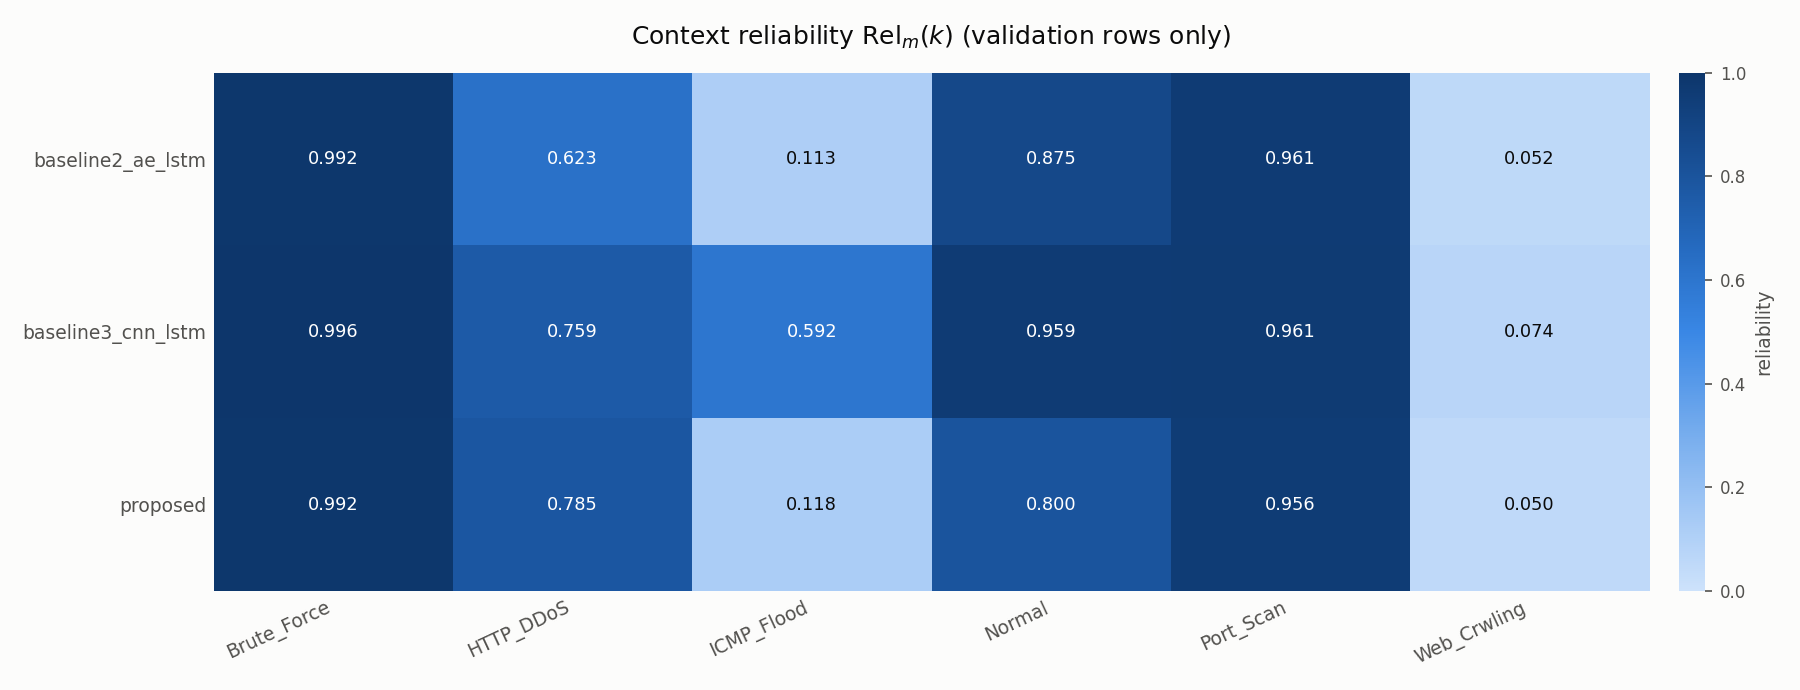

In [99]:
reliability = step13.get("reliability")
if reliability is not None and len(reliability):
    fusion.show_table(reliability, all_columns=True,
        note="`n_validation_rows` is what the shrinkage responds to: where it is "
             "small, `reliability` sits close to `macro_f1_global` rather than to "
             "the raw per-context figure.")

match = step13.get("probability_match")
if match is not None and len(match):
    fusion.show_table(match,
        note="Recomputed test probabilities against the Step 12 predictions.csv. "
             "A `[FAIL]` would mean the saved model is not the one that produced "
             "those predictions.")

picture = config.STEP13_OUTPUT_DIR / config.STEP13_FILES["chart_reliability"]
if picture.exists() and fusion.dl.in_notebook():
    from IPython.display import Image, display
    display(Image(filename=str(picture)))
elif not picture.exists():
    print("missing:", picture)

### 11.3 Per-flow confidence and dynamic weights

**Purpose** — Turn reliability and per-flow certainty into one weight per model
per flow.

**Input** — The reliabilities from 11.2 and each model's test-set distribution.

**Method** — $s_m = \mathrm{Rel}_m(k) \cdot \mathrm{Conf}_m$, normalised across
models; equal weights where $\sum_j s_j < \varepsilon$.

**Output** — `weights_summary.csv` and the mean-weight chart.

**Why** — The **spread** is the whole point. If the mean weights are flat and
their standard deviations are near zero, this is a fixed-weight ensemble wearing
a different name, and the comparison below will show it.

,grouping,group,model,rows,mean weight,std weight,min weight,max weight
0,context,Brute_Force,proposed,17811,0.345728,0.014417,0.174958,0.532269
1,context,Brute_Force,baseline2_ae_lstm,17811,0.303332,0.027841,0.218795,0.506834
2,context,Brute_Force,baseline3_cnn_lstm,17811,0.350940,0.020507,0.110492,0.401628
3,context,HTTP_DDoS,proposed,157,0.339188,0.052748,0.126955,0.527247
4,context,HTTP_DDoS,baseline2_ae_lstm,157,0.299725,0.032398,0.138712,0.447907
5,context,HTTP_DDoS,baseline3_cnn_lstm,157,0.361088,0.054420,0.121605,0.637996
6,context,ICMP_Flood,proposed,252,0.131672,0.015751,0.065196,0.192544
7,context,ICMP_Flood,baseline2_ae_lstm,252,0.136303,0.020265,0.102448,0.236622
8,context,ICMP_Flood,baseline3_cnn_lstm,252,0.732025,0.016686,0.645195,0.805785
9,context,Normal,proposed,4812,0.273022,0.057583,0.066675,0.476066


_Mean +- std of the weight each model received, grouped by the context the fusion assigned. Every group's mean weights sum to 1._

,grouping,group,model,rows,mean weight,std weight,min weight,max weight
18,true class,Brute_Force,proposed,17701,0.345538,0.013486,0.126955,0.527247
19,true class,Brute_Force,baseline2_ae_lstm,17701,0.303203,0.027583,0.218795,0.457535
20,true class,Brute_Force,baseline3_cnn_lstm,17701,0.351259,0.019717,0.110492,0.490176
21,true class,HTTP_DDoS,proposed,128,0.349135,0.025787,0.218273,0.399722
22,true class,HTTP_DDoS,baseline2_ae_lstm,128,0.295028,0.022375,0.272518,0.429879
23,true class,HTTP_DDoS,baseline3_cnn_lstm,128,0.355836,0.019844,0.265586,0.435700
24,true class,ICMP_Flood,proposed,9,0.164462,0.083160,0.133727,0.399664
25,true class,ICMP_Flood,baseline2_ae_lstm,9,0.145876,0.044987,0.128323,0.273051
26,true class,ICMP_Flood,baseline3_cnn_lstm,9,0.689662,0.128136,0.327285,0.737938
27,true class,Normal,proposed,5700,0.277432,0.071177,0.065196,0.532269


_The same weights grouped by the TRUE class instead. This is the diagnostic: it says whether the model that was listened to in a context is the one that was actually right there._

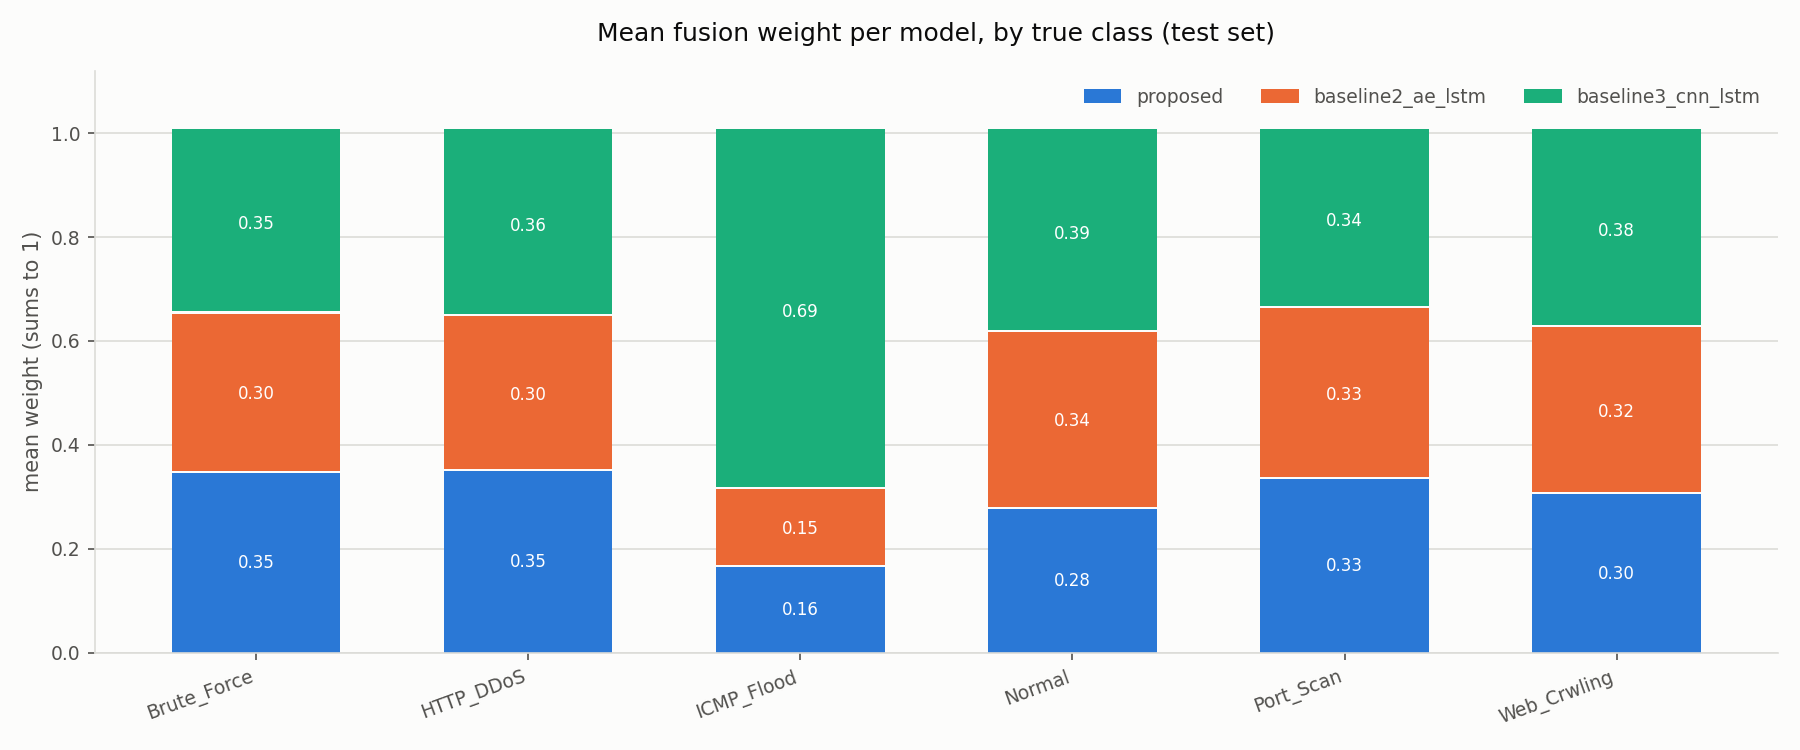

In [100]:
summary = step13.get("weights_summary")
if summary is not None and len(summary):
    by_context = summary[summary["grouping"] == "context"]
    by_class = summary[summary["grouping"] == "true class"]
    fusion.show_table(by_context, all_columns=True,
        note="Mean +- std of the weight each model received, grouped by the "
             "context the fusion assigned. Every group's mean weights sum to 1.")
    fusion.show_table(by_class, all_columns=True,
        note="The same weights grouped by the TRUE class instead. This is the "
             "diagnostic: it says whether the model that was listened to in a "
             "context is the one that was actually right there.")

picture = config.STEP13_OUTPUT_DIR / config.STEP13_FILES["chart_weights"]
if picture.exists() and fusion.dl.in_notebook():
    from IPython.display import Image, display
    display(Image(filename=str(picture)))
elif not picture.exists():
    print("missing:", picture)

### 11.4 Fused risk score $R_t$ and the decision threshold

**Purpose** — Reduce the fused distribution to one number per flow and decide
where to cut it.

**Input** — The fused $P(c \mid x)$ and the benign class codes.

**Method** — $R_t = 1 - \sum_{c \in B} P(c \mid x)$; $\tau$ chosen on the
**validation** risk scores by `THRESHOLD_RULE`, then applied unchanged to test.

**Output** — `fused_predictions.csv`, `threshold.json` and the risk
distribution chart.

**Why** — $R_t$ is the operational output: one score per flow that an analyst
can rank by. Choosing $\tau$ on validation is what keeps the reported FPR
honest — a threshold tuned on the test set would report a false-positive rate it
could never reproduce in service.

,metric,value
0,rule,max_f1
1,tau,0.943102
2,candidates considered,9669
3,validation precision,0.9980
4,validation recall,0.9929
5,validation F1,0.9954
6,validation FPR,0.0070
7,chosen on,the validation part of the Step 9 split


_Chosen on the validation part and applied unchanged to the test set. No test row took part in this choice._

,Orig_Row,y_true,y_true_label,r_proposed,r_baseline2_ae_lstm,r_baseline3_cnn_lstm,Rel_proposed,Rel_baseline2_ae_lstm,Rel_baseline3_cnn_lstm,Conf_proposed,Conf_baseline2_ae_lstm,Conf_baseline3_cnn_lstm,w_proposed,w_baseline2_ae_lstm,w_baseline3_cnn_lstm,context,P_Brute_Force,P_HTTP_DDoS,P_ICMP_Flood,P_Normal,P_Port_Scan,P_Web_Crwling,R_t,fused_class,fused_label,attack_decision
0,2,0,Brute_Force,0.870559,0.665756,0.974025,0.992177,0.991767,0.995967,0.630412,0.363530,0.664496,0.379577,0.218795,0.401628,Brute_Force,0.421941,0.346168,0.001251,0.132696,0.036230,0.061714,0.867304,0,Brute_Force,0
1,5,0,Brute_Force,0.999434,0.995769,0.997809,0.992177,0.991767,0.995967,0.996751,0.982697,0.988827,0.335421,0.330554,0.334025,Brute_Force,0.997362,0.000010,0.000005,0.002320,0.000067,0.000236,0.997680,0,Brute_Force,1
2,15,0,Brute_Force,0.999456,0.996042,0.997799,0.992177,0.991767,0.995967,0.996863,0.983474,0.988791,0.335362,0.330721,0.333917,Brute_Force,0.997452,0.000010,0.000005,0.002226,0.000067,0.000239,0.997774,0,Brute_Force,1
3,18,0,Brute_Force,0.999469,0.996035,0.997835,0.992177,0.991767,0.995967,0.996923,0.983394,0.988939,0.335368,0.330680,0.333953,Brute_Force,0.997465,0.000010,0.000005,0.002212,0.000067,0.000242,0.997788,0,Brute_Force,1
4,20,0,Brute_Force,0.988694,0.954702,0.998191,0.992177,0.991767,0.995967,0.911315,0.696428,0.926708,0.359110,0.274319,0.366571,Brute_Force,0.945410,0.003312,0.000069,0.017149,0.015909,0.018151,0.982851,0,Brute_Force,1
5,22,0,Brute_Force,0.988691,0.954687,0.998191,0.992177,0.991767,0.995967,0.911303,0.696469,0.926707,0.359102,0.274332,0.366566,Brute_Force,0.945414,0.003312,0.000069,0.017155,0.015909,0.018142,0.982845,0,Brute_Force,1
6,26,0,Brute_Force,0.999467,0.996004,0.997825,0.992177,0.991767,0.995967,0.996914,0.983325,0.988900,0.335378,0.330670,0.333953,Brute_Force,0.997452,0.000010,0.000005,0.002226,0.000067,0.000240,0.997774,0,Brute_Force,1
7,28,0,Brute_Force,0.999459,0.996160,0.997819,0.992177,0.991767,0.995967,0.996873,0.983765,0.988875,0.335322,0.330776,0.333902,Brute_Force,0.997495,0.000010,0.000005,0.002180,0.000067,0.000243,0.997820,0,Brute_Force,1


_The first eight test flows: each model's own risk `r_m`, its reliability and confidence, the weight it received, the fused distribution, `R_t` and the decision. 25,760 rows in all._

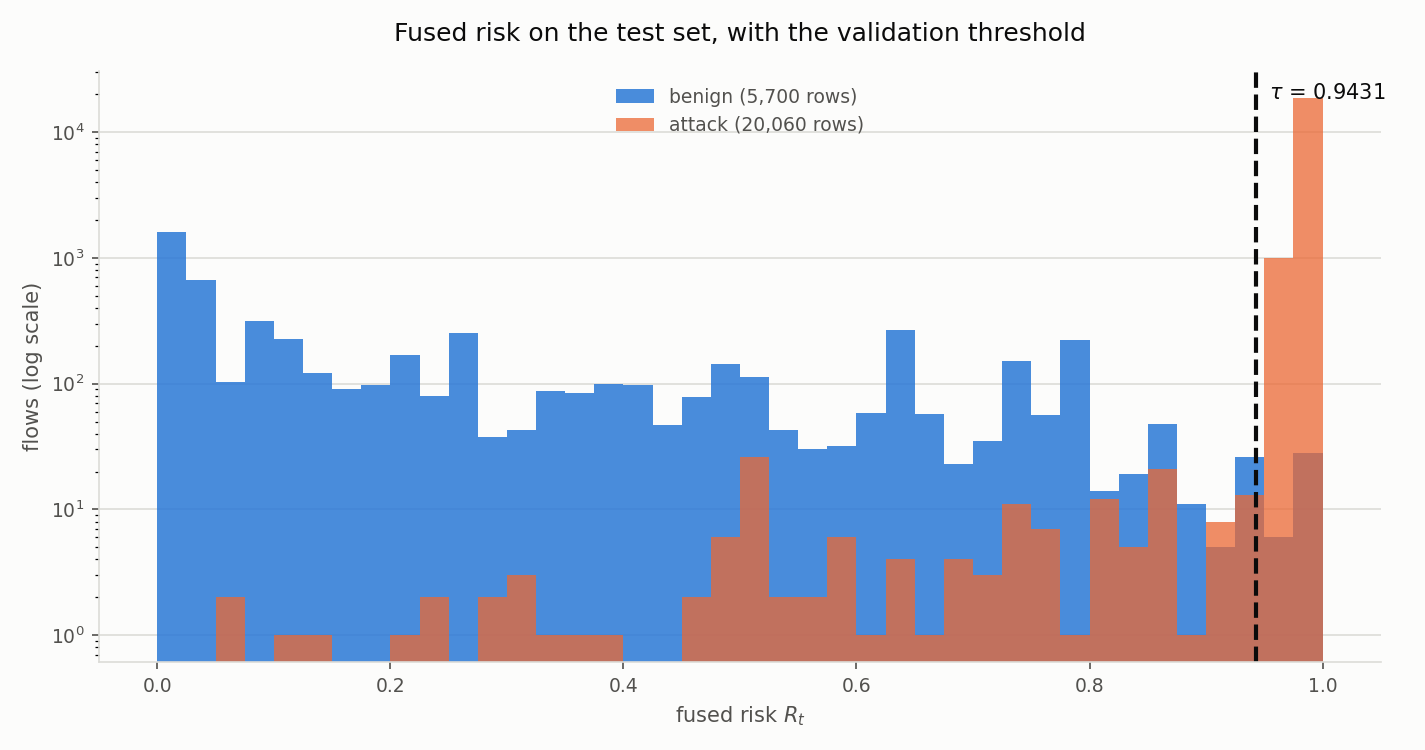

In [101]:
threshold = step13.get("threshold") or {}
if threshold:
    fusion.show_table(fusion.kv_table([
        ("rule", threshold.get("rule")),
        ("tau", "%.6f" % threshold.get("tau", float("nan"))),
        ("candidates considered", threshold.get("candidates")),
        ("validation precision", "%.4f" % threshold.get("validation_precision",
                                                        float("nan"))),
        ("validation recall", "%.4f" % threshold.get("validation_recall",
                                                     float("nan"))),
        ("validation F1", "%.4f" % threshold.get("validation_f1", float("nan"))),
        ("validation FPR", "%.4f" % threshold.get("validation_fpr", float("nan"))),
        ("chosen on", threshold.get("chosen_on")),
    ]), note="Chosen on the validation part and applied unchanged to the test "
             "set. No test row took part in this choice.")

predictions = step13.get("fused_predictions")
if predictions is not None and len(predictions):
    fusion.show_table(predictions.head(8), all_columns=True,
        note="The first eight test flows: each model's own risk `r_m`, its "
             "reliability and confidence, the weight it received, the fused "
             "distribution, `R_t` and the decision. %s rows in all."
             % f"{len(predictions):,}")

picture = config.STEP13_OUTPUT_DIR / config.STEP13_FILES["chart_risk"]
if picture.exists() and fusion.dl.in_notebook():
    from IPython.display import Image, display
    display(Image(filename=str(picture)))
elif not picture.exists():
    print("missing:", picture)

### 11.5 Comparison with single models and fixed fusion

**Purpose** — Say whether the adaptive weighting earns its keep.

**Input** — The same untouched test set, scored with the same Step 9
`evaluate()` helpers for every configuration.

**Method** — Each single model; three fixed-weight fusions (simple average,
majority vote with ties broken by the highest mean probability, and static
weights from the validation macro-F1); and the adaptive fusion.

**Output** — `comparison_table.csv`, `per_class_f1.csv` and the comparison bar
charts, full and duplicate-free.

**Why** — Lead with macro-F1 and G-mean rather than accuracy, and quote the
duplicate-free columns as the conservative estimate. A fusion that wins on
accuracy and loses on G-mean has not won: it has learned to agree with the
majority class.

> The majority-vote row takes its *class* from the vote and its *risk* from the
> simple average, because a vote produces no distribution to take a risk from.
> Its binary columns are therefore the simple average's; only its multiclass
> columns are the vote's.

,configuration,accuracy,precision (macro),recall (macro),F1 (macro),F1 (weighted),G-mean,ROC-AUC (macro OvR),binary F1,binary FPR,binary ROC-AUC,binary PR-AUC,F1 macro (dup-free),G-mean (dup-free),fusion overhead (ms/1k)
0,single: proposed,0.921040,0.632958,0.847681,0.613385,0.946131,0.836769,0.988512,0.964786,0.049649,0.992222,0.997451,0.586756,0.832310,NaN
1,single: baseline2_ae_lstm,0.946390,0.578119,0.873126,0.588319,0.961853,0.865000,0.986812,0.987721,0.053158,0.978791,0.990870,0.559806,0.862485,NaN
2,single: baseline3_cnn_lstm,0.980745,0.742746,0.841493,0.762519,0.985319,0.792570,0.992581,0.995553,0.007719,0.998685,0.999626,0.734222,0.787046,NaN
3,fixed: simple average,0.958152,0.628199,0.878765,0.630477,0.972300,0.871489,0.991458,0.995225,0.006491,0.997064,0.998996,0.609213,0.870795,NaN
4,fixed: majority vote,0.954775,0.630556,0.879994,0.631829,0.970051,0.872294,0.991458,0.995225,0.006491,0.997064,0.998996,0.612014,0.873359,NaN
5,fixed: static macro-F1 weights,0.958929,0.627757,0.876804,0.629837,0.972862,0.869699,0.991515,0.995225,0.006491,0.997163,0.999032,0.607624,0.867518,NaN
6,ADAPTIVE EVIDENCE FUSION,0.967547,0.713613,0.885854,0.737515,0.977663,0.878722,0.991585,0.995401,0.006491,0.997160,0.999019,0.715845,0.879132,1.432263


_Single models, fixed-weight fusion and adaptive fusion on the same untouched test set. `fusion overhead (ms/1k)` excludes the models' own inference time._

,Label,test rows,single: proposed,single: baseline2_ae_lstm,single: baseline3_cnn_lstm,fixed: simple average,fixed: majority vote,fixed: static macro-F1 weights,ADAPTIVE EVIDENCE FUSION
0,Brute_Force,17701,0.992675,0.992060,0.997207,0.995720,0.995327,0.995944,0.995581
1,Normal,5700,0.798575,0.874094,0.961193,0.905061,0.895454,0.907348,0.928671
2,Port_Scan,2216,0.965343,0.972235,0.966781,0.972401,0.973060,0.971731,0.973545
3,HTTP_DDoS,128,0.854015,0.620865,0.792079,0.835088,0.853147,0.826855,0.817869
4,ICMP_Flood,9,0.064257,0.058824,0.842105,0.061303,0.062257,0.063745,0.695652
5,Web_Crwling,6,0.005446,0.011834,0.015748,0.013289,0.011730,0.013400,0.013769


_Per-class F1 by configuration. `test rows` is the support; where it is ~5, a single flow changing hands moves the F1 a long way._

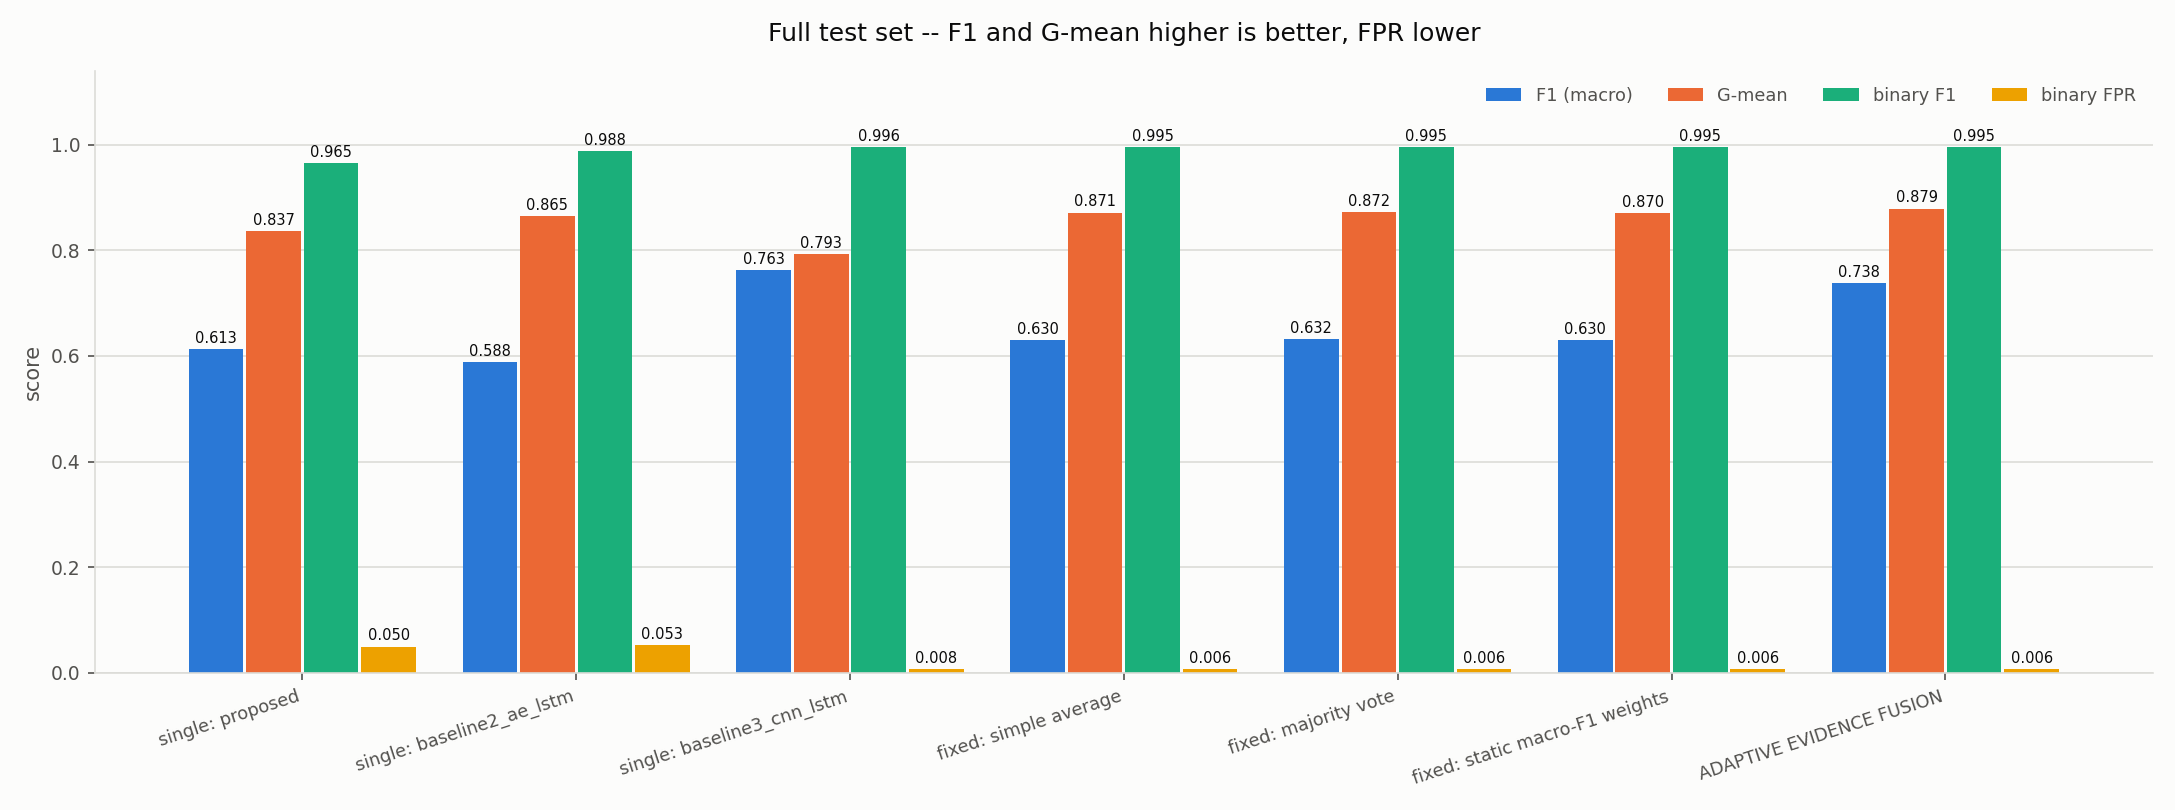

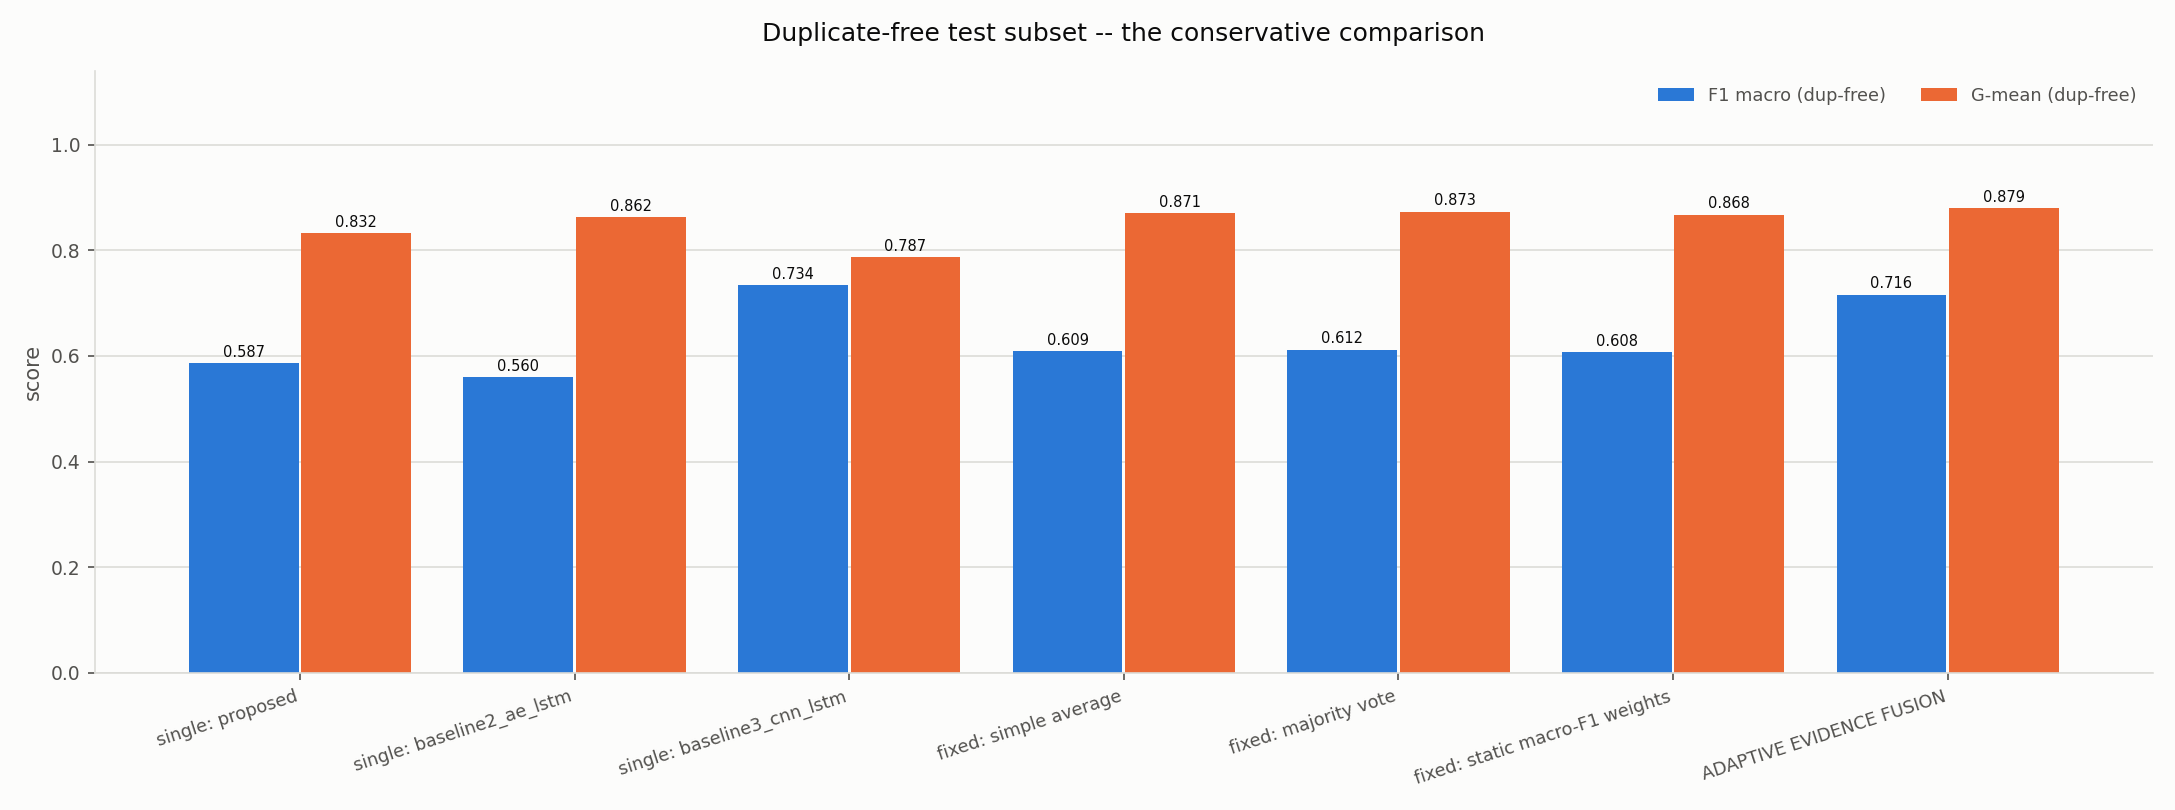

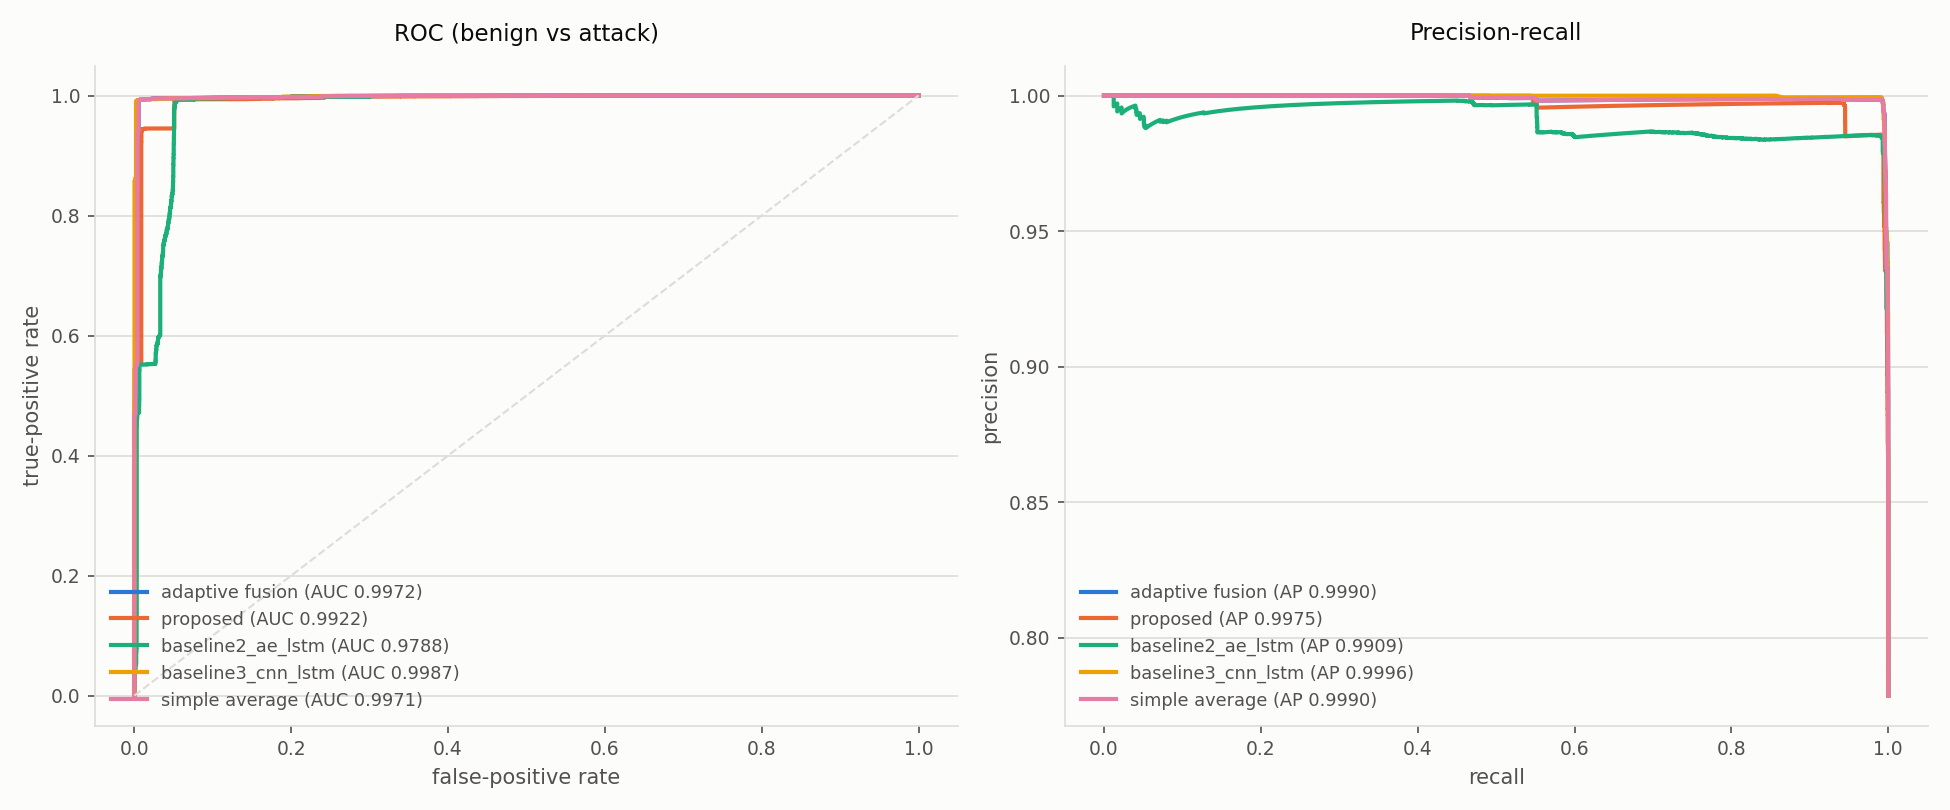

In [102]:
comparison = step13.get("comparison")
if comparison is not None and len(comparison):
    fusion.show_table(comparison, all_columns=True,
        note="Single models, fixed-weight fusion and adaptive fusion on the same "
             "untouched test set. `fusion overhead (ms/1k)` excludes the models' "
             "own inference time.")

per_class = step13.get("per_class")
if per_class is not None and len(per_class):
    fusion.show_table(per_class, all_columns=True,
        note="Per-class F1 by configuration. `test rows` is the support; where it "
             "is ~5, a single flow changing hands moves the F1 a long way.")

for key in ("chart_comparison", "chart_comparison_free", "chart_curves"):
    picture = config.STEP13_OUTPUT_DIR / config.STEP13_FILES[key]
    if picture.exists() and fusion.dl.in_notebook():
        from IPython.display import Image, display
        display(Image(filename=str(picture)))
    elif not picture.exists():
        print("missing:", picture)

### 11.6 Ablation study

**Purpose** — Attribute whatever the fusion achieves to the parts it is made
of.

**Input** — The same test probabilities, re-fused with one setting changed at a
time.

**Method** — Without the confidence term; without the context (global
reliability everywhere); the other `CONTEXT_MODE`; and softmax weights at
$T = 0.2$ and $T = 1.0$.

**Output** — `ablation_table.csv`.

**Why** — Each row removes exactly one ingredient, so a gap points at that
ingredient. Two readings matter: if *no confidence term* scores the same as the
default, the entropy term is decoration; if *no context* scores the same, the
per-context reliability is decoration. Either would be worth knowing, and
neither is hidden here.

> The `context = protocol` row needs the `Protocol` column in the Step 3
> metadata. If it is absent the row is **skipped and said to be skipped**, never
> guessed.

In [103]:
ablation = step13.get("ablation")
if ablation is not None and len(ablation):
    columns = ["ablation", "F1 (macro)", "G-mean", "ROC-AUC (macro OvR)",
               "binary F1", "binary FPR", "binary PR-AUC",
               "F1 macro (dup-free)"]
    fusion.show_table(ablation[[c for c in columns if c in ablation.columns]],
        all_columns=True,
        note="Row 1 is the default configuration; each later row changes exactly "
             "one setting. Compare each row against row 1, not against the "
             "single models.")

,ablation,F1 (macro),G-mean,ROC-AUC (macro OvR),binary F1,binary FPR,binary PR-AUC,F1 macro (dup-free)
0,"default (context = consensus_class, proportion...",0.737515,0.878722,0.991585,0.995401,0.006491,0.999019,0.715845
1,no confidence term,0.751978,0.876516,0.991666,0.995225,0.006491,0.999016,0.731065
2,no context (global reliability),0.628377,0.871735,0.991500,0.995401,0.006491,0.999047,0.606395
3,"softmax weights, T = 0.2",0.676081,0.874973,0.992706,0.995005,0.010702,0.999011,0.654899
4,"softmax weights, T = 1.0",0.630623,0.871681,0.991806,0.995225,0.006491,0.999011,0.609451


_Row 1 is the default configuration; each later row changes exactly one setting. Compare each row against row 1, not against the single models._

### 11.7 Summary

**Purpose** — State what the numbers above support, and nothing more.

**Input** — The comparison, ablation and weight tables just computed.

**Method** — The text below is composed by `fusion.step13_summary()` from those
tables: every figure in it is read off a computed table, and the direction of
every comparison (*above*, *level with*, *below*) is decided by the numbers
rather than written in advance.

**Output** — Rendered here and stored in `metrics.json`, so the resumable path
shows the same text.

**Why** — A summary written by hand drifts from the tables beside it as soon as
anything is re-run. One generated from the tables cannot.

In [104]:
text = (step13.get("metrics") or {}).get("summary")
if text:
    if fusion.dl.in_notebook():
        from IPython.display import Markdown, display
        display(Markdown(text))
    else:
        print(text)
else:
    print("No summary stored. Re-run with OVERWRITE_STEP13 = True.")

report = step13.get("report")
if report is not None and len(report):
    fusion.show_table(report, all_columns=True,
        note="Read back from disk after writing: row counts, weights summing to "
             "1, fused rows summing to 1 and R_t within [0, 1]. A `[FAIL]` here "
             "means the saved file is wrong, whatever the in-memory numbers said.")

### Step 13 - what the numbers say

- On the full test set, adaptive fusion scores **0.7375** macro-F1, **below** the best single model (single: baseline3_cnn_lstm, 0.7625) and above fixed-weight fusion (fixed: majority vote, 0.6318).
- On the duplicate-free subset, adaptive fusion scores **0.7158** macro-F1, **below** the best single model (single: baseline3_cnn_lstm, 0.7342) and above fixed-weight fusion (fixed: majority vote, 0.6120).
- At the validation threshold tau = **0.9431** (rule `max_f1`, chosen on validation and applied unchanged), the fused risk gives binary F1 **0.9954**, FPR **0.0065** and PR-AUC **0.9990** on the test set.
- Mean weight per model: `proposed` 0.329 +- 0.046, `baseline2_ae_lstm` 0.312 +- 0.042, `baseline3_cnn_lstm` 0.358 +- 0.051. The spread is what makes the fusion adaptive: a model whose weight never moves is being used like a fixed ensemble member.
- Ablations, as macro-F1 change from the default configuration: `no confidence term` +0.0145, `no context (global reliability)` -0.1091, `softmax weights, T = 0.2` -0.0614, `softmax weights, T = 1.0` -0.1069.
- Fusion overhead: **1.432 ms per 1,000 flows**, excluding the models' own inference time -- the weighting is arithmetic on three probability vectors, not another model.

**Read these with four caveats.**

1. The reliabilities come from the validation part of the Step 9 split, which Step 10 also used for early stopping, so they are slightly optimistic. A third split held out for fusion alone would be cleaner; with the smallest class as small as it is here there are not enough rows to estimate a per-context F1 from one.
2. The smallest class in the test set is `Web_Crwling` with **6 rows**, so any per-class figure for it moves a long way on one flow changing hands.
3. The duplicate-free columns cover **16,637 of 25,760** test rows: 35.4% of this test set has a feature vector that also occurs in training, so every full-test score is inflated by that much memorisable material. Those columns are the conservative comparison.
4. The best single model already reaches **0.7625** macro-F1 on the full test set, so there is some headroom above it; fusion cannot show a gain it has no room to make. The duplicate-free subset and the per-class table are where a difference, if there is one, shows up.

,check,result,detail
0,fused_predictions.csv exists,[OK],fused_predictions.csv
1,row count equals the test set,[OK],"25,760 rows, expected 25,760"
2,the weights of every flow sum to 1,[OK],max |sum - 1| = 1.000e-08 (tolerance 1e-6)
3,one fused probability column per class,[OK],6 columns for 6 classes
4,every fused distribution sums to 1,[OK],max |sum - 1| = 1.700e-07 (tolerance 1e-6)
5,"R_t lies in [0, 1]",[OK],"min 0.005078, max 0.999262"
6,the attack decision is R_t >= tau,[OK],"tau = 0.943102, 19,950 flows flagged"
7,"every reliability lies in [0, 1]",[OK],"18 rows, min 0.049817, max 0.995967"
8,the comparison table holds every configuration,[OK],7 rows
9,threshold.json records the validation threshold,[OK],"tau = 0.943102, rule = max_f1"


_Read back from disk after writing: row counts, weights summing to 1, fused rows summing to 1 and R_t within [0, 1]. A `[FAIL]` here means the saved file is wrong, whatever the in-memory numbers said._

### What Step 11 can and cannot say

1. **The reliabilities are slightly optimistic.** They are measured on the
   validation part, which Step 8 also used for early stopping. Treat the
   reliability table as a well-founded ordering of the models per context, not as
   an unbiased estimate of their F1.
2. **It cannot beat a ceiling that is already reached.** Where the single models
   are near-perfect on the full test set, the fused score has nowhere to go. The
   duplicate-free subset and the per-class table are where a real difference
   shows up, which is why both are quoted.
3. **Fusion adds no new information.** It re-weights what three models already
   said. If all three fail on a class, no weighting recovers it — the per-class
   table shows that directly.
4. **The context is a consensus, not a ground truth.** `k(x)` is the models' own
   agreement, so a flow all three misread is weighted by the reliability of the
   wrong context. That is the cost of a label-free context, and it is why the
   protocol-based alternative is run as an ablation rather than dismissed.
5. **$R_t$ is one number, and one number loses detail.** It answers "how
   suspicious is this flow", not "what is it". The multiclass columns and the
   fused class in `fused_predictions.csv` are what answer the second question.
6. **One split, one seed.** Every figure here comes from a single train/test
   split and the models trained in Steps 8 and 10. The ablation differences are
   single observations, not significance tests, and none is claimed.

---

### 11.8 Fusion across all approaches and baselines (Step 11 addendum)

**Purpose** — Step 11 fused three models and answered *can imperfect models be
combined so that each is listened to where it is strong?*. Two questions it did
not answer: what happens when **every** configuration that exists on disk is
offered to the same fusion, and what happens when the fusion is given a
**subset chosen on the validation split**?

**Input** — The saved model and feature pipeline of every configuration in
`config.FUSION_ALL_MODELS`, the Step 7 validation split, the untouched test set,
and — for the F3 row — the Step 11 `metrics.json` already on disk.

**Method** — The Step 11 arithmetic, *called* rather than copied:
`fusion.build_reliability`, `fusion.fuse_once`, `fusion.choose_threshold`,
`fusion.score_probabilities`. `src/mscad/fusion_all.py` adds only what Step 11
has no reason to own: loaders for the three models it cannot load itself
(Approach 2, B4, B5), a diversity check, the greedy subset search and the
tables.

**Output** — `C:\MSCAD2022\outputs\step13_all\` — a folder of its own.

> **Nothing in Step 11 changes.** `FUSION_MODELS` still names Approach 1, B2 and
> B3; every file in `step13\` is SHA-256 fingerprinted before this section runs
> and again afterwards, and the comparison below prints `[OK] existing Step 11
> outputs unchanged`. Step 12 still explains that three-model fusion.

> **Nothing is retrained.** Each model is read from the folder its own step
> wrote. A configuration that has not been trained on this machine is
> **skipped by name**, with the cells that produce it, and the fusion continues
> with the rest.

**Three variants, and the fixed baselines they are judged against**

| row | what it is |
|---|---|
| **F3** | the existing Step 11 fusion (Approach 1 + B2 + B3), **read from `step13\metrics.json`** |
| **FALL** | adaptive fusion over every available configuration |
| **FSEL** | adaptive fusion over a subset chosen by greedy forward selection on **validation** macro-F1 |
| fixed | simple average, majority vote and static macro-F1 weights, over all available models |

**Every learned quantity comes from validation.** The reliabilities, each
variant's own $\tau$ **and the choice of which models to include** are decided
on the validation part of the Step 7 split. `greedy_forward_selection` is not
given the test probabilities at all. The test set is scored once, at the end.

> **Computed before Baseline 6 was added.** The tables and figures in this section cover the configurations that existed when it last ran. To include **B6: AE -> PCA -> CNN-LSTM**, set `OVERWRITE_STEP13ALL = True` in `config.py` and re-run this section; `FUSION_ALL_MODELS` already lists it.
>
> Check Step 10.0's provenance report first: if it found that this section was computed from **different Approach 1 predictions** than the ones on disk now, re-running is not optional -- the numbers here describe a model that has since changed.

In [105]:
# Quieten TensorFlow's C++ logger for this section only.
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

from src.mscad import fusion_all

fusion_all.show_table(fusion_all.kv_table([
    ("output folder", str(config.STEP13ALL_OUTPUT_DIR)),
    ("configurations offered", len(config.FUSION_ALL_MODELS)),
    ("Step 13 fusion (unchanged)", ", ".join(config.FUSION_MODELS)),
    ("SUBSET_SELECTION", config.SUBSET_SELECTION),
    ("SUBSET_MAX_MODELS", config.SUBSET_MAX_MODELS),
    ("SUBSET_METRIC", "%s (on validation)" % config.SUBSET_METRIC),
    ("weights / context", "%s / %s" % (config.WEIGHT_MODE, config.CONTEXT_MODE)),
    ("shrinkage K / confidence", "%s / %s" % (config.SHRINKAGE_K,
                                              config.CONFIDENCE_TERM)),
    ("threshold rule", config.THRESHOLD_RULE),
    ("OVERWRITE_STEP13ALL", config.OVERWRITE_STEP13ALL),
]), note="Every fusion setting is the Step 13 block's, unchanged: FALL and "
         "FSEL differ from F3 only in which models they are given.")

fusion_all.show_table(pd.DataFrame(
    [{"#": i + 1, "internal key": key, "display label": label}
     for i, (key, label) in enumerate(config.STEP12_DISPLAY_ORDER)]),
    note="`FUSION_ALL_MODELS` holds these internal keys; "
         "`fusion_all.model_keys()` verifies them against "
         "`STEP12_DISPLAY_ORDER` before anything is loaded.")

,metric,value
0,output folder,C:\MSCAD2022\outputs_official\step13_all
1,configurations offered,8
2,Step 13 fusion (unchanged),"proposed, baseline2_ae_lstm, baseline3_cnn_lstm"
3,SUBSET_SELECTION,greedy_forward
4,SUBSET_MAX_MODELS,4
5,SUBSET_METRIC,macro_f1 (on validation)
6,weights / context,proportional / consensus_class
7,shrinkage K / confidence,20 / True
8,threshold rule,max_f1
9,OVERWRITE_STEP13ALL,False


_Every fusion setting is the Step 13 block's, unchanged: FALL and FSEL differ from F3 only in which models they are given._

,#,internal key,display label
0,1,proposed,Approach 1: FS -> AE -> CNN-LSTM
1,2,approach2_attention,Approach 2: FS -> AE -> CNN-Attention-LSTM
2,3,baseline1_ae_cnn_lstm,B1: AE -> CNN-LSTM (no selection)
3,4,baseline2_ae_lstm,B2: AE -> LSTM (no CNN)
4,5,baseline3_cnn_lstm,B3: CNN-LSTM (no AE)
5,6,baseline4_ae_pca_lstm,B4: AE -> PCA -> LSTM
6,7,baseline5,B5: MI-only top 30 -> AE -> CNN-LSTM
7,8,baseline6_ae_pca_cnn_lstm,B6: AE -> PCA -> CNN-LSTM


_`FUSION_ALL_MODELS` holds these internal keys; `fusion_all.model_keys()` verifies them against `STEP12_DISPLAY_ORDER` before anything is loaded._

### Run the addendum

One status line per configuration as it is loaded, then the diversity tables,
the greedy search and the comparison. Nothing is trained: with
`OVERWRITE_STEP13ALL = False` a finished run is read straight back from disk.

In [106]:
step13_all = fusion_all.run_step13all()

,metric,value
0,status,loaded from disk (OVERWRITE_STEP13ALL = False)
1,folder,C:\MSCAD2022\outputs_official\step13_all
2,models fused,"Approach 1: FS -> AE -> CNN-LSTM, Approach 2: ..."
3,subset chosen,"B1: AE -> CNN-LSTM (no selection), B3: CNN-LST..."
4,variants compared,13


_Set `OVERWRITE_STEP13ALL = True` in config.py to recompute._

### 11.8.1 Data and alignment

**Purpose** — Say which models are in, and prove every one of them describes
the same flows in the same order.

**Input** — Each model's validation probabilities (its own feature pipeline,
applied to the Step 7 validation rows) and test probabilities.

**Method** — The recomputed test probabilities are compared against each
configuration's saved `predictions.csv` to **1e-6**: a mismatch would mean the
saved model is not the one that produced those predictions. Then
`fusion.check_alignment` asserts the rows and the class order agree.

**Output** — `model_availability.csv`, and the `[OK]` lines above.

In [107]:
availability = step13_all.get("availability")
if availability is not None and len(availability):
    fusion_all.show_table(availability, all_columns=True,
        note="`validation macro-F1` and `validation G-mean` are each model on "
             "its own, on the validation rows -- the figures the greedy search "
             "starts from. A row with `available = False` was skipped, and its "
             "note says which cells produce it.")

alignment = step13_all.get("alignment")
if alignment is not None and len(alignment):
    fusion_all.show_table(alignment, all_columns=True,
        note="Fusing frames that disagree about row order would produce numbers "
             "that look fine and mean nothing, so this raises rather than "
             "warning.")

,model,key,available,features into the classifier,loaded from,note,validation macro-F1,validation G-mean
0,Approach 1: FS -> AE -> CNN-LSTM,proposed,True,15,fusion.load_model_bundle,NaN,0.606294,0.722257
1,Approach 2: FS -> AE -> CNN-Attention-LSTM,approach2_attention,True,15,models_attention.load_step10b,NaN,0.607267,0.722158
2,B1: AE -> CNN-LSTM (no selection),baseline1_ae_cnn_lstm,True,15,fusion.load_model_bundle,NaN,0.606672,0.758753
3,B2: AE -> LSTM (no CNN),baseline2_ae_lstm,True,15,fusion.load_model_bundle,NaN,0.585953,0.746329
4,B3: CNN-LSTM (no AE),baseline3_cnn_lstm,True,67,fusion.load_model_bundle,NaN,0.715084,0.766335
5,B4: AE -> PCA -> LSTM,baseline4_ae_pca_lstm,True,6,baseline4 folder (encoder + pca.joblib + model),NaN,0.627958,0.746346
6,B5: MI-only top 30 -> AE -> CNN-LSTM,baseline5,True,15,baseline5 folder (MI list + encoder + model),NaN,0.546778,0.745244
7,B6: AE -> PCA -> CNN-LSTM,baseline6_ae_pca_cnn_lstm,False,0,NaN,B6: AE -> PCA -> CNN-LSTM not available -- no ...,NaN,NaN


_`validation macro-F1` and `validation G-mean` are each model on its own, on the validation rows -- the figures the greedy search starts from. A row with `available = False` was skipped, and its note says which cells produce it._

### 11.8.2 Diversity check (validation only)

**Purpose** — Ask, before any fusion, whether these models actually disagree.

**Input** — The validation probabilities only.

**Method** — Pairwise **disagreement rate** (the share of validation flows where
the predicted class differs) and pairwise **Pearson correlation of the attack
risk** $r_m$.

**Output** — `diversity_disagreement.csv`, `diversity_risk_corr.csv`,
`diversity_heatmap.png`.

**Why it matters.** Fusion can only help where models make *different* mistakes.
Two models that almost always agree add weight to an opinion the fusion already
has: a pair at 0.00 disagreement is interchangeable here, and no weighting
scheme can extract information that is not there. Highly correlated risks move
together, so shifting weight between them changes little.

,model,Approach 1: FS -> AE -> CNN-LSTM,Approach 2: FS -> AE -> CNN-Attention-LSTM,B1: AE -> CNN-LSTM (no selection),B2: AE -> LSTM (no CNN),B3: CNN-LSTM (no AE),B4: AE -> PCA -> LSTM,B5: MI-only top 30 -> AE -> CNN-LSTM
0,Approach 1: FS -> AE -> CNN-LSTM,0.000000,0.027562,0.064635,0.047651,0.071817,0.044934,0.082104
1,Approach 2: FS -> AE -> CNN-Attention-LSTM,0.027562,0.000000,0.068129,0.053183,0.073855,0.051145,0.079290
2,B1: AE -> CNN-LSTM (no selection),0.064635,0.068129,0.000000,0.033385,0.032803,0.048040,0.033191
3,B2: AE -> LSTM (no CNN),0.047651,0.053183,0.033385,0.000000,0.046487,0.035908,0.055804
4,B3: CNN-LSTM (no AE),0.071817,0.073855,0.032803,0.046487,0.000000,0.047651,0.047263
5,B4: AE -> PCA -> LSTM,0.044934,0.051145,0.048040,0.035908,0.047651,0.000000,0.073078
6,B5: MI-only top 30 -> AE -> CNN-LSTM,0.082104,0.079290,0.033191,0.055804,0.047263,0.073078,0.000000


_Share of validation flows where the two models predict a different class. 0.00 means interchangeable on these rows._

,model,Approach 1: FS -> AE -> CNN-LSTM,Approach 2: FS -> AE -> CNN-Attention-LSTM,B1: AE -> CNN-LSTM (no selection),B2: AE -> LSTM (no CNN),B3: CNN-LSTM (no AE),B4: AE -> PCA -> LSTM,B5: MI-only top 30 -> AE -> CNN-LSTM
0,Approach 1: FS -> AE -> CNN-LSTM,1.000000,0.976876,0.934731,0.925837,0.886804,0.898599,0.898060
1,Approach 2: FS -> AE -> CNN-Attention-LSTM,0.976876,1.000000,0.955995,0.934142,0.894703,0.909678,0.935148
2,B1: AE -> CNN-LSTM (no selection),0.934731,0.955995,1.000000,0.967964,0.928428,0.940653,0.952994
3,B2: AE -> LSTM (no CNN),0.925837,0.934142,0.967964,1.000000,0.920685,0.939072,0.935691
4,B3: CNN-LSTM (no AE),0.886804,0.894703,0.928428,0.920685,1.000000,0.947205,0.904901
5,B4: AE -> PCA -> LSTM,0.898599,0.909678,0.940653,0.939072,0.947205,1.000000,0.911765
6,B5: MI-only top 30 -> AE -> CNN-LSTM,0.898060,0.935148,0.952994,0.935691,0.904901,0.911765,1.000000


_Pearson correlation of the attack risk r_m on the same rows. `NaN` means one model's risk is constant, so there is no correlation to report._

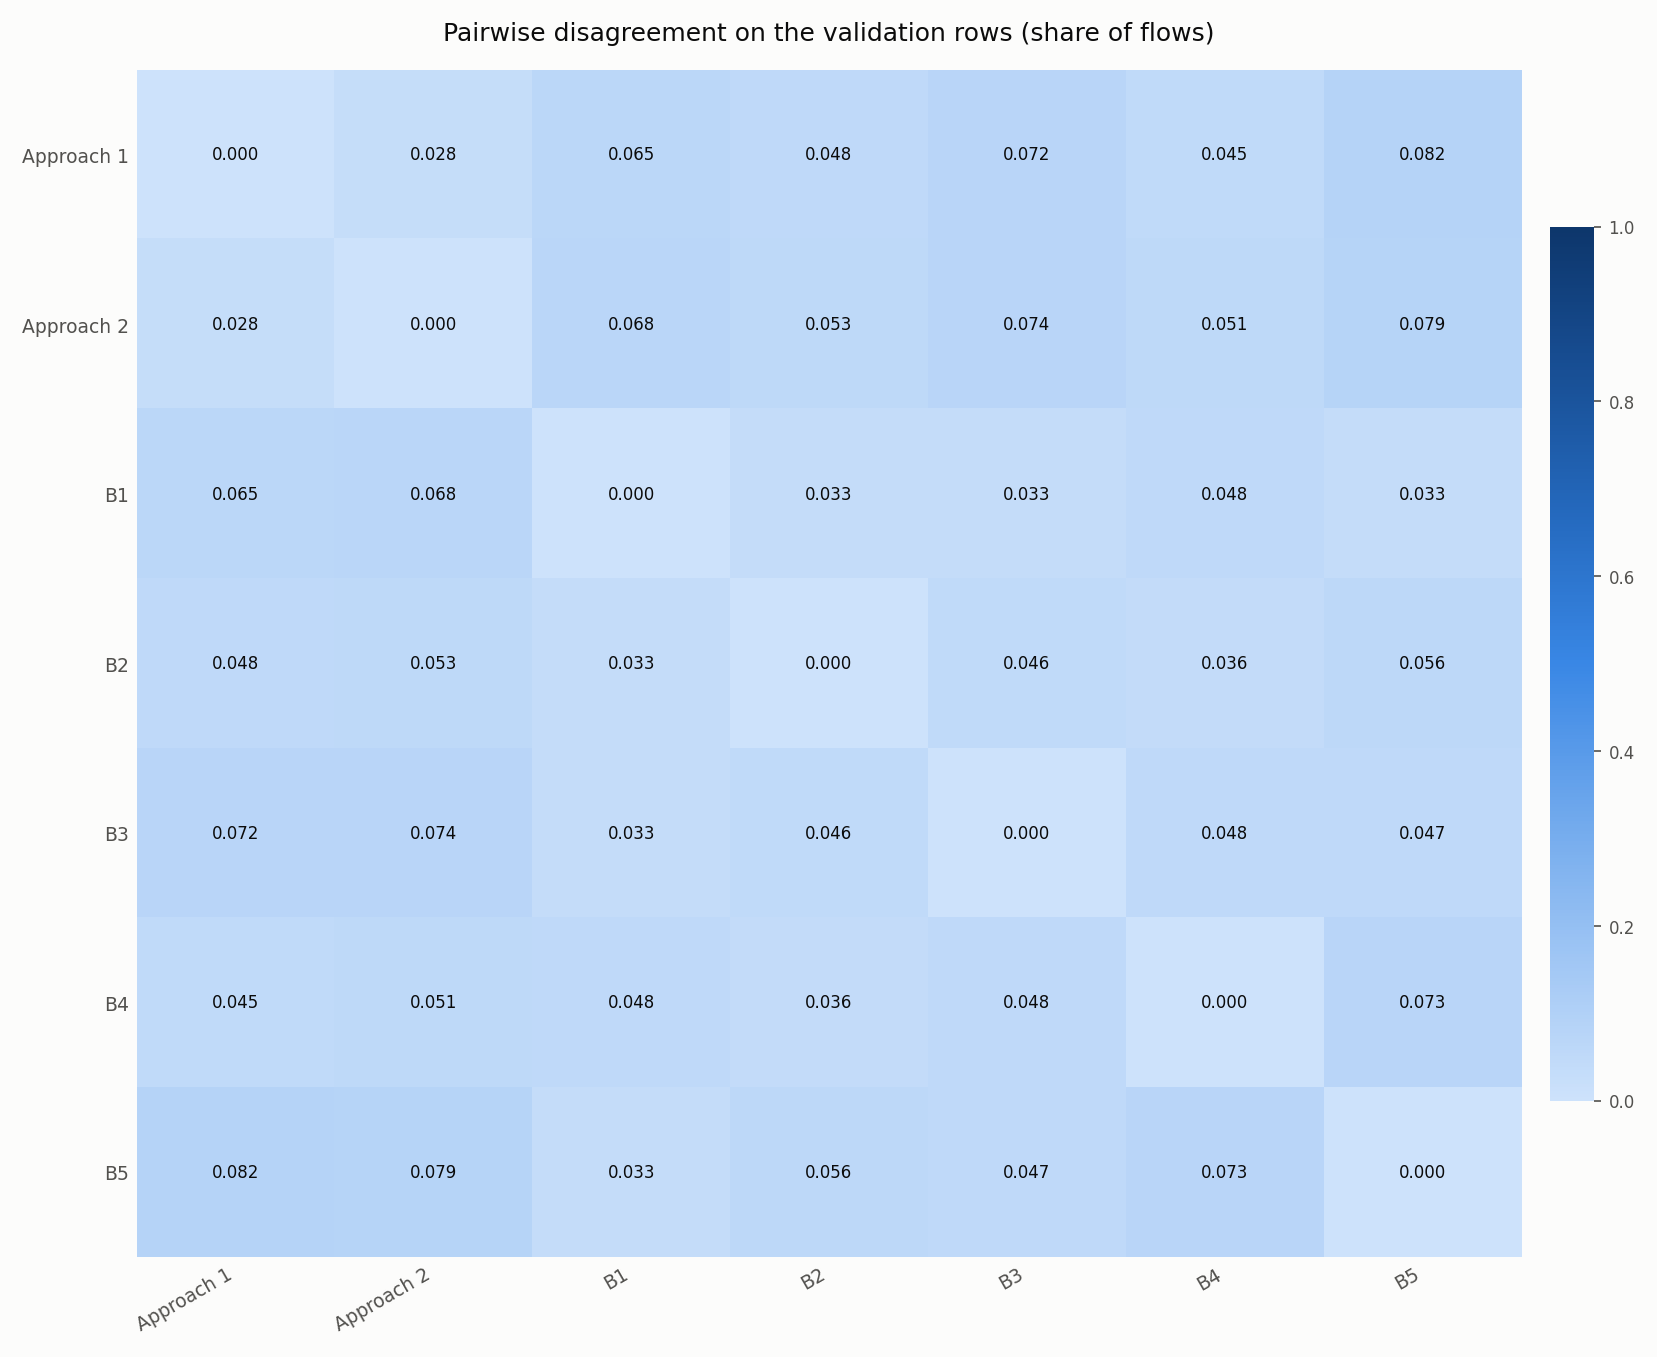

In [108]:
for key, note in (
        ("disagreement",
         "Share of validation flows where the two models predict a different "
         "class. 0.00 means interchangeable on these rows."),
        ("risk_corr",
         "Pearson correlation of the attack risk r_m on the same rows. `NaN` "
         "means one model's risk is constant, so there is no correlation to "
         "report.")):
    grid = step13_all.get(key)
    if grid is not None and len(grid):
        fusion_all.show_table(grid.reset_index(), all_columns=True, note=note)

picture = (config.STEP13ALL_OUTPUT_DIR
           / config.STEP13ALL_FILES["chart_diversity"])
if picture.exists() and fusion_all.dl.in_notebook():
    from IPython.display import Image, display
    display(Image(filename=str(picture)))
elif not picture.exists():
    print("missing:", picture)

### 11.8.3 Fusion variants and the subset search

**Purpose** — Build FALL and FSEL, and record how FSEL's subset was chosen.

**Method** — Greedy forward selection, on the **validation** split only: start
with the best single model, then add whichever remaining model most improves the
**validation** macro-F1 of the adaptive fusion. Stop when nothing improves it or
`SUBSET_MAX_MODELS` is reached. Candidates are tried in `STEP12_DISPLAY_ORDER`
and a candidate must beat the incumbent by more than `EPSILON`, so the search is
deterministic.

**Output** — `subset_selection_path.csv` (every candidate tried, its validation
score and whether it was added), `reliability_table_all.csv`,
`thresholds_all.json`.

Each variant gets **its own $\tau$**, chosen on its own validation risk: judging
a fixed baseline at the adaptive fusion's threshold would hand the comparison to
whichever variant that threshold happened to suit.

In [109]:
path = step13_all.get("selection_path")
if path is not None and len(path):
    fusion_all.show_table(path, all_columns=True,
        note="`tried` rows are the candidates considered at that step; `ADDED` "
             "is the one kept. Every number here is a VALIDATION score -- the "
             "search is never shown a test row.")

reliability = step13_all.get("reliability")
if reliability is not None and len(reliability):
    fusion_all.show_table(reliability, all_columns=True,
        note="Rel_m(k) for the FALL models, measured on the validation part and "
             "shrunk towards each model's global macro-F1 with K = %d."
             % config.SHRINKAGE_K)

thresholds = (step13_all.get("metrics") or {}).get("variants") or {}
if thresholds:
    fusion_all.show_table(pd.DataFrame([
        {"variant": tag,
         "models": len(block.get("keys", [])),
         "tau": round(float((block.get("threshold") or {}).get("tau", float("nan"))), 6),
         "validation F1 at tau": round(float((block.get("threshold") or {})
                                             .get("validation_f1", float("nan"))), 4),
         "validation FPR at tau": round(float((block.get("threshold") or {})
                                              .get("validation_fpr", float("nan"))), 4),
         "validation macro-F1 of the fusion":
             round(float((block.get("validation_scores") or {})
                         .get("macro_f1", float("nan"))), 4)}
        for tag, block in thresholds.items()]), all_columns=True,
        note="Each variant's own threshold, chosen on the validation risk and "
             "then applied unchanged to the test set.")

,step,model added,key added,models in subset,validation macro_f1,improvement,decision
0,1,B3: CNN-LSTM (no AE),baseline3_cnn_lstm,1,0.715084,0.715084,best single model on validation
1,2,Approach 1: FS -> AE -> CNN-LSTM,proposed,2,0.682598,-0.032486,tried
2,2,Approach 2: FS -> AE -> CNN-Attention-LSTM,approach2_attention,2,0.707711,-0.007373,tried
3,2,B1: AE -> CNN-LSTM (no selection),baseline1_ae_cnn_lstm,2,0.724539,0.009454,ADDED
4,2,B2: AE -> LSTM (no CNN),baseline2_ae_lstm,2,0.638634,-0.076450,tried
5,2,B4: AE -> PCA -> LSTM,baseline4_ae_pca_lstm,2,0.667054,-0.048031,tried
6,2,B5: MI-only top 30 -> AE -> CNN-LSTM,baseline5,2,0.721749,0.006664,tried
7,3,Approach 1: FS -> AE -> CNN-LSTM,proposed,3,0.717902,-0.006637,tried
8,3,Approach 2: FS -> AE -> CNN-Attention-LSTM,approach2_attention,3,0.720577,-0.003962,tried
9,3,B2: AE -> LSTM (no CNN),baseline2_ae_lstm,3,0.710334,-0.014205,tried


_`tried` rows are the candidates considered at that step; `ADDED` is the one kept. Every number here is a VALIDATION score -- the search is never shown a test row._

,model,context,context_key,n_validation_rows,f1_in_context,macro_f1_global,reliability
0,proposed,Brute_Force,0,7138,0.993261,0.606294,0.992180
1,proposed,HTTP_DDoS,1,78,0.841121,0.606294,0.793198
2,proposed,ICMP_Flood,2,93,0.034188,0.606294,0.135446
3,proposed,Normal,3,1913,0.801882,0.606294,0.799858
4,proposed,Port_Scan,4,858,0.963678,0.606294,0.955537
5,proposed,Web_Crwling,5,224,0.003636,0.606294,0.053035
6,approach2_attention,Brute_Force,0,7138,0.994448,0.607267,0.993366
7,approach2_attention,HTTP_DDoS,1,78,0.841121,0.607267,0.793396
8,approach2_attention,ICMP_Flood,2,93,0.040816,0.607267,0.141073
9,approach2_attention,Normal,3,1913,0.801875,0.607267,0.799861


_Rel_m(k) for the FALL models, measured on the validation part and shrunk towards each model's global macro-F1 with K = 20._

,variant,models,tau,validation F1 at tau,validation FPR at tau,validation macro-F1 of the fusion
0,FALL,7,0.881881,0.9957,0.0101,0.6758
1,FSEL,3,0.936385,0.9961,0.0070,0.7415


_Each variant's own threshold, chosen on the validation risk and then applied unchanged to the test set._

### 11.8.4 Comparison on the untouched test set

**Purpose** — Put every single model, the fixed-weight fusions, F3, FALL and
FSEL in one table, scored once.

**Method** — `fusion.score_probabilities` — Step 9's evaluator — for every row.
F3 is **not recomputed**: its row is read from `step13\metrics.json`, so the
Step 11 numbers here are the Step 11 numbers in the write-up.

**Output** — `comparison_table_all.csv`, `marked_comparison_table_all.csv`,
`per_class_f1_all.csv`, `per_class_f1_duplicate_free_all.csv`,
`mean_weight_per_class_*.csv`, `fused_predictions_all.csv`, and the charts.

`*` marks the best value in a column, on **every** tied row. Lower is better for
the binary FPR and the fusion overhead.

In [110]:
marked = step13_all.get("comparison_marked")
if marked is not None and len(marked):
    fusion_all.show_table(marked, all_columns=True,
        note="Every available single model, the fixed-weight fusions over all "
             "of them, F3 (read from disk) and the two adaptive variants. The "
             "duplicate-free columns are the conservative comparison: they "
             "exclude test rows whose exact feature vector also occurs in "
             "training.")

for key, scope in (("per_class", "full test set"),
                   ("per_class_free", "duplicate-free subset")):
    frame = step13_all.get(key)
    if frame is not None and len(frame):
        fusion_all.show_table(frame, all_columns=True,
            note="Per-class F1 on the %s. `test rows` is the support -- a class "
                 "with a handful of rows moves in large steps." % scope)

,configuration,accuracy,precision (macro),recall (macro),F1 (macro),F1 (weighted),G-mean,ROC-AUC (macro OvR),binary F1,binary FPR,binary ROC-AUC,binary PR-AUC,F1 macro (dup-free),G-mean (dup-free),fusion overhead (ms/1k)
0,Approach 1: FS -> AE -> CNN-LSTM,0.9210,0.6330,0.8477,0.6134,0.9461,0.8368,0.9885,0.9891,0.0539,0.9922,0.9975,0.5868,0.8323,NaN
1,Approach 2: FS -> AE -> CNN-Attention-LSTM,0.9175,0.6316,0.8444,0.6118,0.9439,0.8330,0.9855,0.9899,0.0486,0.9946,0.9984,0.5842,0.8268,NaN
2,B1: AE -> CNN-LSTM (no selection),0.9713,0.5886,0.8019,0.6088,0.9772,0.6971,0.9923,0.9950,0.0119,0.9979,0.9994,0.5766,0.6869,NaN
3,B2: AE -> LSTM (no CNN),0.9464,0.5781,0.8731,0.5883,0.9619,0.8650,0.9868,0.9885,0.0556,0.9788,0.9909,0.5598,0.8625,NaN
4,B3: CNN-LSTM (no AE),0.9807,0.7427,0.8415,0.7625,0.9853*,0.7926,0.9926,0.9955,0.0044*,0.9987,0.9996,0.7342,0.7870,NaN
5,B4: AE -> PCA -> LSTM,0.9476,0.6286,0.8699,0.6576,0.9643,0.8623,0.9918,0.9945,0.0142,0.9978,0.9994,0.6290,0.8580,NaN
6,B5: MI-only top 30 -> AE -> CNN-LSTM,0.9526,0.5268,0.7869,0.5492,0.9612,0.6855,0.9873,0.9887,0.0326,0.9901,0.9956,0.5084,0.6623,NaN
7,fixed: simple average (all models),0.9569,0.5960,0.8742,0.6085,0.9701,0.8672,0.9918,0.9954,0.0091,0.9985,0.9996,0.5811,0.8591,0.3184*
8,fixed: majority vote (all models),0.9556,0.5952,0.8732,0.6072,0.9695,0.8662,0.9918,0.9954,0.0091,0.9985,0.9996,0.5794,0.8581,NaN
9,fixed: static macro-F1 weights (all models),0.9571,0.5955,0.8744,0.6082,0.9703,0.8674,0.9918,0.9954,0.0091,0.9985,0.9996,0.5806,0.8592,0.5664


_Every available single model, the fixed-weight fusions over all of them, F3 (read from disk) and the two adaptive variants. The duplicate-free columns are the conservative comparison: they exclude test rows whose exact feature vector also occurs in training._

,Label,test rows,Approach 1: FS -> AE -> CNN-LSTM,Approach 2: FS -> AE -> CNN-Attention-LSTM,B1: AE -> CNN-LSTM (no selection),B2: AE -> LSTM (no CNN),B3: CNN-LSTM (no AE),B4: AE -> PCA -> LSTM,B5: MI-only top 30 -> AE -> CNN-LSTM,fixed: simple average (all models),fixed: majority vote (all models),fixed: static macro-F1 weights (all models),"FALL: adaptive fusion, all available models","FSEL: adaptive fusion, validation-chosen subset"
0,Brute_Force,17701,0.992675,0.993623,0.993621,0.992060,0.997207,0.994627,0.991879,0.994936,0.995272,0.995188,0.994769,0.996141
1,Normal,5700,0.798575,0.786716,0.939030,0.874094,0.961193,0.878596,0.906099,0.902214,0.898656,0.902631,0.920762,0.964662
2,Port_Scan,2216,0.965343,0.962912,0.968981,0.972235,0.966781,0.965644,0.896035,0.968294,0.968294,0.967623,0.966282,0.955449
3,HTTP_DDoS,128,0.854015,0.847826,0.661017,0.620865,0.792079,0.653846,0.413428,0.694362,0.690265,0.692308,0.690265,0.815331
4,ICMP_Flood,9,0.064257,0.074766,0.076190,0.058824,0.842105,0.444444,0.075472,0.077670,0.078049,0.077670,0.727273,0.941176
5,Web_Crwling,6,0.005446,0.004972,0.014085,0.011834,0.015748,0.008188,0.012121,0.013629,0.012658,0.013605,0.013962,0.030303


_Per-class F1 on the full test set. `test rows` is the support -- a class with a handful of rows moves in large steps._

,Label,test rows,Approach 1: FS -> AE -> CNN-LSTM,Approach 2: FS -> AE -> CNN-Attention-LSTM,B1: AE -> CNN-LSTM (no selection),B2: AE -> LSTM (no CNN),B3: CNN-LSTM (no AE),B4: AE -> PCA -> LSTM,B5: MI-only top 30 -> AE -> CNN-LSTM,fixed: simple average (all models),fixed: majority vote (all models),fixed: static macro-F1 weights (all models),"FALL: adaptive fusion, all available models","FSEL: adaptive fusion, validation-chosen subset"
0,Brute_Force,10966,0.990235,0.991490,0.992746,0.988622,0.995905,0.993827,0.988596,0.993513,0.993739,0.993784,0.993424,0.994596
1,Normal,5075,0.817740,0.812688,0.940681,0.890212,0.960492,0.903626,0.919920,0.921031,0.917288,0.921257,0.941636,0.966969
2,Port_Scan,499,0.845902,0.832962,0.851977,0.866142,0.846402,0.844693,0.627838,0.848758,0.848758,0.847802,0.842105,0.822368
3,HTTP_DDoS,83,0.795580,0.786885,0.582996,0.536585,0.742574,0.575875,0.424779,0.623377,0.618026,0.620690,0.618026,0.757895
4,ICMP_Flood,9,0.064257,0.074766,0.076190,0.059259,0.842105,0.444444,0.075472,0.077670,0.078049,0.077670,0.727273,0.941176
5,Web_Crwling,5,0.006820,0.006405,0.015152,0.018018,0.017857,0.011348,0.013514,0.022346,0.020253,0.022222,0.023188,0.035398


_Per-class F1 on the duplicate-free subset. `test rows` is the support -- a class with a handful of rows moves in large steps._

,true class,model,rows,mean weight,std weight,min weight,max weight
0,Brute_Force,Approach 1: FS -> AE -> CNN-LSTM,17701,0.146136,0.002712,0.065651,0.202046
1,Brute_Force,Approach 2: FS -> AE -> CNN-Attention-LSTM,17701,0.146946,0.011801,0.063599,0.212022
2,Brute_Force,B1: AE -> CNN-LSTM (no selection),17701,0.152746,0.010433,0.118024,0.218558
3,Brute_Force,B2: AE -> LSTM (no CNN),17701,0.128512,0.013657,0.073951,0.196397
4,Brute_Force,B3: CNN-LSTM (no AE),17701,0.148669,0.009003,0.039223,0.251418
5,Brute_Force,B4: AE -> PCA -> LSTM,17701,0.137718,0.009324,0.124982,0.204610
6,Brute_Force,B5: MI-only top 30 -> AE -> CNN-LSTM,17701,0.139273,0.009803,0.035413,0.171151
7,HTTP_DDoS,Approach 1: FS -> AE -> CNN-LSTM,128,0.162917,0.012972,0.097437,0.178709
8,HTTP_DDoS,Approach 2: FS -> AE -> CNN-Attention-LSTM,128,0.176654,0.022127,0.082533,0.204406
9,HTTP_DDoS,B1: AE -> CNN-LSTM (no selection),128,0.131339,0.019530,0.078076,0.217365


_FALL: mean weight per model within each TRUE class. Flat rows would mean the adaptation is not doing anything; the weights sum to 1 across the models of that variant._

,true class,model,rows,mean weight,std weight,min weight,max weight
0,Brute_Force,B1: AE -> CNN-LSTM (no selection),17701,0.346335,0.015165,0.302399,0.706727
1,Brute_Force,B3: CNN-LSTM (no AE),17701,0.337233,0.013699,0.134315,0.558218
2,Brute_Force,B5: MI-only top 30 -> AE -> CNN-LSTM,17701,0.316432,0.025055,0.096970,0.394391
3,HTTP_DDoS,B1: AE -> CNN-LSTM (no selection),128,0.343397,0.039547,0.169414,0.512500
4,HTTP_DDoS,B3: CNN-LSTM (no AE),128,0.436394,0.047931,0.297687,0.520534
5,HTTP_DDoS,B5: MI-only top 30 -> AE -> CNN-LSTM,128,0.220209,0.035772,0.133369,0.363607
6,ICMP_Flood,B1: AE -> CNN-LSTM (no selection),9,0.168004,0.050359,0.145488,0.309905
7,ICMP_Flood,B3: CNN-LSTM (no AE),9,0.661797,0.118559,0.326491,0.705312
8,ICMP_Flood,B5: MI-only top 30 -> AE -> CNN-LSTM,9,0.170200,0.068463,0.139915,0.363605
9,Normal,B1: AE -> CNN-LSTM (no selection),5700,0.321228,0.054107,0.125485,0.561376


_FSEL: mean weight per model within each TRUE class. Flat rows would mean the adaptation is not doing anything; the weights sum to 1 across the models of that variant._

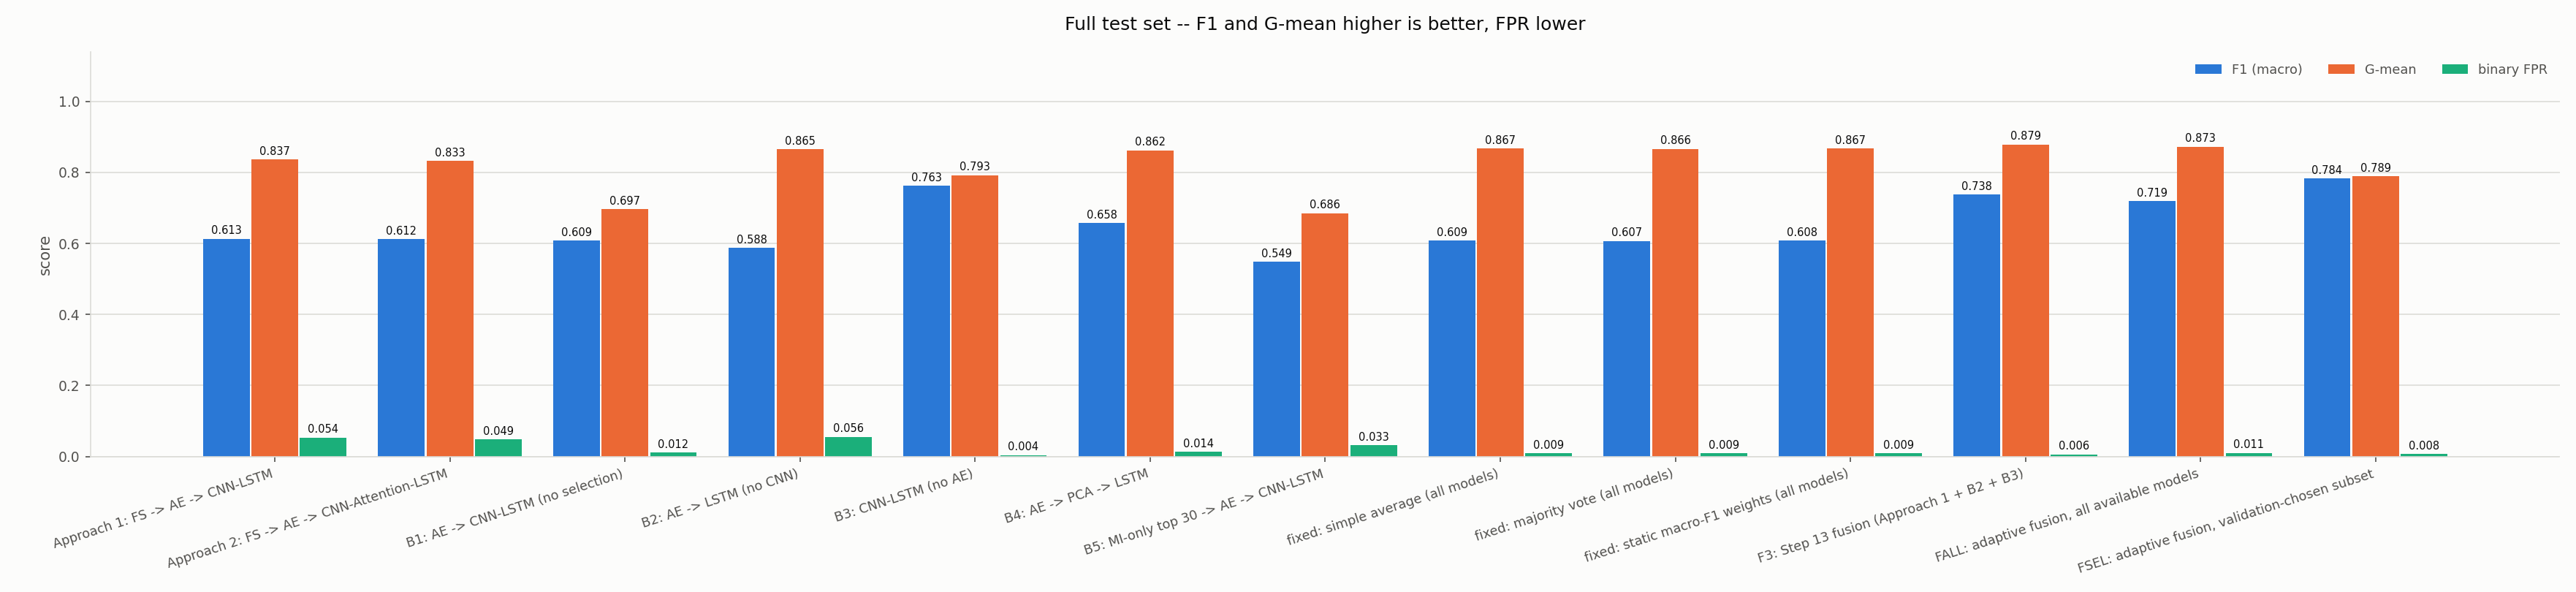

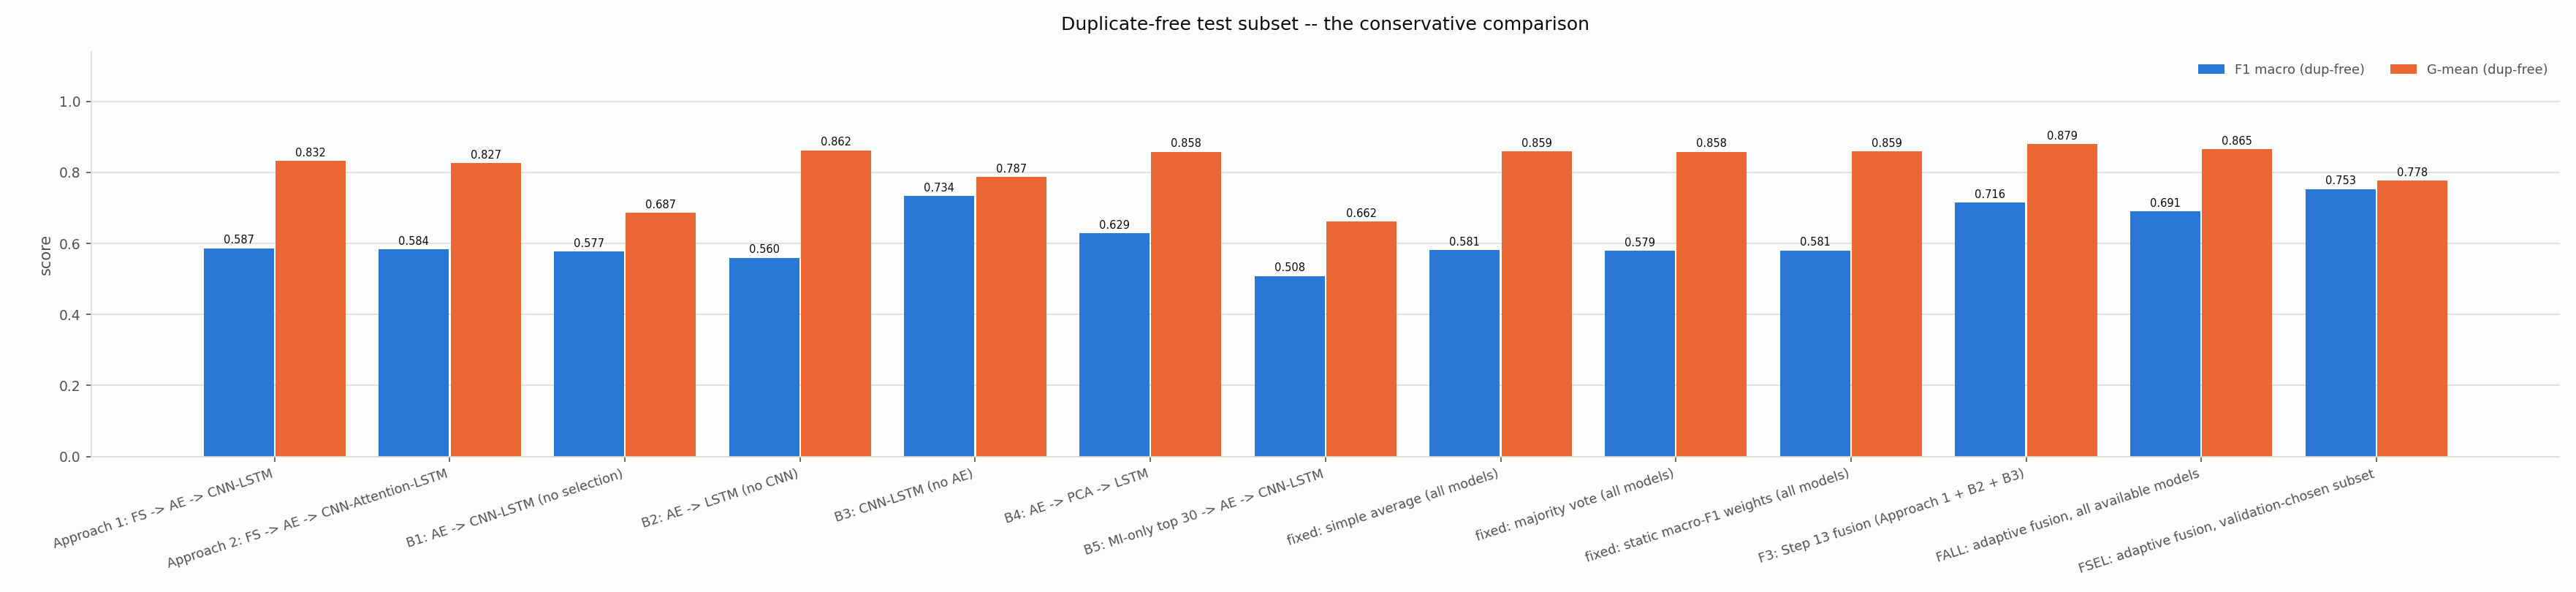

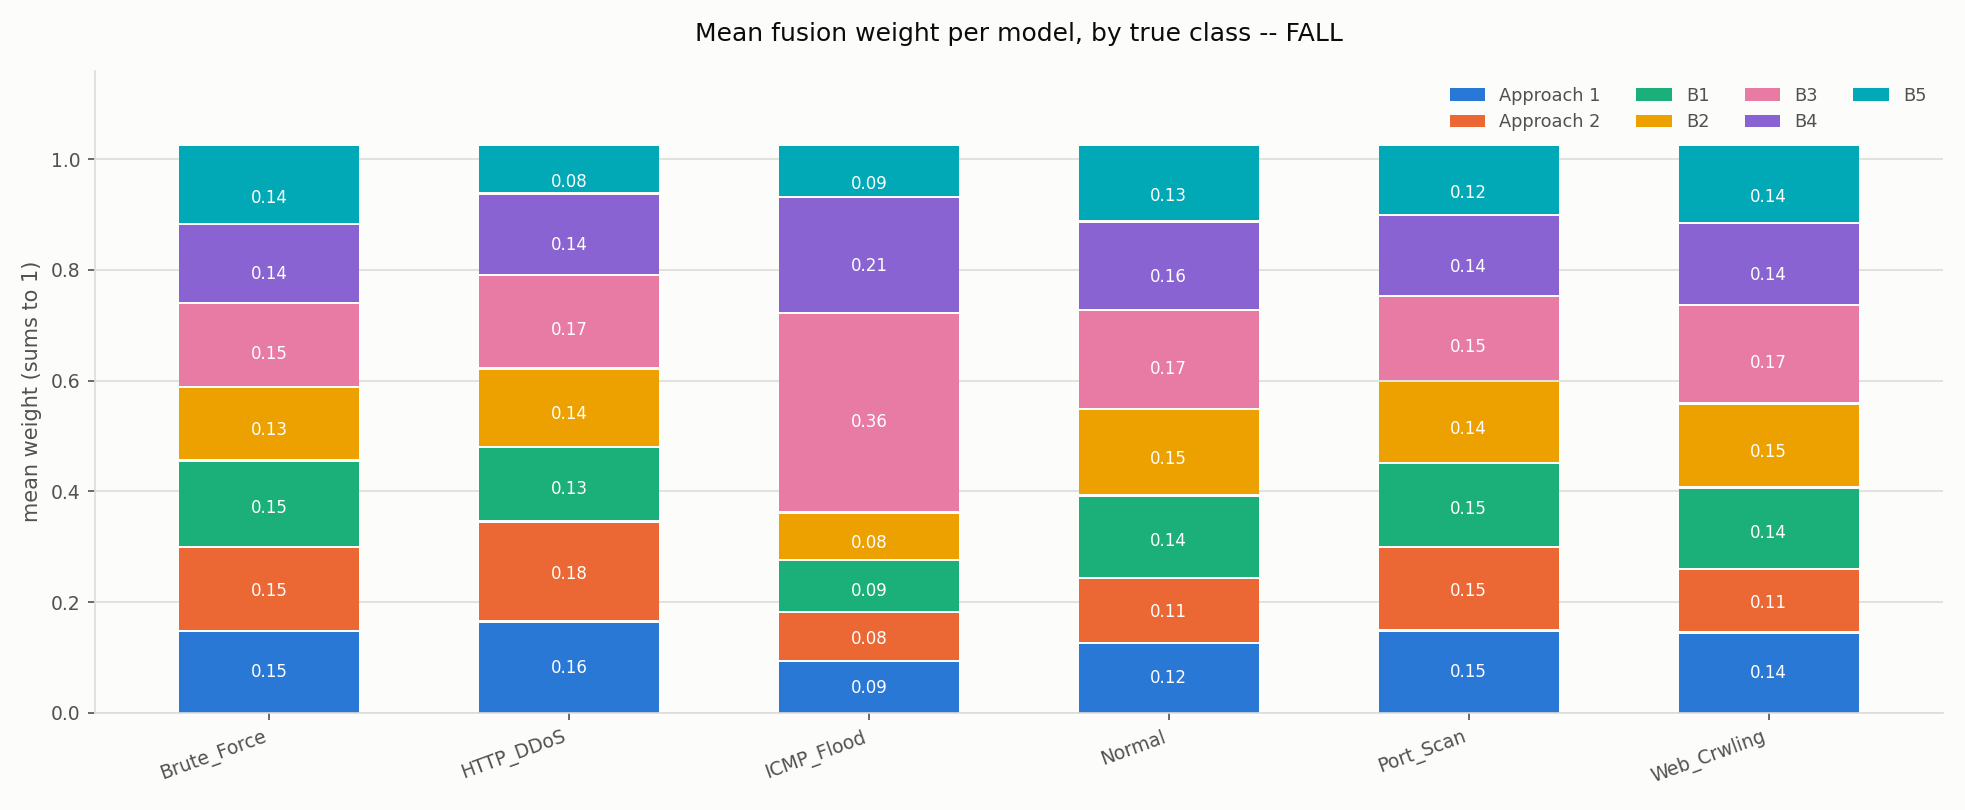

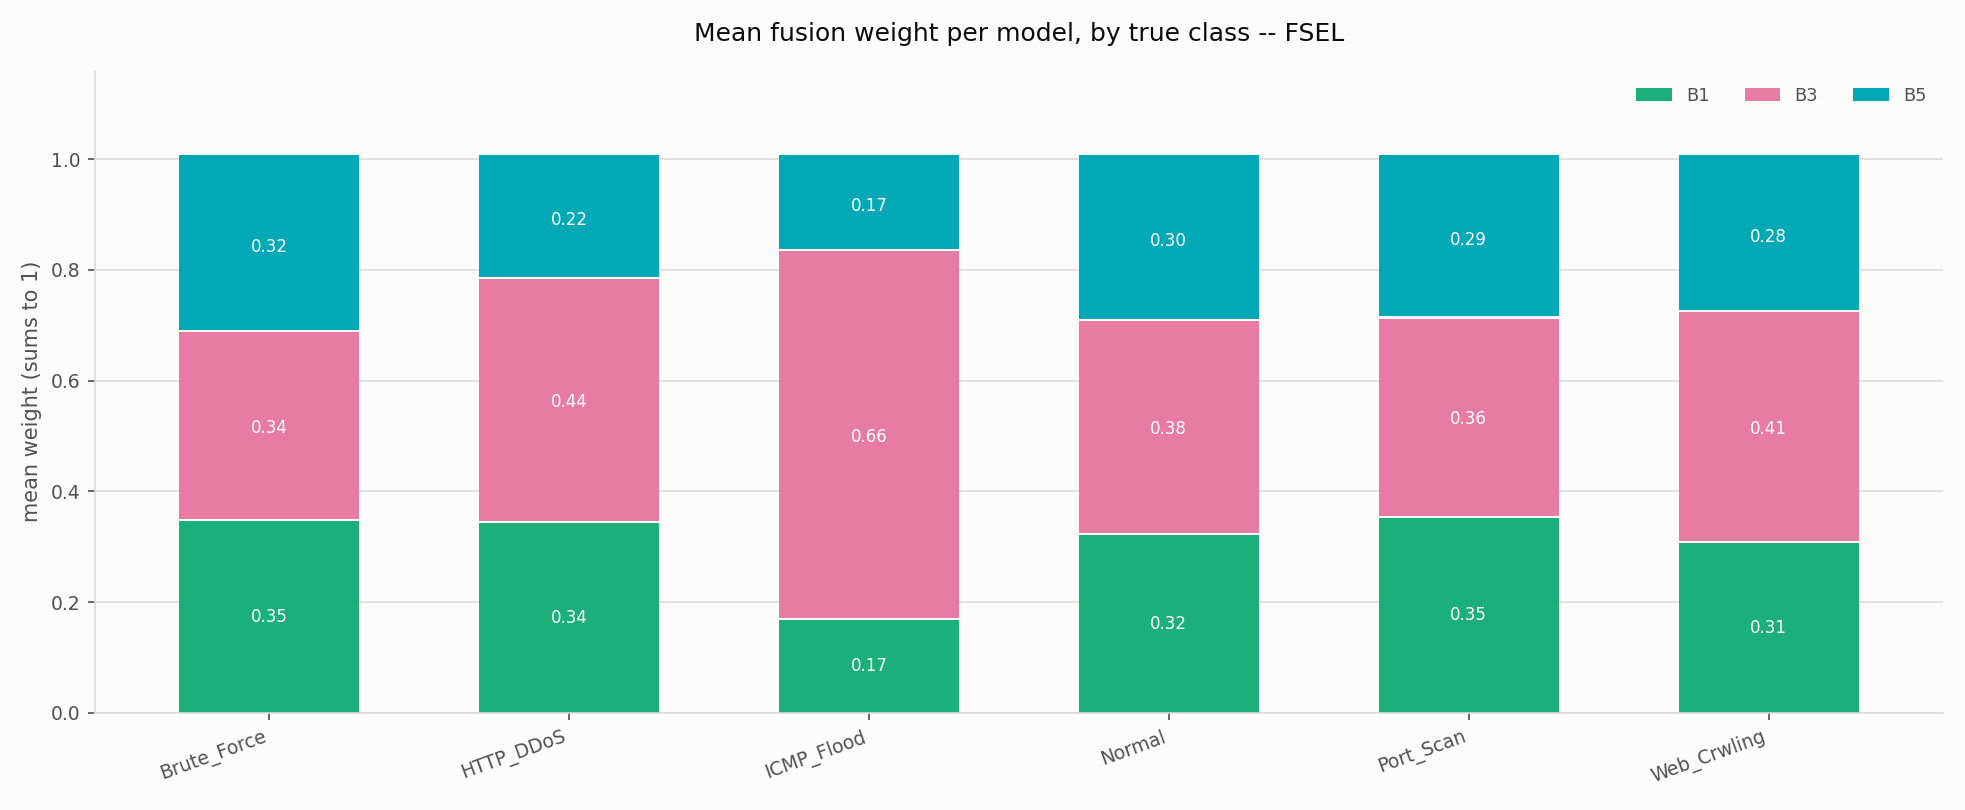

In [111]:
# average weight per model per true class, for FALL and for FSEL
for tag in ("FALL", "FSEL"):
    frame = (step13_all.get("weights_by_class") or {}).get(tag)
    if frame is not None and len(frame):
        fusion_all.show_table(frame, all_columns=True,
            note="%s: mean weight per model within each TRUE class. Flat rows "
                 "would mean the adaptation is not doing anything; the weights "
                 "sum to 1 across the models of that variant." % tag)

for key in ("chart_metrics", "chart_metrics_free", "chart_weights_all",
            "chart_weights_subset"):
    picture = config.STEP13ALL_OUTPUT_DIR / config.STEP13ALL_FILES[key]
    if picture.exists() and fusion_all.dl.in_notebook():
        from IPython.display import Image, display
        display(Image(filename=str(picture)))
    elif not picture.exists():
        print("missing:", picture)

### 11.8.5 Discussion

**Purpose** — State what the tables above support, and nothing more.

Everything below is generated from the computed numbers, not written by hand:
whether fusing all models beats the three-model fusion and the best single
model, on which metrics and on the duplicate-free subset; which models the
greedy search kept and whether that matches the diversity check; and the
caveats.

In [112]:
text = step13_all.get("summary") or (step13_all.get("metrics") or {}).get("summary")
if text:
    if fusion_all.dl.in_notebook():
        from IPython.display import Markdown, display
        display(Markdown(text))
    else:
        print(text)

report = step13_all.get("report")
if report is not None and len(report):
    fusion_all.show_table(report, all_columns=True,
        note="Read back from disk after writing: the weights sum to 1 per flow, "
             "every fused row sums to 1, R is inside [0, 1], the row count "
             "equals the test set, and `step13\\` is byte-identical.")

unchanged = step13_all.get("step13_unchanged_table")
if unchanged is not None and len(unchanged):
    fusion_all.show_table(unchanged, all_columns=True,
        note="SHA-256 of every file in `step13\\`, before this section ran and "
             "after it wrote its own outputs.")
print("[%s]  existing Step 13 outputs unchanged"
      % ("OK" if step13_all.get("step13_unchanged") else "FAIL"))

### 13.8.5 Fusion across all approaches and baselines -- what the numbers say

**Models.** 7 of 8 configurations were available and fused: Approach 1: FS -> AE -> CNN-LSTM, Approach 2: FS -> AE -> CNN-Attention-LSTM, B1: AE -> CNN-LSTM (no selection), B2: AE -> LSTM (no CNN), B3: CNN-LSTM (no AE), B4: AE -> PCA -> LSTM, B5: MI-only top 30 -> AE -> CNN-LSTM.
Skipped, not trained on this machine: B6: AE -> PCA -> CNN-LSTM. Nothing was trained to fill the gap.

**Does fusing everything help?**
- best single macro-F1 = 0.7625 (B3: CNN-LSTM (no AE)); F3 = 0.7375; FALL = 0.7189; FSEL = 0.7838.
  - best on this metric: FSEL.
- best single G-mean = 0.8650 (B2: AE -> LSTM (no CNN)); F3 = 0.8787; FALL = 0.8726; FSEL = 0.7894.
  - best on this metric: F3.
- best single macro-F1 (duplicate-free) = 0.7342 (B3: CNN-LSTM (no AE)); F3 = 0.7158; FALL = 0.6909; FSEL = 0.7531.
  - best on this metric: FSEL.
- best single G-mean (duplicate-free) = 0.8625 (B2: AE -> LSTM (no CNN)); F3 = 0.8791; FALL = 0.8651; FSEL = 0.7775.
  - best on this metric: F3.
- best single binary FPR (lower is better) = 0.0556 (B2: AE -> LSTM (no CNN)); F3 = 0.0065; FALL = 0.0105; FSEL = 0.0077.
  - best on this metric: F3.

**Which models the greedy search kept.** B1: AE -> CNN-LSTM (no selection), B3: CNN-LSTM (no AE), B5: MI-only top 30 -> AE -> CNN-LSTM, chosen on the validation split alone (metric: macro_f1, SUBSET_MAX_MODELS = 4).
- Selection path: B3: CNN-LSTM (no AE) (validation macro_f1 0.7151) -> B1: AE -> CNN-LSTM (no selection) (validation macro_f1 0.7245) -> B5: MI-only top 30 -> AE -> CNN-LSTM (validation macro_f1 0.7415).
- Stopped because no candidate improved the validation score.

**Diversity (validation rows).** The most interchangeable pair is Approach 1: FS -> AE -> CNN-LSTM and Approach 2: FS -> AE -> CNN-Attention-LSTM, disagreeing on 2.76% of flows; the most diverse is Approach 1: FS -> AE -> CNN-LSTM and B5: MI-only top 30 -> AE -> CNN-LSTM at 8.21%. Models that almost always agree can only add weight to an opinion the fusion already has.
- Mean pairwise disagreement inside the chosen subset 0.0378 against 0.0532 across all available pairs, so the search did not keep a more diverse-than-average set.

**Caveats.**
- The reliabilities and every threshold come from the validation part of the Step 9 split, which Step 10 also used for early stopping, so they are slightly optimistic. The subset choice has the same caveat: it is a validation decision, not a test-set one.
- Rare classes: ICMP_Flood (9 test rows), Web_Crwling (6 test rows). A per-class F1 computed on that many rows moves in large steps and should not be read as a precise figure.
- One seed (RANDOM_STATE = 42). The gaps above are differences between single runs, not estimates with a spread.
- F3 is **read from `step13\metrics.json`**, not recomputed, so the Step 13 row here is the Step 13 row in the write-up.

**Explainability.** Step 14 explains the original three-model fusion (F3), unchanged. Explaining FALL or FSEL -- per-model contributions over up to 7 models -- would be a separate addendum; nothing in Step 14 is altered by this section.

,check,result,detail
0,model_availability.csv was written,[OK],"1,092 bytes"
1,diversity_disagreement.csv was written,[OK],844 bytes
2,diversity_risk_corr.csv was written,[OK],846 bytes
3,reliability_table_all.csv was written,[OK],"2,656 bytes"
4,fused_predictions_all.csv was written,[OK],"9,792,862 bytes"
5,comparison_table_all.csv was written,[OK],"4,017 bytes"
6,per_class_f1_all.csv was written,[OK],"1,175 bytes"
7,metrics_all.json was written,[OK],"15,304 bytes"
8,thresholds_all.json was written,[OK],734 bytes
9,summary_all.md was written,[OK],"3,166 bytes"


_Read back from disk after writing: the weights sum to 1 per flow, every fused row sums to 1, R is inside [0, 1], the row count equals the test set, and `step13\` is byte-identical._

,file,sha256 before,sha256 after,result
0,ablation_table.csv,61f04504c48229b7,61f04504c48229b7,[OK]
1,comparison_bars.png,9ffd46ad4fc8969f,9ffd46ad4fc8969f,[OK]
2,comparison_bars_duplicate_free.png,12798b7bde40236e,12798b7bde40236e,[OK]
3,comparison_table.csv,049c48a7a398777f,049c48a7a398777f,[OK]
4,fused_predictions.csv,65a137763944ad2b,65a137763944ad2b,[OK]
5,mean_weight_per_class.png,d609cba441ba8473,d609cba441ba8473,[OK]
6,metrics.json,a6422e2b6de327bd,a6422e2b6de327bd,[OK]
7,per_class_f1.csv,c0aa5ebd9952b7af,c0aa5ebd9952b7af,[OK]
8,reliability_heatmap.png,e7efa25fec269923,e7efa25fec269923,[OK]
9,reliability_table.csv,ba98357888e9498a,ba98357888e9498a,[OK]


_SHA-256 of every file in `step13\`, before this section ran and after it wrote its own outputs._

[OK]  existing Step 13 outputs unchanged


### What 11.8 can and cannot say

1. **The reliabilities are slightly optimistic, and so is the subset.** Both are
   measured on the validation part, which Step 8 also used for early stopping.
   The choice of models is a validation decision; a fully clean design would
   hold out a third split for it, which this dataset's 23-row classes cannot
   afford.
2. **A fusion is not free.** The overhead column is the fusion arithmetic only,
   on top of every member model's own inference. FALL runs every available
   model; FSEL runs the ones it kept.
3. **Rare classes.** Some classes have a handful of test rows, so their
   per-class F1 moves in large steps. Read the duplicate-free columns and the
   support beside them before quoting a per-class figure.
4. **One seed.** Every gap here is a difference between single runs, not an
   estimate with a spread.
5. **Step 12 is unchanged.** It explains the original three-model fusion (F3).
   Explaining FALL or FSEL -- attributing a decision across up to seven models
   -- would be a separate addendum, and none of Step 12's cells, code or saved
   outputs are touched by this section.

### What Step 12 adds

Step 11 ends with a number: $R(x) = 0.94$, raise the alert. An analyst reading
that number has no way to act on it. They need to know **why** -- which
properties of this flow made three models suspicious, which model carried the
decision, and what to look at first.

Step 12 turns each alert into an evidence report. It adds no model, changes no
threshold and overturns no Step 11 decision; it reads the saved models and the
saved fusion and explains what they already did.

Three things it deliberately does **not** do, because this pipeline cannot
support them:

- it does not claim a multi-stage attack progression (the attack stage is a
  lookup of the predicted label, nothing more);
- it does not reason over sequences, tokens or graphs (there is no such model
  here);
- it does not report an analyst triage time (nothing here was measured on an
  analyst).

---

## Step 12 - Explainability Layer

**Purpose** — Turn every ATTACK and SUSPICIOUS alert into a human-readable
evidence report: which input features drove each model, how the adaptive fusion
combined them into $R(x)$, how far the evidence can be trusted, and what an
analyst should check next.

**Input** — The Step 4 selected features and the Step 3 scaled and **unscaled**
test matrices, the Step 3 metadata, the Step 5 encoder, the Step 8 and Step 10
models and encoders, and the Step 11 fused predictions, reliabilities and
threshold. Everything is aligned on `Orig_Row`.

**Method** — Integrated Gradients implemented directly on `tf.GradientTape`,
on a frozen composed model that maps the **original named features** through the
encoder and the classifier, so the attributions are on `Flow Duration` rather
than on latent unit 7. Each attribution is then checked against direct
perturbation, which uses no gradients at all.

**Why** — An alert without a reason is not actionable, and an explanation
nobody has checked is worse than none. Every attribution here is verified three
ways: completeness ($\sum_i \mathrm{IG}_i = F(x) - F(x')$), agreement with
perturbation, and stability under small noise.

**Output** — `C:\MSCAD2022\outputs\step14` — `evidence_records.csv`,
`explanations.csv`, `global_feature_importance.csv`,
`explanation_validation.csv`, `model_agreement.csv`, `alert_explanations.csv`,
`example_alert_reports.md`, `thresholds_step14.json`,
`explanation_metrics.json`, `step14_report.csv` and seven charts.

> **Step 12 adds files; it changes nothing.** The models, the encoders, the
> Step 11 weights and $\tau$ are fixed. Nothing is retrained or fine-tuned, and
> no Step 11 decision changes.

#### Which model is explained here

Step 12 explains the Step 11 fusion, so it covers the same three models:
**Approach 1**, **B2** and **B3**. Approach 2 (CNN-Attention-LSTM) is reported
in Steps 8 to 10 and is **not** part of the fusion or of these explanations;
nothing in Steps 11 and 12 is recomputed for it.

### 12.1 Input and evidence collection

**Purpose** — Gather every saved output an explanation needs, prove they
describe the same flows, and decide which alerts to explain.

**Input** — Steps 3 to 11, aligned on `Orig_Row`.

**Method** — Decision bands, then a deterministic stratified selection.

**Output** — `evidence_records.csv`.

**Why** — Fusing or explaining frames that disagree on row order produces a
report that is fluent and wrong, so the alignment is asserted and raises rather
than warns.

**The decision bands.** Step 11's attack rule is kept exactly:

$$\text{band}(x) = \begin{cases}
\textsf{ATTACK} & R(x) \ge \tau \quad\text{(Step 11, unchanged)}\\[2pt]
\textsf{SUSPICIOUS} & \tau_s \le R(x) < \tau\\[2pt]
\textsf{BENIGN} & R(x) < \tau_s
\end{cases}$$

$\tau$ comes from Step 11 and is **not recomputed**. $\tau_s$ is new, and is
chosen on the **validation** part of the Step 7 split alone: the lowest risk at
which validation attack recall still reaches `SUSPICIOUS_RECALL_TARGET`. The
suspicious band only subdivides what Step 11 already called benign, so no Step
11 decision is altered -- it adds a second, lower shelf for an analyst who wants
to see what sat just under the line.

**Which flows get explained.** Every alert, up to `EXPLAIN_SAMPLE_PER_CLASS`
per fused class, drawn from a seeded generator so two runs explain the same
flows; a class with fewer alerts than that contributes all of them, which is how
the rare classes stay represented. A small benign sample is added for contrast.

In [113]:
# Quieten TensorFlow's C++ logger for this section only.
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

from src.mscad import explainability

explainability.show_table(explainability.kv_table([
    ("output folder", str(config.STEP14_OUTPUT_DIR)),
    ("models explained", ", ".join(config.FUSION_MODELS)
                         if config.EXPLAIN_OTHER_MODELS
                         else config.FUSION_MODELS[0]),
    ("IG_STEPS (trapezoidal)", config.IG_STEPS),
    ("IG_BASELINE", config.IG_BASELINE),
    ("TOP_K_FEATURES", config.TOP_K_FEATURES),
    ("COMPLETENESS_TOL", config.COMPLETENESS_TOL),
    ("PERTURB_MODE", config.PERTURB_MODE),
    ("stability", "%s repeats at noise %s"
                  % (config.STABILITY_N_REPEATS, config.STABILITY_NOISE_STD)),
    ("EXPLAIN_SAMPLE_PER_CLASS", config.EXPLAIN_SAMPLE_PER_CLASS),
    ("SUSPICIOUS_BAND", "%s (recall target %s)"
                        % (config.SUSPICIOUS_BAND,
                           config.SUSPICIOUS_RECALL_TARGET)),
    ("confidence thresholds", "High >= %s, Medium >= %s"
                              % (config.CONF_HIGH_PROB, config.CONF_MEDIUM_PROB)),
    ("SOURCE_CONTEXT", "%s (%s minute window)"
                       % (config.SOURCE_CONTEXT, config.SOURCE_CONTEXT_WINDOW_MIN)),
    ("OVERWRITE_STEP14", config.OVERWRITE_STEP14),
]), note="Every setting comes from the Step 14 block in `config.py`. "
         "`tau` is NOT here: it is Step 13's and is read from "
         "`step13/threshold.json` unchanged.")

,metric,value
0,output folder,C:\MSCAD2022\outputs_official\step14
1,models explained,"proposed, baseline2_ae_lstm, baseline3_cnn_lstm"
2,IG_STEPS (trapezoidal),64
3,IG_BASELINE,benign_median
4,TOP_K_FEATURES,5
5,COMPLETENESS_TOL,0.05
6,PERTURB_MODE,baseline_replace
7,stability,5 repeats at noise 0.01
8,EXPLAIN_SAMPLE_PER_CLASS,200
9,SUSPICIOUS_BAND,True (recall target 0.99)


_Every setting comes from the Step 14 block in `config.py`. `tau` is NOT here: it is Step 13's and is read from `step13/threshold.json` unchanged._

### Run the explainability layer

This loads the three saved models, rebuilds each as a composed differentiable
function on its **original** features, checks that each one still reproduces the
probabilities Step 10 saved, attributes, validates, explains the fusion and
writes the reports.

Integrated Gradients takes `IG_STEPS + 1` gradient evaluations per flow per
model per target, so this is the slowest part; it still trains nothing. With
`OVERWRITE_STEP14 = False` a finished run is read back from disk instead.

In [114]:
step14 = explainability.run_step14()

,metric,value
0,status,loaded from disk (OVERWRITE_STEP14 = False)
1,folder,C:\MSCAD2022\outputs_official\step14
2,alerts explained,539
3,attribution rows,"184,992"


_Set `OVERWRITE_STEP14 = True` in config.py to recompute._

### 12.2 Feature attribution with Integrated Gradients

**Purpose** — Say which input features moved each model on each alert.

**Input** — The composed model and a baseline flow $x'$.

**Method** — Integrated Gradients, implemented on `tf.GradientTape`.

**Output** — `explanations.csv`, `global_feature_importance.csv` and three
charts.

**Why** — A gradient at a single point is noisy and does not add up to
anything. IG integrates the gradient along the straight path from a reference
flow to this one, which gives it the completeness property below -- the one
thing that makes an attribution auditable.

$$\mathrm{IG}_i(x) \;=\; (x_i - x'_i)\int_0^1
\frac{\partial F\big(x' + \alpha (x - x')\big)}{\partial x_i}\, d\alpha$$

evaluated with the trapezoidal rule over `IG_STEPS` intervals. $F$ is one of
two scalars, both reported:

$$F_{\text{class}}(x) = p_m\big(\hat{c} \mid x\big)
\qquad\text{and}\qquad
F_{\text{risk}}(x) = r_m(x) = 1 - \sum_{c \in B} p_m(c \mid x)$$

**Completeness** is the identity that makes the attribution checkable:

$$\sum_i \mathrm{IG}_i(x) \;=\; F(x) - F(x')$$

Every flow's relative error $\big|\sum_i \mathrm{IG}_i - (F(x) -
F(x'))\big| \big/ |F(x) - F(x')|$ is measured and compared with
`COMPLETENESS_TOL`; failures are flagged, not hidden, and a flow whose
attributions do not add up cannot be marked **High** confidence.

**The baseline $x'$** is the per-feature median of the **training benign**
rows -- "a typical normal flow", which is the comparison an analyst makes
anyway. `zeros` and `train_mean` are available as ablations. The baseline is
built from training rows only, and its own risk $F(x')$ is reported below: it
should be low, because if the reference point already looks like an attack then
every attribution is measured from the wrong place.

**On the autoencoder.** The 15 latent units have no meaning an analyst can act
on, so the encoder is placed **inside** the differentiated function:

$$x\ (30\ \text{named features}) \;\to\; \text{encoder} \;\to\;
\text{reshape} \;\to\; \text{CNN-LSTM} \;\to\; \text{logits}
\;\to\; \text{softmax}$$

and the composed model is asserted to reproduce the saved Step 9/10
probabilities to $10^{-5}$ before anything is attributed. If it did not, the
attributions would explain a different model from the one that raised the alert.

**Temporal attribution** is computed only when `INPUT_MODE = "time_window"`.
In `feature_seq` mode a flow is one vector with no time steps, so there is
nothing to attribute over time and the chart is skipped rather than faked.

,feature,mean_abs_ig,mean_signed_ig,flows
213,Flow Duration,0.088945,-0.021065,564
239,SYN Flag Cnt,0.044006,0.027911,564
228,Fwd IAT Tot,0.042448,0.005298,564
220,Pkt Len Mean,0.033634,0.028560,564
210,Init Bwd Win Byts,0.018164,0.015938,564
214,Flow IAT Max,0.017449,0.000946,564
215,Bwd Pkts/s,0.016581,-0.007286,564
224,Bwd IAT Tot,0.010953,0.007844,564
217,Flow IAT Mean,0.009444,0.003510,564
225,Fwd IAT Max,0.009183,0.001740,564


_`proposed`: `mean_abs_ig` is how much the feature mattered, `mean_signed_ig` which way it pushed the attack risk._

,feature,mean_abs_ig,mean_signed_ig,flows
930,SYN Flag Cnt,0.451376,0.450862,564
889,Flow Duration,0.311630,0.064861,564
933,ACK Flag Cnt,0.086873,0.085823,564
901,Bwd Pkt Len Std,0.071904,0.071904,564
900,Bwd Pkt Len Mean,0.050134,0.038060,564
940,Bwd Seg Size Avg,0.046907,0.041381,564
929,FIN Flag Cnt,0.043756,0.043756,564
926,Pkt Len Mean,0.021856,0.008395,564
898,Bwd Pkt Len Max,0.019671,0.018708,564
923,Bwd Pkts/s,0.014634,0.013198,564


_`baseline2_ae_lstm`: `mean_abs_ig` is how much the feature mattered, `mean_signed_ig` which way it pushed the attack risk._

,feature,mean_abs_ig,mean_signed_ig,flows
1868,SYN Flag Cnt,0.188951,0.111860,564
1846,Fwd IAT Tot,0.124287,0.100255,564
1827,Flow Duration,0.053443,0.040170,564
1871,ACK Flag Cnt,0.053127,0.047277,564
1878,Bwd Seg Size Avg,0.051955,-0.014776,564
1864,Pkt Len Mean,0.048033,-0.037131,564
1865,Pkt Len Std,0.040175,0.040125,564
1876,Pkt Size Avg,0.034079,0.003101,564
1867,FIN Flag Cnt,0.020301,0.020301,564
1849,Fwd IAT Max,0.019516,0.015371,564


_`baseline3_cnn_lstm`: `mean_abs_ig` is how much the feature mattered, `mean_signed_ig` which way it pushed the attack risk._

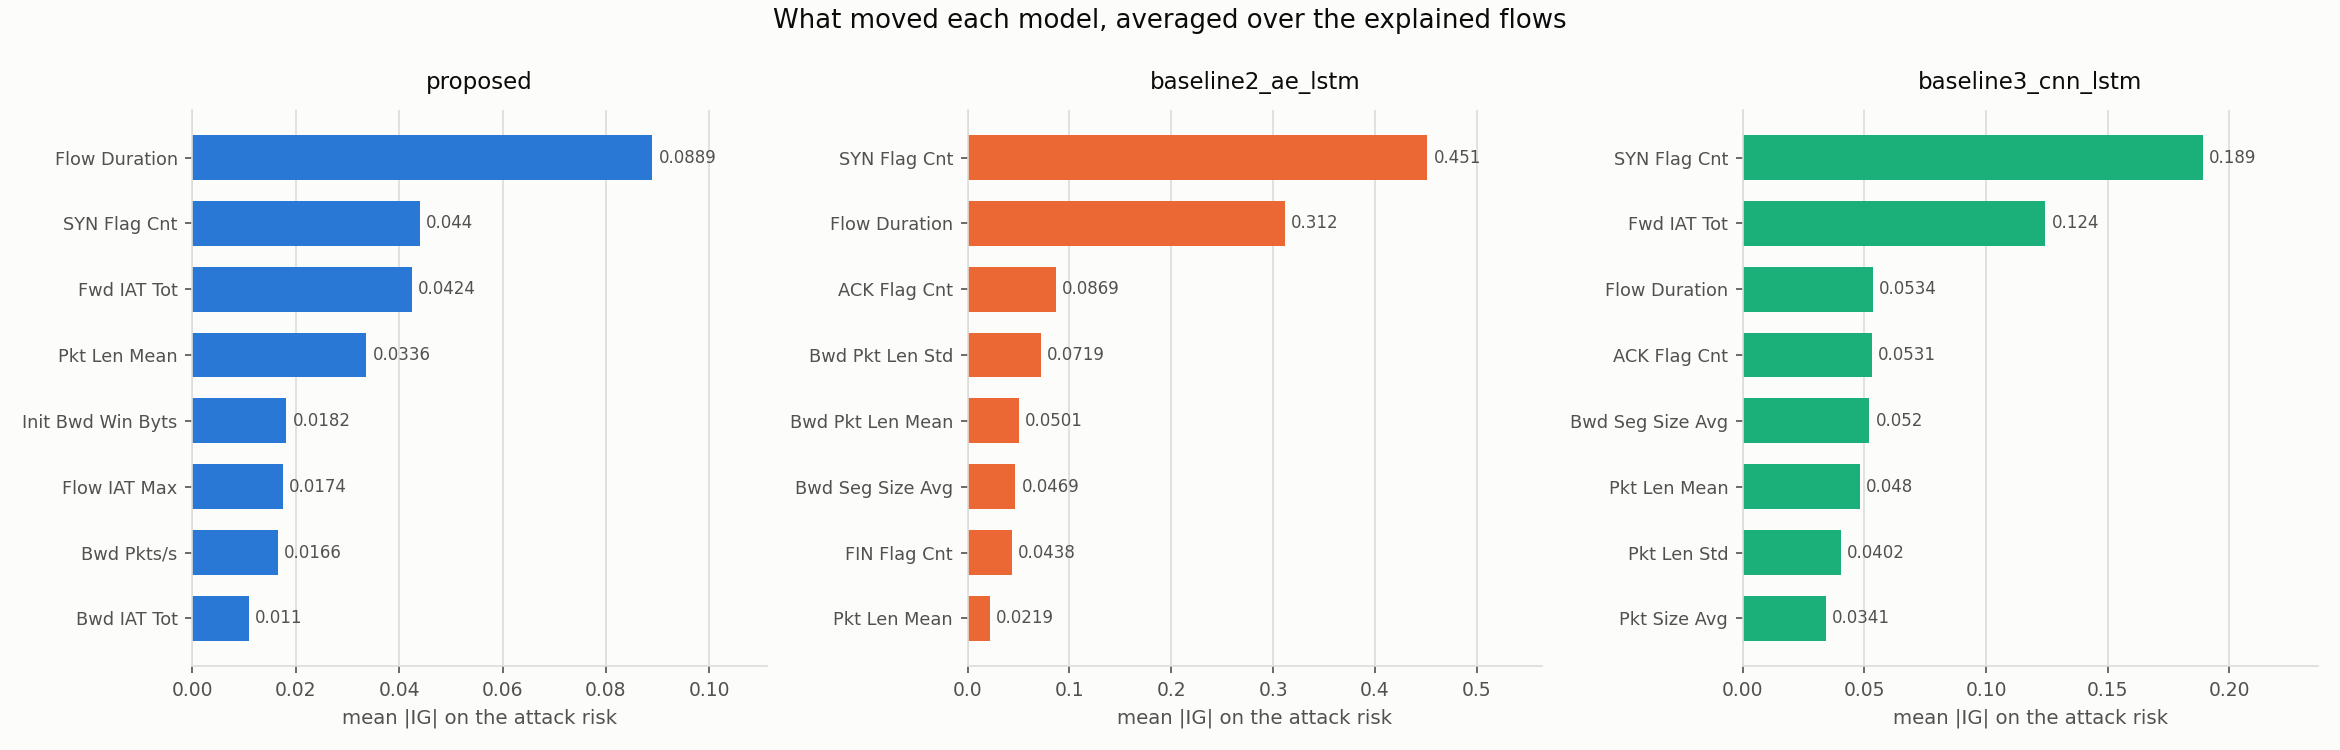

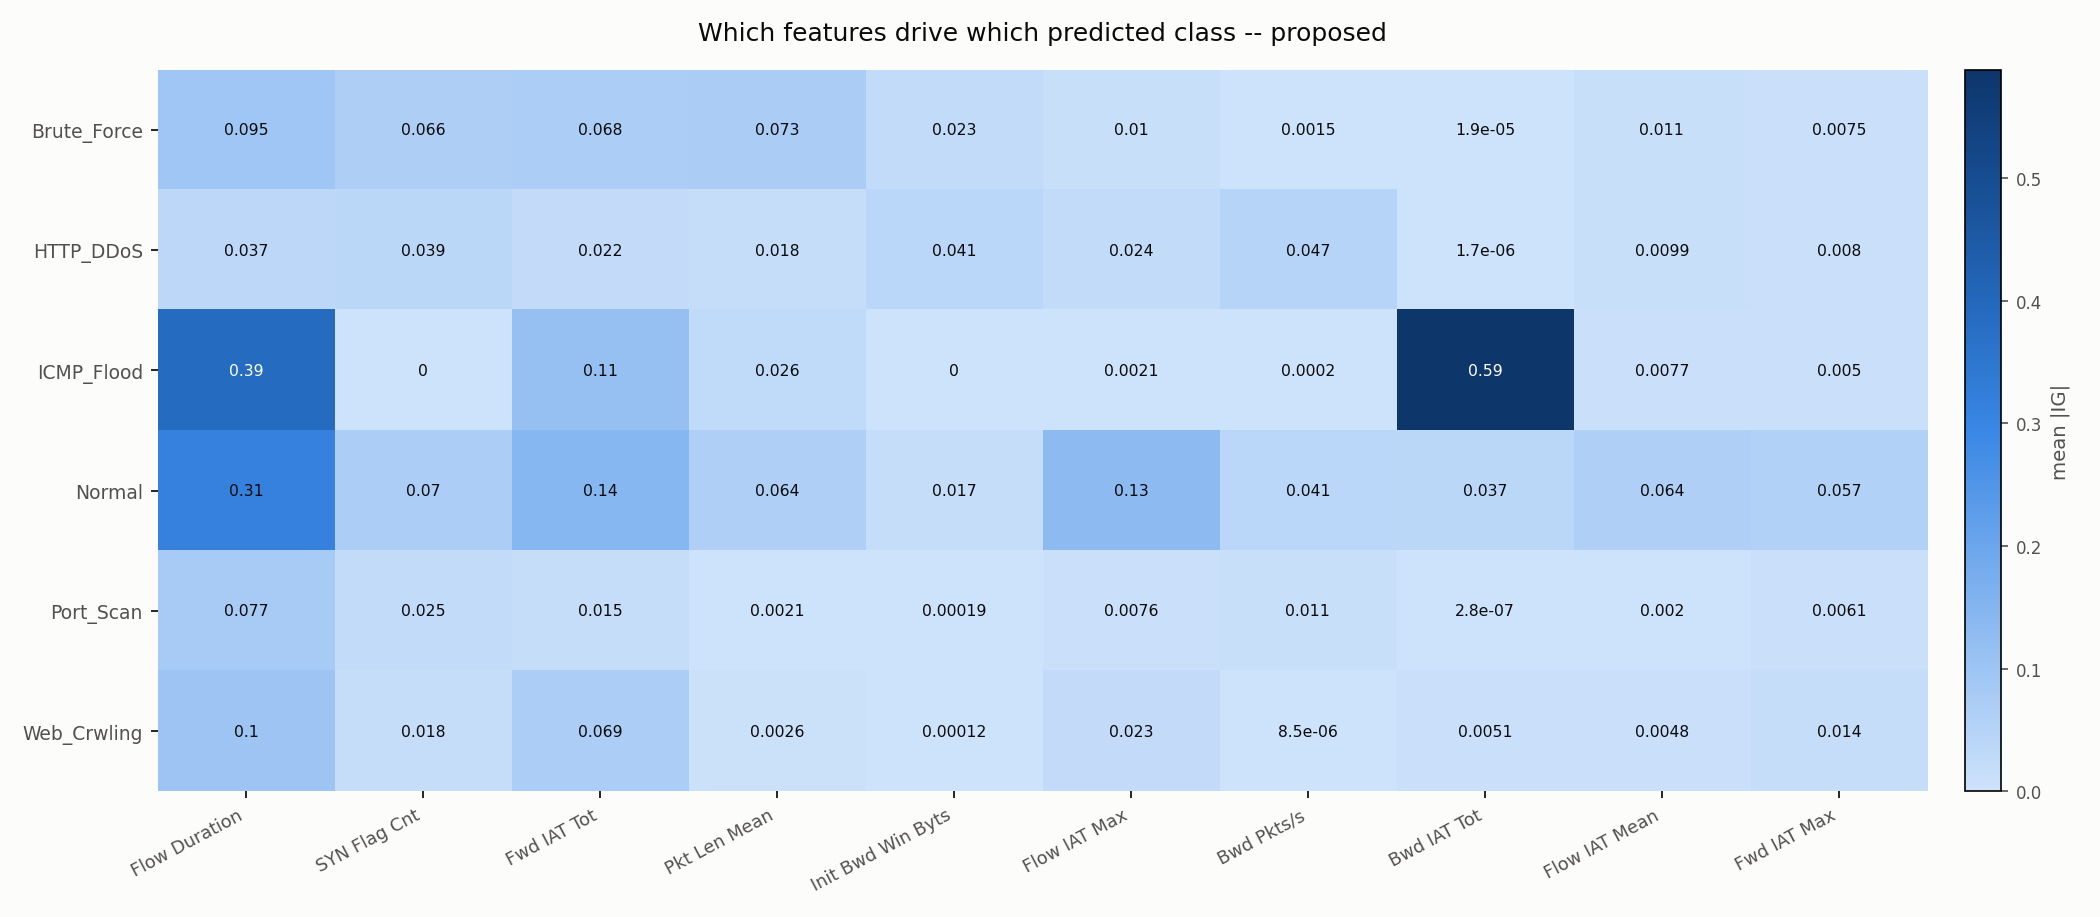

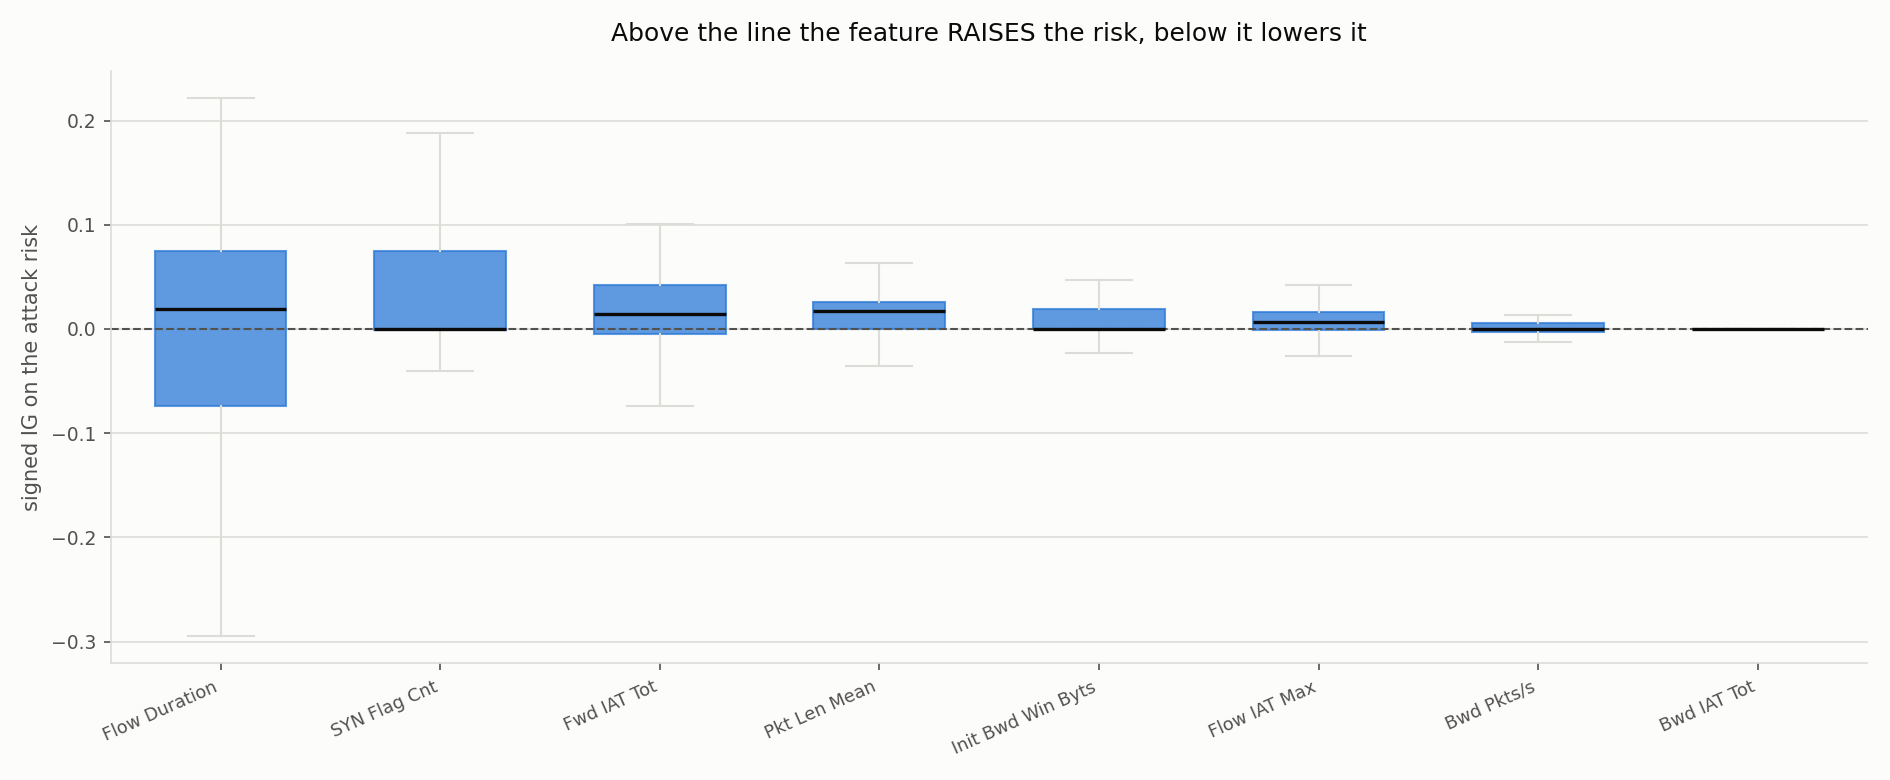

In [115]:
importance = step14.get("global_importance")
if importance is not None and len(importance):
    overall = importance[
        (importance["scope"] == "all explained flows")
        & (importance["target"] == explainability.TARGET_RISK)]
    for model in overall["model"].unique():
        explainability.show_table(
            overall[overall["model"] == model]
            .nlargest(10, "mean_abs_ig")[["feature", "mean_abs_ig",
                                          "mean_signed_ig", "flows"]],
            note="`%s`: `mean_abs_ig` is how much the feature mattered, "
                 "`mean_signed_ig` which way it pushed the attack risk." % model)

for key in ("chart_global", "chart_heatmap", "chart_signed"):
    picture = config.STEP14_OUTPUT_DIR / config.STEP14_FILES[key]
    if picture.exists() and explainability.dl.in_notebook():
        from IPython.display import Image, display
        display(Image(filename=str(picture)))
    elif not picture.exists():
        print("missing:", picture)

### 12.3 Validating the explanations

**Purpose** — Check the attributions against a method that shares none of
their assumptions.

**Input** — The same flows, the same baseline.

**Method** — Replace one feature at a time with its baseline value and measure
the drop in $F$; then rank-compare those drops with $|\mathrm{IG}|$.

**Output** — `explanation_validation.csv`, the scatter and the deletion bars.

**Why** — IG is a gradient method, so it can be confidently wrong in ways a
gradient method cannot see. Perturbation uses no gradients at all: where the two
agree, the attribution is describing the model rather than the method.

Three numbers come out of this:

1. **Spearman** between $|\mathrm{IG}|$ and the perturbation drops, per flow.
   Flows with a negative correlation are counted and reported -- on those, the
   two methods disagree outright and the explanation should be read with care.
2. **Top-$K$ overlap**: how much of the top-5 the two rankings share.
3. **The deletion check**: setting the top-$K$ attributed features to the
   baseline should cost the model more than setting $K$ random features to it.
   If it does not, the ranking is not informative, and the summary says so in
   those words rather than quietly moving on.

,model,mean_spearman,median_spearman,mean_top_k_overlap,flows_disagreeing,flows
0,baseline2_ae_lstm,0.308329,0.451261,0.692553,57,564
1,baseline3_cnn_lstm,0.329579,0.250609,0.409574,19,564
2,proposed,0.505846,0.461179,0.742199,24,564


_`flows_disagreeing` counts flows where IG and perturbation rank the features in opposite orders (Spearman < 0)._

,model,K,"mean drop, top-K by |IG|","mean drop, K random",top-K drops more
0,proposed,5,0.134786,0.115985,True
1,baseline2_ae_lstm,5,0.660955,0.079057,True
2,baseline3_cnn_lstm,5,0.242940,0.070197,True


_Higher is better in the first column. `False` in the last column would mean the attribution is not beating chance for that model._

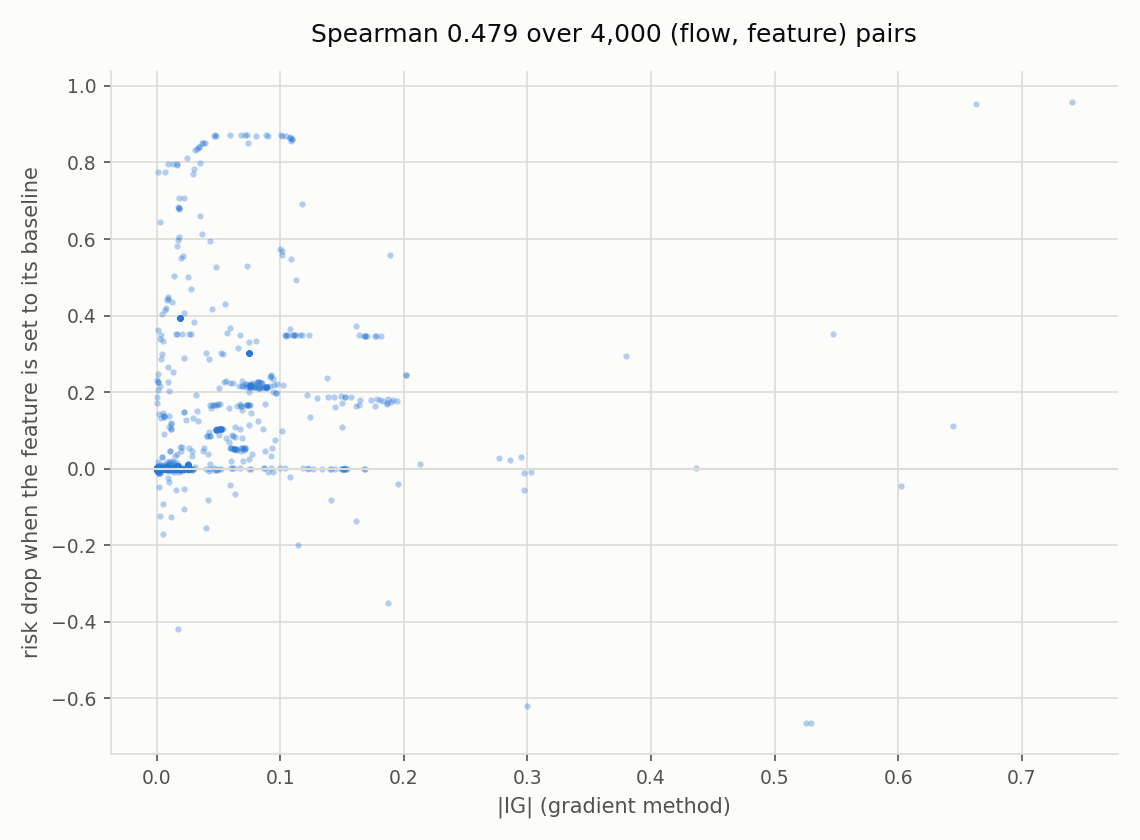

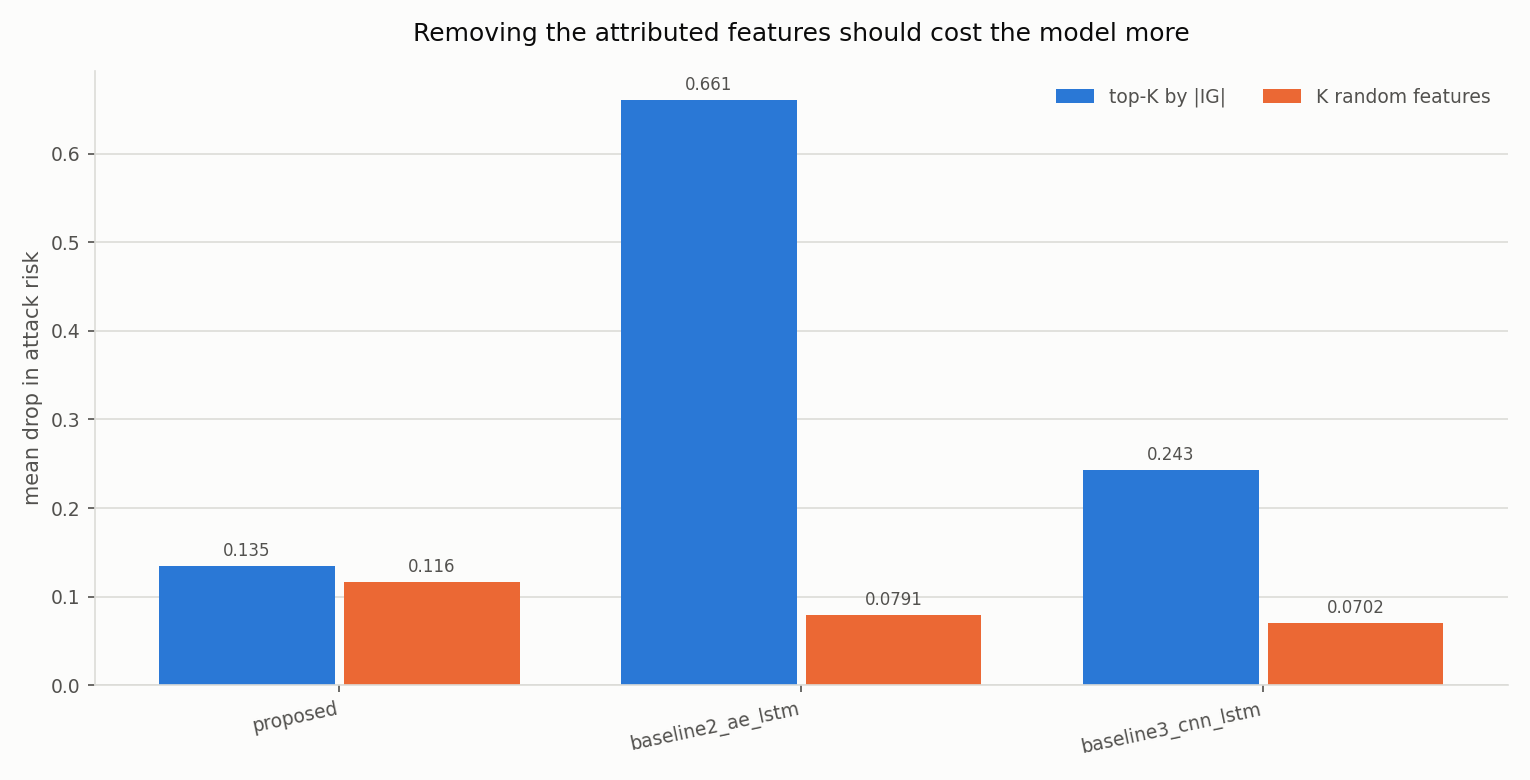

In [116]:
validation = step14.get("validation")
if validation is not None and len(validation):
    summary = (validation.groupby("model")
               .agg(mean_spearman=("spearman", "mean"),
                    median_spearman=("spearman", "median"),
                    mean_top_k_overlap=("top_k_overlap", "mean"),
                    flows_disagreeing=("spearman", lambda s: int((s < 0).sum())),
                    flows=("spearman", "size"))
               .reset_index())
    explainability.show_table(summary, all_columns=True,
        note="`flows_disagreeing` counts flows where IG and perturbation rank "
             "the features in opposite orders (Spearman < 0).")

metrics = step14.get("metrics") or {}
deletion = metrics.get("deletion_check") or {}
if deletion:
    explainability.show_table(pd.DataFrame([
        {"model": model, "K": value["k"],
         "mean drop, top-K by |IG|": value["mean_drop_top_k"],
         "mean drop, K random": value["mean_drop_random_k"],
         "top-K drops more": value["top_k_drops_more"]}
        for model, value in deletion.items()]), all_columns=True,
        note="Higher is better in the first column. `False` in the last column "
             "would mean the attribution is not beating chance for that model.")

for key in ("chart_scatter", "chart_deletion"):
    picture = config.STEP14_OUTPUT_DIR / config.STEP14_FILES[key]
    if picture.exists() and explainability.dl.in_notebook():
        from IPython.display import Image, display
        display(Image(filename=str(picture)))
    elif not picture.exists():
        print("missing:", picture)

### 12.4 Explaining the adaptive fusion, exactly

**Purpose** — Show how three models' opinions became one risk score.

**Input** — The weights, reliabilities and confidences Step 11 saved.

**Method** — Split $R(x)$ into one contribution per model.

**Output** — `model_agreement.csv` and the stacked contribution chart.

**Why** — This is the one part of the explanation that is exact rather than
approximate, and it is worth saying why. Each model's contribution is

$$C_m(x) \;=\; w_m(x)\, r_m(x)$$

and because the weights sum to one,

$$\sum_m C_m(x) \;=\; \sum_m w_m (1 - \textstyle\sum_{c \in B} p_m(c))
\;=\; 1 - \sum_{c \in B} \sum_m w_m\, p_m(c)
\;=\; 1 - \sum_{c \in B} P(c) \;=\; R(x)$$

So the contributions are not an approximation of the risk: they **are** the
risk, split by model. The code checks this against Step 11's own
`fused_predictions.csv` to $10^{-6}$ and raises on a mismatch -- which also
makes it a check on Step 11's saved file rather than a restatement of Step 12's
arithmetic.

The weights, reliabilities and confidences are **read back from Step 11**, not
recomputed, so the report explains the numbers that actually produced the alert.
(The reliabilities are recomputed once as a cross-check and must match.)

,flow,Orig_Row,test_row,agreement,dominant_model,dominant_contribution,fused_class,fused_label,models_agreeing_with_fusion,models,simple_average_class,simple_average_label,fusion_changed_the_class
0,0,595,130,unanimous,baseline3_cnn_lstm,0.366080,0,Brute_Force,3,3,0,Brute_Force,False
1,1,1894,403,unanimous,baseline3_cnn_lstm,0.366144,0,Brute_Force,3,3,0,Brute_Force,False
2,2,2591,545,unanimous,baseline3_cnn_lstm,0.365725,0,Brute_Force,3,3,0,Brute_Force,False
3,3,2962,614,unanimous,proposed,0.335116,0,Brute_Force,3,3,0,Brute_Force,False
4,4,3188,658,unanimous,baseline3_cnn_lstm,0.365816,0,Brute_Force,3,3,0,Brute_Force,False
5,5,3692,771,unanimous,baseline3_cnn_lstm,0.365676,0,Brute_Force,3,3,0,Brute_Force,False
6,6,4965,1031,unanimous,baseline3_cnn_lstm,0.365825,0,Brute_Force,3,3,0,Brute_Force,False
7,7,5409,1122,unanimous,baseline3_cnn_lstm,0.365966,0,Brute_Force,3,3,0,Brute_Force,False
8,8,5703,1194,unanimous,proposed,0.335157,0,Brute_Force,3,3,0,Brute_Force,False
9,9,6475,1344,unanimous,proposed,0.338566,0,Brute_Force,3,3,0,Brute_Force,False


_The first twelve explained flows. `dominant_model` is the largest contribution C_m = w_m r_m, which is not always the most confident model._

,agreement,flows
0,unanimous,557
1,majority,7


_How often the three models agreed on the class, across every explained flow._

Adaptive weighting changed the predicted class away from the simple average on 1 of 564 explained flows.


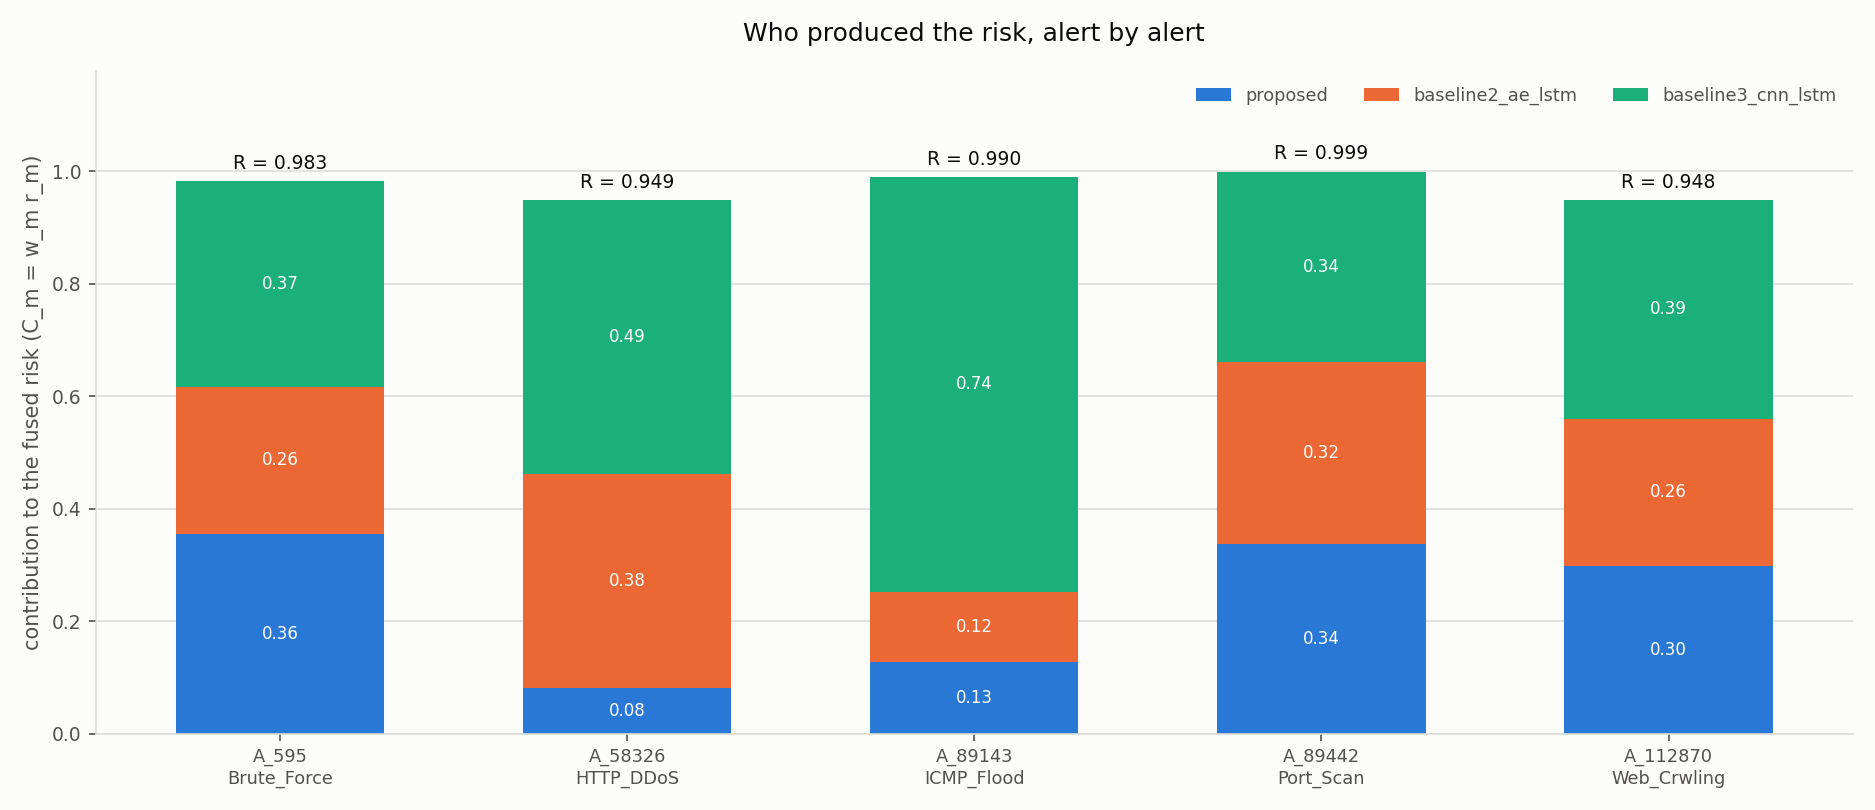

In [117]:
agreement = step14.get("agreement")
if agreement is not None and len(agreement):
    explainability.show_table(agreement.head(12), all_columns=True,
        note="The first twelve explained flows. `dominant_model` is the largest "
             "contribution C_m = w_m r_m, which is not always the most "
             "confident model.")
    counts = agreement["agreement"].value_counts().rename_axis("agreement")
    explainability.show_table(counts.reset_index(name="flows"),
        note="How often the three models agreed on the class, across every "
             "explained flow.")
    if "fusion_changed_the_class" in agreement.columns:
        changed = int(agreement["fusion_changed_the_class"].sum())
        print("Adaptive weighting changed the predicted class away from the "
              "simple average on %d of %d explained flows."
              % (changed, len(agreement)))

picture = config.STEP14_OUTPUT_DIR / config.STEP14_FILES["chart_contributions"]
if picture.exists() and explainability.dl.in_notebook():
    from IPython.display import Image, display
    display(Image(filename=str(picture)))
elif not picture.exists():
    print("missing:", picture)

### 12.5 The per-alert evidence report

**Purpose** — Put everything above in front of an analyst, one alert at a time.

**Input** — The attributions, the fusion breakdown and the Step 3 metadata.

**Method** — A fixed set of evidence rows, each with a confidence label.

**Output** — `alert_explanations.csv` and `example_alert_reports.md`.

**Why** — A report with a different shape for every alert cannot be scanned.
These rows are the same every time, and the ones this pipeline cannot support
are absent by construction, not by accident.

Every report carries exactly these rows: **Alert ID**, **Risk score**, one row
per model, **Fusion**, **Attack family**, **Attack stage**, **Flow context**,
**Source context**, **Uncertainty** and **Recommended action**.

**The confidence column** is a rule, not a judgement:

$$\textsf{High} \iff \max_c P(c \mid x) \ge \texttt{CONF\_HIGH\_PROB}
\;\wedge\; \text{all models agree}
\;\wedge\; \text{completeness passed}$$

$$\textsf{Medium} \iff \max_c P(c \mid x) \ge \texttt{CONF\_MEDIUM\_PROB}
\;\vee\; \text{a majority agrees}
\qquad\qquad \textsf{Low} \iff \text{otherwise}$$

Three things in the report are **context, not evidence**, and each says so on
its own line:

- **Flow context** prints whichever identifiers the dataset has, and the
  official `MSCAD.csv` has none, so it reports them as unavailable. No model
  ever sees them in either mode: the MSCAD labels were assigned by attacker IP,
  so a model given `Src IP` would simply read the answer off it.
- **Attack stage** is `ATTACK_STAGE_MAP[class]`: a label-to-tactic lookup. An
  unmapped label reports `Unmapped`; nothing is guessed, and no progression is
  implied.
- **Source context** lists other alerts from the same `Src IP`, and is skipped
  entirely when the dataset has no `Src IP`, as the official one does not.
  The test set is a random 20% of the flows, so a gap means "not in this
  subset", never "the source went quiet".

**Recommended action** is a suggested check for a human, prefixed *"Suggested
analyst check:"*. Nothing in this project executes it.

In [118]:
alerts = step14.get("alerts")
if alerts is not None and len(alerts):
    detail_columns = [c for c in alerts.columns if c.startswith("row: ")]
    shown = set()
    for _i, alert in alerts.iterrows():
        family = alert["fused_label"]
        if family in shown:
            continue
        shown.add(family)
        table = pd.DataFrame({
            "Evidence component": [c.replace("row: ", "") for c in detail_columns],
            "Detail": [alert[c] for c in detail_columns]})
        explainability.show_table(table, all_columns=True,
            note="Alert %s -- %s, band %s, confidence %s."
                 % (alert["alert_id"], family, alert["band"],
                    alert["confidence"]))
    print()
    print("Plain-text rendering of the same reports (also saved as "
          "example_alert_reports.md):")
    print()
    text = step14.get("examples_markdown", "")
    for block in text.split("```")[1::2]:
        print(block.strip())
        print()
else:
    print("No ATTACK or SUSPICIOUS alert was explained, so there is no report "
          "to render.")

,Evidence component,Detail
0,Alert ID,A_595 | decision band: ATTACK
1,Risk score,R = 0.983 vs tau = 0.943 (suspicious band from...
2,Model 1 Proposed (FS->AE->CNN-LSTM),P = 0.97 (Brute_Force) | w = 0.36 | contributi...
3,Model 2 AE->LSTM,P = 0.87 (Brute_Force) | w = 0.27 | contributi...
4,Model 3 CNN->LSTM,P = 0.98 (Brute_Force) | w = 0.37 | contributi...
5,Fusion,context = Brute_Force | reliability: proposed ...
6,Attack family,Brute_Force (fused predicted class)
7,Attack stage,Credential Access (TA0006) -- label-to-tactic ...
8,Flow context,unknown:? -> unknown:? | Protocol ? | ? | capt...
9,Source context,0 other alert(s) from unknown within 60 minute...


_Alert A_595 -- Brute_Force, band ATTACK, confidence Medium._

,Evidence component,Detail
0,Alert ID,A_58326 | decision band: ATTACK
1,Risk score,R = 0.949 vs tau = 0.943 (suspicious band from...
2,Model 1 Proposed (FS->AE->CNN-LSTM),P = 0.36 (Normal) | w = 0.13 | contribution w*...
3,Model 2 AE->LSTM,P = 0.92 (HTTP_DDoS) | w = 0.38 | contribution...
4,Model 3 CNN->LSTM,P = 0.94 (HTTP_DDoS) | w = 0.49 | contribution...
5,Fusion,context = HTTP_DDoS | reliability: proposed 0....
6,Attack family,HTTP_DDoS (fused predicted class)
7,Attack stage,"Unmapped -- label-to-tactic mapping, not an in..."
8,Flow context,unknown:? -> unknown:? | Protocol ? | ? | capt...
9,Source context,0 other alert(s) from unknown within 60 minute...


_Alert A_58326 -- HTTP_DDoS, band ATTACK, confidence Medium._

,Evidence component,Detail
0,Alert ID,A_89143 | decision band: ATTACK
1,Risk score,R = 0.990 vs tau = 0.943 (suspicious band from...
2,Model 1 Proposed (FS->AE->CNN-LSTM),P = 0.96 (ICMP_Flood) | w = 0.13 | contributio...
3,Model 2 AE->LSTM,P = 0.96 (ICMP_Flood) | w = 0.13 | contributio...
4,Model 3 CNN->LSTM,P = 1.00 (ICMP_Flood) | w = 0.74 | contributio...
5,Fusion,context = ICMP_Flood | reliability: proposed 0...
6,Attack family,ICMP_Flood (fused predicted class)
7,Attack stage,Impact - Denial of Service (TA0040) -- label-t...
8,Flow context,unknown:? -> unknown:? | Protocol ? | ? | capt...
9,Source context,0 other alert(s) from unknown within 60 minute...


...

,Evidence component,Detail
0,Alert ID,A_89442 | decision band: ATTACK
1,Risk score,R = 0.999 vs tau = 0.943 (suspicious band from...
2,Model 1 Proposed (FS->AE->CNN-LSTM),P = 1.00 (Port_Scan) | w = 0.34 | contribution...
3,Model 2 AE->LSTM,P = 0.99 (Port_Scan) | w = 0.32 | contribution...
4,Model 3 CNN->LSTM,P = 1.00 (Port_Scan) | w = 0.34 | contribution...
5,Fusion,context = Port_Scan | reliability: proposed 0....
6,Attack family,Port_Scan (fused predicted class)
7,Attack stage,Reconnaissance (MITRE ATT&CK TA0043) -- label-...
8,Flow context,unknown:? -> unknown:? | Protocol ? | ? | capt...
9,Source context,0 other alert(s) from unknown within 60 minute...


_Alert A_89442 -- Port_Scan, band ATTACK, confidence Medium._

,Evidence component,Detail
0,Alert ID,A_112870 | decision band: ATTACK
1,Risk score,R = 0.948 vs tau = 0.943 (suspicious band from...
2,Model 1 Proposed (FS->AE->CNN-LSTM),P = 0.98 (Web_Crwling) | w = 0.31 | contributi...
3,Model 2 AE->LSTM,P = 0.92 (Web_Crwling) | w = 0.28 | contributi...
4,Model 3 CNN->LSTM,P = 0.94 (Web_Crwling) | w = 0.41 | contributi...
5,Fusion,context = Web_Crwling | reliability: proposed ...
6,Attack family,Web_Crwling (fused predicted class)
7,Attack stage,Reconnaissance / Discovery -- label-to-tactic ...
8,Flow context,unknown:? -> unknown:? | Protocol ? | ? | capt...
9,Source context,0 other alert(s) from unknown within 60 minute...


_Alert A_112870 -- Web_Crwling, band ATTACK, confidence Medium._


Plain-text rendering of the same reports (also saved as example_alert_reports.md):

ALERT A_595  [ATTACK]
------------------------------------------------------------------------------
Alert ID                            | A_595 | decision band: ATTACK  [Medium]
Risk score                          | R = 0.983 vs tau = 0.943 (suspicious band from tau_s = 0.965)  [Medium]
Model 1 Proposed (FS->AE->CNN-LSTM) | P = 0.97 (Brute_Force) | w = 0.36 | contribution w*r = 0.36 | r = 0.989 | top-5 features: Flow Duration = 18029 (lowers, IG -0.0842); Fwd IAT Tot = 0 (raises, IG +0.0602); Init Bwd Win Byts = 4106 (raises, IG +0.0476); Pkt Len Mean = 0 (raises, IG +0.0251); Bwd Pkt Len Min = 0 (raises, IG +0.0113)  [High]
Model 2 AE->LSTM                    | P = 0.87 (Brute_Force) | w = 0.27 | contribution w*r = 0.26 | r = 0.955 | top-5 features: Flow Duration = 18029 (raises, IG +0.4831); ACK Flag Cnt = 1 (raises, IG +0.3673); Init Bwd Win Byts = 4106 (raises, IG +0.0484); Fwd IAT Max = 0 (lowers

### 12.6 Evaluating the explanations

**Purpose** — Quantify how far the explanations themselves can be trusted.

**Input** — The completeness, agreement and stability measurements above.

**Method** — Five families of number, all computed, none asserted.

**Output** — `explanation_metrics.json`.

**Why** — "Explainable" is a claim, and a claim needs evidence like any other.

| What | How it is measured |
|---|---|
| **Completeness** | share of flows within `COMPLETENESS_TOL`, plus the mean and median relative error, per model and target |
| **Stability** | Gaussian noise at `STABILITY_NOISE_STD` (clipped back into $[0,1]$), `STABILITY_N_REPEATS` times; Spearman and top-$K$ overlap against the original ranking |
| **IG vs perturbation** | mean and median Spearman, top-$K$ overlap, and the count of flows that disagree outright |
| **Deletion check** | mean risk drop, top-$K$ against $K$ random features |
| **Fusion consistency** | $\max_x \big| R(x) - \sum_m C_m(x) \big|$ |

**Latency** is reported as **generation time**: IG milliseconds per flow per
model, perturbation per flow, the fusion explanation, and report generation per
alert. It is how long the *code* takes. Nothing here was measured on an analyst,
so no triage time is claimed.

Every setting that could have been tuned -- the baseline, $\tau_s$ -- was chosen
on the **validation** part of the Step 7 split. No test label took part in any
Step 12 setting.

In [119]:
metrics = step14.get("metrics") or {}
if metrics:
    rows = []
    for model, by_target in (metrics.get("completeness") or {}).items():
        for target, values in by_target.items():
            rows.append({"model": model, "target": target,
                         "within tolerance": values["share_within_tolerance"],
                         "mean relative error": values["mean_relative_error"],
                         "median relative error": values["median_relative_error"],
                         "flows": values["flows"]})
    if rows:
        explainability.show_table(pd.DataFrame(rows), all_columns=True,
            note="Completeness: sum IG against F(x) - F(x'), per flow.")

    stability = metrics.get("stability") or {}
    if stability:
        explainability.show_table(pd.DataFrame([
            {"model": model, **{k: v for k, v in values.items()}}
            for model, values in stability.items()]), all_columns=True,
            note="Stability: the same flows re-attributed under small noise.")

    latency = {k: v for k, v in (metrics.get("latency") or {}).items()
               if isinstance(v, dict)}
    if latency:
        explainability.show_table(pd.DataFrame([
            {"model": model, "IG ms/flow": values["ig_ms_per_flow"],
             "perturbation ms/flow": values["perturbation_ms_per_flow"],
             "baseline risk F(x')": values["baseline_risk"]}
            for model, values in latency.items()]), all_columns=True,
            note="Generation time, not analyst triage time. `baseline risk` is "
                 "F(x') -- it should be low, or the reference flow is not a "
                 "typical normal one.")
        print("fusion explanation: %.3f ms per flow | report generation: "
              "%.3f ms per alert"
              % (metrics["latency"]["fusion_explanation_ms_per_flow"],
                 metrics["latency"]["report_generation_ms_per_alert"]))
    print("temporal attribution:", metrics.get("temporal_attribution"))

,model,target,within tolerance,mean relative error,median relative error,flows
0,baseline2_ae_lstm,attack_risk,0.969858,0.082565,0.006472,564
1,baseline2_ae_lstm,class_probability,0.973404,0.086994,0.009546,564
2,baseline3_cnn_lstm,attack_risk,0.239362,0.086585,0.067608,564
3,baseline3_cnn_lstm,class_probability,0.884752,0.037489,0.017415,564
4,proposed,attack_risk,0.196809,0.232767,0.121908,564
5,proposed,class_probability,0.847518,0.032226,0.018062,564


_Completeness: sum IG against F(x) - F(x'), per flow._

,model,repeats,noise_std,top_k,mean_spearman,median_spearman,mean_top_k_overlap,comparisons,flows
0,proposed,5,0.01,5,0.665572,0.669911,0.8152,250,50
1,baseline2_ae_lstm,5,0.01,5,0.647534,0.653631,0.8888,250,50
2,baseline3_cnn_lstm,5,0.01,5,0.561315,0.572808,0.5968,250,50


_Stability: the same flows re-attributed under small noise._

,model,IG ms/flow,perturbation ms/flow,baseline risk F(x')
0,proposed,29.4122,8.9954,0.901361
1,baseline2_ae_lstm,37.2458,18.2538,0.046282
2,baseline3_cnn_lstm,84.0745,22.1090,0.604997


_Generation time, not analyst triage time. `baseline risk` is F(x') -- it should be low, or the reference flow is not a typical normal one._

fusion explanation: 0.586 ms per flow | report generation: 4.335 ms per alert
temporal attribution: not applicable: INPUT_MODE is 'feature_seq', so a flow is one vector with no time steps


### 12.7 Saved outputs and the verification

**Purpose** — Put the evidence on disk and prove the files are right.

**Input** — Everything computed above.

**Method** — Write, then re-read from disk and check.

**Output** — Ten files and seven charts in `step14\`.

**Why** — A table that is correct in memory and wrong on disk is wrong. The
check below reads the saved files back: row counts, $R = \sum_m C_m$, the
presence of every report row, the absence of every forbidden one, and no NaN
anywhere it matters.

,check,result,detail
0,evidence_records.csv covers every explained flow,[OK],"564 rows, expected 564"
1,no NaN in the evidence risk column,[OK],564 rows checked
2,alert_explanations.csv holds one row per alert,[OK],"539 rows, expected 539"
3,R equals the sum of the model contributions,[OK],max |R - sum C_m| = 1.000e-06 (tolerance 1e-5 ...
4,every report row is present,[OK],12 rows
5,"no sequence, token or graph row is claimed",[OK],none
6,no NaN in the risk or confidence columns,[OK],539 alerts checked
7,explanations.csv has no NaN attribution,[OK],"184,992 attribution rows"
8,explanations.csv covers both targets,[OK],"attack_risk, class_probability"
9,thresholds_step14.json keeps Step 13's tau unc...,[OK],"tau = 0.943102, tau_s = 0.9652138052579007"


_Read back from disk after writing. A `[FAIL]` here means the saved file is wrong, whatever the in-memory numbers said._

,metric,value
0,tau (Step 13),0.943102
1,tau source,"Step 13 threshold.json, unchanged"
2,"tau_s (Step 14, validation)",0.965214
3,tau_s validation recall,0.9900
4,tau_s validation FPR,0.0053


_tau is Step 13's and is unchanged. tau_s is chosen on the validation split only and never touches tau._

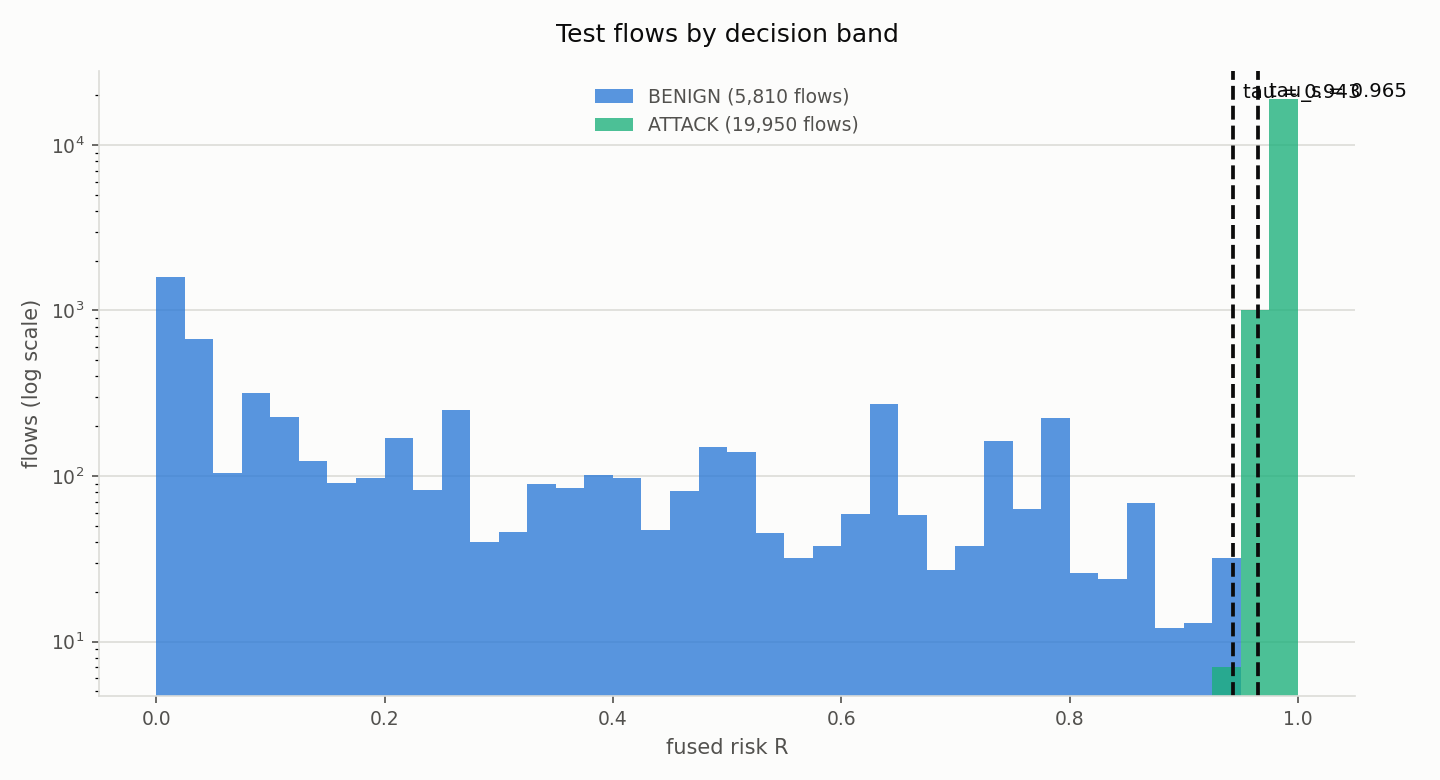


Files in C:\MSCAD2022\outputs_official\step14
  alert_explanations.csv                 1179.6 KB
  class_feature_ig_heatmap.png            124.7 KB
  deletion_check.png                       52.7 KB
  evidence_records.csv                     44.4 KB
  example_alert_contributions.png          68.9 KB
  example_alert_reports.md                 24.2 KB
  explanation_metrics.json                 10.2 KB
  explanation_validation.csv               64.7 KB
  explanations.csv                      13291.0 KB
  global_feature_importance.csv           200.3 KB
  global_top_features.png                 103.7 KB
  ig_vs_perturbation.png                   61.4 KB
  model_agreement.csv                      48.9 KB
  risk_bands.png                           42.3 KB
  signed_ig_boxplot.png                    64.2 KB
  step14_report.csv                         0.8 KB
  temporal_attribution.png             (not written)
  thresholds_step14.json                    0.5 KB


In [120]:
report = step14.get("report")
if report is not None and len(report):
    explainability.show_table(report, all_columns=True,
        note="Read back from disk after writing. A `[FAIL]` here means the "
             "saved file is wrong, whatever the in-memory numbers said.")

thresholds = step14.get("thresholds") or {}
if thresholds:
    explainability.show_table(explainability.kv_table([
        ("tau (Step 13)", "%.6f" % thresholds["tau"]),
        ("tau source", thresholds.get("tau_source")),
        ("tau_s (Step 14, validation)",
         "n/a" if thresholds.get("tau_s") is None
         else "%.6f" % thresholds["tau_s"]),
        ("tau_s validation recall",
         "%.4f" % (thresholds.get("tau_s_choice") or {}).get(
             "validation_recall", float("nan"))),
        ("tau_s validation FPR",
         "%.4f" % (thresholds.get("tau_s_choice") or {}).get(
             "validation_fpr", float("nan"))),
    ]), note="tau is Step 13's and is unchanged. tau_s is chosen on the "
             "validation split only and never touches tau.")

picture = config.STEP14_OUTPUT_DIR / config.STEP14_FILES["chart_bands"]
if picture.exists() and explainability.dl.in_notebook():
    from IPython.display import Image, display
    display(Image(filename=str(picture)))
elif not picture.exists():
    print("missing:", picture)

folder = config.STEP14_OUTPUT_DIR
if folder.exists():
    print()
    print("Files in", folder)
    for name in sorted(config.STEP14_FILES.values()):
        path = folder / name
        print("  %-36s %s" % (name, "%8.1f KB" % (path.stat().st_size / 1024)
                              if path.exists() else "(not written)"))

### 12.8 Summary

**Purpose** — State what the explanations support, and nothing more.

**Input** — The tables computed above.

**Method** — The text is composed by `explainability.step14_summary()` from
those tables: every figure is read off a computed table, and the verdict on the
deletion check is decided by the numbers rather than written in advance.

**Output** — Rendered here and stored in `explanation_metrics.json`, so the
resumable path shows the same text.

**Why** — A summary written by hand drifts from the tables beside it the moment
anything is re-run.

In [121]:
text = (step14.get("metrics") or {}).get("summary") or step14.get("summary")
if text:
    if explainability.dl.in_notebook():
        from IPython.display import Markdown, display
        display(Markdown(text))
    else:
        print(text)
else:
    print("No summary stored. Re-run with OVERWRITE_STEP14 = True.")

### Step 14 - what the explanations say

- Of 25,760 test flows, **19,950** are ATTACK (R >= tau = 0.9431), **0** fall in the SUSPICIOUS band (tau_s = 0.9652) and **5,810** are benign. 564 flows were explained, producing **539 alert reports**.
- `proposed`: top features by mean |IG| on the risk are `Flow Duration`, `SYN Flag Cnt`, `Fwd IAT Tot`; IG completeness holds for **19.7%** of flows (mean relative error 0.2328); stability under 0.010 noise: mean Spearman **0.666**, top-5 overlap 0.815.
- `baseline2_ae_lstm`: top features by mean |IG| on the risk are `SYN Flag Cnt`, `Flow Duration`, `ACK Flag Cnt`; IG completeness holds for **97.0%** of flows (mean relative error 0.0826); stability under 0.010 noise: mean Spearman **0.648**, top-5 overlap 0.889.
- `baseline3_cnn_lstm`: top features by mean |IG| on the risk are `SYN Flag Cnt`, `Fwd IAT Tot`, `Flow Duration`; IG completeness holds for **23.9%** of flows (mean relative error 0.0866); stability under 0.010 noise: mean Spearman **0.561**, top-5 overlap 0.597.
- `proposed`: IG agrees with direct perturbation at mean Spearman **0.506** (top-5 overlap 0.742; 24 of 564 flows disagree outright). Removing the top-5 attributed features costs 0.1348 risk against 0.1160 for 5 random features -- the attribution is informative.
- `baseline2_ae_lstm`: IG agrees with direct perturbation at mean Spearman **0.308** (top-5 overlap 0.693; 57 of 564 flows disagree outright). Removing the top-5 attributed features costs 0.6610 risk against 0.0791 for 5 random features -- the attribution is informative.
- `baseline3_cnn_lstm`: IG agrees with direct perturbation at mean Spearman **0.330** (top-5 overlap 0.410; 19 of 564 flows disagree outright). Removing the top-5 attributed features costs 0.2429 risk against 0.0702 for 5 random features -- the attribution is informative.
- Across the explained flows the three models were unanimous on 557, a majority on 7 and in outright disagreement on 0; the adaptive weighting changed the predicted class away from the simple average on **1** of them.
- R(x) = sum_m C_m holds to **1.0e-07** across every explained flow, so the per-model contributions in the reports add up to exactly the risk Step 13 published.
- Report confidence: High **12**, Medium **527**, Low **0**.
- Generation time per flow: IG `proposed` 29.41 ms; `baseline2_ae_lstm` 37.25 ms; `baseline3_cnn_lstm` 84.07 ms; perturbation `proposed` 9.00 ms; `baseline2_ae_lstm` 18.25 ms; `baseline3_cnn_lstm` 22.11 ms; fusion explanation 0.59 ms; report 4.34 ms per alert. This is how long the CODE takes, not how long an analyst takes.

**Four caveats, and they matter more here than anywhere else in this pipeline.**

1. **IG explains the model, not the world.** An attribution says which input the network leaned on. It is not evidence that the feature caused the attack, and a model that learned a shortcut will be explained faithfully as using that shortcut.
2. **The attack stage is a lookup.** `ATTACK_STAGE_MAP` turns the predicted label into a tactic name; an unmapped label is reported as `Unmapped`. Nothing here infers a multi-stage progression, and no report claims one.
3. **Source context is descriptive.** It lists other alerts from the same Src IP in the test subset, which is a random 20% of the flows, so a gap means "not in this subset", never "the source stopped". No model sees it.
4. **The rare classes have few explained alerts**, so a per-class attribution for them rests on a handful of flows: Brute_Force 200; HTTP_DDoS 129; ICMP_Flood 8; Port_Scan 200; Web_Crwling 2.

### What Step 12 can and cannot say

1. **An attribution explains the model, not the world.** It says which input the
   network leaned on. It is not evidence that the feature caused the attack, and
   a model that learned a shortcut is explained faithfully as using that
   shortcut. The right reading of a surprising attribution is to go and check the
   model, not to believe a new fact about attacks.
2. **The attack stage is a lookup of the predicted label.** `ATTACK_STAGE_MAP`
   names a MITRE tactic for a class; an unmapped label reports `Unmapped`.
   Nothing here observes a progression between stages, and no report claims one.
3. **Source context is descriptive, and drawn from a random subset.** It lists
   other test-set alerts from the same `Src IP`, and the official dataset has
   none, so it is skipped there. The test set is a random 20% of
   the flows, so flows in between may simply not be there. No model sees it, and
   it never changes a decision.
4. **The rare classes have few explained alerts.** A per-class attribution for a
   class with a handful of alerts is a handful of observations, not a profile.
5. **Completeness is a necessary check, not a sufficient one.** An attribution
   can add up perfectly and still be a poor guide to the model's behaviour --
   which is exactly why the perturbation comparison and the deletion check are
   run beside it, and why the flows where they disagree are counted rather than
   dropped.
6. **The explanation inherits every limitation of what it explains.** If the
   duplicate-heavy test set flatters the models (Step 10), it flatters their
   explanations too. Step 12 adds no evidence about the data; it only makes the
   models' reasoning visible.

---

### 12.9 Explainability across all approaches and baselines (Step 12 addendum)

**Purpose** — Step 12 explains the three fused models. This section explains
**every** configuration on its own named features, compares their reasoning, and
explains **each** fusion variant (F3, FALL, FSEL).

**Input** — The saved model, encoder and (for B4) PCA of every configuration,
Step 11's fused predictions, 11.8's `fused_predictions_all.csv`, and Step 12's
own `explanations.csv` — read, never recomputed.

**Method** — The Step 12 arithmetic, *called* rather than copied:
`integrated_gradients` on `tf.GradientTape`, `completeness_table`,
`perturbation_drops`, `deletion_check`, `stability`, `fusion_breakdown` and
`build_alert_report`, all from `explainability.py`.
`src/mscad/explainability_all.py` adds the three composed models Step 12 cannot
build (Approach 2, B4's PCA as a fixed linear map, B5), the cross-model
comparison and the presentation.

**Output** — `C:\MSCAD2022\outputs\step14_all\` — a folder of its own.

> **Nothing in Step 12 changes.** Every file in `step14\` is SHA-256
> fingerprinted before this section runs and again after it writes; the
> verification table at the end of 12.9.6 reports
> `the existing Step 12 outputs are byte-identical`, and the run **raises** if
> one moved. `explanation_metrics.json` and `alert_explanations.csv` are called
> out by name there.

> **Nothing is retrained.** Model, encoder, PCA, fusion weights and every
> threshold are loaded. A configuration that is not on this machine is skipped
> by name, with the cells that produce it.

**Attributions live on the original features.** Each model is composed into one
differentiable function from *its own* named inputs to softmax probabilities —
features → encoder → (PCA) → classifier → softmax — so an attribution names a
CICFlowMeter feature, never a latent unit or a PCA component. Each composed
model is checked against the probabilities its own step saved (1e-5) before it
is allowed to explain anything.

**Every learned setting comes from training or validation.** The IG baseline
$x'$ is the median of the **training** benign rows in each model's own input
space; $\tau$ is Step 11's, unchanged; $\tau_s$ comes from the Step 7 validation
split; and the fusion variant the alert reports explain is chosen on
**validation** macro-F1.

> **Computed before Baseline 6 was added.** The tables and figures in this section cover the configurations that existed when it last ran. To include **B6: AE -> PCA -> CNN-LSTM**, set `OVERWRITE_STEP14ALL = True` in `config.py` and re-run this section; `XAI_ALL_MODELS` already lists it.
>
> Check Step 10.0's provenance report first: if it found that this section was computed from **different Approach 1 predictions** than the ones on disk now, re-running is not optional -- the numbers here describe a model that has since changed.

In [122]:
# 14.9 runs on its own after a kernel restart, so this cell sets up the import
# path and imports everything the section uses rather than relying on a cell
# from an earlier step. Run this one first, then the rest of 14.9 in order.
import os
import sys
from pathlib import Path

_here = Path.cwd()
_project = _here if (_here / "config.py").exists() else _here.parent
if str(_project) not in sys.path:
    sys.path.insert(0, str(_project))

# Quieten TensorFlow's C++ logger for this section only.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

import numpy as np
import pandas as pd

import config
from src.mscad import explainability_all
xa = explainability_all                      # the short name 14.9's cells use

# Rendering: available in Jupyter, absent in a plain terminal. Every 14.9 cell
# goes through xa.present / xa.show_chart / xa.show_reading, which fall back to
# plain text on their own; these three are imported for the cells that render a
# markdown block or an image directly.
try:
    from IPython.display import Image, Markdown, display
except ImportError:                          # pragma: no cover - no IPython
    Image = Markdown = display = None

print("14.9 ready: %s | %s | models offered: %d"
      % (str(_project), "notebook" if xa.dl.in_notebook() else "terminal",
         len(config.XAI_ALL_MODELS)))

14.9 ready: C:\Users\banot\MSCAD22-Multi-Stage-Cyber-Attack-Detection\Notebook | notebook | models offered: 8


In [123]:
# The imports are in the 14.9 setup cell above.
xa.present(pd.DataFrame([
    {"setting": "output folder", "value": str(config.STEP14ALL_OUTPUT_DIR)},
    {"setting": "configurations offered", "value": len(config.XAI_ALL_MODELS)},
    {"setting": "alert fusion variant", "value": config.ALERT_FUSION_VARIANT},
    {"setting": "IG steps / baseline",
     "value": "%d / %s" % (config.IG_STEPS, config.IG_BASELINE)},
    {"setting": "flows explained per class (Step 14's setting)",
     "value": config.EXPLAIN_SAMPLE_PER_CLASS},
    {"setting": "top-K features in a report", "value": config.TOP_K_FEATURES},
    {"setting": "completeness tolerance",
     "value": "%.0f%%" % (100 * config.COMPLETENESS_TOL)},
    {"setting": "stability: noise / repeats",
     "value": "%.3f / %d" % (config.STABILITY_NOISE_STD,
                             config.STABILITY_N_REPEATS)},
    {"setting": "OVERWRITE_STEP14ALL", "value": config.OVERWRITE_STEP14ALL},
]), caption="The 14.9 settings. Everything below the fourth row is the Step 14 "
            "block, reused unchanged: FALL, FSEL and F3 are explained with the "
            "same attribution settings as Step 14 used.")

setting,value
output folder,C:\MSCAD2022\outputs_official\step14_all
configurations offered,8
alert fusion variant,auto
IG steps / baseline,64 / benign_median
flows explained per class (Step 14's setting),200
top-K features in a report,5
completeness tolerance,5%
stability: noise / repeats,0.010 / 5
OVERWRITE_STEP14ALL,False


### Run 12.9

One status line per model as it is explained — nothing else is printed. With
`OVERWRITE_STEP14ALL = False` a finished run is read straight back from disk.

> **This is the slow cell.** Integrated Gradients with `IG_STEPS = 64`, a
> perturbation pass over every feature, a deletion check and a stability pass,
> for each of up to seven models: **20–60 minutes on CPU** is normal. Every
> table and chart below is read from what it returns.

In [124]:
step14_all = explainability_all.run_step14all()

,metric,value
0,status,loaded from disk (OVERWRITE_STEP14ALL = False)
1,folder,C:\MSCAD2022\outputs_official\step14_all
2,models explained,"Approach 1: FS -> AE -> CNN-LSTM, Approach 2: ..."
3,alert variant,FSEL
4,alerts reported,783


_Set `OVERWRITE_STEP14ALL = True` in config.py to recompute._

### 12.9.1 Composed models on the original named features

Below: one row per configuration — whether it was available, how many named
features it attributes onto, and whether its composed form reproduces the
probabilities its own step saved.

In [125]:
availability = step14_all.get("availability")
if availability is not None and len(availability):
    xa.present(availability[["model", "available", "input features",
                             "composed", "note"]],
               caption="Every configuration offered to 14.9. `composed` is the "
                       "1e-5 check against that model's own saved "
                       "predictions.csv; a model that fails it is not "
                       "explained, because its attributions would describe a "
                       "different model.",
               count_columns=["input features"])
    ready = availability[availability["available"]]
    xa.show_reading(
        "%d of %d configurations are explained, on %s named features "
        "respectively; %s."
        % (len(ready), len(availability),
           " / ".join(str(int(v)) for v in ready["input features"]),
           "every composed model reproduces its saved probabilities"
           if set(ready["composed"]) <= {"[OK]", "[SKIP]"}
           else "see the note column for the ones that did not"))

baselines = step14_all.get("ig_baselines")
if baselines is not None and len(baselines):
    xa.present(baselines, caption="The IG baseline x' per model: the median of "
                                  "the TRAINING benign rows in that model's own "
                                  "input space, and the attack risk the model "
                                  "gives it.",
               best=["attack risk at the baseline F(x')"],
               lower_is_better=["attack risk at the baseline F(x')"],
               count_columns=["input features", "IG steps"])
    worst = baselines["attack risk at the baseline F(x')"].max()
    xa.show_reading(
        "A baseline should look benign to the model it is used with: the "
        "highest F(x') across the models is %.3f%s."
        % (worst, ", which is low enough for the attributions below to be "
           "measured against a normal flow" if worst < 0.5 else
           " -- read that model's attributions knowing its reference point is "
           "not clearly benign"))

model,available,input features,composed,note
Approach 1: FS -> AE -> CNN-LSTM,yes,30,[SKIP],no saved predictions.csv to check against
Approach 2: FS -> AE -> CNN-Attention-LSTM,yes,30,[OK],--
B1: AE -> CNN-LSTM (no selection),yes,67,[OK],--
B2: AE -> LSTM (no CNN),yes,67,[OK],--
B3: CNN-LSTM (no AE),yes,67,[OK],--
B4: AE -> PCA -> LSTM,yes,67,[OK],--
B5: MI-only top 30 -> AE -> CNN-LSTM,yes,30,[OK],--
B6: AE -> PCA -> CNN-LSTM,yes,67,[OK],--


**Reading:** 8 of 8 configurations are explained, on 30 / 30 / 67 / 67 / 67 / 67 / 30 / 67 named features respectively; every composed model reproduces its saved probabilities.

model,input features,baseline,attack risk at the baseline F(x'),IG steps
Approach 1: FS -> AE -> CNN-LSTM,30,benign_median,0.9014,64
Approach 2: FS -> AE -> CNN-Attention-LSTM,30,benign_median,0.0360,64
B1: AE -> CNN-LSTM (no selection),67,benign_median,0.8158,64
B2: AE -> LSTM (no CNN),67,benign_median,0.0463,64
B3: CNN-LSTM (no AE),67,benign_median,0.6050,64
B4: AE -> PCA -> LSTM,67,benign_median,0.8858,64
B5: MI-only top 30 -> AE -> CNN-LSTM,30,benign_median,0.1769,64
B6: AE -> PCA -> CNN-LSTM,67,benign_median,0.2145,64


**Reading:** A baseline should look benign to the model it is used with: the highest F(x') across the models is 0.901 -- read that model's attributions knowing its reference point is not clearly benign.

In [126]:
checks = step14_all.get("verification")
if checks is not None and len(checks):
    part = checks[checks["section"] == "14.9.1 composed models"]
    xa.present(part[["check", "result", "detail"]],
               caption="Verification -- 14.9.1.",
               full_file=config.STEP14ALL_FILES["verification"])

check,result,detail
Approach 1: FS -> AE -> CNN-LSTM reproduces its saved probabilities,[SKIP],this configuration saved no predictions.csv to compare against
Approach 2: FS -> AE -> CNN-Attention-LSTM reproduces its saved probabilities,[OK],composed model reproduces the saved probabilities
B1: AE -> CNN-LSTM (no selection) reproduces its saved probabilities,[OK],composed model reproduces the saved probabilities
B2: AE -> LSTM (no CNN) reproduces its saved probabilities,[OK],composed model reproduces the saved probabilities
B3: CNN-LSTM (no AE) reproduces its saved probabilities,[OK],composed model reproduces the saved probabilities
B4: AE -> PCA -> LSTM reproduces its saved probabilities,[OK],composed model reproduces the saved probabilities
B5: MI-only top 30 -> AE -> CNN-LSTM reproduces its saved probabilities,[OK],composed model reproduces the saved probabilities
B6: AE -> PCA -> CNN-LSTM reproduces its saved probabilities,[OK],composed model reproduces the saved probabilities


### 12.9.2 Integrated Gradients for every model

Below: what each model's attributions cost and how well they hold up — the
deletion check (does removing the attributed features cost the model more than
removing random ones?) and, for Approach 2 only, the attention view.

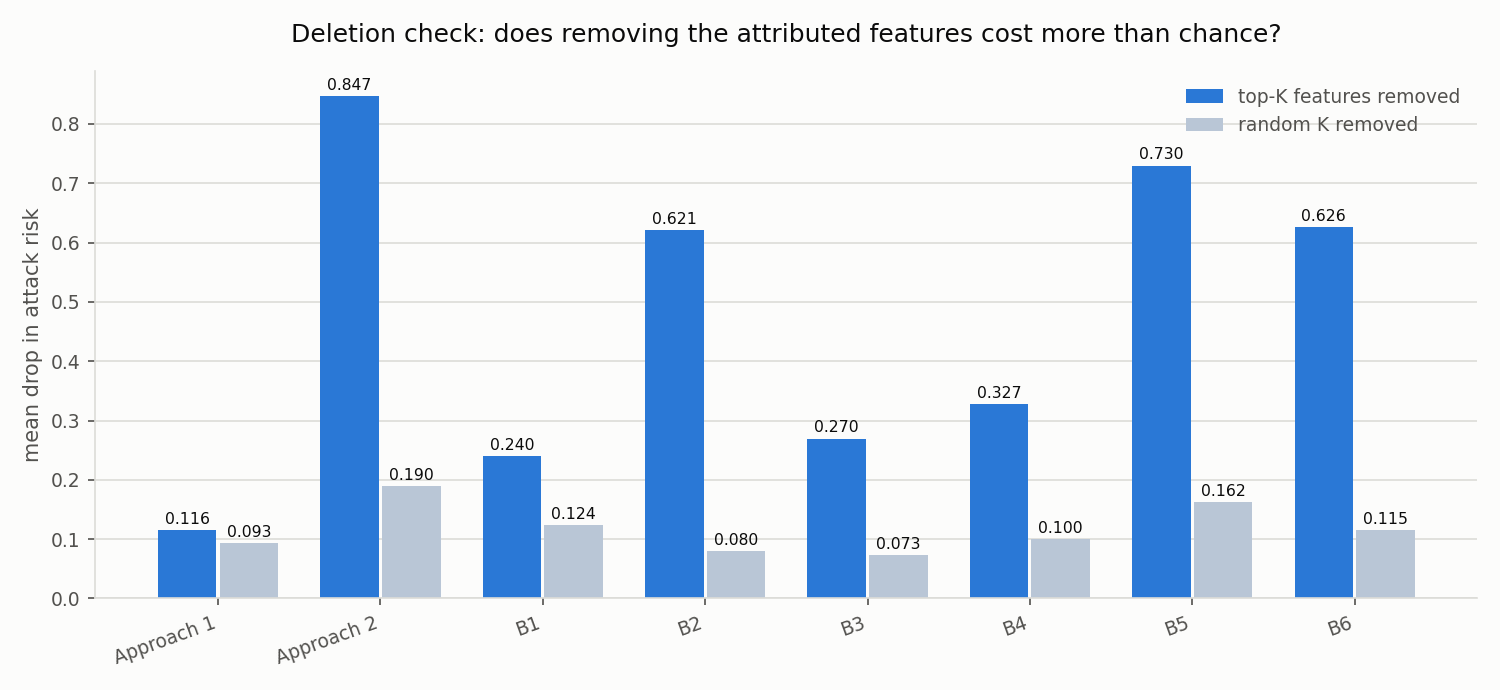

**Reading:** Removing the top-attributed features costs Approach 2 the most (0.6574 of attack risk above a random removal of the same size) and Approach 1 the least (0.0228); a gap at or below zero would mean that model's ranking tells an analyst nothing.

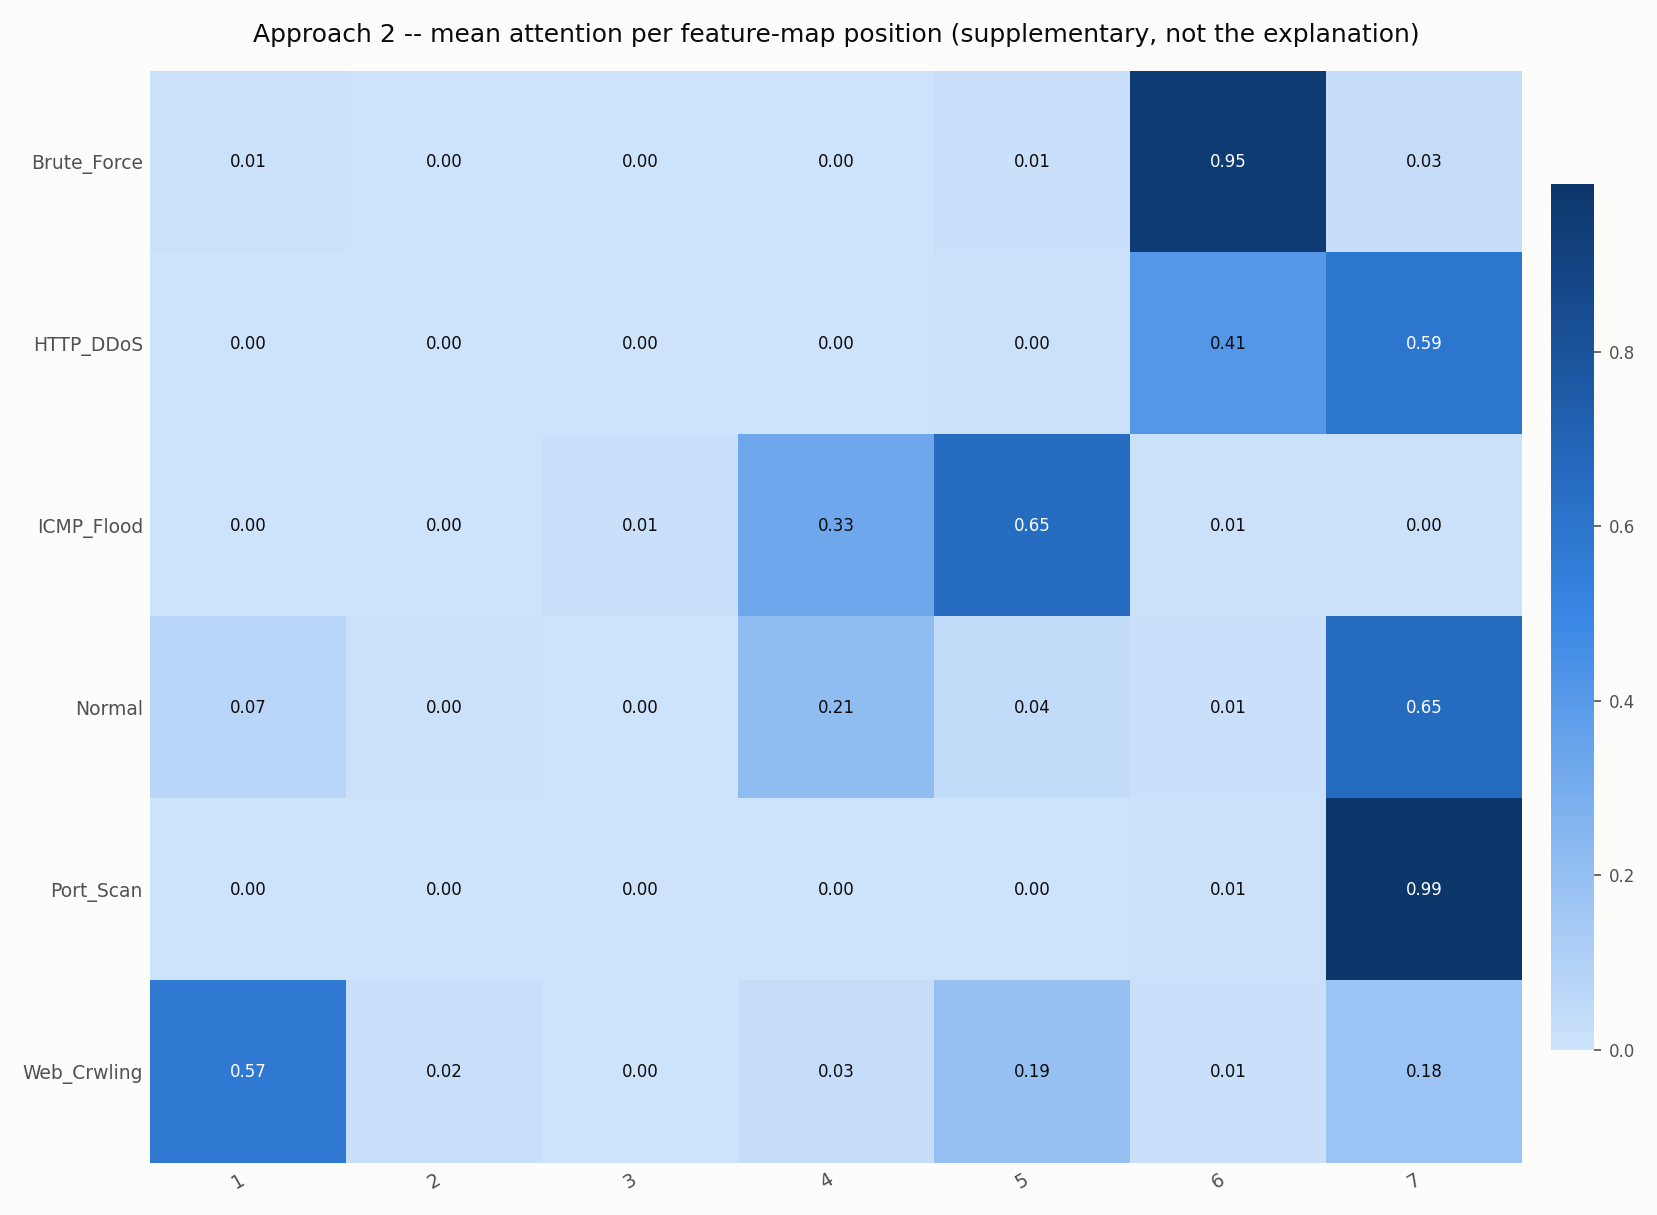

**Reading:** SUPPLEMENTARY, not the explanation: Approach 2's attention is heaviest on position 7 for Port_Scan (mean 0.993). Positions are CNN feature-map slots, not input features, so this cannot name a flow feature -- the IG tables above do that.

In [127]:
xa.show_chart(config.STEP14ALL_OUTPUT_DIR
              / config.STEP14ALL_FILES["chart_deletion"])
quality = step14_all.get("quality")
if quality is not None and len(quality):
    column = [c for c in quality.columns if c.startswith("deletion gap")][0]
    best = quality.loc[quality[column].idxmax()]
    worst = quality.loc[quality[column].idxmin()]
    xa.show_reading(
        "Removing the top-attributed features costs %s the most (%.4f of "
        "attack risk above a random removal of the same size) and %s the least "
        "(%.4f); a gap at or below zero would mean that model's ranking tells "
        "an analyst nothing."
        % (best["model"].split(":")[0], best[column],
           worst["model"].split(":")[0], worst[column]))

attention = step14_all.get("attention")
if attention is not None and len(attention):
    xa.show_chart(config.STEP14ALL_OUTPUT_DIR
                  / config.STEP14ALL_FILES["chart_attention"])
    top = attention.loc[attention["mean attention"].idxmax()]
    xa.show_reading(
        "SUPPLEMENTARY, not the explanation: Approach 2's attention is heaviest "
        "on position %d for %s (mean %.3f). Positions are CNN feature-map "
        "slots, not input features, so this cannot name a flow feature -- the "
        "IG tables above do that."
        % (top["position"], top["predicted class"], top["mean attention"]))

In [128]:
part = checks[checks["section"] == "14.9.2 attribution"] if checks is not None \
    else pd.DataFrame()
if len(part):
    xa.present(part[["check", "result", "detail"]],
               caption="Verification -- 14.9.2. The completeness check is the "
                       "IG identity sum IG = F(x) - F(x'); the deletion check "
                       "is informativeness, and a [FAIL] there is a finding "
                       "about that model's attributions, not a broken run.",
               full_file=config.STEP14ALL_FILES["verification"])

check,result,detail
the flows Step 14 explained are explained here too,[OK],"564 from Step 14, 268 added from FSEL alerts, 832 explained in all"
Approach 1: FS -> AE -> CNN-LSTM: sum IG = F(x) - F(x') within 5%,[FAIL],19.4% of explained flows
Approach 1: FS -> AE -> CNN-LSTM: removing the top-5 costs more than chance,[OK],top-K 0.1157 vs random 0.0929
Approach 2: FS -> AE -> CNN-Attention-LSTM: sum IG = F(x) - F(x') within 5%,[OK],75.6% of explained flows
Approach 2: FS -> AE -> CNN-Attention-LSTM: removing the top-5 costs more than chance,[OK],top-K 0.8474 vs random 0.1900
B1: AE -> CNN-LSTM (no selection): sum IG = F(x) - F(x') within 5%,[FAIL],36.2% of explained flows
B1: AE -> CNN-LSTM (no selection): removing the top-5 costs more than chance,[OK],top-K 0.2403 vs random 0.1241
B2: AE -> LSTM (no CNN): sum IG = F(x) - F(x') within 5%,[OK],96.6% of explained flows
B2: AE -> LSTM (no CNN): removing the top-5 costs more than chance,[OK],top-K 0.6209 vs random 0.0800
B3: CNN-LSTM (no AE): sum IG = F(x) - F(x') within 5%,[FAIL],25.0% of explained flows


### 12.9.3 Cross-model comparison of the explanations

Below: what each model leans on, where the models agree, and whose explanations
survive their own checks.

rank,Approach 1: FS -> AE -> CNN-LSTM,Approach 2: FS -> AE -> CNN-Attention-LSTM,B1: AE -> CNN-LSTM (no selection),B2: AE -> LSTM (no CNN),B3: CNN-LSTM (no AE),B4: AE -> PCA -> LSTM,B5: MI-only top 30 -> AE -> CNN-LSTM,B6: AE -> PCA -> CNN-LSTM
#1,Flow Duration,Flow Duration,Flow Duration,SYN Flag Cnt,SYN Flag Cnt,Flow Duration,Flow Duration,Flow Duration
#2,SYN Flag Cnt,SYN Flag Cnt,SYN Flag Cnt,Flow Duration,Fwd IAT Tot,SYN Flag Cnt,Bwd Pkt Len Max,ACK Flag Cnt
#3,Fwd IAT Tot,Fwd IAT Tot,Bwd Pkt Len Max,ACK Flag Cnt,Flow Duration,ACK Flag Cnt,Bwd Pkt Len Mean,SYN Flag Cnt
#4,Pkt Len Mean,Pkt Len Mean,Bwd Pkt Len Std,Bwd Pkt Len Std,Pkt Len Mean,Fwd IAT Tot,Flow IAT Max,Bwd Pkt Len Mean
#5,Init Bwd Win Byts,Flow IAT Max,ACK Flag Cnt,Bwd Pkt Len Mean,Bwd Seg Size Avg,Bwd Pkt Len Max,Pkt Len Mean,Bwd Pkt Len Max
#6,Flow IAT Max,Bwd Pkts/s,Bwd Seg Size Avg,Bwd Seg Size Avg,ACK Flag Cnt,Flow IAT Max,Bwd Seg Size Avg,Bwd Seg Size Avg
#7,Bwd Pkts/s,Fwd IAT Max,FIN Flag Cnt,FIN Flag Cnt,Pkt Len Std,Bwd Pkt Len Mean,Init Bwd Win Byts,Fwd IAT Max
#8,Flow IAT Mean,Init Bwd Win Byts,Fwd IAT Tot,Pkt Len Mean,Pkt Size Avg,Bwd Seg Size Avg,Pkt Size Avg,FIN Flag Cnt
#9,Fwd IAT Max,Bwd IAT Tot,Bwd Pkt Len Mean,Bwd Pkt Len Max,Fwd IAT Max,Pkt Len Mean,Bwd Pkts/s,Pkt Size Avg
#10,Bwd IAT Tot,Flow IAT Mean,Pkt Len Mean,Fwd IAT Tot,FIN Flag Cnt,Bwd Pkts/s,Flow IAT Mean,Fwd IAT Tot


**Reading:** `Flow Duration` is the top feature for 6 of the 8 explained models.

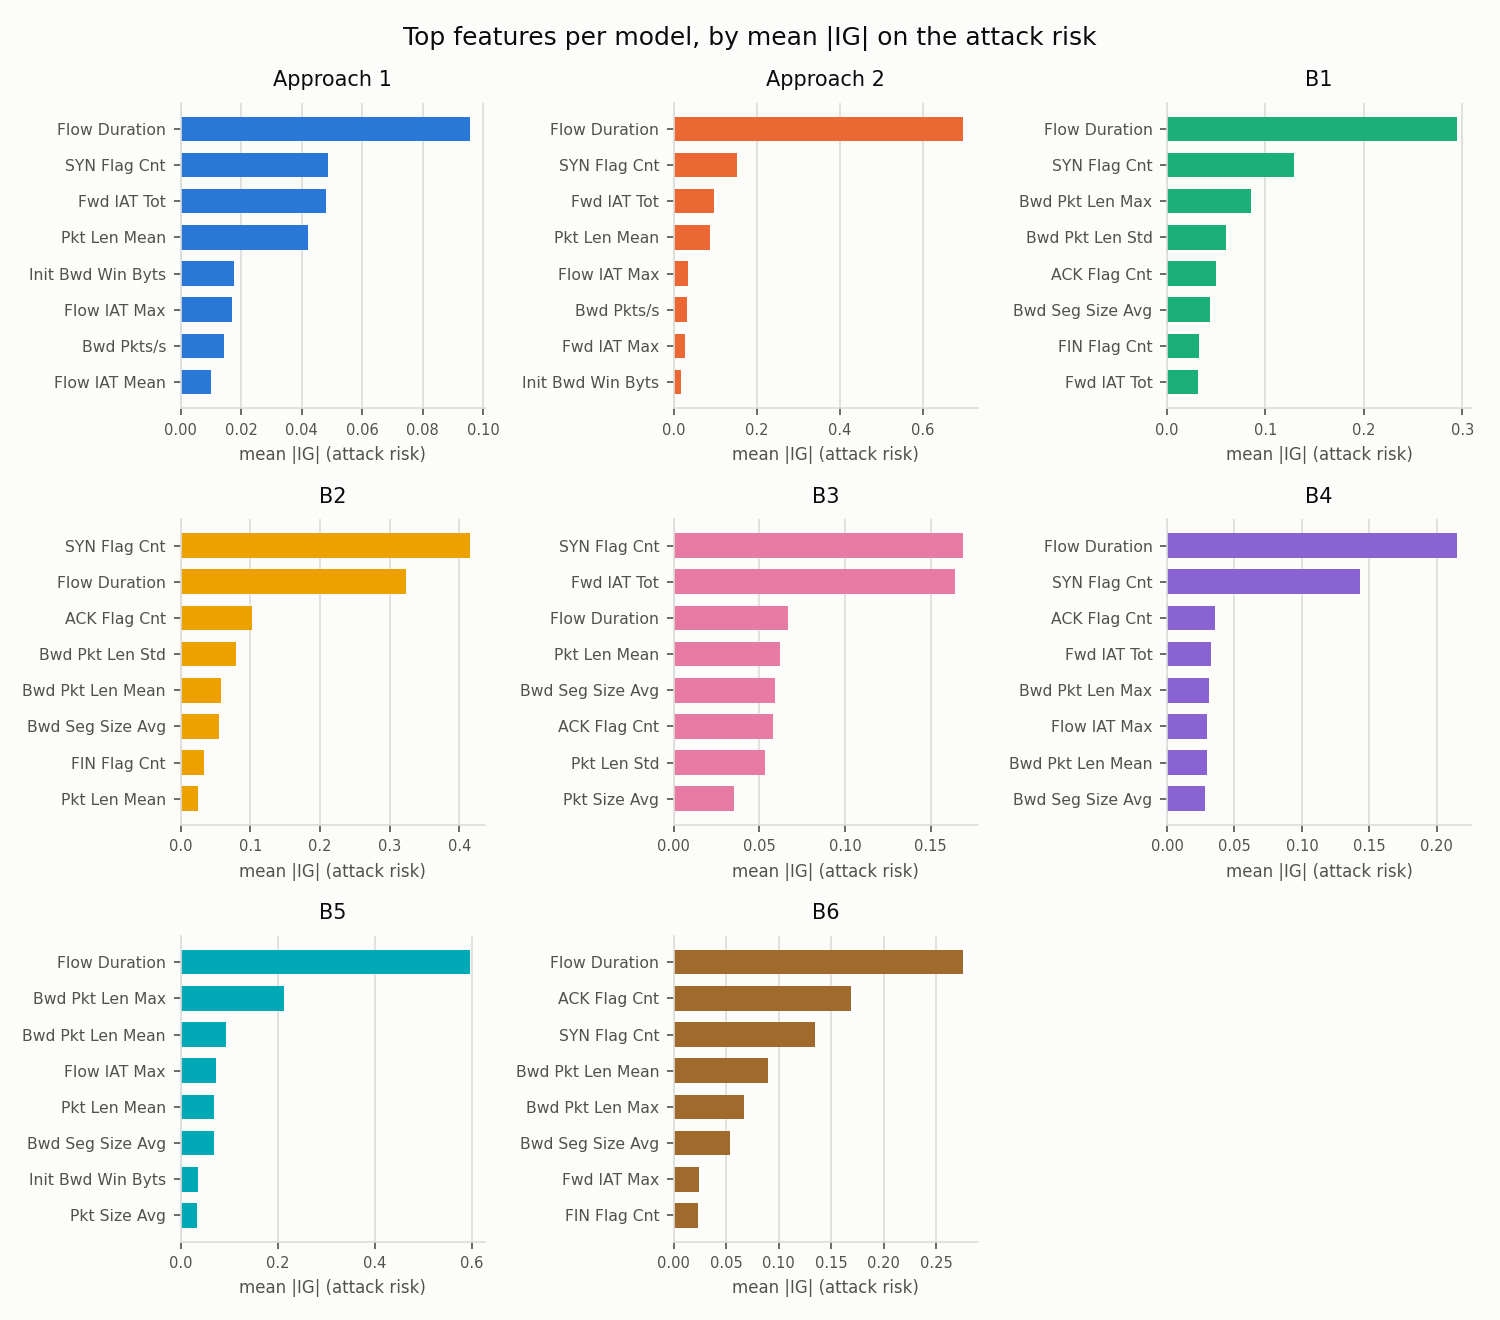

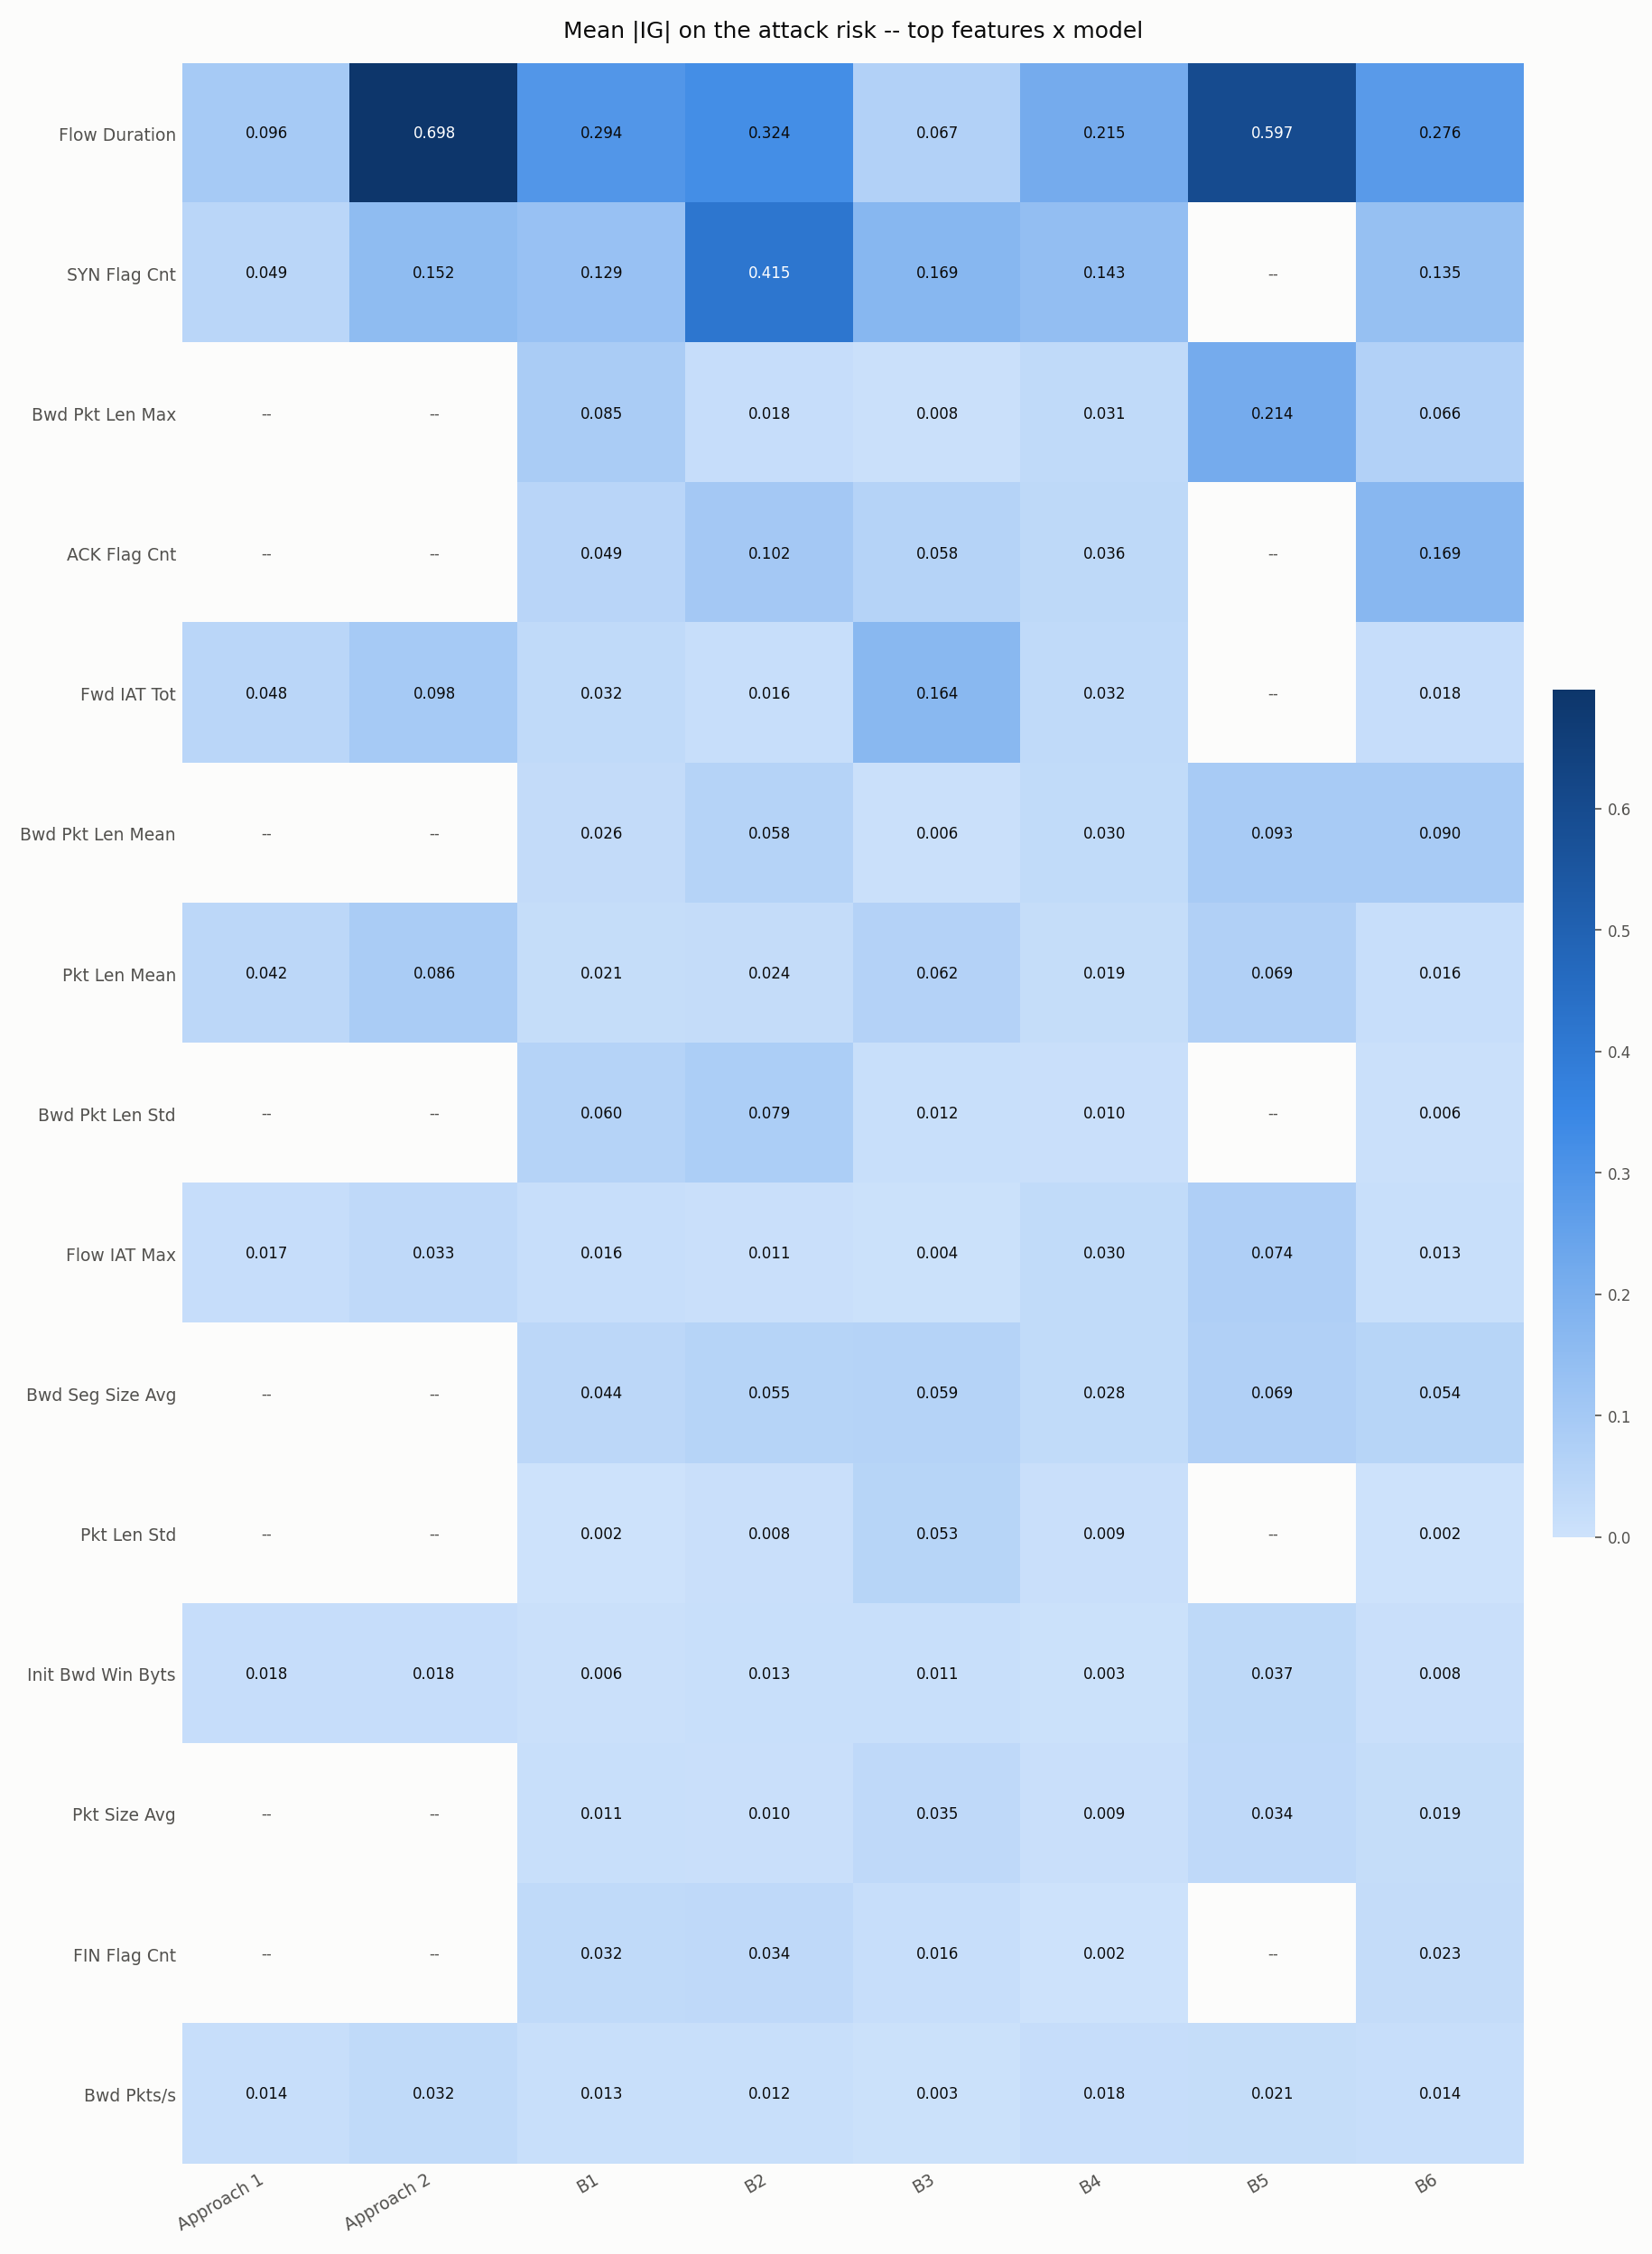

In [129]:
matrix = step14_all.get("importance_matrix")
if matrix is not None and len(matrix):
    table = xa.top_feature_table(matrix)
    xa.present(table, caption="Each model's top features by mean |IG| on the "
                              "attack risk, strongest first. A model's own "
                              "input set is all it can rank.",
               full_file=config.STEP14ALL_FILES["global_importance"],
               na_footnote=True)
    first = [str(table[c].iloc[0]) for c in table.columns if c != "rank"]
    top = max(set(first), key=first.count)
    xa.show_reading("`%s` is the top feature for %d of the %d explained models."
                    % (top, first.count(top), len(first)))
    xa.show_chart(config.STEP14ALL_OUTPUT_DIR
                  / config.STEP14ALL_FILES["chart_global"])
    xa.show_chart(config.STEP14ALL_OUTPUT_DIR
                  / config.STEP14ALL_FILES["chart_feature_heatmap"])

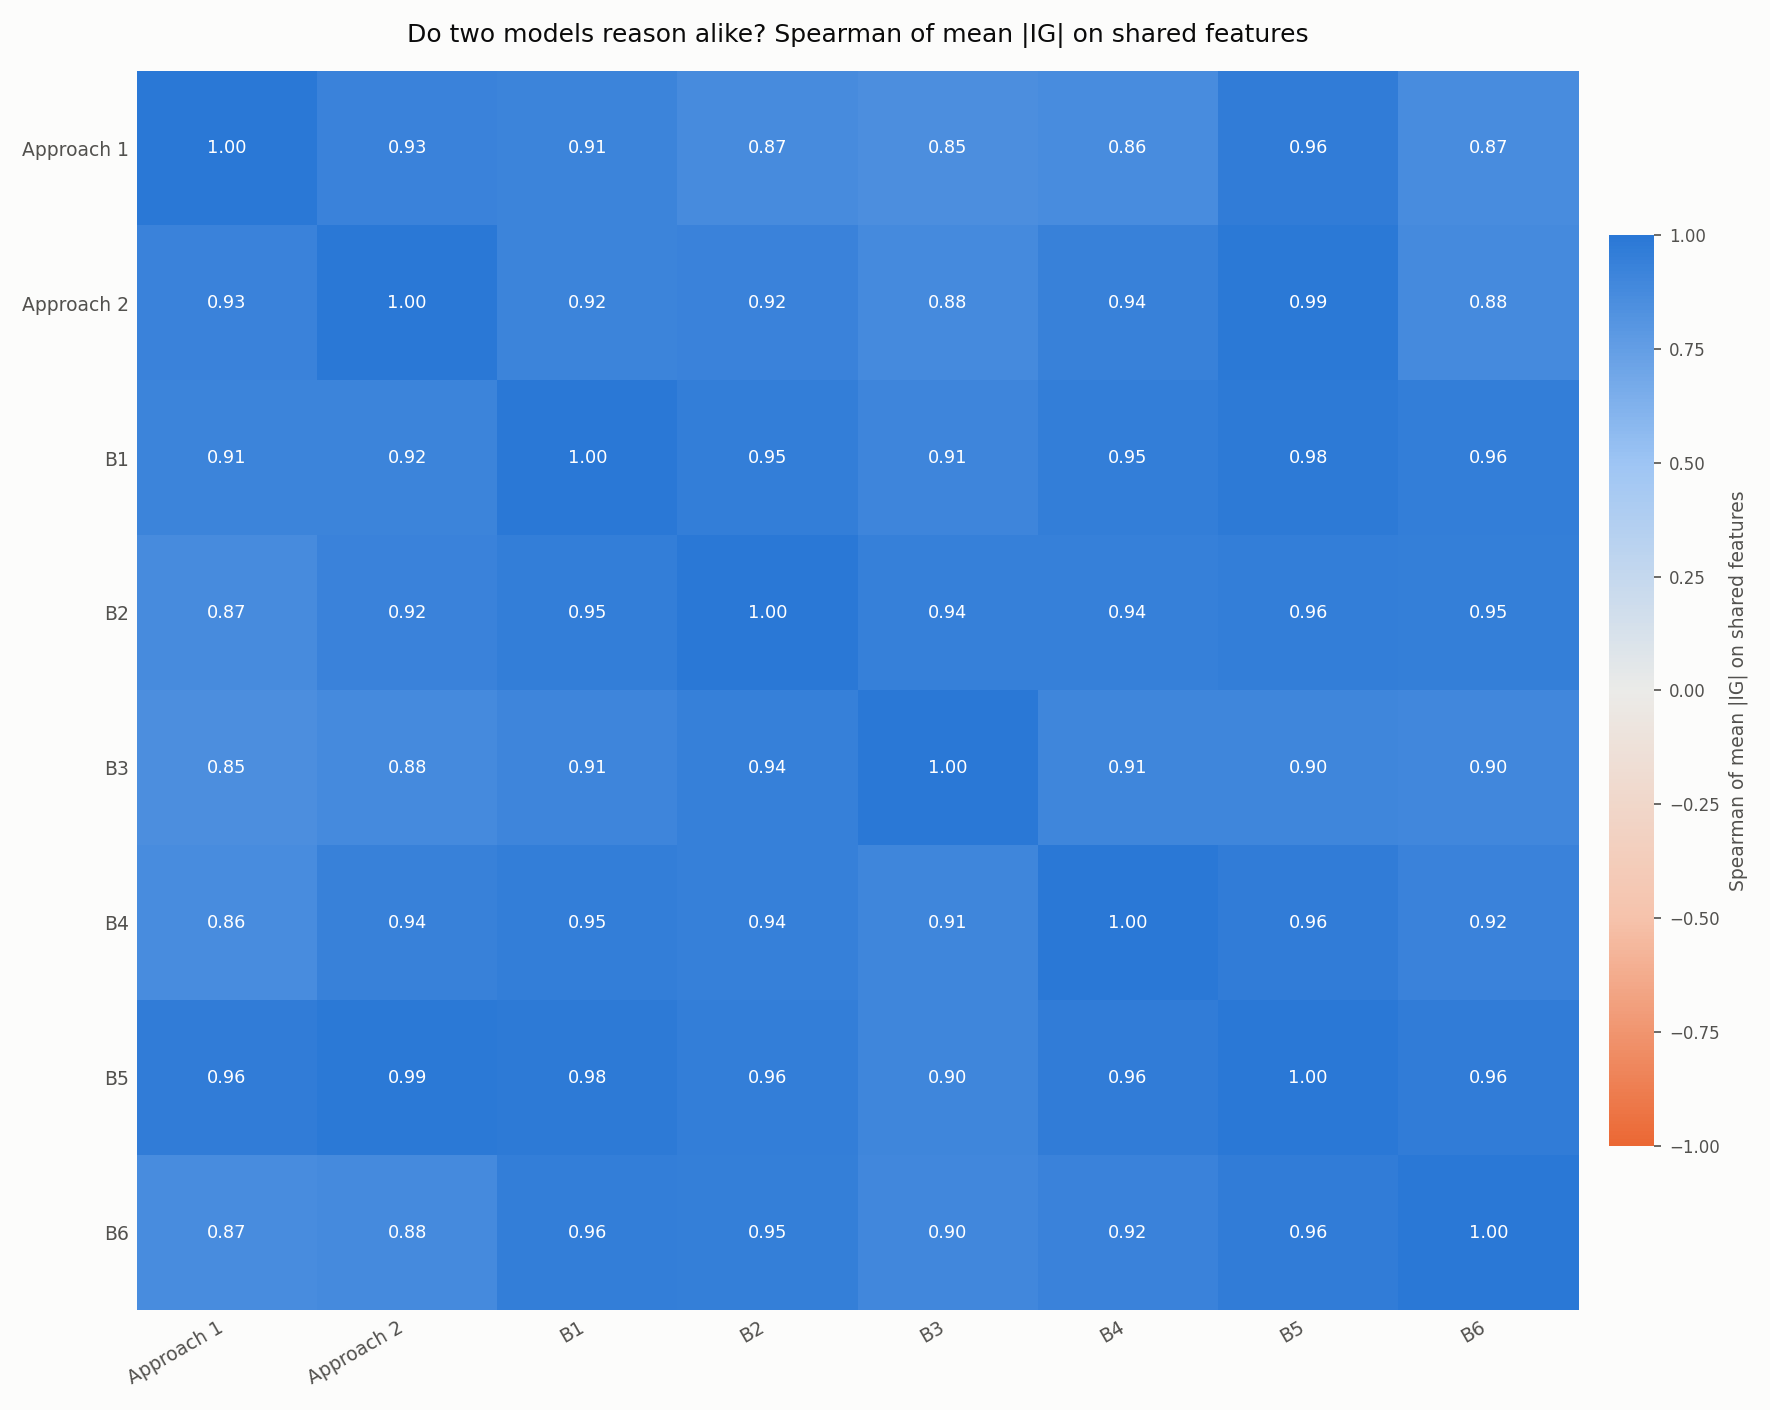

**Reading:** Approach 2 and B5 reason most alike (Spearman 0.99 on their shared features); Approach 1 and B3 least (0.85). Agreement is measured only where both models take the same feature as input.

feature,in top-10 of,models that can see it,share of those models,models,only this model
Flow Duration,8.0000,8,1.0000,"Approach 1, Approach 2, B1, B2, B3, B4, B5, B6",--
Fwd IAT Tot,7.0000,7,1.0000,"Approach 1, Approach 2, B1, B2, B3, B4, B6",--
SYN Flag Cnt,7.0000,7,1.0000,"Approach 1, Approach 2, B1, B2, B3, B4, B6",--
Pkt Len Mean,7.0000,8,0.8750,"Approach 1, Approach 2, B1, B2, B3, B4, B5",--
Bwd Seg Size Avg,6.0000,6,1.0000,"B1, B2, B3, B4, B5, B6",--
ACK Flag Cnt,5.0000,5,1.0000,"B1, B2, B3, B4, B6",--
Bwd Pkt Len Max,5.0000,6,0.8333,"B1, B2, B4, B5, B6",--
Bwd Pkt Len Mean,5.0000,6,0.8333,"B1, B2, B4, B5, B6",--
FIN Flag Cnt,4.0000,5,0.8000,"B1, B2, B3, B6",--
Fwd IAT Max,4.0000,7,0.5714,"Approach 1, Approach 2, B3, B6",--


**Reading:** `Flow Duration` is the widest consensus (8 of the 8 models that can see it); 18 feature(s) are ranked that highly by exactly one model, which is where the models' reasoning parts company.

In [130]:
agreement = step14_all.get("agreement_spearman")
if agreement is not None and len(agreement):
    xa.show_chart(config.STEP14ALL_OUTPUT_DIR
                  / config.STEP14ALL_FILES["chart_agreement"])
    values = agreement.to_numpy(dtype="float64").copy()
    np.fill_diagonal(values, np.nan)
    flat = [(agreement.index[i], agreement.columns[j], values[i, j])
            for i in range(values.shape[0]) for j in range(values.shape[1])
            if i < j and not np.isnan(values[i, j])]
    if flat:
        close = max(flat, key=lambda f: f[2])
        far = min(flat, key=lambda f: f[2])
        xa.show_reading(
            "%s and %s reason most alike (Spearman %.2f on their shared "
            "features); %s and %s least (%.2f). Agreement is measured only "
            "where both models take the same feature as input."
            % (close[0].split(":")[0], close[1].split(":")[0], close[2],
               far[0].split(":")[0], far[1].split(":")[0], far[2]))

consensus = step14_all.get("consensus")
if consensus is not None and len(consensus):
    xa.present(consensus, caption="Features in several models' top lists, and "
                                  "features only one model ranks that highly.",
               top=10, full_file=config.STEP14ALL_FILES["consensus"],
               count_columns=["models that can see it"])
    widest = consensus.iloc[0]
    alone = consensus[consensus["only this model"] != ""]
    xa.show_reading(
        "`%s` is the widest consensus (%d of the %d models that can see it); "
        "%d feature(s) are ranked that highly by exactly one model, which is "
        "where the models' reasoning parts company."
        % (widest["feature"], widest[consensus.columns[1]],
           widest["models that can see it"], len(alone)))

model,completeness within tolerance (%),IG vs perturbation (Spearman),top-5 overlap with perturbation,deletion gap (top-5 - random),stability (Spearman under noise),IG ms per flow,F(x') attack risk,explained flows
Approach 1: FS -> AE -> CNN-LSTM,19.4,0.4990,0.7421,0.0228,0.6769,26.2500,0.9014,832
Approach 2: FS -> AE -> CNN-Attention-LSTM,75.6,0.4865,0.7303,0.6574,0.6640,30.1600,0.0360,832
B1: AE -> CNN-LSTM (no selection),36.2,0.2020,0.6606,0.1161,0.6991,26.7000,0.8158,832
B2: AE -> LSTM (no CNN),96.6,0.2439,0.6909,0.5408,0.6572,29.3400,0.0463,832
B3: CNN-LSTM (no AE),25.0,0.3191,0.3870,0.1965,0.5599,71.5900,0.6050,832
B4: AE -> PCA -> LSTM,49.0,0.4868,0.6425,0.2268,0.7057,18.1700,0.8858,832
B5: MI-only top 30 -> AE -> CNN-LSTM,83.5,0.2519,0.6238,0.5677,0.7496,28.0600,0.1769,832
B6: AE -> PCA -> CNN-LSTM,70.9,0.1766,0.5572,0.5109,0.6697,18.0100,0.2145,832


**Reading:** B2 has the most faithful attributions (96.6% of flows within the completeness tolerance) and B5 the most stable ones (Spearman 0.750 under noise); cost ranges from 18.0 to 71.6 ms per flow.

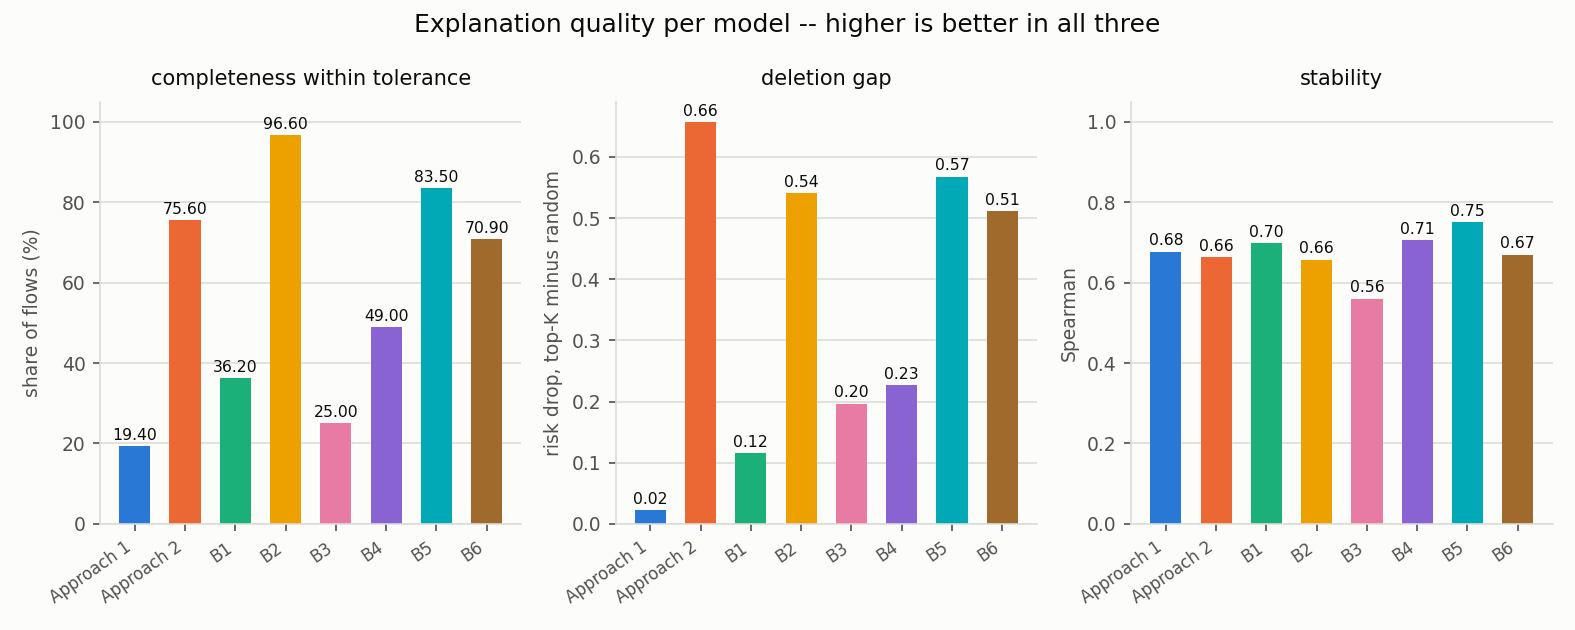

check,result,detail
"a feature outside a model's inputs is NA, not zero",[OK],111 of 536 cells are NA


In [131]:
if quality is not None and len(quality):
    column = [c for c in quality.columns if c.startswith("deletion gap")][0]
    xa.present(quality,
               caption="Explanation quality, one row per model. Completeness is "
                       "the share of flows where sum IG = F(x) - F(x') within "
                       "the tolerance; the Spearman columns compare IG against "
                       "the perturbation check and against itself under noise.",
               best=["completeness within tolerance (%)",
                     "IG vs perturbation (Spearman)", column,
                     "stability (Spearman under noise)", "IG ms per flow"],
               lower_is_better=["IG ms per flow"],
               percent_columns=["completeness within tolerance (%)"],
               count_columns=["explained flows"],
               full_file=config.STEP14ALL_FILES["quality"])
    best = quality.loc[quality["completeness within tolerance (%)"].idxmax()]
    stable = quality.loc[quality["stability (Spearman under noise)"].idxmax()]
    xa.show_reading(
        "%s has the most faithful attributions (%.1f%% of flows within the "
        "completeness tolerance) and %s the most stable ones (Spearman %.3f "
        "under noise); cost ranges from %.1f to %.1f ms per flow."
        % (best["model"].split(":")[0],
           best["completeness within tolerance (%)"],
           stable["model"].split(":")[0],
           stable["stability (Spearman under noise)"],
           quality["IG ms per flow"].min(), quality["IG ms per flow"].max()))
    xa.show_chart(config.STEP14ALL_OUTPUT_DIR
                  / config.STEP14ALL_FILES["chart_quality"])

part = checks[checks["section"] == "14.9.3 cross-model"] if checks is not None \
    else pd.DataFrame()
if len(part):
    xa.present(part[["check", "result", "detail"]],
               caption="Verification -- 14.9.3.")

### 12.9.4 Fusion explanation for every variant

Below: how each fusion variant splits its risk across its models, with
$R = \sum_m C_m$ checked against the risk each variant's own saved file
records, and where the variants decide differently.

variant,models fused,models,tau,validation macro-F1,alerts among the explained flows,max |R - sum C_m|,explains the alert reports
F3,3,"Approach 1, B2, B3",0.9431,0.6888,775,0.0000,no
FALL,7,"Approach 1, Approach 2, B1, B2, B3, B4, B5",0.8819,0.6758,780,0.0000,no
FSEL,3,"B1, B3, B5",0.9364,0.7415,783,0.0000,yes


**Reading:** Across 3 variant(s) the largest gap between R and the sum of the contributions is 1.0e-07 -- the split is exact, so a report can attribute the risk to a model without rounding the story.

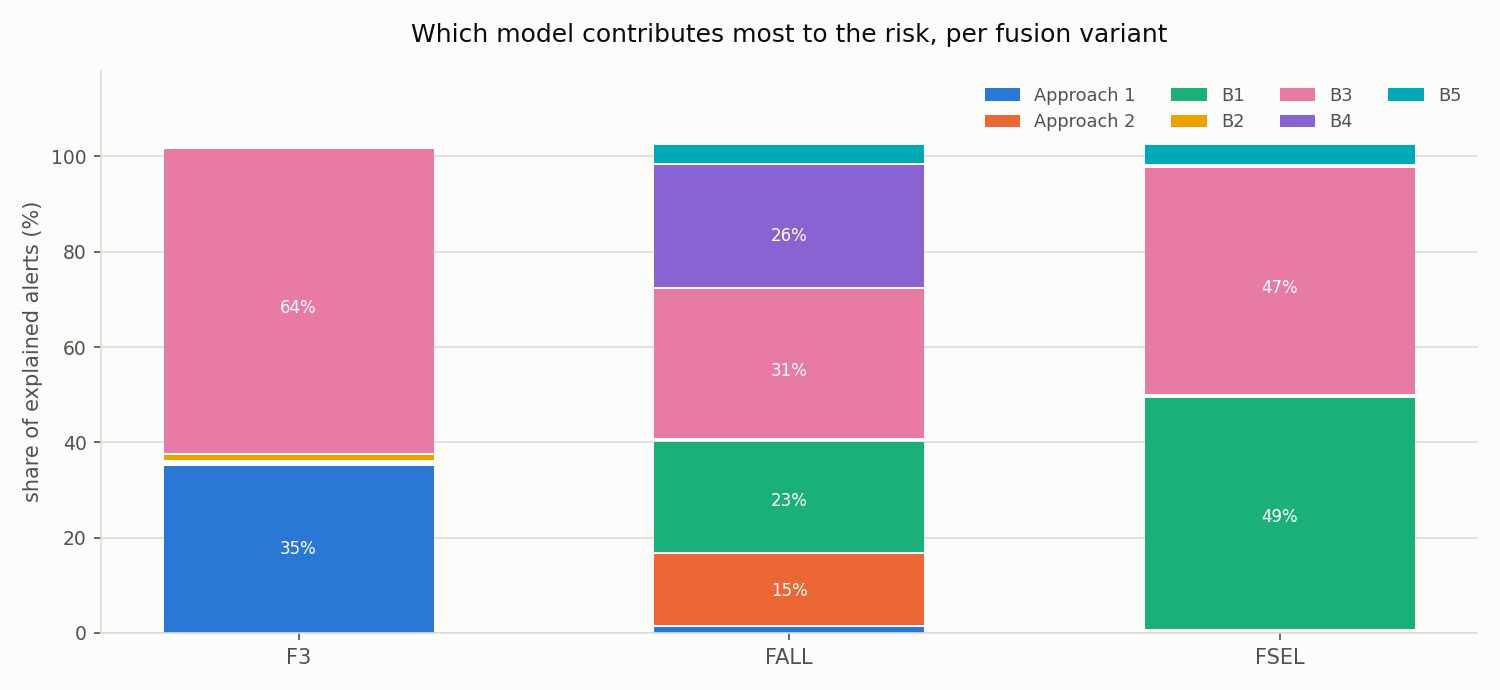

variant,model,alerts where it dominates,share (%)
F3,B3,531,63.8
F3,Approach 1,292,35.1
F3,B2,9,1.1
FALL,B3,260,31.2
FALL,B4,215,25.8
FALL,B1,191,23.0
FALL,Approach 2,125,15.0
FALL,B5,30,3.6
FALL,Approach 1,10,1.2
FALL,B2,1,0.1


**Reading:** B3 dominates 63.8% of F3's explained alerts -- the single largest concentration in the table.

In [132]:
variants = step14_all.get("variant_table")
if variants is not None and len(variants):
    xa.present(variants,
               caption="The fusion variants explained here. `max |R - sum C_m|` "
                       "is the identity C_m = w_m r_m checked against the saved "
                       "per-flow risk -- the contributions are the risk, split "
                       "by model, not an approximation of it.",
               best=["validation macro-F1"],
               count_columns=["models fused",
                              "alerts among the explained flows"],
               full_file=config.STEP14ALL_FILES["variants"])
    worst = variants["max |R - sum C_m|"].max()
    xa.show_reading(
        "Across %d variant(s) the largest gap between R and the sum of the "
        "contributions is %.1e -- the split is exact, so a report can attribute "
        "the risk to a model without rounding the story."
        % (len(variants), worst))

share = step14_all.get("dominant_share")
if share is not None and len(share):
    xa.show_chart(config.STEP14ALL_OUTPUT_DIR
                  / config.STEP14ALL_FILES["chart_dominant"])
    overall = share[share["scope"] == "all explained alerts"]
    xa.present(overall[["variant", "model", "alerts where it dominates",
                        "share (%)"]].sort_values(
                            ["variant", "share (%)"], ascending=[True, False]),
               caption="Which model carries the largest contribution C = w*r, "
                       "per variant, over the explained alerts.",
               top=10, percent_columns=["share (%)"],
               count_columns=["alerts where it dominates"],
               full_file=config.STEP14ALL_FILES["contributions"])
    leader = overall.loc[overall["share (%)"].idxmax()]
    xa.show_reading(
        "%s dominates %.1f%% of %s's explained alerts -- the single largest "
        "concentration in the table."
        % (leader["model"], leader["share (%)"], leader["variant"]))

In [133]:
disagreement = step14_all.get("variant_disagreement")
if disagreement is not None and len(disagreement):
    xa.present(disagreement, caption="How often two variants reach a different "
                                     "decision on the same explained flow.",
               percent_columns=["share (%)"],
               count_columns=["explained alerts", "decisions that differ"])
    worst = disagreement.loc[disagreement["share (%)"].idxmax()]
    xa.show_reading(
        "%s differ most, on %.1f%% of the explained flows%s."
        % (worst["pair"], worst["share (%)"],
           "" if worst["share (%)"] else " -- that is, not at all"))

examples = step14_all.get("variant_disagreement_examples")
if examples is not None and len(examples):
    xa.present(examples, caption="Example flows where two variants disagree, "
                                 "with the model whose contribution moved the "
                                 "most between them.", top=10)

part = checks[checks["section"] == "14.9.4 fusion variants"] \
    if checks is not None else pd.DataFrame()
if len(part):
    xa.present(part[["check", "result", "detail"]],
               caption="Verification -- 14.9.4.")

pair,explained alerts,decisions that differ,share (%)
F3 vs FALL,832,5,0.6
F3 vs FSEL,832,12,1.4
FALL vs FSEL,832,9,1.1


**Reading:** F3 vs FSEL differ most, on 1.4% of the explained flows.

check,result,detail
F3: R equals the sum of its contributions,[OK],max |R - sum C_m| = 1.00e-07 over 832 explained flows
FALL: R equals the sum of its contributions,[OK],max |R - sum C_m| = 8.00e-08 over 832 explained flows
FALL: Rel_m and Conf_m reproduce the saved weights,[OK],"max |w recomputed - w saved| = 7.29e-07 against a 5e-03 tolerance -- 13.8 weighted the classifiers' own probabilities and these go through the composed models, which agree to 1e-5"
FSEL: R equals the sum of its contributions,[OK],max |R - sum C_m| = 1.00e-07 over 832 explained flows
FSEL: Rel_m and Conf_m reproduce the saved weights,[OK],"max |w recomputed - w saved| = 4.89e-07 against a 5e-03 tolerance -- 13.8 weighted the classifiers' own probabilities and these go through the composed models, which agree to 1e-5"


### 12.9.5 Alert reports for the chosen fusion variant

Below: which variant these reports explain and why, then one full evidence
report per attack class — the decision first, then every fused model with its
weight, its contribution and its top features in original units, then the models
that took no part.

In [134]:
metrics = step14_all.get("metrics") or {}
xa.present(pd.DataFrame([
    {"item": "variant explained", "value": step14_all.get("variant")},
    {"item": "why", "value": step14_all.get("variant_reason")},
    {"item": "models in this fusion",
     "value": ", ".join((metrics.get("variants_explained", {})
                         .get(step14_all.get("variant"), {})
                         .get("models", [])))},
    {"item": "alerts reported",
     "value": "{:,}".format(len(step14_all.get("alerts", [])))},
]), caption="The alert reports below explain one variant. `auto` picks the "
            "best VALIDATION macro-F1; no test label takes part in that "
            "choice.")

alerts = step14_all.get("alerts")
if alerts is not None and len(alerts):
    columns = [c for c in ("alert_id", "Orig_Row", "band", "R", "tau",
                           "fused_label", "agreement", "dominant_model",
                           "confidence") if c in alerts.columns]
    xa.present(alerts[columns], caption="Every alert explained under this "
                                        "variant, newest columns first.",
               top=10, full_file=config.STEP14ALL_FILES["alerts"])
    xa.show_reading(
        "%s alerts carry a report; %s are rated High confidence, %s Medium and "
        "%s Low, and %s is the most frequent dominant model."
        % ("{:,}".format(len(alerts)),
           "{:,}".format(int((alerts["confidence"] == "High").sum())),
           "{:,}".format(int((alerts["confidence"] == "Medium").sum())),
           "{:,}".format(int((alerts["confidence"] == "Low").sum())),
           alerts["dominant_model"].mode().iloc[0]))

item,value
variant explained,FSEL
why,"ALERT_FUSION_VARIANT = ""auto"", and FSEL has the best VALIDATION macro-F1 (0.7415 against F3 0.6888, FALL 0.6758)"
models in this fusion,"B1, B3, B5"
alerts reported,783


alert_id,Orig_Row,band,R,tau,fused_label,agreement,dominant_model,confidence
A_2,2.0000,ATTACK,0.9680,0.9364,HTTP_DDoS,majority,B1,Medium
A_595,595.0000,ATTACK,0.9947,0.9364,Brute_Force,unanimous,B1,Medium
A_1894,"1,894",ATTACK,0.9947,0.9364,Brute_Force,unanimous,B1,Medium
A_2591,"2,591",ATTACK,0.9945,0.9364,Brute_Force,unanimous,B1,Medium
A_2596,"2,596",ATTACK,0.9968,0.9364,Brute_Force,unanimous,B1,Medium
A_2962,"2,962",ATTACK,0.9968,0.9364,Brute_Force,unanimous,B1,Medium
A_2963,"2,963",ATTACK,0.9967,0.9364,Brute_Force,unanimous,B1,Medium
A_3188,"3,188",ATTACK,0.9946,0.9364,Brute_Force,unanimous,B1,Medium
A_3190,"3,190",ATTACK,0.9946,0.9364,Brute_Force,unanimous,B1,Medium
A_3692,"3,692",ATTACK,0.9945,0.9364,Brute_Force,unanimous,B1,Medium


**Reading:** 783 alerts carry a report; 6 are rated High confidence, 776 Medium and 1 Low, and B1 is the most frequent dominant model.

In [135]:
# one full report per attack class
for report in step14_all.get("examples", []):
    flat = report["flat"]
    xa.render_report(report, dominant=flat.get("dominant_model"))

---

**ALERT A_595 -- Brute_Force (ATTACK)**  
Dominant model: **B1**

Evidence component,Detail,Confidence
Alert ID,A_595 | decision band: ATTACK,Medium
Risk score,R = 0.995 vs tau = 0.936 (suspicious band from tau_s = 0.965),Medium
Model 1 B1 <-- dominant,"P = 0.99 (Brute_Force) | w = 0.35 | contribution w*r = 0.35 | r = 0.998 | top-5 features: ACK Flag Cnt = 1 (raises, IG +0.1943); Flow Duration = 18029 (raises, IG +0.1155); Fwd IAT Tot = 0 (raises, IG +0.0229); Init Bwd Win Byts = 4106 (raises, IG +0.0133); Flow IAT Max = 18029 (raises, IG +0.0094)",High
Model 2 B3,"P = 0.98 (Brute_Force) | w = 0.33 | contribution w*r = 0.33 | r = 0.998 | top-5 features: Flow Duration = 18029 (raises, IG +0.1879); ACK Flag Cnt = 1 (raises, IG +0.1708); Init Bwd Win Byts = 4106 (raises, IG +0.0378); Bwd Seg Size Avg = 0 (lowers, IG -0.0246); Down/Up Ratio = 1 (raises, IG +0.0066)",High
Model 3 B5,"P = 0.96 (Brute_Force) | w = 0.32 | contribution w*r = 0.31 | r = 0.988 | top-5 features: Flow Duration = 18029 (raises, IG +0.4576); Init Bwd Win Byts = 4106 (raises, IG +0.1005); Flow IAT Max = 18029 (raises, IG +0.0474); Bwd Seg Size Avg = 0 (raises, IG +0.0391); Bwd Pkt Len Mean = 0 (raises, IG +0.0343)",High
Fusion,context = Brute_Force | reliability: B1 0.992; B3 0.996; B5 0.992 | dominant model: B1 | models unanimous | sum of contributions = 0.995 (R = 0.995),Medium
Attack family,Brute_Force (fused predicted class),Medium
Attack stage,"Credential Access (TA0006) -- label-to-tactic mapping, not an inferred attack progression",Medium
Flow context,"unknown:? -> unknown:? | Protocol ? | ? | capture ? | identifiers are context only, never model features",Medium
Source context,0 other alert(s) from unknown within 60 minutes: no other alert from this source in the window -- descriptive context from the test subset; not used by the models; the random split means some flows in between are not shown,Low


---

**ALERT A_2 -- HTTP_DDoS (ATTACK)**  
Dominant model: **B1**

...

**ALERT A_89143 -- ICMP_Flood (ATTACK)**  
Dominant model: **B3**

Evidence component,Detail,Confidence
Alert ID,A_89143 | decision band: ATTACK,Medium
Risk score,R = 0.990 vs tau = 0.936 (suspicious band from tau_s = 0.965),Medium
Model 1 B1,"P = 0.94 (ICMP_Flood) | w = 0.15 | contribution w*r = 0.14 | r = 0.943 | top-5 features: Bwd IAT Tot = 1.2e+08 (raises, IG +0.1881); Flow Duration = 1.19881e+08 (lowers, IG -0.0583); Fwd IAT Tot = 1.2e+08 (lowers, IG -0.0289); Subflow Fwd Pkts = 5399 (raises, IG +0.0053); Down/Up Ratio = 1 (lowers, IG -0.0045)",High
Model 2 B3 <-- dominant,"P = 1.00 (ICMP_Flood) | w = 0.70 | contribution w*r = 0.70 | r = 1.000 | top-5 features: Fwd IAT Tot = 1.2e+08 (lowers, IG -0.3346); Bwd IAT Tot = 1.2e+08 (raises, IG +0.3106); Subflow Bwd Pkts = 5401 (raises, IG +0.1279); Pkt Len Mean = 0 (raises, IG +0.0791); Subflow Fwd Pkts = 5399 (raises, IG +0.0531)",High
Model 3 B5,"P = 0.99 (ICMP_Flood) | w = 0.15 | contribution w*r = 0.15 | r = 0.991 | top-5 features: Bwd IAT Tot = 1.2e+08 (raises, IG +0.7888); Flow Duration = 1.19881e+08 (lowers, IG -0.1739); Bwd Seg Size Avg = 0 (raises, IG +0.0334); Tot Bwd Pkts = 5401 (raises, IG +0.0319); Flow IAT Max = 1.01153e+06 (raises, IG +0.0260)",High
Fusion,context = ICMP_Flood | reliability: B1 0.140; B3 0.597; B5 0.131 | dominant model: B3 | models unanimous | sum of contributions = 0.990 (R = 0.990),Medium
Attack family,ICMP_Flood (fused predicted class),Medium
Attack stage,"Impact - Denial of Service (TA0040) -- label-to-tactic mapping, not an inferred attack progression",Medium
Flow context,"unknown:? -> unknown:? | Protocol ? | ? | capture ? | identifiers are context only, never model features",Medium
Source context,0 other alert(s) from unknown within 60 minutes: no other alert from this source in the window -- descriptive context from the test subset; not used by the models; the random split means some flows in between are not shown,Low


---

**ALERT A_89442 -- Port_Scan (ATTACK)**  
Dominant model: **B3**

Evidence component,Detail,Confidence
Alert ID,A_89442 | decision band: ATTACK,Medium
Risk score,R = 0.998 vs tau = 0.936 (suspicious band from tau_s = 0.965),Medium
Model 1 B1,"P = 1.00 (Port_Scan) | w = 0.34 | contribution w*r = 0.34 | r = 0.999 | top-5 features: SYN Flag Cnt = 1 (raises, IG +0.2076); Flow Duration = 254 (lowers, IG -0.1073); Bwd Pkts/s = 7874.02 (raises, IG +0.0348); Fwd IAT Tot = 0 (lowers, IG -0.0229); Flow Pkts/s = 7874.02 (raises, IG +0.0128)",High
Model 2 B3 <-- dominant,"P = 1.00 (Port_Scan) | w = 0.35 | contribution w*r = 0.35 | r = 1.000 | top-5 features: SYN Flag Cnt = 1 (raises, IG +0.2624); Pkt Size Avg = 0 (raises, IG +0.0503); Bwd Seg Size Avg = 0 (raises, IG +0.0469); Flow Duration = 254 (lowers, IG -0.0120); Fwd Seg Size Avg = 0 (raises, IG +0.0110)",High
Model 3 B5,"P = 0.99 (Port_Scan) | w = 0.31 | contribution w*r = 0.31 | r = 0.994 | top-5 features: Flow Duration = 254 (raises, IG +0.5937); Flow IAT Max = 254 (raises, IG +0.0952); Bwd Seg Size Avg = 0 (raises, IG +0.0481); Bwd Pkt Len Mean = 0 (raises, IG +0.0473); Bwd Pkts/s = 7874.02 (raises, IG +0.0439)",High
Fusion,context = Port_Scan | reliability: B1 0.962; B3 0.961; B5 0.898 | dominant model: B3 | models unanimous | sum of contributions = 0.998 (R = 0.998),Medium
Attack family,Port_Scan (fused predicted class),Medium
Attack stage,"Reconnaissance (MITRE ATT&CK TA0043) -- label-to-tactic mapping, not an inferred attack progression",Medium
Flow context,"unknown:? -> unknown:? | Protocol ? | ? | capture ? | identifiers are context only, never model features",Medium
Source context,0 other alert(s) from unknown within 60 minutes: no other alert from this source in the window -- descriptive context from the test subset; not used by the models; the random split means some flows in between are not shown,Low


### 12.9.6 Discussion, key findings and verification

Below: the discussion generated from the computed tables, the findings worth
carrying into the write-up, and every check in one place.

In [136]:
text = step14_all.get("summary") or (step14_all.get("metrics") or {}).get("summary")
if text:
    if xa.dl.in_notebook():
        from IPython.display import Markdown, display
        display(Markdown(text))
    else:
        print(text)

### 14.9.6 Explainability across all models -- what the numbers say

**Models explained.** 8 of 8 configurations: Approach 1: FS -> AE -> CNN-LSTM, Approach 2: FS -> AE -> CNN-Attention-LSTM, B1: AE -> CNN-LSTM (no selection), B2: AE -> LSTM (no CNN), B3: CNN-LSTM (no AE), B4: AE -> PCA -> LSTM, B5: MI-only top 30 -> AE -> CNN-LSTM, B6: AE -> PCA -> CNN-LSTM.

**What drives the attack classes.**
- `Flow Duration` is in the top-10 of 8 of the 8 explained models -- the widest agreement in the table.
- Features in at least two models' top-10: `Flow Duration`, `Fwd IAT Tot`, `Pkt Len Mean`, `SYN Flag Cnt`, `Bwd Seg Size Avg`.
- Features only one model ranks that highly: `Pkt Len Std` (B3) -- where the models' reasoning parts company.
- The most similar reasoning is Approach 2 and B5 (Spearman 0.985 on their shared features); the least similar is Approach 1 and B3 (0.848).

**Whose explanations hold up.**
- Best completeness (sum IG = F(x) - F(x')): B2 (96.6 % of flows).
- Best agreement with the perturbation check: Approach 1 (0.4990 Spearman).
- Best deletion-check gap: Approach 2 (0.6574 risk drop above chance).
- Best stability under small noise: B5 (0.7496 Spearman).
- Lowest IG cost per flow: B6 (18.01 ms per flow).

**Does the chosen fusion lean on one model?**
- The alert reports explain **FSEL**: ALERT_FUSION_VARIANT = "auto", and FSEL has the best VALIDATION macro-F1 (0.7415 against F3 0.6888, FALL 0.6758).
- B1 has the largest contribution C = w*r in 48.6% of the explained alerts under FSEL; the rest are split across 2 other model(s).
- F3 vs FALL disagree on the decision for 5 of 832 explained alerts (0.6%).
- F3 vs FSEL disagree on the decision for 12 of 832 explained alerts (1.4%).
- FALL vs FSEL disagree on the decision for 9 of 832 explained alerts (1.1%).

**Caveats.**
- IG explains **model behaviour**, not ground-truth causes. A feature with a large attribution is one this model leaned on, which is not the same as a feature that caused the attack.
- Approach 2's attention is **supplementary**: it weights CNN feature-map positions, not input features, so it cannot name a flow feature and is never used as the explanation here.
- The models have different inputs. A blank cell is `--` -- not an input of this model -- never a zero, which would claim the model looked and found nothing.
- One seed (RANDOM_STATE = 42), one IG baseline (IG_BASELINE = 'benign_median') and 64 IG steps. Every figure above is a single run, not an estimate with a spread.
- Step 14 is unchanged: it explains F3, and every file in `step14\` is SHA-256 identical before and after this section.

In [137]:
# Key findings -- every line computed from the tables above, not written by hand
findings = []
if availability is not None and len(availability):
    ready = availability[availability["available"]]
    findings.append("**%d of %d configurations explained** on their own named "
                    "features, each composed model checked against its saved "
                    "probabilities to 1e-5 (14.9.1)."
                    % (len(ready), len(availability)))
if matrix is not None and len(matrix):
    table = xa.top_feature_table(matrix)
    first = [str(table[c].iloc[0]) for c in table.columns if c != "rank"]
    top = max(set(first), key=first.count)
    findings.append("**`%s` is the top feature for %d of %d models** (14.9.3, "
                    "top-feature table)." % (top, first.count(top), len(first)))
if quality is not None and len(quality):
    best = quality.loc[quality["completeness within tolerance (%)"].idxmax()]
    findings.append("**%s has the most faithful attributions** -- %.1f%% of "
                    "flows within the completeness tolerance (14.9.3, "
                    "explanation-quality table)."
                    % (best["model"].split(":")[0],
                       best["completeness within tolerance (%)"]))
if variants is not None and len(variants):
    findings.append("**R = sum of the model contributions holds for every "
                    "variant** to %.1e (14.9.4, variant table)."
                    % variants["max |R - sum C_m|"].max())
if share is not None and len(share):
    overall = share[share["scope"] == "all explained alerts"]
    chosen = overall[overall["variant"] == step14_all.get("variant")]
    if len(chosen):
        leader = chosen.loc[chosen["share (%)"].idxmax()]
        findings.append("**%s dominates %.1f%% of the %s alerts** (14.9.4, "
                        "dominant-model chart)."
                        % (leader["model"], leader["share (%)"],
                           step14_all.get("variant")))
if alerts is not None and len(alerts):
    findings.append("**%s alert reports** written for %s, each naming its "
                    "evidence, its uncertainty and a suggested check (14.9.5)."
                    % ("{:,}".format(len(alerts)), step14_all.get("variant")))

if xa.dl.in_notebook():
    from IPython.display import Markdown, display
    display(Markdown("#### Key findings\n\n"
                     + "\n".join("%d. %s" % (i + 1, f)
                                 for i, f in enumerate(findings))))
else:
    print("Key findings:")
    for i, f in enumerate(findings):
        print(" %d. %s" % (i + 1, f.replace("**", "")))

#### Key findings

1. **8 of 8 configurations explained** on their own named features, each composed model checked against its saved probabilities to 1e-5 (14.9.1).
2. **`Flow Duration` is the top feature for 6 of 8 models** (14.9.3, top-feature table).
3. **B2 has the most faithful attributions** -- 96.6% of flows within the completeness tolerance (14.9.3, explanation-quality table).
4. **R = sum of the model contributions holds for every variant** to 1.0e-07 (14.9.4, variant table).
5. **B1 dominates 48.6% of the FSEL alerts** (14.9.4, dominant-model chart).
6. **783 alert reports** written for FSEL, each naming its evidence, its uncertainty and a suggested check (14.9.5).

In [138]:
if checks is not None and len(checks):
    passed = int((checks["result"] == "[OK]").sum())
    failed = int((checks["result"] == "[FAIL]").sum())
    xa.present(checks, caption="Every verification in 14.9, in one table: the "
                               "composed models, the IG identity, the deletion "
                               "checks, R = sum C_m per variant, the saved "
                               "files read back from disk, and the Step 14 "
                               "fingerprint.",
               top=60, full_file=config.STEP14ALL_FILES["verification"])
    xa.show_reading("%d of %d checks passed%s."
                    % (passed, len(checks),
                       "" if not failed else
                       "; %d did not -- the rows above say which, and a "
                       "deletion-check [FAIL] is a finding about that model's "
                       "attributions rather than a broken run" % failed))

unchanged = step14_all.get("step14_unchanged_table")
if unchanged is not None and len(unchanged):
    xa.present(unchanged, caption="SHA-256 of every file in `step14\\`, before "
                                  "this section ran and after it wrote its own "
                                  "outputs.", top=10)
print("[%s]  existing Step 14 outputs unchanged"
      % ("OK" if step14_all.get("step14_unchanged") else "FAIL"))

section,check,result,detail
14.9.1 composed models,Approach 1: FS -> AE -> CNN-LSTM reproduces its saved probabilities,[SKIP],this configuration saved no predictions.csv to compare against
14.9.1 composed models,Approach 2: FS -> AE -> CNN-Attention-LSTM reproduces its saved probabilities,[OK],composed model reproduces the saved probabilities
14.9.1 composed models,B1: AE -> CNN-LSTM (no selection) reproduces its saved probabilities,[OK],composed model reproduces the saved probabilities
14.9.1 composed models,B2: AE -> LSTM (no CNN) reproduces its saved probabilities,[OK],composed model reproduces the saved probabilities
14.9.1 composed models,B3: CNN-LSTM (no AE) reproduces its saved probabilities,[OK],composed model reproduces the saved probabilities
14.9.1 composed models,B4: AE -> PCA -> LSTM reproduces its saved probabilities,[OK],composed model reproduces the saved probabilities
14.9.1 composed models,B5: MI-only top 30 -> AE -> CNN-LSTM reproduces its saved probabilities,[OK],composed model reproduces the saved probabilities
14.9.1 composed models,B6: AE -> PCA -> CNN-LSTM reproduces its saved probabilities,[OK],composed model reproduces the saved probabilities
14.9.5 alert reports,the alert variant is a validation decision,[OK],"ALERT_FUSION_VARIANT = ""auto"", and FSEL has the best VALIDATION macro-F1 (0.7415 against F3 0.6888, FALL 0.6758)"
14.9.2 attribution,the flows Step 14 explained are explained here too,[OK],"564 from Step 14, 268 added from FSEL alerts, 832 explained in all"


**Reading:** 46 of 51 checks passed; 4 did not -- the rows above say which, and a deletion-check [FAIL] is a finding about that model's attributions rather than a broken run.

file,named in the brief,sha256 before,sha256 after,result
alert_explanations.csv,yes,97715e10bec15ed9,97715e10bec15ed9,[OK]
class_feature_ig_heatmap.png,no,c39ec25bdb76e022,c39ec25bdb76e022,[OK]
deletion_check.png,no,bbea6462c47ce837,bbea6462c47ce837,[OK]
evidence_records.csv,no,1d5119deb1f6a5c1,1d5119deb1f6a5c1,[OK]
example_alert_contributions.png,no,3ed096edee1134da,3ed096edee1134da,[OK]
example_alert_reports.md,no,4328d2215d7b33b1,4328d2215d7b33b1,[OK]
explanation_metrics.json,yes,b90f37dfd9b0bb97,b90f37dfd9b0bb97,[OK]
explanation_validation.csv,no,16dc559d95609c34,16dc559d95609c34,[OK]
explanations.csv,no,e7381c5be608e28e,e7381c5be608e28e,[OK]
global_feature_importance.csv,no,49ed9ef7c365cfa2,49ed9ef7c365cfa2,[OK]


[OK]  existing Step 14 outputs unchanged


### What 12.9 can and cannot say

1. **An attribution explains the model, not the world.** It names the input a
   network leaned on. A model that learned a shortcut is explained faithfully as
   using that shortcut; a surprising attribution is a reason to check the model,
   not to believe a new fact about attacks.
2. **Attention is supplementary.** Approach 2's attention weights CNN
   feature-map positions, not input features. It is reported because it is the
   one thing Approach 2 has that the others do not, and it is never used as the
   explanation — the IG tables are.
3. **The models do not share a feature set.** A blank cell is `--`, *not an
   input of this model*, never a zero: zero would claim the model looked and
   found nothing. Cross-model correlations are computed only where both models
   take the same feature as input, and the number of shared features is
   reported beside them.
4. **Faithfulness is measured, not assumed.** Completeness, the perturbation
   agreement, the deletion check and the stability pass are four independent
   ways of asking whether an attribution describes the model. A model that fails
   the deletion check has attributions that are not informative, and the table
   says so rather than hiding it.
5. **Rare classes have few explained alerts**, so a per-class reading there
   moves in large steps.
6. **One seed, one baseline, one step count.** Every figure is a single run.
7. **Step 12 is unchanged.** It explains F3 and is the version the write-up
   quotes; this section sits beside it and writes only to `step14_all\`.

---

## Summary

The pipeline reads the published MSCAD flow table, reduces its 66
CICFlowMeter features to 30 by feature selection and then to 15 by an
autoencoder, and trains a hybrid CNN-LSTM classifier with class weighting applied
to the training loss alone.

**Where the results are written.** Every step writes to its own folder under
`C:\MSCAD2022\outputs_official\` in official mode (`C:\MSCAD2022\outputs\` in own
mode). The folder names keep the earlier numbering, as the table at the top of
the notebook explains:

| Artefact | Location |
|---|---|
| Selected features and their ranking | `outputs\step6\selected_features.json`, `combined_ranking.csv` |
| Trained autoencoder and encoder | `outputs\step7\autoencoder.keras`, `encoder.keras` |
| Class weights | `outputs\step9\class_weights.json` |
| Trained classifier and model card | `outputs\step10\cnn_lstm.keras`, `model_card.json` |
| Test metrics and per-class report | `outputs\step11\metrics.json`, `per_class_report.csv` |
| Per-flow predictions | `outputs\step11\predictions.csv` |
| Baseline comparison and charts | `outputs\step12\comparison_table.csv`, `summary.md` |

**How to read the results.** Lead with macro-F1 and G-mean rather than accuracy,
and quote the duplicate-free columns as the conservative estimate. The numeric
results are produced by the cells above and are not reproduced in this text.

**Methodological guarantees enforced by the code.** The scaler is fitted on the
training rows only; feature selection, the autoencoder and the class weights are
derived from training data alone; the test set is never resampled, reweighted or
consulted for any decision before Step 9; and identifier columns are retained
for traceability but excluded from every model input.

**Running this notebook.** The code lives in
`C:\Users\banot\MSCAD22-Multi-Stage-Cyber-Attack-Detection\Notebook`; the data
and all outputs live under `C:\MSCAD2022`. Each step reloads existing outputs
instead of recomputing them unless the corresponding `OVERWRITE_STEPn` flag in
`config.py` is set to `True`.
